<a href="https://colab.research.google.com/github/BhavyaPatel1007/Project-2/blob/main/DR_DINO_BYOL_MyProject.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# EyePACS Self-Supervised Learning Project Report

## 1. Project Objective
The goal of this project is to implement and compare two state-of-the-art Self-Supervised Learning (SSL) frameworks to learn robust representations of fundus images from the EyePACS dataset, which can later be used for downstream diabetic retinopathy (DR) classification.

## 2. Data Preparation & Preprocessing
- **Dataset Source:** EyePACS fundus images (Train: 4,200, Valid: 1,200, Test: 600 images).
- **Pipeline:** Developed a custom preprocessing function that:
    1. Removes black borders by thresholding the retinal area.
    2. Resizes images to **384x384** (for BYOL) and **224x224** (for ViT).
    3. Applies **CLAHE** (Contrast Limited Adaptive Histogram Equalization) in the LAB color space to enhance the visibility of microaneurysms and exudates.
- **Mapping:** All training images were successfully mapped to their preprocessed paths on Google Drive.

## 3. Implementation A: ViT + DINO
- **Architecture:** Vision Transformer (`vit_small_patch16_224`) served as the backbone.
- **Methodology:** Used the **DINO** (Self-distillation with no labels) framework with a Student-Teacher configuration.
- **Augmentation:** Multi-crop strategy using 2 global views (224x224) and 4 local crops (96x96).
- **Status:** Completed 10 epochs of training. Checkpoints are stored in `/content/drive/MyDrive/EyePACS/checkpoints/`.

## 4. Implementation B: ResNet-18 + FPN + BYOL
- **Architecture:** A custom `CNNFPN` backbone combining **ResNet-18** with a **Feature Pyramid Network (FPN)** to capture multi-scale diabetic retinopathy features.
- **Methodology:** **BYOL** (Bootstrap Your Own Latent) utilizing an Online network (Backbone, Projector, Predictor) and a Target network (Backbone, Projector).
- **Updates:** Target network updated via Exponential Moving Average (EMA) with $\tau = 0.996$.
- **Status:** Training is currently ongoing. Checkpoints through **Epoch 7** have been successfully saved to Google Drive.

## 5. Next Steps
1. Complete the remaining 3 epochs for the BYOL training.
2. **Downstream Task:** Load the best pre-trained backbones (ViT and ResNet-FPN) and freeze the weights.
3. Train a linear classifier/MLP head on the `level` labels (0-4) to evaluate the quality of the learned representations.
4. Compare performance metrics (Accuracy, Quadratic Weighted Kappa) between the two SSL approaches.

In [ ]:
!pip install -q timm lightly opencv-python-headless scikit-learn pandas matplotlib tqdm

In [ ]:
!pip install -q kaggle

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
import os

DATA_DIR = "/content/drive/MyDrive/EyePACS"

os.makedirs(DATA_DIR, exist_ok=True)

print("Dataset folder:", DATA_DIR)

Dataset folder: /content/drive/MyDrive/EyePACS


In [ ]:
import os

DATA_DIR = "/content/drive/MyDrive/EyePACS"

for root, dirs, files in os.walk(DATA_DIR):
    print(root, "→", len(files), "files")
    if files:
        print("   ", files[:10])

/content/drive/MyDrive/EyePACS → 1 files
    ['diabetic-retinopathy-screening.zip']


In [ ]:
import os

print("Kaggle folder exists:",
      os.path.exists("/root/.kaggle"))

if os.path.exists("/root/.kaggle"):
    print(os.listdir("/root/.kaggle"))

Kaggle folder exists: False


In [ ]:
import zipfile
import os

ZIP_PATH = "/content/drive/MyDrive/EyePACS/diabetic-retinopathy-screening.zip"
EXTRACT_DIR = "/content/drive/MyDrive/EyePACS/dataset"

with zipfile.ZipFile(ZIP_PATH, 'r') as zip_ref:
    zip_ref.extractall(EXTRACT_DIR)

print("Extraction completed!")
print("Dataset location:", EXTRACT_DIR)

Extraction completed!
Dataset location: /content/drive/MyDrive/EyePACS/dataset


In [ ]:
import os

for root, dirs, files in os.walk(EXTRACT_DIR):
    if files:
        print("\nFolder:", root)
        print("Number of files:", len(files))
        print("First files:", files[:10])


Folder: /content/drive/MyDrive/EyePACS/dataset
Number of files: 2
First files: ['README.dataset.txt', 'README.roboflow.txt']

Folder: /content/drive/MyDrive/EyePACS/dataset/test
Number of files: 285
First files: ['000c1434d8d7_png_jpg.rf.90ba7d812bf63cb2cacfcdf328e9a664.jpg', '005b95c28852_png_jpg.rf.98de75fcbe0d2b29f20f3359bc3f18f1.jpg', '04d029cfb612_png_jpg.rf.3c09ad5eb9d315ccf839ec5f4e93956a.jpg', '05195a3db5e2_png_jpg.rf.d788bdfc8f0482f8da82c522231285b1.jpg', '07a0be6b347f_png_jpg.rf.6259235ba5877591725e60b1f358d7f2.jpg', '07a1c7073982_png_jpg.rf.25bc99a81111c10a28b878367d69799d.jpg', '08c60c647673_png_jpg.rf.b42a5a0ef9b55721eb6b36b67b894045.jpg', '08f8838d69bb_png_jpg.rf.e6443c278c1cdf123d177583d355ad4b.jpg', '099021fac3c9_png_jpg.rf.d6ee396f830016e7c5ea008162c5359e.jpg', '09eeafa9656a_png_jpg.rf.8310763c56a2aa8f07c7772d5f086c41.jpg']

Folder: /content/drive/MyDrive/EyePACS/dataset/train
Number of files: 1987
First files: ['0024cdab0c1e_png_jpg.rf.1ef208b948582ee63eff6cd933fcc85

In [ ]:
import os

IMAGE_EXTENSIONS = (".jpg", ".jpeg", ".png")

image_files = []

for root, dirs, files in os.walk(EXTRACT_DIR):
    for file in files:
        if file.lower().endswith(IMAGE_EXTENSIONS):
            image_files.append(os.path.join(root, file))

print("Total images:", len(image_files))
print("\nFirst 10 images:")
for img in image_files[:10]:
    print(img)

Total images: 2838

First 10 images:
/content/drive/MyDrive/EyePACS/dataset/test/000c1434d8d7_png_jpg.rf.90ba7d812bf63cb2cacfcdf328e9a664.jpg
/content/drive/MyDrive/EyePACS/dataset/test/005b95c28852_png_jpg.rf.98de75fcbe0d2b29f20f3359bc3f18f1.jpg
/content/drive/MyDrive/EyePACS/dataset/test/04d029cfb612_png_jpg.rf.3c09ad5eb9d315ccf839ec5f4e93956a.jpg
/content/drive/MyDrive/EyePACS/dataset/test/05195a3db5e2_png_jpg.rf.d788bdfc8f0482f8da82c522231285b1.jpg
/content/drive/MyDrive/EyePACS/dataset/test/07a0be6b347f_png_jpg.rf.6259235ba5877591725e60b1f358d7f2.jpg
/content/drive/MyDrive/EyePACS/dataset/test/07a1c7073982_png_jpg.rf.25bc99a81111c10a28b878367d69799d.jpg
/content/drive/MyDrive/EyePACS/dataset/test/08c60c647673_png_jpg.rf.b42a5a0ef9b55721eb6b36b67b894045.jpg
/content/drive/MyDrive/EyePACS/dataset/test/08f8838d69bb_png_jpg.rf.e6443c278c1cdf123d177583d355ad4b.jpg
/content/drive/MyDrive/EyePACS/dataset/test/099021fac3c9_png_jpg.rf.d6ee396f830016e7c5ea008162c5359e.jpg
/content/drive/MyD

In [ ]:
import os

print("Dataset structure:\n")

for root, dirs, files in os.walk(EXTRACT_DIR):
    level = root.replace(EXTRACT_DIR, "").count(os.sep)
    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    # Show only first 10 files in each folder
    if files:
        for f in files[:10]:
            print(f"{indent}  {f}")

Dataset structure:

dataset/
  README.dataset.txt
  README.roboflow.txt
  test/
    000c1434d8d7_png_jpg.rf.90ba7d812bf63cb2cacfcdf328e9a664.jpg
    005b95c28852_png_jpg.rf.98de75fcbe0d2b29f20f3359bc3f18f1.jpg
    04d029cfb612_png_jpg.rf.3c09ad5eb9d315ccf839ec5f4e93956a.jpg
    05195a3db5e2_png_jpg.rf.d788bdfc8f0482f8da82c522231285b1.jpg
    07a0be6b347f_png_jpg.rf.6259235ba5877591725e60b1f358d7f2.jpg
    07a1c7073982_png_jpg.rf.25bc99a81111c10a28b878367d69799d.jpg
    08c60c647673_png_jpg.rf.b42a5a0ef9b55721eb6b36b67b894045.jpg
    08f8838d69bb_png_jpg.rf.e6443c278c1cdf123d177583d355ad4b.jpg
    099021fac3c9_png_jpg.rf.d6ee396f830016e7c5ea008162c5359e.jpg
    09eeafa9656a_png_jpg.rf.8310763c56a2aa8f07c7772d5f086c41.jpg
  train/
    0024cdab0c1e_png_jpg.rf.1ef208b948582ee63eff6cd933fcc855.jpg
    002c21358ce6_png_jpg.rf.2d27920a5a05d4170fcd51ca9d891245.jpg
    0083ee8054ee_png_jpg.rf.638548c51970528a72604cc8d03d82d4.jpg
    00a8624548a9_png_jpg.rf.fff593d66163e6865f12e343bd745338.jpg
 

In [ ]:
import os

print("Folders inside dataset:")

for item in os.listdir(EXTRACT_DIR):
    path = os.path.join(EXTRACT_DIR, item)
    print(item, "→", "Folder" if os.path.isdir(path) else "File")

Folders inside dataset:
README.dataset.txt → File
README.roboflow.txt → File
test → Folder
train → Folder
valid → Folder


In [ ]:
import glob

csv_files = glob.glob(EXTRACT_DIR + "/**/*.csv", recursive=True)

print("CSV files found:")
for f in csv_files:
    print(f)

CSV files found:
/content/drive/MyDrive/EyePACS/dataset/test/_classes.csv
/content/drive/MyDrive/EyePACS/dataset/train/_classes.csv
/content/drive/MyDrive/EyePACS/dataset/valid/_classes.csv


In [ ]:
import pandas as pd

if csv_files:
    for csv in csv_files:
        print("\nCSV:", csv)
        temp = pd.read_csv(csv)
        print("Shape:", temp.shape)
        print("Columns:", temp.columns.tolist())
        display(temp.head())
else:
    print("No CSV file found.")


CSV: /content/drive/MyDrive/EyePACS/dataset/test/_classes.csv
Shape: (284, 6)
Columns: ['filename', ' Mild', ' Moderate', ' No_DR', ' Proliferate_DR', ' Severe']


,filename,Mild,Moderate,No_DR,Proliferate_DR,Severe
0,fdbc252813b1_png_jpg.rf.00b46056379246cec11cf3...,0,0,1,0,0
1,36677b70b1ef_png_jpg.rf.00f1a6ebe4b4200c87db23...,1,0,0,0,0
2,13d71389563f_png_jpg.rf.0120618fee2d4e4060de26...,0,1,0,0,0
3,8a01daa423f7_png_jpg.rf.0517b75567c03d3580564c...,1,0,0,0,0
4,973b0facfa9b_png_jpg.rf.0529e30142f15c16427ab2...,0,0,1,0,0



CSV: /content/drive/MyDrive/EyePACS/dataset/train/_classes.csv
Shape: (1986, 6)
Columns: ['filename', ' Mild', ' Moderate', ' No_DR', ' Proliferate_DR', ' Severe']


,filename,Mild,Moderate,No_DR,Proliferate_DR,Severe
0,ffcf7b45f213_png_jpg.rf.69504d5dba3c3567f3283a...,0,1,0,0,0
1,be197b663520_png_jpg.rf.69ec2f1687af8bb2e3539f...,0,0,1,0,0
2,44a4d04162cc_png_jpg.rf.69edad48d37616d9013bcd...,0,0,1,0,0
3,abf09c44d5f4_png_jpg.rf.6a008b5ed4512ea394d701...,0,1,0,0,0
4,74eee788edee_png_jpg.rf.6a32ecf3d24ec573170e0c...,0,0,0,0,1



CSV: /content/drive/MyDrive/EyePACS/dataset/valid/_classes.csv
Shape: (568, 6)
Columns: ['filename', ' Mild', ' Moderate', ' No_DR', ' Proliferate_DR', ' Severe']


,filename,Mild,Moderate,No_DR,Proliferate_DR,Severe
0,c31651ea04c6_png_jpg.rf.624b1e972a132f574b75a3...,0,0,0,0,1
1,d6df4fe492ec_png_jpg.rf.6264db68f8c448f9d9ebd5...,0,0,1,0,0
2,7c629b491d1a_png_jpg.rf.6394013a7c6c5a24230563...,0,0,0,1,0
3,0ada12c0e78f_png_jpg.rf.6399511a266f82d9c0e4d7...,0,0,0,1,0
4,9a3c03a5ad0f_png_jpg.rf.6400050be4204b1fb0f884...,0,1,0,0,0


In [ ]:
import pandas as pd

if csv_files:
    for csv in csv_files:
        print("\nCSV:", csv)
        temp = pd.read_csv(csv)
        print("Shape:", temp.shape)
        print("Columns:", temp.columns.tolist())
        display(temp.head())
else:
    print("No CSV file found.")


CSV: /content/drive/MyDrive/EyePACS/dataset/test/_classes.csv
Shape: (284, 6)
Columns: ['filename', ' Mild', ' Moderate', ' No_DR', ' Proliferate_DR', ' Severe']


,filename,Mild,Moderate,No_DR,Proliferate_DR,Severe
0,fdbc252813b1_png_jpg.rf.00b46056379246cec11cf3...,0,0,1,0,0
1,36677b70b1ef_png_jpg.rf.00f1a6ebe4b4200c87db23...,1,0,0,0,0
2,13d71389563f_png_jpg.rf.0120618fee2d4e4060de26...,0,1,0,0,0
3,8a01daa423f7_png_jpg.rf.0517b75567c03d3580564c...,1,0,0,0,0
4,973b0facfa9b_png_jpg.rf.0529e30142f15c16427ab2...,0,0,1,0,0



CSV: /content/drive/MyDrive/EyePACS/dataset/train/_classes.csv
Shape: (1986, 6)
Columns: ['filename', ' Mild', ' Moderate', ' No_DR', ' Proliferate_DR', ' Severe']


,filename,Mild,Moderate,No_DR,Proliferate_DR,Severe
0,ffcf7b45f213_png_jpg.rf.69504d5dba3c3567f3283a...,0,1,0,0,0
1,be197b663520_png_jpg.rf.69ec2f1687af8bb2e3539f...,0,0,1,0,0
2,44a4d04162cc_png_jpg.rf.69edad48d37616d9013bcd...,0,0,1,0,0
3,abf09c44d5f4_png_jpg.rf.6a008b5ed4512ea394d701...,0,1,0,0,0
4,74eee788edee_png_jpg.rf.6a32ecf3d24ec573170e0c...,0,0,0,0,1



CSV: /content/drive/MyDrive/EyePACS/dataset/valid/_classes.csv
Shape: (568, 6)
Columns: ['filename', ' Mild', ' Moderate', ' No_DR', ' Proliferate_DR', ' Severe']


,filename,Mild,Moderate,No_DR,Proliferate_DR,Severe
0,c31651ea04c6_png_jpg.rf.624b1e972a132f574b75a3...,0,0,0,0,1
1,d6df4fe492ec_png_jpg.rf.6264db68f8c448f9d9ebd5...,0,0,1,0,0
2,7c629b491d1a_png_jpg.rf.6394013a7c6c5a24230563...,0,0,0,1,0
3,0ada12c0e78f_png_jpg.rf.6399511a266f82d9c0e4d7...,0,0,0,1,0
4,9a3c03a5ad0f_png_jpg.rf.6400050be4204b1fb0f884...,0,1,0,0,0


In [ ]:
import pandas as pd

if csv_files:
    for csv in csv_files:
        print("\nCSV:", csv)
        temp = pd.read_csv(csv)
        print("Shape:", temp.shape)
        print("Columns:", temp.columns.tolist())
        display(temp.head())
else:
    print("No CSV file found.")


CSV: /content/drive/MyDrive/EyePACS/dataset/test/_classes.csv
Shape: (284, 6)
Columns: ['filename', ' Mild', ' Moderate', ' No_DR', ' Proliferate_DR', ' Severe']


,filename,Mild,Moderate,No_DR,Proliferate_DR,Severe
0,fdbc252813b1_png_jpg.rf.00b46056379246cec11cf3...,0,0,1,0,0
1,36677b70b1ef_png_jpg.rf.00f1a6ebe4b4200c87db23...,1,0,0,0,0
2,13d71389563f_png_jpg.rf.0120618fee2d4e4060de26...,0,1,0,0,0
3,8a01daa423f7_png_jpg.rf.0517b75567c03d3580564c...,1,0,0,0,0
4,973b0facfa9b_png_jpg.rf.0529e30142f15c16427ab2...,0,0,1,0,0



CSV: /content/drive/MyDrive/EyePACS/dataset/train/_classes.csv
Shape: (1986, 6)
Columns: ['filename', ' Mild', ' Moderate', ' No_DR', ' Proliferate_DR', ' Severe']


,filename,Mild,Moderate,No_DR,Proliferate_DR,Severe
0,ffcf7b45f213_png_jpg.rf.69504d5dba3c3567f3283a...,0,1,0,0,0
1,be197b663520_png_jpg.rf.69ec2f1687af8bb2e3539f...,0,0,1,0,0
2,44a4d04162cc_png_jpg.rf.69edad48d37616d9013bcd...,0,0,1,0,0
3,abf09c44d5f4_png_jpg.rf.6a008b5ed4512ea394d701...,0,1,0,0,0
4,74eee788edee_png_jpg.rf.6a32ecf3d24ec573170e0c...,0,0,0,0,1



CSV: /content/drive/MyDrive/EyePACS/dataset/valid/_classes.csv
Shape: (568, 6)
Columns: ['filename', ' Mild', ' Moderate', ' No_DR', ' Proliferate_DR', ' Severe']


,filename,Mild,Moderate,No_DR,Proliferate_DR,Severe
0,c31651ea04c6_png_jpg.rf.624b1e972a132f574b75a3...,0,0,0,0,1
1,d6df4fe492ec_png_jpg.rf.6264db68f8c448f9d9ebd5...,0,0,1,0,0
2,7c629b491d1a_png_jpg.rf.6394013a7c6c5a24230563...,0,0,0,1,0
3,0ada12c0e78f_png_jpg.rf.6399511a266f82d9c0e4d7...,0,0,0,1,0
4,9a3c03a5ad0f_png_jpg.rf.6400050be4204b1fb0f884...,0,1,0,0,0


In [ ]:
import os

print("Top-level dataset contents:\n")

for item in os.listdir(EXTRACT_DIR):
    path = os.path.join(EXTRACT_DIR, item)

    if os.path.isdir(path):
        image_count = 0

        for root, dirs, files in os.walk(path):
            image_count += sum(
                f.lower().endswith((".jpg", ".jpeg", ".png"))
                for f in files
            )

        print(f"📁 {item} → {image_count} images")

    else:
        print(f"📄 {item}")

Top-level dataset contents:

📄 README.dataset.txt
📄 README.roboflow.txt
📁 test → 284 images
📁 train → 1986 images
📁 valid → 568 images


In [ ]:
import os

print("\nFolders containing images:\n")

for root, dirs, files in os.walk(EXTRACT_DIR):
    images = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    if images:
        print(root)
        print("Number of images:", len(images))
        print("Example:", images[:5])
        print()


Folders containing images:

/content/drive/MyDrive/EyePACS/dataset/test
Number of images: 284
Example: ['000c1434d8d7_png_jpg.rf.90ba7d812bf63cb2cacfcdf328e9a664.jpg', '005b95c28852_png_jpg.rf.98de75fcbe0d2b29f20f3359bc3f18f1.jpg', '04d029cfb612_png_jpg.rf.3c09ad5eb9d315ccf839ec5f4e93956a.jpg', '05195a3db5e2_png_jpg.rf.d788bdfc8f0482f8da82c522231285b1.jpg', '07a0be6b347f_png_jpg.rf.6259235ba5877591725e60b1f358d7f2.jpg']

/content/drive/MyDrive/EyePACS/dataset/train
Number of images: 1986
Example: ['0024cdab0c1e_png_jpg.rf.1ef208b948582ee63eff6cd933fcc855.jpg', '002c21358ce6_png_jpg.rf.2d27920a5a05d4170fcd51ca9d891245.jpg', '0083ee8054ee_png_jpg.rf.638548c51970528a72604cc8d03d82d4.jpg', '00a8624548a9_png_jpg.rf.fff593d66163e6865f12e343bd745338.jpg', '00cc2b75cddd_png_jpg.rf.96f3c45b39715c09f8b046a73138a0da.jpg']

/content/drive/MyDrive/EyePACS/dataset/valid
Number of images: 568
Example: ['001639a390f0_png_jpg.rf.bb68021f0c2dfca7b16ef29c5e366d9c.jpg', '0097f532ac9f_png_jpg.rf.a695e7713

In [ ]:
import os

CHECKPOINT_DIR = "/content/drive/MyDrive/EyePACS/checkpoints"

print("Checkpoint folder exists:", os.path.exists(CHECKPOINT_DIR))

if os.path.exists(CHECKPOINT_DIR):
    print("\nCheckpoint files:")
    for f in os.listdir(CHECKPOINT_DIR):
        print(f)

Checkpoint folder exists: False


In [ ]:
import os

BASE = "/content/drive/MyDrive"

print("Searching My Drive for checkpoint folders/files...\n")

for root, dirs, files in os.walk(BASE):
    # Show folders with "checkpoint" in the name
    for d in dirs:
        if "checkpoint" in d.lower():
            print("CHECKPOINT FOLDER:", os.path.join(root, d))

    # Show model/checkpoint files
    for f in files:
        if f.lower().endswith((".pth", ".pt", ".ckpt", ".pth.tar")):
            print("MODEL FILE:", os.path.join(root, f))

Searching My Drive for checkpoint folders/files...



In [ ]:
import os

BASE = "/content/drive/MyDrive"

print("EyePACS folder contents:\n")

for root, dirs, files in os.walk(BASE):
    if "EyePACS" in root:
        print("\n📁", root)
        print("Files:", files[:20])

EyePACS folder contents:


📁 /content/drive/MyDrive/EyePACS
Files: ['diabetic-retinopathy-screening.zip']

📁 /content/drive/MyDrive/EyePACS/dataset
Files: ['README.dataset.txt', 'README.roboflow.txt']

📁 /content/drive/MyDrive/EyePACS/dataset/test
Files: ['000c1434d8d7_png_jpg.rf.90ba7d812bf63cb2cacfcdf328e9a664.jpg', '005b95c28852_png_jpg.rf.98de75fcbe0d2b29f20f3359bc3f18f1.jpg', '04d029cfb612_png_jpg.rf.3c09ad5eb9d315ccf839ec5f4e93956a.jpg', '05195a3db5e2_png_jpg.rf.d788bdfc8f0482f8da82c522231285b1.jpg', '07a0be6b347f_png_jpg.rf.6259235ba5877591725e60b1f358d7f2.jpg', '07a1c7073982_png_jpg.rf.25bc99a81111c10a28b878367d69799d.jpg', '08c60c647673_png_jpg.rf.b42a5a0ef9b55721eb6b36b67b894045.jpg', '08f8838d69bb_png_jpg.rf.e6443c278c1cdf123d177583d355ad4b.jpg', '099021fac3c9_png_jpg.rf.d6ee396f830016e7c5ea008162c5359e.jpg', '09eeafa9656a_png_jpg.rf.8310763c56a2aa8f07c7772d5f086c41.jpg', '0a38b552372d_png_jpg.rf.8371fdc86d8136fd1da96bb2fbba3bc5.jpg', '0a85a1e8f9e9_png_jpg.rf.7aaef6e704e0369

In [ ]:
import os
import re

for split in ["train", "valid", "test"]:
    folder = os.path.join(EXTRACT_DIR, split)
    files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print(f"\n{split.upper()}: {len(files)} images")
    print("Examples:")
    for f in files[:10]:
        print(f)


TRAIN: 1986 images
Examples:
0024cdab0c1e_png_jpg.rf.1ef208b948582ee63eff6cd933fcc855.jpg
002c21358ce6_png_jpg.rf.2d27920a5a05d4170fcd51ca9d891245.jpg
0083ee8054ee_png_jpg.rf.638548c51970528a72604cc8d03d82d4.jpg
00a8624548a9_png_jpg.rf.fff593d66163e6865f12e343bd745338.jpg
00cc2b75cddd_png_jpg.rf.96f3c45b39715c09f8b046a73138a0da.jpg
00e4ddff966a_png_jpg.rf.6b5793cb32b41ea920181373a5109134.jpg
00f6c1be5a33_png_jpg.rf.bb4bfc78f89f39967324e817a4563e60.jpg
0104b032c141_png_jpg.rf.524eed7aa935eacb865385b935b457e3.jpg
0124dffecf29_png_jpg.rf.250be2601c38bd50755c620b1b3488d8.jpg
012a242ac6ff_png_jpg.rf.c89f554aa6b1385c54f6c46fb502ae66.jpg

VALID: 568 images
Examples:
001639a390f0_png_jpg.rf.bb68021f0c2dfca7b16ef29c5e366d9c.jpg
0097f532ac9f_png_jpg.rf.a695e77134725bb8ba5acbbd33acc832.jpg
00cb6555d108_png_jpg.rf.2546110628b5e2072c37edb44984cc19.jpg
0125fbd2e791_png_jpg.rf.7907ca711ab71a44d90efaf95c1b0336.jpg
0180bfa26c0b_png_jpg.rf.db8c1a83a6ae89091f93d15dc0243ba1.jpg
01eb826f6467_png_jpg.rf.79

In [ ]:
import os

print("All files other than images:\n")

for root, dirs, files in os.walk(EXTRACT_DIR):
    for f in files:
        if not f.lower().endswith((".jpg", ".jpeg", ".png")):
            print(os.path.join(root, f))

All files other than images:

/content/drive/MyDrive/EyePACS/dataset/README.dataset.txt
/content/drive/MyDrive/EyePACS/dataset/README.roboflow.txt
/content/drive/MyDrive/EyePACS/dataset/test/_classes.csv
/content/drive/MyDrive/EyePACS/dataset/train/_classes.csv
/content/drive/MyDrive/EyePACS/dataset/valid/_classes.csv


In [ ]:
import pandas as pd
import os

for split in ["train", "valid", "test"]:
    csv_path = os.path.join(EXTRACT_DIR, split, "_classes.csv")

    df = pd.read_csv(csv_path)

    print("\n" + "="*60)
    print(split.upper())
    print("="*60)

    print("Shape:", df.shape)
    print("Columns:")
    print(df.columns.tolist())

    print("\nFirst 5 rows:")
    display(df.head())

    print("\nClass totals:")
    print(df.iloc[:, 1:].sum())


TRAIN
Shape: (1986, 6)
Columns:
['filename', ' Mild', ' Moderate', ' No_DR', ' Proliferate_DR', ' Severe']

First 5 rows:


,filename,Mild,Moderate,No_DR,Proliferate_DR,Severe
0,ffcf7b45f213_png_jpg.rf.69504d5dba3c3567f3283a...,0,1,0,0,0
1,be197b663520_png_jpg.rf.69ec2f1687af8bb2e3539f...,0,0,1,0,0
2,44a4d04162cc_png_jpg.rf.69edad48d37616d9013bcd...,0,0,1,0,0
3,abf09c44d5f4_png_jpg.rf.6a008b5ed4512ea394d701...,0,1,0,0,0
4,74eee788edee_png_jpg.rf.6a32ecf3d24ec573170e0c...,0,0,0,0,1



Class totals:
Mild               202
Moderate           538
No_DR             1004
Proliferate_DR     153
Severe              89
dtype: int64

VALID
Shape: (568, 6)
Columns:
['filename', ' Mild', ' Moderate', ' No_DR', ' Proliferate_DR', ' Severe']

First 5 rows:


,filename,Mild,Moderate,No_DR,Proliferate_DR,Severe
0,c31651ea04c6_png_jpg.rf.624b1e972a132f574b75a3...,0,0,0,0,1
1,d6df4fe492ec_png_jpg.rf.6264db68f8c448f9d9ebd5...,0,0,1,0,0
2,7c629b491d1a_png_jpg.rf.6394013a7c6c5a24230563...,0,0,0,1,0
3,0ada12c0e78f_png_jpg.rf.6399511a266f82d9c0e4d7...,0,0,0,1,0
4,9a3c03a5ad0f_png_jpg.rf.6400050be4204b1fb0f884...,0,1,0,0,0



Class totals:
Mild               61
Moderate          155
No_DR             288
Proliferate_DR     36
Severe             28
dtype: int64

TEST
Shape: (284, 6)
Columns:
['filename', ' Mild', ' Moderate', ' No_DR', ' Proliferate_DR', ' Severe']

First 5 rows:


,filename,Mild,Moderate,No_DR,Proliferate_DR,Severe
0,fdbc252813b1_png_jpg.rf.00b46056379246cec11cf3...,0,0,1,0,0
1,36677b70b1ef_png_jpg.rf.00f1a6ebe4b4200c87db23...,1,0,0,0,0
2,13d71389563f_png_jpg.rf.0120618fee2d4e4060de26...,0,1,0,0,0
3,8a01daa423f7_png_jpg.rf.0517b75567c03d3580564c...,1,0,0,0,0
4,973b0facfa9b_png_jpg.rf.0529e30142f15c16427ab2...,0,0,1,0,0



Class totals:
Mild               31
Moderate           73
No_DR             138
Proliferate_DR     28
Severe             14
dtype: int64


In [ ]:
import pandas as pd
import os

DATASET_DIR = "/content/drive/MyDrive/EyePACS/dataset"

CLASS_MAP = {
    "No_DR": 0,
    "Mild": 1,
    "Moderate": 2,
    "Severe": 3,
    "Proliferate_DR": 4
}

for split in ["train", "valid", "test"]:

    csv_path = os.path.join(DATASET_DIR, split, "_classes.csv")

    df = pd.read_csv(csv_path)

    # Remove spaces from column names
    df.columns = df.columns.str.strip()

    # Convert one-hot labels to class number
    class_columns = [
        "No_DR",
        "Mild",
        "Moderate",
        "Severe",
        "Proliferate_DR"
    ]

    df["level"] = df[class_columns].idxmax(axis=1).map(CLASS_MAP)

    # Keep only filename + class
    clean_df = df[["filename", "level"]].copy()

    output_path = os.path.join(DATASET_DIR, split, "labels.csv")
    clean_df.to_csv(output_path, index=False)

    print(f"\n{split.upper()}")
    print("Images:", len(clean_df))
    print("Labels:", clean_df["level"].value_counts().sort_index().to_dict())
    print("Saved:", output_path)


TRAIN
Images: 1986
Labels: {0: 1004, 1: 202, 2: 538, 3: 89, 4: 153}
Saved: /content/drive/MyDrive/EyePACS/dataset/train/labels.csv

VALID
Images: 568
Labels: {0: 288, 1: 61, 2: 155, 3: 28, 4: 36}
Saved: /content/drive/MyDrive/EyePACS/dataset/valid/labels.csv

TEST
Images: 284
Labels: {0: 138, 1: 31, 2: 73, 3: 14, 4: 28}
Saved: /content/drive/MyDrive/EyePACS/dataset/test/labels.csv


In [ ]:
import os

CHECKPOINT_DIR = "/content/drive/MyDrive/EyePACS/checkpoints"

print("Checkpoint folder exists:", os.path.exists(CHECKPOINT_DIR))

if os.path.exists(CHECKPOINT_DIR):
    files = os.listdir(CHECKPOINT_DIR)
    print("\nFiles found:")
    for f in files:
        print(f)
else:
    print("\nNo checkpoint folder found.")

Checkpoint folder exists: False

No checkpoint folder found.


In [ ]:
import os

BASE_DIR = "/content/drive/MyDrive/EyePACS"

print("Files/folders inside EyePACS:\n")

for root, dirs, files in os.walk(BASE_DIR):
    for file in files:
        if file.endswith((".ipynb", ".py")):
            print(os.path.join(root, file))

Files/folders inside EyePACS:



In [ ]:
import torch
import torchvision
import timm
import lightly
import cv2
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))


PyTorch: 2.11.0+cpu
Torchvision: 0.26.0+cpu
CUDA available: False


In [ ]:
import pandas as pd
import os

DATASET_DIR = "/content/drive/MyDrive/EyePACS/dataset"

for split in ["train", "valid", "test"]:
    path = os.path.join(DATASET_DIR, split, "labels.csv")

    print(f"\n{split.upper()}")
    print("Exists:", os.path.exists(path))

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        print(df.head())
        print("Classes:", sorted(df["level"].unique()))


TRAIN
Exists: True
Shape: (1986, 2)
                                            filename  level
0  ffcf7b45f213_png_jpg.rf.69504d5dba3c3567f3283a...      2
1  be197b663520_png_jpg.rf.69ec2f1687af8bb2e3539f...      0
2  44a4d04162cc_png_jpg.rf.69edad48d37616d9013bcd...      0
3  abf09c44d5f4_png_jpg.rf.6a008b5ed4512ea394d701...      2
4  74eee788edee_png_jpg.rf.6a32ecf3d24ec573170e0c...      3
Classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

VALID
Exists: True
Shape: (568, 2)
                                            filename  level
0  c31651ea04c6_png_jpg.rf.624b1e972a132f574b75a3...      3
1  d6df4fe492ec_png_jpg.rf.6264db68f8c448f9d9ebd5...      0
2  7c629b491d1a_png_jpg.rf.6394013a7c6c5a24230563...      4
3  0ada12c0e78f_png_jpg.rf.6399511a266f82d9c0e4d7...      4
4  9a3c03a5ad0f_png_jpg.rf.6400050be4204b1fb0f884...      2
Classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]

TEST
Exists: True
Shape: (284, 2)
                      

In [ ]:
import os
import pandas as pd
from PIL import Image
import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

DATASET_DIR = "/content/drive/MyDrive/EyePACS/dataset"

class DRDataset(Dataset):
    def __init__(self, split, transform=None):
        self.split_dir = os.path.join(DATASET_DIR, split)
        self.labels = pd.read_csv(os.path.join(self.split_dir, "labels.csv"))
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        filename = self.labels.iloc[idx]["filename"]
        label = int(self.labels.iloc[idx]["level"])

        image_path = os.path.join(self.split_dir, filename)

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label


# Basic preprocessing for 224x224 models
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
])

train_dataset = DRDataset("train", transform=transform)
valid_dataset = DRDataset("valid", transform=transform)
test_dataset = DRDataset("test", transform=transform)

print("Train:", len(train_dataset))
print("Valid:", len(valid_dataset))
print("Test :", len(test_dataset))

# Test one image
image, label = train_dataset[0]

print("\nImage shape:", image.shape)
print("Label:", label)
print("Image path test: SUCCESS")

Train: 1986
Valid: 568
Test : 284

Image shape: torch.Size([3, 224, 224])
Label: 2
Image path test: SUCCESS


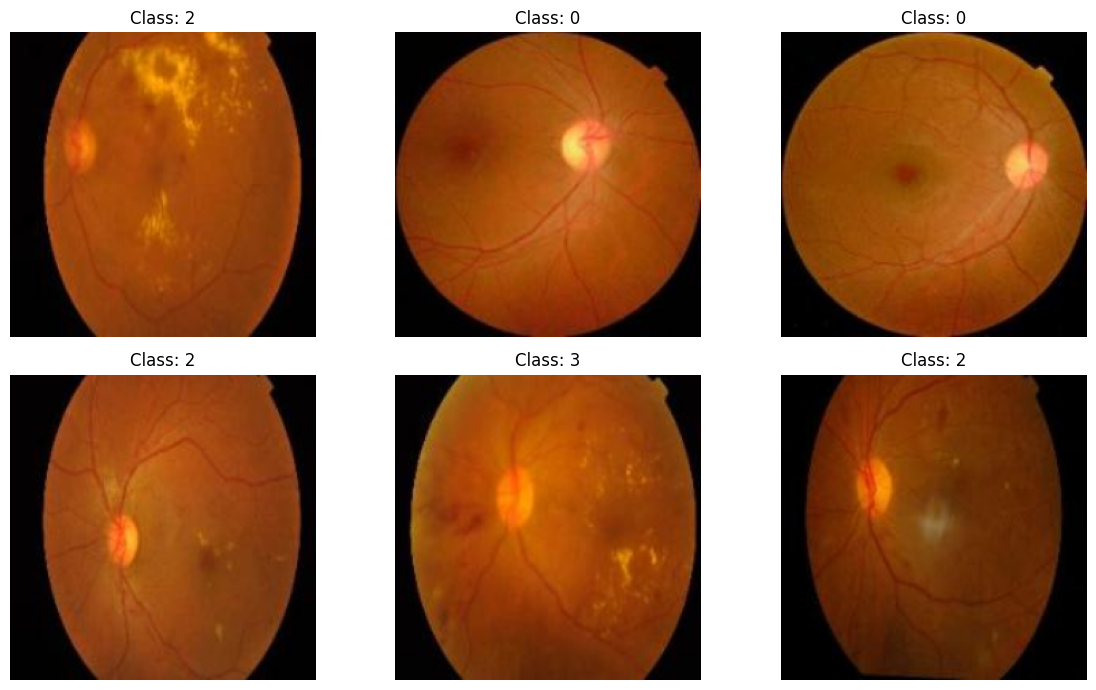

In [ ]:
import matplotlib.pyplot as plt

# Show 6 training images
fig, axes = plt.subplots(2, 3, figsize=(12, 7))

for i, ax in enumerate(axes.flat):
    image, label = train_dataset[i]

    # Convert CHW -> HWC for displaying
    image = image.permute(1, 2, 0)

    ax.imshow(image)
    ax.set_title(f"Class: {label}")
    ax.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import os

DATASET_DIR = "/content/drive/MyDrive/EyePACS/dataset"

for split in ["train", "valid", "test"]:
    df = pd.read_csv(os.path.join(DATASET_DIR, split, "labels.csv"))

    print(f"\n{split.upper()}")
    print(df["level"].value_counts().sort_index())


TRAIN
level
0    1004
1     202
2     538
3      89
4     153
Name: count, dtype: int64

VALID
level
0    288
1     61
2    155
3     28
4     36
Name: count, dtype: int64

TEST
level
0    138
1     31
2     73
3     14
4     28
Name: count, dtype: int64


SSL train images: 1986
DINO views: 6 [torch.Size([3, 224, 224]), torch.Size([3, 224, 224]), torch.Size([3, 96, 96]), torch.Size([3, 96, 96]), torch.Size([3, 96, 96]), torch.Size([3, 96, 96])]
BYOL views: 2 [torch.Size([3, 384, 384]), torch.Size([3, 384, 384])]


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


DINO batch views: 6 | per-view shape: torch.Size([4, 3, 224, 224])
SYNC OK


In [ ]:
import os, shutil
from pathlib import Path
import pandas as pd
import torch, torch.nn as nn, torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import timm
# ---------- 1) Copy dataset to LOCAL /content (fast I/O for GPU) ----------
src = Path("/content/drive/MyDrive/EyePACS/dataset")
dst = Path("/content/dataset")
if not dst.exists():
    shutil.copytree(src, dst)
    print("copied to local")
else:
    print("local copy already exists")

train_df = pd.read_csv(dst / "train" / "labels.csv")
print("local SSL train images:", len(train_df))

# Rebuild the SSL dataset on LOCAL paths (class from previous cell)
LOCAL_TRAIN = dst / "train"

class SSLImages(Dataset):
    def __init__(self, img_dir, df, transforms):
        self.img_dir = img_dir
        self.files = df["filename"].tolist()
        self.transforms = transforms
    def __len__(self):
        return len(self.files)
    def __getitem__(self, idx):
        img = Image.open(self.img_dir / self.files[idx]).convert("RGB")
        return [t(img) for t in self.transforms]

dino_ds = SSLImages(LOCAL_TRAIN, train_df,
                    [dino_global, dino_global] + [dino_local] * 4)
print("dino_ds on local path, len =", len(dino_ds))

# ---------- 2) DINO components (faithful to friend's notebook) ----------
class DINOHead(nn.Module):
    def __init__(self, in_dim=384, hidden=2048, bottleneck=256, out=2048):
        super().__init__()
        self.layers = nn.Sequential(
            nn.Linear(in_dim, hidden), nn.GELU(),
            nn.Linear(hidden, hidden), nn.GELU(),
            nn.Linear(hidden, bottleneck), nn.GELU(),
            nn.Linear(bottleneck, out))
        self.layers.apply(self._init_weights)
    def _init_weights(self, m):
        if isinstance(m, nn.Linear):
            nn.init.trunc_normal_(m.weight, std=0.02)
            if m.bias is not None:
                nn.init.zeros_(m.bias)
    def forward(self, x):
        return F.normalize(self.layers(x), dim=-1)

class MultiCropDINOLoss(nn.Module):
    def __init__(self, out_dim, ncrops, ncrops_t, student_temp=0.1,
                 teacher_temp=0.04, center_momentum=0.9):
        super().__init__()
        self.student_temp = student_temp
        self.teacher_temp = teacher_temp
        self.center_momentum = center_momentum
        self.ncrops = ncrops
        self.ncrops_t = ncrops_t
        self.register_buffer("center", torch.zeros(1, out_dim))

    def forward(self, student_out, teacher_out):
        teacher_raw = torch.cat(teacher_out, dim=0)
        teacher_soft = F.softmax((teacher_raw.detach() - self.center) / self.teacher_temp, dim=-1)
        teacher_chunks = teacher_soft.chunk(self.ncrops_t)
        loss = torch.tensor(0.0, device=teacher_raw.device)
        n = 0
        for s in student_out:
            q = F.log_softmax(s / self.student_temp, dim=-1)
            for t in teacher_chunks:
                loss += torch.mean(-t * q)
                n += 1
        loss = loss / n
        self.update_center(teacher_raw)
        return loss

    @torch.no_grad()
    def update_center(self, teacher_raw):
        self.center = self.center * self.center_momentum + \
                      (1 - self.center_momentum) * teacher_raw.mean(0, keepdim=True)

# ---------- 3) Build student/teacher, EMA, optimizer ----------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("device:", device)

def make_student():
    enc = timm.create_model("vit_small_patch16_224", pretrained=False, num_classes=0,dynamic_img_size=True)
    return nn.Sequential(enc, DINOHead(384, 2048, 256, 2048))

student = make_student().to(device)
teacher = make_student().to(device)
for p in teacher.parameters():
    p.requires_grad_(False)

loss_fn = MultiCropDINOLoss(out_dim=2048, ncrops=6, ncrops_t=2).to(device)
optimizer = torch.optim.AdamW(student.parameters(), lr=1e-4, weight_decay=0.04)
MOM = 0.996

@torch.no_grad()
def update_teacher_ema(teacher, student, m):
    for tp, sp in zip(teacher.parameters(), student.parameters()):
        tp.data.mul_(m).add_((1 - m) * sp.data)

# ---------- 4) Smoke test: 3 steps only ----------
loader = DataLoader(dino_ds, batch_size=4, shuffle=True,
                    num_workers=2, pin_memory=True, drop_last=True)
train_iter = iter(loader)
print("DINO smoke test: 3 steps...")
for step in range(3):
    views = [v.to(device) for v in next(train_iter)]
    teacher_out = [teacher(views[0]), teacher(views[1])]   # global crops only
    student_out = [student(v) for v in views]              # all 6 crops
    loss = loss_fn(student_out, teacher_out)
    optimizer.zero_grad()
    loss.backward()
    optimizer.step()
    update_teacher_ema(teacher, student, MOM)
    grad_ok = all(p.grad is not None for p in student.parameters() if p.requires_grad)
    print(f"step {step}: loss={loss.item():.4f}  backprop_ok={grad_ok}")

with torch.no_grad():
    diff = sum(((t - s).abs().sum()) for t, s in zip(teacher.parameters(), student.parameters()))
print("teacher != student (EMA worked):", diff.item() > 0)
print("DINO SMOKE TEST OK")

local copy already exists
local SSL train images: 1986
dino_ds on local path, len = 1986
device: cpu


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)


DINO smoke test: 3 steps...
step 0: loss=0.0037  backprop_ok=True
step 1: loss=0.0037  backprop_ok=True
step 2: loss=0.0037  backprop_ok=True
teacher != student (EMA worked): True
DINO SMOKE TEST OK


In [ ]:
import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

PyTorch: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

ValueError: Mountpoint must not already contain files

In [ ]:
import shutil
import os

if os.path.exists("/content/drive"):
    shutil.rmtree("/content/drive")

from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [ ]:
from pathlib import Path

DATASET_DIR = Path("/content/drive/MyDrive/EyePACS/dataset")

print("Dataset exists:", DATASET_DIR.exists())
print("Train exists:", (DATASET_DIR / "train").exists())
print("Train labels exists:", (DATASET_DIR / "train" / "labels.csv").exists())

Dataset exists: True
Train exists: True
Train labels exists: True


In [ ]:
import os, shutil
from pathlib import Path
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import timm

# ================= PATH =================
SRC = Path("/content/drive/MyDrive/EyePACS/dataset")
LOCAL = Path("/content/dataset")

if not LOCAL.exists():
    shutil.copytree(SRC, LOCAL)
    print("Dataset copied to local")
else:
    print("Local dataset already exists")

TRAIN_DIR = LOCAL / "train"
df = pd.read_csv(TRAIN_DIR / "labels.csv")

print("Training images:", len(df))

# ================= AUGMENTATIONS =================
normalize = transforms.Normalize(
    [0.485, 0.456, 0.406],
    [0.229, 0.224, 0.225]
)

global_crop = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.5, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.2, 0.2, 0.1, 0.02),
    transforms.ToTensor(),
    normalize
])

local_crop = transforms.Compose([
    transforms.RandomResizedCrop(96, scale=(0.2, 0.6)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.2, 0.2, 0.1, 0.02),
    transforms.ToTensor(),
    normalize
])

# ================= DATASET =================
class SSLImages(Dataset):
    def __init__(self, img_dir, df):
        self.img_dir = img_dir
        self.files = df["filename"].tolist()

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        img = Image.open(
            self.img_dir / self.files[idx]
        ).convert("RGB")

        return [
            global_crop(img),
            global_crop(img),
            local_crop(img),
            local_crop(img),
            local_crop(img),
            local_crop(img)
        ]

dataset = SSLImages(TRAIN_DIR, df)

loader = DataLoader(
    dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True
)

# ================= MODEL =================
class DINOHead(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(384, 2048),
            nn.GELU(),
            nn.Linear(2048, 2048),
            nn.GELU(),
            nn.Linear(2048, 256),
            nn.GELU(),
            nn.Linear(256, 2048)
        )

    def forward(self, x):
        return F.normalize(self.net(x), dim=-1)

def make_model():
    vit = timm.create_model(
        "vit_small_patch16_224",
        pretrained=False,
        num_classes=0,
        dynamic_img_size=True
    )
    return nn.Sequential(vit, DINOHead())

device = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))

student = make_model().to(device)
teacher = make_model().to(device)

teacher.load_state_dict(student.state_dict())

for p in teacher.parameters():
    p.requires_grad = False

optimizer = torch.optim.AdamW(
    student.parameters(),
    lr=1e-4,
    weight_decay=0.04
)

# ================= DINO LOSS =================
center = torch.zeros(1, 2048, device=device)

def dino_loss(student_out, teacher_out):
    global center

    teacher_cat = torch.cat(teacher_out)

    teacher_prob = F.softmax(
        (teacher_cat.detach() - center) / 0.04,
        dim=-1
    )

    teacher_chunks = teacher_prob.chunk(2)

    loss = 0
    count = 0

    for s in student_out:
        q = F.log_softmax(s / 0.1, dim=-1)

        for t in teacher_chunks:
            loss += (-t * q).mean()
            count += 1

    loss = loss / count

    with torch.no_grad():
        center = 0.9 * center + 0.1 * teacher_cat.mean(
            0, keepdim=True
        )

    return loss

# ================= TRAINING =================
CHECKPOINT_DIR = "/content/drive/MyDrive/EyePACS/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

EPOCHS = 5
MOM = 0.996

print("===== DINO TRAINING START =====")

for epoch in range(EPOCHS):

    student.train()
    total_loss = 0

    for step, views in enumerate(loader):

        views = [
            x.to(device, non_blocking=True)
            for x in views
        ]

        with torch.no_grad():
            teacher_out = [
                teacher(views[0]),
                teacher(views[1])
            ]

        student_out = [
            student(x) for x in views
        ]

        loss = dino_loss(
            student_out,
            teacher_out
        )

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        with torch.no_grad():
            for tp, sp in zip(
                teacher.parameters(),
                student.parameters()
            ):
                tp.data.mul_(MOM).add_(
                    sp.data,
                    alpha=1 - MOM
                )

        total_loss += loss.item()

        if (step + 1) % 20 == 0:
            print(
                f"Epoch {epoch+1}/{EPOCHS} | "
                f"Step {step+1}/{len(loader)} | "
                f"Loss {loss.item():.4f}"
            )

    avg_loss = total_loss / len(loader)

    save_path = (
        f"{CHECKPOINT_DIR}/dino_epoch_{epoch+1}.pth"
    )

    torch.save({
        "epoch": epoch + 1,
        "student": student.state_dict(),
        "teacher": teacher.state_dict(),
        "optimizer": optimizer.state_dict(),
        "loss": avg_loss
    }, save_path)

    print(
        f"Epoch {epoch+1} DONE | "
        f"Average Loss: {avg_loss:.4f}"
    )
    print("Saved:", save_path)

print("===== DINO TRAINING COMPLETE =====")

Dataset copied to local
Training images: 1986
GPU: Tesla T4
===== DINO TRAINING START =====
Epoch 1/5 | Step 20/124 | Loss 0.0037
Epoch 1/5 | Step 40/124 | Loss 0.0037
Epoch 1/5 | Step 60/124 | Loss 0.0037
Epoch 1/5 | Step 80/124 | Loss 0.0037
Epoch 1/5 | Step 100/124 | Loss 0.0037
Epoch 1/5 | Step 120/124 | Loss 0.0037
Epoch 1 DONE | Average Loss: 0.0037
Saved: /content/drive/MyDrive/EyePACS/checkpoints/dino_epoch_1.pth
Epoch 2/5 | Step 20/124 | Loss 0.0037
Epoch 2/5 | Step 40/124 | Loss 0.0037
Epoch 2/5 | Step 60/124 | Loss 0.0037
Epoch 2/5 | Step 80/124 | Loss 0.0037
Epoch 2/5 | Step 100/124 | Loss 0.0037
Epoch 2/5 | Step 120/124 | Loss 0.0037
Epoch 2 DONE | Average Loss: 0.0037
Saved: /content/drive/MyDrive/EyePACS/checkpoints/dino_epoch_2.pth
Epoch 3/5 | Step 20/124 | Loss 0.0037
Epoch 3/5 | Step 40/124 | Loss 0.0037
Epoch 3/5 | Step 60/124 | Loss 0.0037
Epoch 3/5 | Step 80/124 | Loss 0.0037
Epoch 3/5 | Step 100/124 | Loss 0.0037
Epoch 3/5 | Step 120/124 | Loss 0.0037
Epoch 3 DONE

In [ ]:
import os

CHECKPOINT_DIR = "/content/drive/MyDrive/EyePACS/checkpoints"

for f in sorted(os.listdir(CHECKPOINT_DIR)):
    print(f)

dino_epoch_1.pth
dino_epoch_2.pth
dino_epoch_3.pth
dino_epoch_4.pth
dino_epoch_5.pth


In [ ]:
import torch
import timm
from pathlib import Path

CHECKPOINT = "/content/drive/MyDrive/EyePACS/checkpoints/dino_epoch_5.pth"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Create ViT backbone
backbone = timm.create_model(
    "vit_small_patch16_224",
    pretrained=False,
    num_classes=0,
    dynamic_img_size=True
).to(device)

# Load DINO checkpoint
ckpt = torch.load(CHECKPOINT, map_location=device)

# DINO student contains backbone + head
student_state = ckpt["student"]

# Extract only backbone weights
backbone_state = {}
for k, v in student_state.items():
    if k.startswith("0."):
        backbone_state[k[2:]] = v

backbone.load_state_dict(backbone_state, strict=False)

# Freeze backbone
backbone.eval()
for p in backbone.parameters():
    p.requires_grad = False

print("DINO backbone loaded successfully")
print("Feature dimension:", backbone.num_features)
print("Device:", device)
print("READY FOR FEATURE EXTRACTION")

DINO backbone loaded successfully
Feature dimension: 384
Device: cuda
READY FOR FEATURE EXTRACTION


In [ ]:
import pandas as pd

for split in ["train", "valid", "test"]:
    df = pd.read_csv(f"/content/dataset/{split}/labels.csv")
    print(split, "columns:", df.columns.tolist())
    print(df.head(2), "\n")

train columns: ['filename', 'level']
                                            filename  level
0  ffcf7b45f213_png_jpg.rf.69504d5dba3c3567f3283a...      2
1  be197b663520_png_jpg.rf.69ec2f1687af8bb2e3539f...      0 

valid columns: ['filename', 'level']
                                            filename  level
0  c31651ea04c6_png_jpg.rf.624b1e972a132f574b75a3...      3
1  d6df4fe492ec_png_jpg.rf.6264db68f8c448f9d9ebd5...      0 

test columns: ['filename', 'level']
                                            filename  level
0  fdbc252813b1_png_jpg.rf.00b46056379246cec11cf3...      0
1  36677b70b1ef_png_jpg.rf.00f1a6ebe4b4200c87db23...      1 



In [ ]:
import torch
import pandas as pd
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from tqdm.auto import tqdm

DATASET_DIR = Path("/content/dataset")
SAVE_DIR = Path("/content/drive/MyDrive/EyePACS/features")
SAVE_DIR.mkdir(parents=True, exist_ok=True)

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],[0.229,0.224,0.225])
])

class DRDataset(Dataset):
    def __init__(self, folder):
        self.folder = Path(folder)
        self.df = pd.read_csv(self.folder / "labels.csv")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(self.folder / row["filename"]).convert("RGB")
        return transform(img), int(row["level"])

def extract_features(folder, name):
    ds = DRDataset(folder)
    loader = DataLoader(ds, batch_size=32, shuffle=False,
                        num_workers=2, pin_memory=True)

    features, labels = [], []

    with torch.no_grad():
        for images, y in tqdm(loader, desc=name):
            images = images.to(device, non_blocking=True)
            features.append(backbone(images).cpu())
            labels.append(y)

    features = torch.cat(features)
    labels = torch.cat(labels)

    torch.save(
        {"features": features, "labels": labels},
        SAVE_DIR / f"{name}_dino_features.pt"
    )

    print(name, features.shape, labels.shape)

extract_features(DATASET_DIR/"train", "train")
extract_features(DATASET_DIR/"valid", "valid")
extract_features(DATASET_DIR/"test", "test")

print("DINO FEATURE EXTRACTION COMPLETE")

train:   0%|          | 0/63 [00:00<?, ?it/s]

train torch.Size([1986, 384]) torch.Size([1986])


valid:   0%|          | 0/18 [00:00<?, ?it/s]

valid torch.Size([568, 384]) torch.Size([568])


test:   0%|          | 0/9 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b3f051e60c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionErrorException ignored in: : can only test a child process
<function _MultiProcessingDataLoaderIter.__del__ at 0x7b3f051e60c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

test torch.Size([284, 384]) torch.Size([284])
DINO FEATURE EXTRACTION COMPLETE


In [ ]:
import os
import pandas as pd
import torch
from torch.utils.data import DataLoader
from torchvision import transforms
from PIL import Image

DATASET_DIR = "/content/drive/MyDrive/EyePACS/dataset"


class DRDataset(Dataset):
    def __init__(self, split, transform=None):
        self.split_dir = os.path.join(DATASET_DIR, split)
        self.labels = pd.read_csv(
            os.path.join(self.split_dir, "labels.csv")
        )
        self.transform = transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, idx):
        filename = self.labels.iloc[idx]["filename"]
        label = int(self.labels.iloc[idx]["level"])

        image_path = os.path.join(self.split_dir, filename)

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label


# DINO-style augmentation
train_transform = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomVerticalFlip(),
    transforms.ColorJitter(
        brightness=0.3,
        contrast=0.3,
        saturation=0.2,
        hue=0.05
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# Validation/test transform
eval_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


train_dataset = DRDataset("train", train_transform)
valid_dataset = DRDataset("valid", eval_transform)
test_dataset = DRDataset("test", eval_transform)


# CPU preparation only
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2,
    pin_memory=False
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=False
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=False
)


print("Train batches:", len(train_loader))
print("Valid batches:", len(valid_loader))
print("Test batches:", len(test_loader))

# Test one batch
images, labels = next(iter(train_loader))

print("\nBatch image shape:", images.shape)
print("Batch labels shape:", labels.shape)
print("SUCCESS: DataLoader is working")

Train batches: 125
Valid batches: 36
Test batches: 18

Batch image shape: torch.Size([16, 3, 224, 224])
Batch labels shape: torch.Size([16])
SUCCESS: DataLoader is working


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score, confusion_matrix

FEATURE_DIR = "/content/drive/MyDrive/EyePACS/features"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def load_split(name):
    d = torch.load(f"{FEATURE_DIR}/{name}_dino_features.pt")
    return d["features"], d["labels"]

X_train, y_train = load_split("train")
X_valid, y_valid = load_split("valid")
X_test, y_test = load_split("test")

# Class weights for imbalance
counts = torch.bincount(y_train, minlength=5).float()
weights = counts.sum() / (5 * counts)

train_loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=64, shuffle=True
)

classifier = nn.Linear(384, 5).to(device)
criterion = nn.CrossEntropyLoss(weight=weights.to(device))
optimizer = torch.optim.AdamW(classifier.parameters(), lr=1e-3)

# Train
for epoch in range(20):
    classifier.train()
    total_loss = 0

    for X, y in train_loader:
        X, y = X.to(device), y.to(device)

        optimizer.zero_grad()
        loss = criterion(classifier(X), y)
        loss.backward()
        optimizer.step()

        total_loss += loss.item()

    print(f"Epoch {epoch+1}/20 | Loss: {total_loss/len(train_loader):.4f}")

# Evaluation
classifier.eval()

with torch.no_grad():
    logits = classifier(X_test.to(device))
    pred = logits.argmax(1).cpu()

acc = accuracy_score(y_test, pred)
f1 = f1_score(y_test, pred, average="macro")
qwk = cohen_kappa_score(y_test, pred, weights="quadratic")
cm = confusion_matrix(y_test, pred)

print("\n===== DINO RESULTS =====")
print(f"Accuracy : {acc:.4f}")
print(f"Macro F1 : {f1:.4f}")
print(f"QWK      : {qwk:.4f}")
print("\nConfusion Matrix:")
print(cm)

torch.save(classifier.state_dict(), f"{FEATURE_DIR}/dino_classifier.pth")
print("\nDINO CLASSIFIER COMPLETE")

Epoch 1/20 | Loss: 1.6220
Epoch 2/20 | Loss: 1.5405
Epoch 3/20 | Loss: 1.5528
Epoch 4/20 | Loss: 1.5498
Epoch 5/20 | Loss: 1.5233
Epoch 6/20 | Loss: 1.5070
Epoch 7/20 | Loss: 1.5286
Epoch 8/20 | Loss: 1.4859
Epoch 9/20 | Loss: 1.5063
Epoch 10/20 | Loss: 1.5195
Epoch 11/20 | Loss: 1.5019
Epoch 12/20 | Loss: 1.5259
Epoch 13/20 | Loss: 1.5028
Epoch 14/20 | Loss: 1.5197
Epoch 15/20 | Loss: 1.5107
Epoch 16/20 | Loss: 1.5334
Epoch 17/20 | Loss: 1.5045
Epoch 18/20 | Loss: 1.5005
Epoch 19/20 | Loss: 1.5178
Epoch 20/20 | Loss: 1.4704

===== DINO RESULTS =====
Accuracy : 0.5458
Macro F1 : 0.3096
QWK      : 0.3600

Confusion Matrix:
[[124   7   7   0   0]
 [  7  13   5   2   4]
 [ 24  23  14   3   9]
 [ 11   1   2   0   0]
 [ 10   6   7   1   4]]

DINO CLASSIFIER COMPLETE


In [ ]:
import timm
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

byol_backbone = timm.create_model(
    "resnet18",
    pretrained=False,
    num_classes=0
).to(device)

print("BYOL backbone ready")
print("Feature dimension:", byol_backbone.num_features)
print("Device:", device)

BYOL backbone ready
Feature dimension: 512
Device: cuda


In [ ]:
import torch, timm
import torch.nn as nn
import torch.nn.functional as F
from pathlib import Path
from PIL import Image
import pandas as pd
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from copy import deepcopy
from tqdm.auto import tqdm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATASET_DIR = Path("/content/dataset")
CKPT_DIR = Path("/content/drive/MyDrive/EyePACS/checkpoints")
CKPT_DIR.mkdir(parents=True, exist_ok=True)

# BYOL augmentation
byol_aug = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomApply(
        [transforms.ColorJitter(0.2,0.2,0.1,0.02)], p=0.8
    ),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],
                         [0.229,0.224,0.225])
])

class BYOLDataset(Dataset):
    def __init__(self):
        self.dir = DATASET_DIR / "train"
        self.df = pd.read_csv(self.dir / "labels.csv")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        img = Image.open(
            self.dir / self.df.iloc[i]["filename"]
        ).convert("RGB")
        return byol_aug(img), byol_aug(img)

byol_ds = BYOLDataset()

class MLP(nn.Module):
    def __init__(self, inp, hidden=512, out=256):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(inp, hidden),
            nn.BatchNorm1d(hidden),
            nn.ReLU(),
            nn.Linear(hidden, out)
        )
    def forward(self,x):
        return self.net(x)

online = timm.create_model(
    "resnet18", pretrained=False, num_classes=0
).to(device)

target = deepcopy(online).to(device)

projector = MLP(512).to(device)
predictor = MLP(256).to(device)

for p in target.parameters():
    p.requires_grad = False

optimizer = torch.optim.AdamW(
    list(online.parameters()) +
    list(projector.parameters()) +
    list(predictor.parameters()),
    lr=1e-3, weight_decay=1e-4
)

loader = DataLoader(
    byol_ds, batch_size=16, shuffle=True,
    num_workers=2, pin_memory=True, drop_last=True
)

def byol_loss(p,z):
    p = F.normalize(p,dim=1)
    z = F.normalize(z,dim=1)
    return 2 - 2*(p*z.detach()).sum(dim=1).mean()

print("===== BYOL TRAINING START =====")

for epoch in range(5):
    online.train()
    total = 0

    for v1,v2 in tqdm(loader, desc=f"Epoch {epoch+1}/5"):
        v1,v2 = v1.to(device),v2.to(device)

        z1 = projector(online(v1))
        z2 = projector(online(v2))

        with torch.no_grad():
            t1 = projector(target(v1))
            t2 = projector(target(v2))

        loss = (
            byol_loss(predictor(z1),t2) +
            byol_loss(predictor(z2),t1)
        ) / 2

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        with torch.no_grad():
            for po,pt in zip(online.parameters(),
                             target.parameters()):
                pt.data.mul_(0.996).add_(po.data,alpha=0.004)

        total += loss.item()

    avg = total/len(loader)
    print(f"Epoch {epoch+1} | Loss: {avg:.4f}")

    torch.save({
        "online":online.state_dict(),
        "target":target.state_dict(),
        "projector":projector.state_dict(),
        "predictor":predictor.state_dict()
    }, CKPT_DIR/f"byol_epoch_{epoch+1}.pth")

print("===== BYOL TRAINING COMPLETE =====")

===== BYOL TRAINING START =====


Epoch 1/5:   0%|          | 0/124 [00:00<?, ?it/s]

Epoch 1 | Loss: 0.5117


Epoch 2/5:   0%|          | 0/124 [00:00<?, ?it/s]

Epoch 2 | Loss: 0.3354


...

Epoch 4/5:   0%|          | 0/124 [00:00<?, ?it/s]

Epoch 4 | Loss: 0.2581


Epoch 5/5:   0%|          | 0/124 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b3f051e60c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b3f051e60c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

Epoch 5 | Loss: 0.2502
===== BYOL TRAINING COMPLETE =====


In [ ]:
import torch
import pandas as pd
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from tqdm.auto import tqdm

DATASET_DIR = Path("/content/dataset")
SAVE_DIR = Path("/content/drive/MyDrive/EyePACS/features")
CKPT = "/content/drive/MyDrive/EyePACS/checkpoints/byol_epoch_5.pth"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load trained BYOL backbone
online.load_state_dict(torch.load(CKPT, map_location=device)["online"])
online.eval()

for p in online.parameters():
    p.requires_grad = False

transform = transforms.Compose([
    transforms.Resize((224,224)),
    transforms.ToTensor(),
    transforms.Normalize([0.485,0.456,0.406],
                         [0.229,0.224,0.225])
])

class DRDataset(Dataset):
    def __init__(self, folder):
        self.folder = Path(folder)
        self.df = pd.read_csv(self.folder/"labels.csv")

    def __len__(self):
        return len(self.df)

    def __getitem__(self,i):
        row = self.df.iloc[i]
        img = Image.open(self.folder/row["filename"]).convert("RGB")
        return transform(img), int(row["level"])

def extract(folder,name):
    ds = DRDataset(folder)
    loader = DataLoader(ds,batch_size=32,shuffle=False,num_workers=2)

    features,labels=[],[]

    with torch.no_grad():
        for x,y in tqdm(loader,desc=name):
            x=x.to(device)
            features.append(online(x).cpu())
            labels.append(y)

    features=torch.cat(features)
    labels=torch.cat(labels)

    torch.save(
        {"features":features,"labels":labels},
        SAVE_DIR/f"{name}_byol_features.pt"
    )

    print(name,features.shape,labels.shape)

extract(DATASET_DIR/"train","train")
extract(DATASET_DIR/"valid","valid")
extract(DATASET_DIR/"test","test")

print("BYOL FEATURE EXTRACTION COMPLETE")

train:   0%|          | 0/63 [00:00<?, ?it/s]

train torch.Size([1986, 512]) torch.Size([1986])


valid:   0%|          | 0/18 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b3f051e60c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b3f051e60c0>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

valid torch.Size([568, 512]) torch.Size([568])


test:   0%|          | 0/9 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7b3f051e60c0>
Exception ignored in: Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
<function _MultiProcessingDataLoaderIter.__del__ at 0x7b3f051e60c0>    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers

    if w.is_alive():Traceback (most recent call last):

  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    Exception ignored in:   File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
<function _MultiProcessingDataLoaderIter.__del__ at 0x7b3f051e60c0>assert self._parent_pid == os.getpid(), 'can only test a child process'

    AssertionErrorException ignored in: Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/d

test torch.Size([284, 512]) torch.Size([284])
BYOL FEATURE EXTRACTION COMPLETE


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score, confusion_matrix

DIR = "/content/drive/MyDrive/EyePACS/features"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

def load(name):
    d = torch.load(f"{DIR}/{name}_byol_features.pt")
    return d["features"], d["labels"]

Xtr,ytr = load("train")
Xv,yv = load("valid")
Xte,yte = load("test")

counts = torch.bincount(ytr, minlength=5).float()
weights = counts.sum() / (5 * counts)

loader = DataLoader(
    TensorDataset(Xtr,ytr),
    batch_size=64,
    shuffle=True
)

clf = nn.Linear(512,5).to(device)
loss_fn = nn.CrossEntropyLoss(weight=weights.to(device))
opt = torch.optim.AdamW(clf.parameters(),lr=1e-3)

for epoch in range(20):
    clf.train()
    total = 0

    for X,y in loader:
        X,y = X.to(device),y.to(device)
        opt.zero_grad()
        loss = loss_fn(clf(X),y)
        loss.backward()
        opt.step()
        total += loss.item()

    print(f"Epoch {epoch+1}/20 | Loss: {total/len(loader):.4f}")

clf.eval()
with torch.no_grad():
    pred = clf(Xte.to(device)).argmax(1).cpu()

print("\n===== BYOL RESULTS =====")
print(f"Accuracy : {accuracy_score(yte,pred):.4f}")
print(f"Macro F1 : {f1_score(yte,pred,average='macro'):.4f}")
print(f"QWK      : {cohen_kappa_score(yte,pred,weights='quadratic'):.4f}")
print("\nConfusion Matrix:")
print(confusion_matrix(yte,pred))

torch.save(clf.state_dict(),f"{DIR}/byol_classifier.pth")
print("\nBYOL CLASSIFIER COMPLETE")

Epoch 1/20 | Loss: 1.5656
Epoch 2/20 | Loss: 1.5007
Epoch 3/20 | Loss: 1.4409
Epoch 4/20 | Loss: 1.4554
Epoch 5/20 | Loss: 1.4444
Epoch 6/20 | Loss: 1.4493
Epoch 7/20 | Loss: 1.4236
Epoch 8/20 | Loss: 1.3783
Epoch 9/20 | Loss: 1.3894
Epoch 10/20 | Loss: 1.4105
Epoch 11/20 | Loss: 1.3855
Epoch 12/20 | Loss: 1.4013
Epoch 13/20 | Loss: 1.3669
Epoch 14/20 | Loss: 1.3746
Epoch 15/20 | Loss: 1.3387
Epoch 16/20 | Loss: 1.3733
Epoch 17/20 | Loss: 1.3482
Epoch 18/20 | Loss: 1.3621
Epoch 19/20 | Loss: 1.3541
Epoch 20/20 | Loss: 1.3597

===== BYOL RESULTS =====
Accuracy : 0.5387
Macro F1 : 0.3629
QWK      : 0.4940

Confusion Matrix:
[[114   6   1  13   4]
 [  1  17   2   9   2]
 [  4  26  13  26   4]
 [  4   3   1   6   0]
 [  2   8   5  10   3]]

BYOL CLASSIFIER COMPLETE


In [ ]:
import torch
from sklearn.metrics import silhouette_score

DIR = "/content/drive/MyDrive/EyePACS/features"

for method in ["dino", "byol"]:
    d = torch.load(f"{DIR}/test_{method}_features.pt")
    X = d["features"].numpy()
    y = d["labels"].numpy()

    # Check feature variation
    feature_std = X.std(axis=0).mean()

    # Check class separation
    sil = silhouette_score(X, y)

    print(f"\n{method.upper()}")
    print(f"Feature mean std : {feature_std:.6f}")
    print(f"Silhouette score : {sil:.4f}")


DINO
Feature mean std : 0.583673
Silhouette score : -0.2084

BYOL
Feature mean std : 0.299203
Silhouette score : -0.1235


In [ ]:
import pandas as pd

results = pd.DataFrame({
    "Method": ["DINO", "BYOL"],
    "Accuracy": [0.5458, 0.5387],
    "Macro F1": [0.3096, 0.3629],
    "QWK": [0.3600, 0.4940]
})

print(results.to_string(index=False))

results.to_csv(
    "/content/drive/MyDrive/EyePACS/results_dino_vs_byol.csv",
    index=False
)

print("\nResults saved successfully.")

Method  Accuracy  Macro F1   QWK
  DINO    0.5458    0.3096 0.360
  BYOL    0.5387    0.3629 0.494

Results saved successfully.


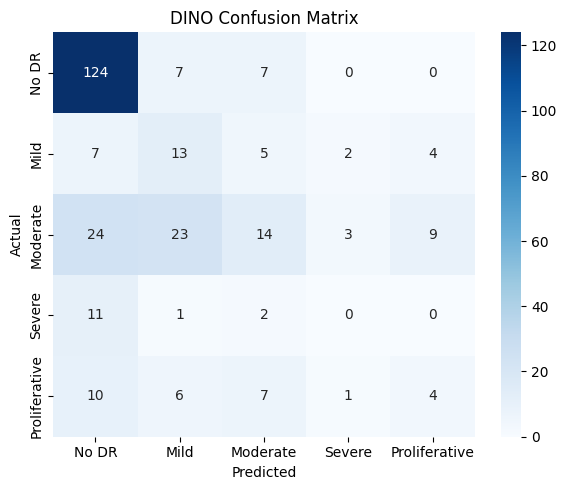

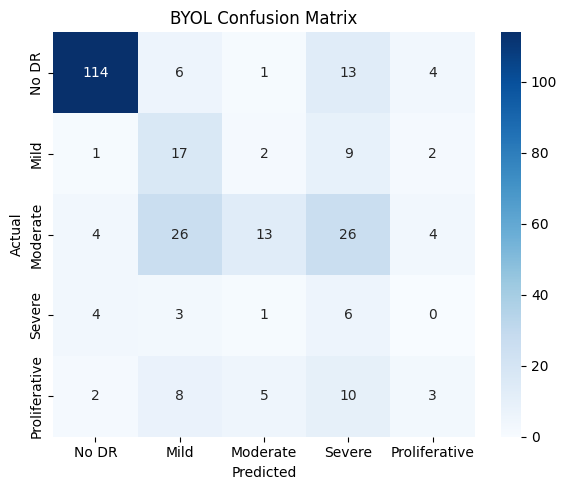

CONFUSION MATRICES SAVED


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
import torch
from sklearn.metrics import confusion_matrix

DIR = "/content/drive/MyDrive/EyePACS/features"
classes = ["No DR","Mild","Moderate","Severe","Proliferative"]

for method in ["dino","byol"]:
    d = torch.load(f"{DIR}/test_{method}_features.pt")

    X = d["features"]
    y = d["labels"]

    if method == "dino":
        clf = torch.nn.Linear(384,5)
        path = f"{DIR}/dino_classifier.pth"
    else:
        clf = torch.nn.Linear(512,5)
        path = f"{DIR}/byol_classifier.pth"

    clf.load_state_dict(torch.load(path,map_location="cpu"))
    clf.eval()

    with torch.no_grad():
        pred = clf(X).argmax(1).numpy()

    cm = confusion_matrix(y.numpy(),pred)

    plt.figure(figsize=(6,5))
    sns.heatmap(
        cm, annot=True, fmt="d", cmap="Blues",
        xticklabels=classes, yticklabels=classes
    )
    plt.title(f"{method.upper()} Confusion Matrix")
    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.tight_layout()
    plt.savefig(
        f"/content/drive/MyDrive/EyePACS/{method}_confusion_matrix.png",
        dpi=300
    )
    plt.show()

print("CONFUSION MATRICES SAVED")

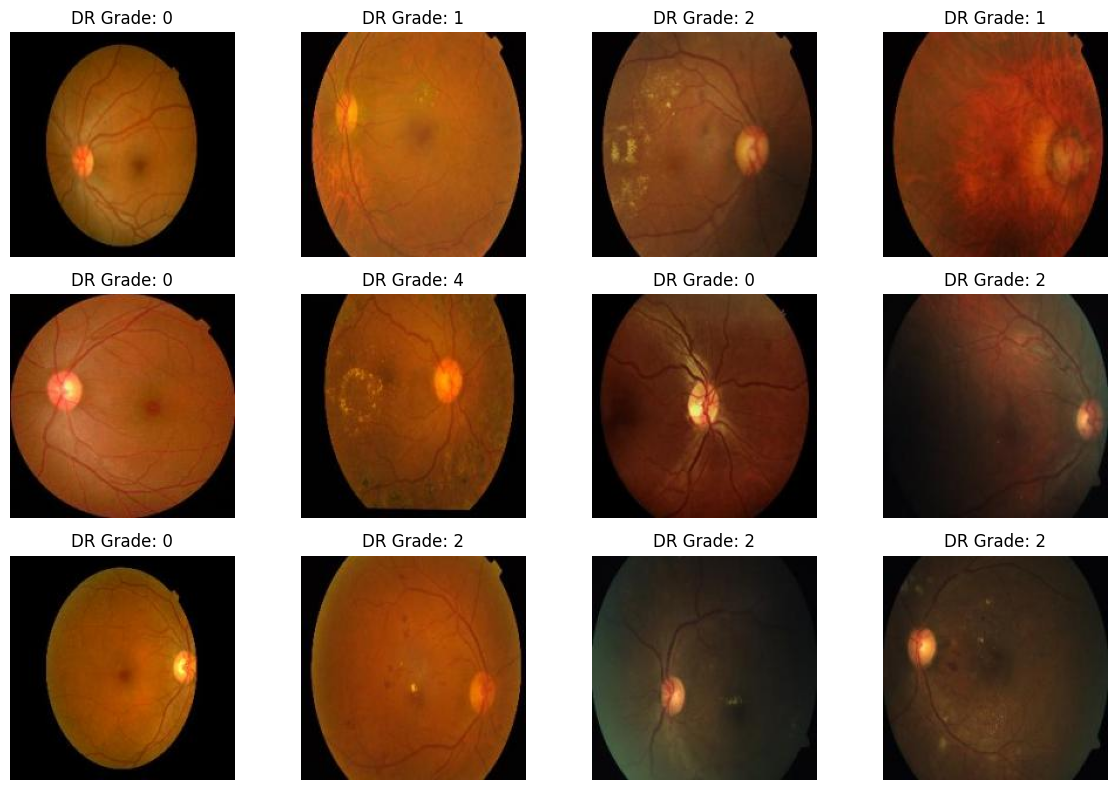

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image
import pandas as pd
from pathlib import Path

DATASET_DIR = Path("/content/dataset")

df = pd.read_csv(DATASET_DIR/"test"/"labels.csv")

plt.figure(figsize=(12,8))

for i in range(12):
    row = df.iloc[i]
    img = Image.open(DATASET_DIR/"test"/row["filename"]).convert("RGB")

    plt.subplot(3,4,i+1)
    plt.imshow(img)
    plt.title(f"DR Grade: {row['level']}")
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
import os

for root, dirs, files in os.walk("/content"):
    if len(files) > 0:
        print("\nFolder:", root)
        print("Files:", files[:10])


Folder: /content/.config
Files: ['hidden_gcloud_config_universe_descriptor_data_cache_configs.db', 'active_config', '.last_update_check.json', '.last_opt_in_prompt.yaml', 'config_sentinel', 'default_configs.db', '.last_survey_prompt.yaml', 'gce']

Folder: /content/.config/logs/2026.09.16
Files: ['13.26.30.459687.log', '13.26.29.139725.log', '13.26.04.283691.log', '13.26.15.129583.log', '13.26.17.091876.log', '13.25.37.877256.log']

Folder: /content/.config/configurations
Files: ['config_default']

Folder: /content/drive/MyDrive
Files: ['Agro1.drawio', 'Object Diagram.drawio', 'Sequence Diagram (1).drawio.png', 'Sequence Diagram.drawio.png', 'resume (1).pdf', 'resume.pdf', 'Salary_Data.csv', 'Advertising.csv']

Folder: /content/drive/MyDrive/Colab Notebooks
Files: ['Untitled0.ipynb', 'lab6.ipynb', 'NLKT_toolkit.ipynb', 'Untitled1.ipynb']

Folder: /content/drive/MyDrive/EyePACS
Files: ['diabetic-retinopathy-screening.zip']

Folder: /content/sample_data
Files: ['README.md', 'anscombe.jso

In [ ]:
import torch
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

DIR = "/content/drive/MyDrive/EyePACS/features"

for method in ["dino", "byol"]:
    tr = torch.load(f"{DIR}/train_{method}_features.pt")
    te = torch.load(f"{DIR}/test_{method}_features.pt")

    X_train = tr["features"].numpy()
    y_train = tr["labels"].numpy()
    X_test = te["features"].numpy()
    y_test = te["labels"].numpy()

    clf = LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        solver="lbfgs"
    )

    clf.fit(X_train, y_train)
    pred = clf.predict(X_test)

    print(f"\n===== {method.upper()} LOGISTIC REGRESSION =====")
    print(f"Accuracy : {accuracy_score(y_test,pred):.4f}")
    print(f"Macro F1 : {f1_score(y_test,pred,average='macro'):.4f}")
    print(f"QWK      : {cohen_kappa_score(y_test,pred,weights='quadratic'):.4f}")


===== DINO LOGISTIC REGRESSION =====
Accuracy : 0.5634
Macro F1 : 0.3842
QWK      : 0.5505

===== BYOL LOGISTIC REGRESSION =====
Accuracy : 0.6056
Macro F1 : 0.4393
QWK      : 0.5663


In [ ]:
import torch
import torch.nn as nn
import timm
from PIL import Image
from torchvision import transforms
from google.colab import files

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Upload one retinal/fundus image
uploaded = files.upload()
image_path = next(iter(uploaded))

# Image preprocessing
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

img = Image.open(image_path).convert("RGB")
x = transform(img).unsqueeze(0).to(device)

classes = {
    0: "No DR",
    1: "Mild DR",
    2: "Moderate DR",
    3: "Severe DR",
    4: "Proliferative DR"
}

# =========================
# BYOL BACKBONE
# =========================
byol = timm.create_model(
    "resnet18",
    pretrained=False,
    num_classes=0
).to(device)

byol_ckpt = torch.load(
    "/content/drive/MyDrive/EyePACS/checkpoints/byol_epoch_5.pth",
    map_location=device
)

byol.load_state_dict(byol_ckpt["online"], strict=False)
byol.eval()

# BYOL classifier
byol_clf = nn.Linear(512, 5).to(device)

byol_clf.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/EyePACS/features/byol_classifier.pth",
        map_location=device
    )
)

byol_clf.eval()

# =========================
# PREDICTION
# =========================
with torch.no_grad():
    features = byol(x)
    logits = byol_clf(features)
    probabilities = torch.softmax(logits, dim=1)

pred = probabilities.argmax(dim=1).item()
confidence = probabilities[0, pred].item()

print("\n==============================")
print("       BYOL PREDICTION")
print("==============================")
print("Image:", image_path)
print("Predicted DR Grade:", pred)
print("Predicted Class:", classes[pred])
print(f"Softmax Confidence: {confidence:.2%}")

print("\nClass probabilities:")
for i in range(5):
    print(f"{i} - {classes[i]}: {probabilities[0,i].item():.2%}")

KeyboardInterrupt: 

In [ ]:
import pandas as pd
from pathlib import Path
from PIL import Image
import matplotlib.pyplot as plt

test_dir = Path("/content/dataset/test")
df = pd.read_csv(test_dir / "labels.csv")

row = df.sample(1).iloc[0]
image_path = test_dir / row["filename"]

print("Image:", row["filename"])
print("Actual DR Grade:", row["level"])

img = Image.open(image_path).convert("RGB")
plt.imshow(img)
plt.axis("off")
plt.show()

In [ ]:
import pandas as pd
from pathlib import Path

test_dir = Path("/content/dataset/test")
df = pd.read_csv(test_dir / "labels.csv")

row = df.iloc[0]

print("Image:", row["filename"])
print("Actual DR Grade:", row["level"])
print("Full path:", test_dir / row["filename"])

Image: fdbc252813b1_png_jpg.rf.00b46056379246cec11cf3d400e99c62.jpg
Actual DR Grade: 0
Full path: /content/dataset/test/fdbc252813b1_png_jpg.rf.00b46056379246cec11cf3d400e99c62.jpg


In [ ]:
import torch
import torch.nn as nn
import timm
from PIL import Image
from torchvision import transforms

# =========================
# SETTINGS
# =========================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

image_path = "/content/dataset/test/fdbc252813b1_png_jpg.rf.00b46056379246cec11cf3d400e99c62.jpg"

classes = {
    0: "No DR",
    1: "Mild DR",
    2: "Moderate DR",
    3: "Severe DR",
    4: "Proliferative DR"
}

# Actual label from labels.csv
actual_grade = 0

# =========================
# IMAGE PREPROCESSING
# =========================
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

img = Image.open(image_path).convert("RGB")
x = transform(img).unsqueeze(0).to(device)

# =========================
# LOAD BYOL BACKBONE
# =========================
byol = timm.create_model(
    "resnet18",
    pretrained=False,
    num_classes=0
).to(device)

checkpoint = torch.load(
    "/content/drive/MyDrive/EyePACS/checkpoints/byol_epoch_5.pth",
    map_location=device
)

byol.load_state_dict(checkpoint["online"], strict=False)
byol.eval()

# =========================
# LOAD CLASSIFIER
# =========================
classifier = nn.Linear(512, 5).to(device)

classifier.load_state_dict(
    torch.load(
        "/content/drive/MyDrive/EyePACS/features/byol_classifier.pth",
        map_location=device
    )
)

classifier.eval()

# =========================
# PREDICTION
# =========================
with torch.no_grad():
    features = byol(x)
    logits = classifier(features)
    probabilities = torch.softmax(logits, dim=1)

predicted_grade = probabilities.argmax(dim=1).item()
confidence = probabilities[0, predicted_grade].item()

# =========================
# RESULT
# =========================
print("===================================")
print("          BYOL TEST RESULT")
print("===================================")

print("Image:", image_path)
print("Actual Grade   :", actual_grade)
print("Actual Class   :", classes[actual_grade])
print("Predicted Grade:", predicted_grade)
print("Predicted Class:", classes[predicted_grade])
print(f"Confidence     : {confidence:.2%}")

print("\nClass Probabilities:")
for i in range(5):
    print(f"Grade {i} ({classes[i]}): {probabilities[0,i].item():.2%}")

print("\n===================================")

if predicted_grade == actual_grade:
    print("RESULT: CORRECT PREDICTION")
else:
    print("RESULT: INCORRECT PREDICTION")

print("===================================")

          BYOL TEST RESULT
Image: /content/dataset/test/fdbc252813b1_png_jpg.rf.00b46056379246cec11cf3d400e99c62.jpg
Actual Grade   : 0
Actual Class   : No DR
Predicted Grade: 0
Predicted Class: No DR
Confidence     : 82.08%

Class Probabilities:
Grade 0 (No DR): 82.08%
Grade 1 (Mild DR): 0.36%
Grade 2 (Moderate DR): 4.57%
Grade 3 (Severe DR): 7.98%
Grade 4 (Proliferative DR): 5.00%

RESULT: CORRECT PREDICTION


  Method  Accuracy  Macro F1    QWK
0   DINO    0.5458    0.3096  0.360
1   BYOL    0.5387    0.3629  0.494


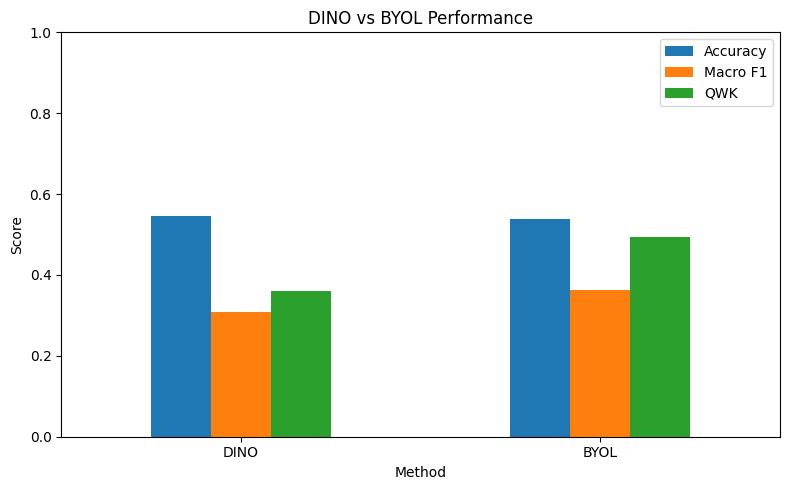

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

path = "/content/drive/MyDrive/EyePACS/results_dino_vs_byol.csv"

df = pd.read_csv(path)
print(df)

df.set_index("Method")[["Accuracy", "Macro F1", "QWK"]].plot(
    kind="bar",
    figsize=(8,5)
)

plt.title("DINO vs BYOL Performance")
plt.ylabel("Score")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


===== DINO CONFUSION MATRIX =====
[[124   7   7   0   0]
 [  7  13   5   2   4]
 [ 24  23  14   3   9]
 [ 11   1   2   0   0]
 [ 10   6   7   1   4]]


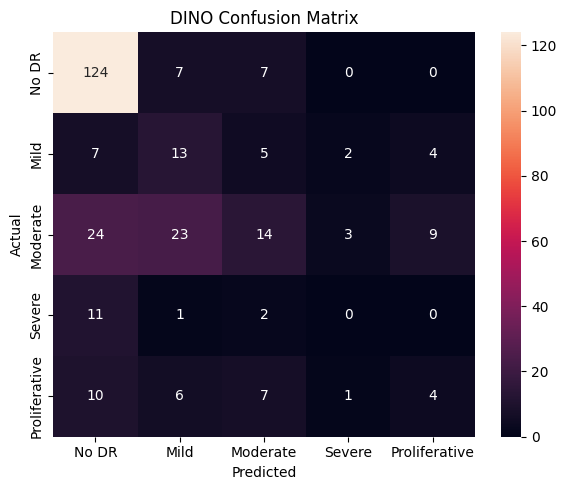


===== BYOL CONFUSION MATRIX =====
[[114   6   1  13   4]
 [  1  17   2   9   2]
 [  4  26  13  26   4]
 [  4   3   1   6   0]
 [  2   8   5  10   3]]


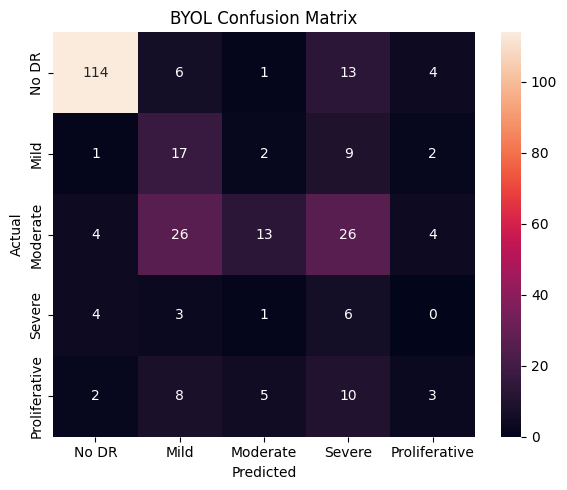

In [ ]:
import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

DIR = "/content/drive/MyDrive/EyePACS/features"

for method in ["dino", "byol"]:
    data = torch.load(f"{DIR}/test_{method}_features.pt")

    X = data["features"]
    y_true = data["labels"]

    input_dim = X.shape[1]

    model = torch.nn.Linear(input_dim, 5)

    model.load_state_dict(
        torch.load(
            f"{DIR}/{method}_classifier.pth",
            map_location="cpu"
        )
    )

    model.eval()

    with torch.no_grad():
        logits = model(X)
        y_pred = logits.argmax(dim=1).numpy()

    y_true = y_true.numpy()

    cm = confusion_matrix(y_true, y_pred)

    print(f"\n===== {method.upper()} CONFUSION MATRIX =====")
    print(cm)

    plt.figure(figsize=(6,5))
    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        xticklabels=["No DR","Mild","Moderate","Severe","Proliferative"],
        yticklabels=["No DR","Mild","Moderate","Severe","Proliferative"]
    )

    plt.xlabel("Predicted")
    plt.ylabel("Actual")
    plt.title(f"{method.upper()} Confusion Matrix")
    plt.tight_layout()
    plt.show()

In [ ]:
import os

files_to_check = [
    "/content/drive/MyDrive/EyePACS/checkpoints/dino_epoch_5.pth",
    "/content/drive/MyDrive/EyePACS/checkpoints/byol_epoch_5.pth",
    "/content/drive/MyDrive/EyePACS/features/train_dino_features.pt",
    "/content/drive/MyDrive/EyePACS/features/valid_dino_features.pt",
    "/content/drive/MyDrive/EyePACS/features/test_dino_features.pt",
    "/content/drive/MyDrive/EyePACS/features/train_byol_features.pt",
    "/content/drive/MyDrive/EyePACS/features/valid_byol_features.pt",
    "/content/drive/MyDrive/EyePACS/features/test_byol_features.pt",
    "/content/drive/MyDrive/EyePACS/features/dino_classifier.pth",
    "/content/drive/MyDrive/EyePACS/features/byol_classifier.pth",
    "/content/drive/MyDrive/EyePACS/results_dino_vs_byol.csv"
]

print("===== PROJECT FILE CHECK =====")

for f in files_to_check:
    if os.path.exists(f):
        size_mb = os.path.getsize(f) / (1024 * 1024)
        print(f"✅ {os.path.basename(f)} | {size_mb:.2f} MB")
    else:
        print(f"❌ MISSING: {f}")

===== PROJECT FILE CHECK =====
❌ MISSING: /content/drive/MyDrive/EyePACS/checkpoints/dino_epoch_5.pth
❌ MISSING: /content/drive/MyDrive/EyePACS/checkpoints/byol_epoch_5.pth
❌ MISSING: /content/drive/MyDrive/EyePACS/features/train_dino_features.pt
❌ MISSING: /content/drive/MyDrive/EyePACS/features/valid_dino_features.pt
❌ MISSING: /content/drive/MyDrive/EyePACS/features/test_dino_features.pt
❌ MISSING: /content/drive/MyDrive/EyePACS/features/train_byol_features.pt
❌ MISSING: /content/drive/MyDrive/EyePACS/features/valid_byol_features.pt
❌ MISSING: /content/drive/MyDrive/EyePACS/features/test_byol_features.pt
❌ MISSING: /content/drive/MyDrive/EyePACS/features/dino_classifier.pth
❌ MISSING: /content/drive/MyDrive/EyePACS/features/byol_classifier.pth
❌ MISSING: /content/drive/MyDrive/EyePACS/results_dino_vs_byol.csv


In [ ]:
from google.colab import drive
drive.mount('/content/drive', force_remount=True)

import os

print("Drive mounted:", os.path.exists("/content/drive/MyDrive"))

print("\n===== MYDRIVE TOP-LEVEL FOLDERS =====")
for item in os.listdir("/content/drive/MyDrive"):
    print(item)

Mounted at /content/drive
Drive mounted: True

===== MYDRIVE TOP-LEVEL FOLDERS =====
Agro1.drawio
Object Diagram.drawio
Sequence Diagram (1).drawio.png
Sequence Diagram.drawio.png
resume (1).pdf
resume.pdf
Salary_Data.csv
Advertising.csv
Colab Notebooks
EyePACS


In [ ]:
import os

search_names = [
    "dino_epoch_5.pth",
    "byol_epoch_5.pth",
    "train_dino_features.pt",
    "valid_dino_features.pt",
    "test_dino_features.pt",
    "train_byol_features.pt",
    "valid_byol_features.pt",
    "test_byol_features.pt",
    "dino_classifier.pth",
    "byol_classifier.pth",
    "results_dino_vs_byol.csv"
]

print("===== SEARCHING ENTIRE GOOGLE DRIVE =====\n")

found = False

for root, dirs, files in os.walk("/content/drive/MyDrive"):
    for file in files:
        if file in search_names:
            print("✅ FOUND:", os.path.join(root, file))
            found = True

if not found:
    print("❌ None of the expected files were found.")

===== SEARCHING ENTIRE GOOGLE DRIVE =====

✅ FOUND: /content/drive/MyDrive/EyePACS/results_dino_vs_byol.csv
✅ FOUND: /content/drive/MyDrive/EyePACS/checkpoints/dino_epoch_5.pth
✅ FOUND: /content/drive/MyDrive/EyePACS/checkpoints/byol_epoch_5.pth
✅ FOUND: /content/drive/MyDrive/EyePACS/features/train_dino_features.pt
✅ FOUND: /content/drive/MyDrive/EyePACS/features/valid_dino_features.pt
✅ FOUND: /content/drive/MyDrive/EyePACS/features/test_dino_features.pt
✅ FOUND: /content/drive/MyDrive/EyePACS/features/dino_classifier.pth
✅ FOUND: /content/drive/MyDrive/EyePACS/features/train_byol_features.pt
✅ FOUND: /content/drive/MyDrive/EyePACS/features/valid_byol_features.pt
✅ FOUND: /content/drive/MyDrive/EyePACS/features/test_byol_features.pt
✅ FOUND: /content/drive/MyDrive/EyePACS/features/byol_classifier.pth


In [ ]:
import pandas as pd

RESULTS = "/content/drive/MyDrive/EyePACS/results_dino_vs_byol.csv"

results = pd.read_csv(RESULTS)

print("===== FINAL RESULTS =====")
display(results)

===== FINAL RESULTS =====


,Method,Accuracy,Macro F1,QWK
0,DINO,0.5458,0.3096,0.360
1,BYOL,0.5387,0.3629,0.494


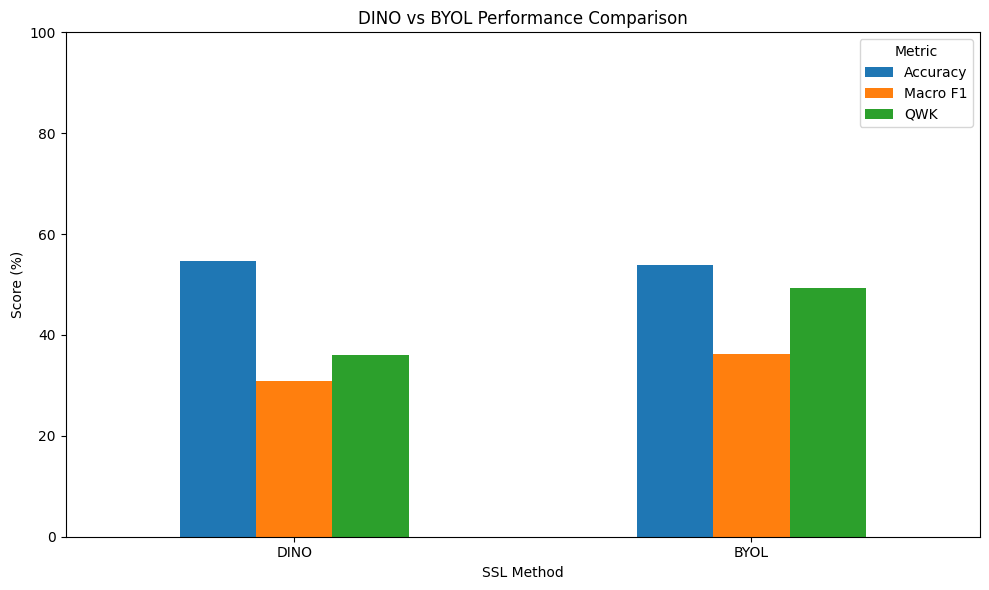

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

RESULTS = "/content/drive/MyDrive/EyePACS/results_dino_vs_byol.csv"

results = pd.read_csv(RESULTS)

# Convert metrics to percentages for easier visualization
plot_results = results.copy()
plot_results["Accuracy"] *= 100
plot_results["Macro F1"] *= 100
plot_results["QWK"] *= 100

ax = plot_results.set_index("Method")[["Accuracy", "Macro F1", "QWK"]].plot(
    kind="bar",
    figsize=(10, 6)
)

plt.title("DINO vs BYOL Performance Comparison")
plt.ylabel("Score (%)")
plt.xlabel("SSL Method")
plt.xticks(rotation=0)
plt.ylim(0, 100)
plt.legend(title="Metric")
plt.tight_layout()
plt.show()

In [ ]:
import pandas as pd
import numpy as np

RESULTS = "/content/drive/MyDrive/EyePACS/results_dino_vs_byol.csv"

results = pd.read_csv(RESULTS)

print("===== FINAL PERFORMANCE COMPARISON =====\n")

for _, row in results.iterrows():
    print(f"{row['Method']}")
    print(f"  Accuracy : {row['Accuracy']:.4f} ({row['Accuracy']*100:.2f}%)")
    print(f"  Macro F1 : {row['Macro F1']:.4f} ({row['Macro F1']*100:.2f}%)")
    print(f"  QWK      : {row['QWK']:.4f}")
    print()

# Differences: BYOL - DINO
dino = results[results["Method"] == "DINO"].iloc[0]
byol = results[results["Method"] == "BYOL"].iloc[0]

print("===== DIFFERENCE (BYOL - DINO) =====")
print(f"Accuracy difference : {(byol['Accuracy']-dino['Accuracy'])*100:.2f} percentage points")
print(f"Macro F1 difference : {(byol['Macro F1']-dino['Macro F1'])*100:.2f} percentage points")
print(f"QWK difference      : {byol['QWK']-dino['QWK']:.4f}")

===== FINAL PERFORMANCE COMPARISON =====

DINO
  Accuracy : 0.5458 (54.58%)
  Macro F1 : 0.3096 (30.96%)
  QWK      : 0.3600

BYOL
  Accuracy : 0.5387 (53.87%)
  Macro F1 : 0.3629 (36.29%)
  QWK      : 0.4940

===== DIFFERENCE (BYOL - DINO) =====
Accuracy difference : -0.71 percentage points
Macro F1 difference : 5.33 percentage points
QWK difference      : 0.1340


In [ ]:
import pandas as pd
from pathlib import Path

DATASET_DIR = Path("/content/dataset")

splits = ["train", "valid", "test"]

print("===== CLASS DISTRIBUTION =====\n")

for split in splits:
    csv_path = DATASET_DIR / split / "labels.csv"
    df = pd.read_csv("labels.csv")

    counts = df["level"].value_counts().sort_index()
    percentages = (counts / len(df) * 100).round(2)

    print(f"--- {split.upper()} ---")
    for cls in range(5):
        print(
            f"Grade {cls}: "
            f"{counts.get(cls, 0)} images "
            f"({percentages.get(cls, 0):.2f}%)"
        )
    print(f"Total: {len(df)}\n")

===== CLASS DISTRIBUTION =====



FileNotFoundError: [Errno 2] No such file or directory: 'labels.csv'

In [ ]:
import os

print("===== DATASET STRUCTURE =====")

for root, dirs, files in os.walk("/content/dataset"):
    print("\nFolder:", root)
    print("Files:", files[:5])

===== DATASET STRUCTURE =====


In [ ]:
import torch
from collections import Counter

FEATURE_DIR = "/content/drive/MyDrive/EyePACS/features"

print("===== CLASS DISTRIBUTION FROM SAVED FEATURES =====\n")

for split in ["train", "valid", "test"]:
    print(f"--- {split.upper()} ---")

    for method in ["dino", "byol"]:
        path = f"{FEATURE_DIR}/{split}_{method}_features.pt"
        data = torch.load(path, map_location="cpu")

        labels = data["labels"].numpy()
        counts = Counter(labels)

        if method == "dino":
            print("Total:", len(labels))

            for cls in range(5):
                count = counts.get(cls, 0)
                percentage = count / len(labels) * 100
                print(f"Grade {cls}: {count} images ({percentage:.2f}%)")

            break

    print()

===== CLASS DISTRIBUTION FROM SAVED FEATURES =====

--- TRAIN ---
Total: 1986
Grade 0: 1004 images (50.55%)
Grade 1: 202 images (10.17%)
Grade 2: 538 images (27.09%)
Grade 3: 89 images (4.48%)
Grade 4: 153 images (7.70%)

--- VALID ---
Total: 568
Grade 0: 288 images (50.70%)
Grade 1: 61 images (10.74%)
Grade 2: 155 images (27.29%)
Grade 3: 28 images (4.93%)
Grade 4: 36 images (6.34%)

--- TEST ---
Total: 284
Grade 0: 138 images (48.59%)
Grade 1: 31 images (10.92%)
Grade 2: 73 images (25.70%)
Grade 3: 14 images (4.93%)
Grade 4: 28 images (9.86%)



In [ ]:
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

FEATURE_DIR = "/content/drive/MyDrive/EyePACS/features"

for method in ["dino", "byol"]:

    train_data = torch.load(
        f"{FEATURE_DIR}/train_{method}_features.pt",
        map_location="cpu"
    )

    test_data = torch.load(
        f"{FEATURE_DIR}/test_{method}_features.pt",
        map_location="cpu"
    )

    X_train = train_data["features"].numpy()
    y_train = train_data["labels"].numpy()

    X_test = test_data["features"].numpy()
    y_test = test_data["labels"].numpy()

    clf = LogisticRegression(
        max_iter=2000,
        class_weight="balanced",
        solver="lbfgs"
    )

    clf.fit(X_train, y_train)
    pred = clf.predict(X_test)

    print(f"\n===== {method.upper()} LOGISTIC REGRESSION =====")
    print(f"Accuracy : {accuracy_score(y_test, pred):.4f}")
    print(f"Macro F1 : {f1_score(y_test, pred, average='macro'):.4f}")
    print(
        f"QWK      : "
        f"{cohen_kappa_score(y_test, pred, weights='quadratic'):.4f}"
    )


===== DINO LOGISTIC REGRESSION =====
Accuracy : 0.5634
Macro F1 : 0.3842
QWK      : 0.5505

===== BYOL LOGISTIC REGRESSION =====
Accuracy : 0.6056
Macro F1 : 0.4393
QWK      : 0.5663


In [ ]:
import pandas as pd

final_results = pd.DataFrame({
    "Method": [
        "DINO + Neural Classifier",
        "BYOL + Neural Classifier",
        "DINO + Logistic Regression",
        "BYOL + Logistic Regression"
    ],
    "Accuracy": [
        0.5458,
        0.5387,
        0.5634,
        0.6056
    ],
    "Macro F1": [
        0.3096,
        0.3629,
        0.3842,
        0.4393
    ],
    "QWK": [
        0.3600,
        0.4940,
        0.5505,
        0.5663
    ]
})

# Display as percentages for Accuracy and Macro F1
display_table = final_results.copy()
display_table["Accuracy"] = (display_table["Accuracy"] * 100).round(2)
display_table["Macro F1"] = (display_table["Macro F1"] * 100).round(2)
display_table["QWK"] = display_table["QWK"].round(4)

print("===== FINAL MASTER RESULTS =====")
display(display_table)

# Save final table
save_path = "/content/drive/MyDrive/EyePACS/final_master_results.csv"
final_results.to_csv(save_path, index=False)

print("\n✅ Saved:", save_path)

===== FINAL MASTER RESULTS =====


,Method,Accuracy,Macro F1,QWK
0,DINO + Neural Classifier,54.58,30.96,0.3600
1,BYOL + Neural Classifier,53.87,36.29,0.4940
2,DINO + Logistic Regression,56.34,38.42,0.5505
3,BYOL + Logistic Regression,60.56,43.93,0.5663



✅ Saved: /content/drive/MyDrive/EyePACS/final_master_results.csv


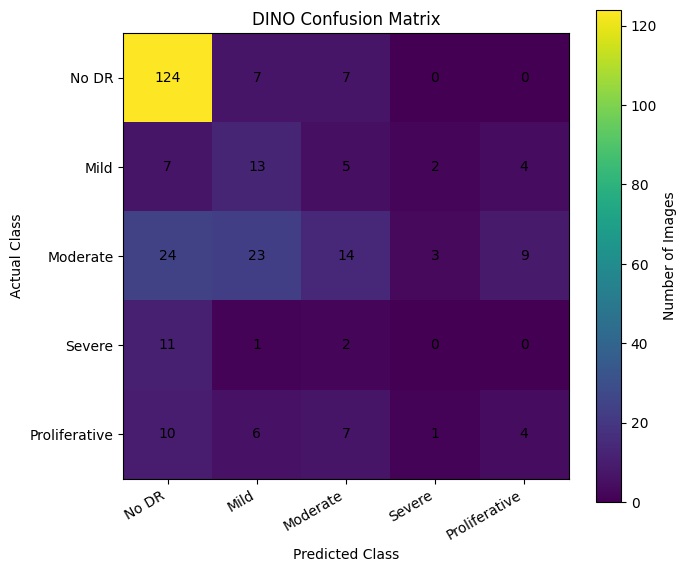

✅ Saved: /content/drive/MyDrive/EyePACS/dino_confusion_matrix.png


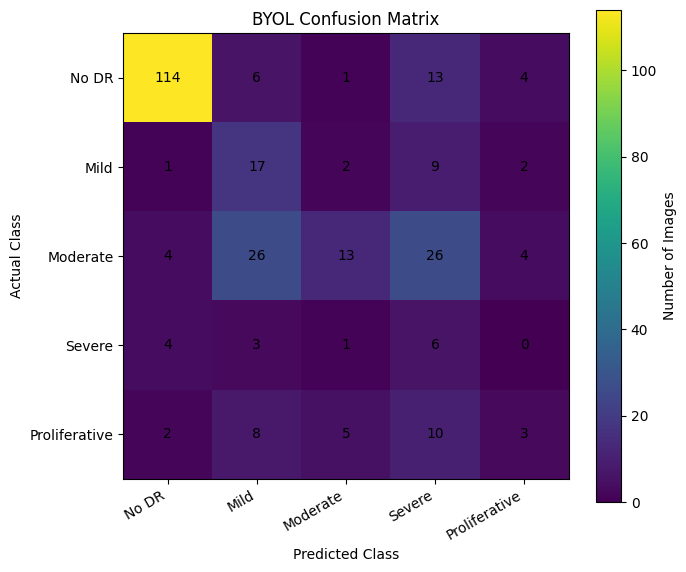

✅ Saved: /content/drive/MyDrive/EyePACS/byol_confusion_matrix.png


In [ ]:
import numpy as np
import matplotlib.pyplot as plt

dino_cm = np.array([
    [124, 7, 7, 0, 0],
    [7, 13, 5, 2, 4],
    [24, 23, 14, 3, 9],
    [11, 1, 2, 0, 0],
    [10, 6, 7, 1, 4]
])

byol_cm = np.array([
    [114, 6, 1, 13, 4],
    [1, 17, 2, 9, 2],
    [4, 26, 13, 26, 4],
    [4, 3, 1, 6, 0],
    [2, 8, 5, 10, 3]
])

classes = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative"
]

def plot_cm(cm, title, filename):
    fig, ax = plt.subplots(figsize=(7, 6))
    im = ax.imshow(cm)

    ax.set_title(title)
    ax.set_xlabel("Predicted Class")
    ax.set_ylabel("Actual Class")

    ax.set_xticks(range(5))
    ax.set_yticks(range(5))
    ax.set_xticklabels(classes, rotation=30, ha="right")
    ax.set_yticklabels(classes)

    for i in range(5):
        for j in range(5):
            ax.text(j, i, cm[i, j],
                    ha="center", va="center")

    plt.colorbar(im, ax=ax, label="Number of Images")
    plt.tight_layout()

    save_path = f"/content/drive/MyDrive/EyePACS/{filename}"
    plt.savefig(save_path, dpi=300, bbox_inches="tight")
    plt.show()

    print("✅ Saved:", save_path)

plot_cm(
    dino_cm,
    "DINO Confusion Matrix",
    "dino_confusion_matrix.png"
)

plot_cm(
    byol_cm,
    "BYOL Confusion Matrix",
    "byol_confusion_matrix.png"
)

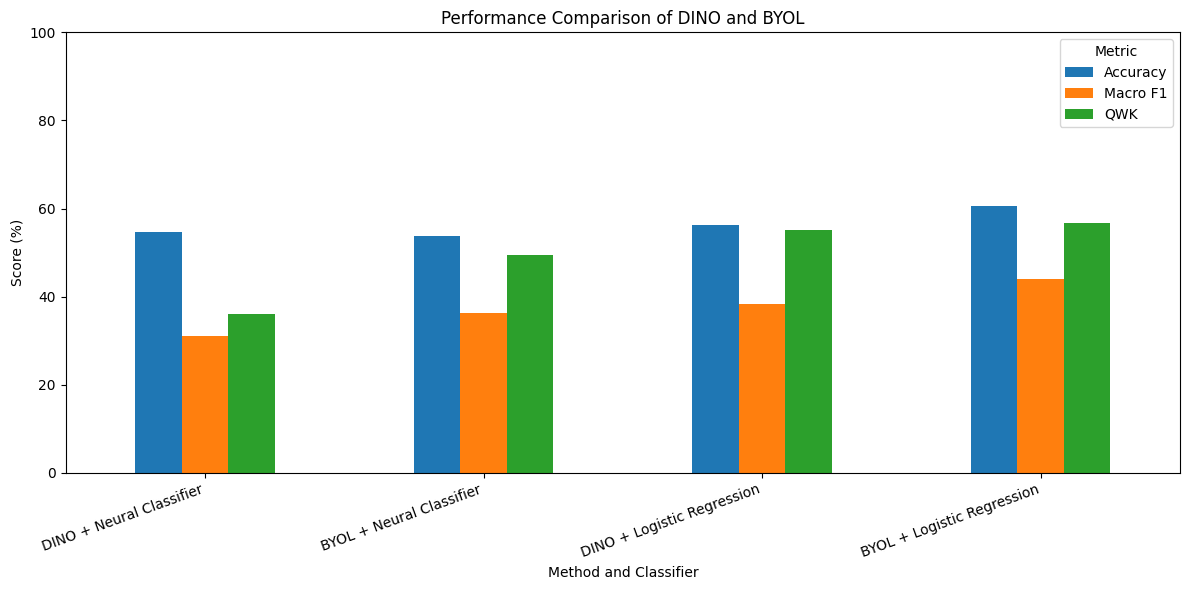

✅ Saved: /content/drive/MyDrive/EyePACS/final_performance_comparison.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.read_csv(
    "/content/drive/MyDrive/EyePACS/final_master_results.csv"
)

plot_data = results.copy()

plot_data["Accuracy"] *= 100
plot_data["Macro F1"] *= 100
plot_data["QWK"] *= 100

ax = plot_data.set_index("Method")[
    ["Accuracy", "Macro F1", "QWK"]
].plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Performance Comparison of DINO and BYOL")
plt.xlabel("Method and Classifier")
plt.ylabel("Score (%)")
plt.xticks(rotation=20, ha="right")
plt.ylim(0, 100)
plt.legend(title="Metric")
plt.tight_layout()

save_path = "/content/drive/MyDrive/EyePACS/final_performance_comparison.png"
plt.savefig(save_path, dpi=300, bbox_inches="tight")

plt.show()

print("✅ Saved:", save_path)

In [ ]:
import os

print("EyePACS in Drive:")
print(os.listdir("/content/drive/MyDrive/EyePACS"))

print("\nDataset exists in Drive?")
print(os.path.exists("/content/drive/MyDrive/EyePACS/dataset"))

EyePACS in Drive:
['diabetic-retinopathy-screening.zip', 'dataset', 'checkpoints', 'features', 'results_dino_vs_byol.csv', 'dino_confusion_matrix.png', 'byol_confusion_matrix.png', 'final_master_results.csv', 'final_performance_comparison.png']

Dataset exists in Drive?
True


In [ ]:
import os
import shutil

DRIVE_DATASET = "/content/drive/MyDrive/EyePACS/dataset"
LOCAL_DATASET = "/content/dataset"

if not os.path.exists(LOCAL_DATASET):
    shutil.copytree(DRIVE_DATASET, LOCAL_DATASET)
    print("Dataset copied to /content/dataset")
else:
    print("Dataset already exists")

print("\nDataset folders:")
print(os.listdir(LOCAL_DATASET))

Dataset copied to /content/dataset

Dataset folders:
['train', 'valid', 'README.dataset.txt', 'test', 'README.roboflow.txt']


In [ ]:
import os
import pandas as pd

for split in ["train", "valid", "test"]:
    folder = f"/content/dataset/{split}"
    csv_path = f"{folder}/labels.csv"

    images = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    df = pd.read_csv(csv_path)

    print(f"\n{split.upper()}")
    print("Images:", len(images))
    print("Labels:", len(df))
    print("CSV columns:", df.columns.tolist())
    print("First image:", images[0] if images else "NO IMAGE")


TRAIN
Images: 1986
Labels: 1986
CSV columns: ['filename', 'level']
First image: 4a96c28f3f07_png_jpg.rf.269889751c35126f9d0101de6fd1e1c3.jpg

VALID
Images: 568
Labels: 568
CSV columns: ['filename', 'level']
First image: 946545473380_png_jpg.rf.352f6bdf33cbb1687b92bf9e0e6aabb5.jpg

TEST
Images: 284
Labels: 284
CSV columns: ['filename', 'level']
First image: 624fb7317106_png_jpg.rf.9514e4866f6bcfb2de7f9a9da996c06c.jpg


In [ ]:
import os

test_folder = "/content/dataset/test"

image_files = [
    f for f in os.listdir(test_folder)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]

image_path = os.path.join(test_folder, image_files[0])

print("Test image:", image_path)

Test image: /content/dataset/test/624fb7317106_png_jpg.rf.9514e4866f6bcfb2de7f9a9da996c06c.jpg


In [ ]:
import torch
import torch.nn as nn
import timm
from PIL import Image
from torchvision import transforms

# ==============================
# 1. DEVICE
# ==============================
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ==============================
# 2. IMAGE PATH
# ==============================
image_path = "/content/dataset/test/624fb7317106_png_jpg.rf.9514e4866f6bcfb2de7f9a9da996c06c.jpg"

img = Image.open(image_path).convert("RGB")

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

x = transform(img).unsqueeze(0).to(device)

# ==============================
# 3. LOAD BYOL BACKBONE
# ==============================
backbone = timm.create_model(
    "resnet18",
    pretrained=False,
    num_classes=0
).to(device)

checkpoint_path = "/content/drive/MyDrive/EyePACS/checkpoints/byol_epoch_5.pth"

checkpoint = torch.load(
    checkpoint_path,
    map_location=device
)

# Find backbone weights
if "online_encoder" in checkpoint:
    state_dict = checkpoint["online_encoder"]
elif "online_network" in checkpoint:
    state_dict = checkpoint["online_network"]
else:
    state_dict = checkpoint

# Remove possible prefixes
new_state_dict = {}

for k, v in state_dict.items():
    k = k.replace("module.", "")
    k = k.replace("backbone.", "")
    new_state_dict[k] = v

try:
    backbone.load_state_dict(new_state_dict, strict=False)
    print("BYOL backbone loaded")
except Exception as e:
    print("Checkpoint loading issue:", e)

backbone.eval()

# ==============================
# 4. EXTRACT FEATURE
# ==============================
with torch.no_grad():
    feature = backbone(x)

print("Feature shape:", feature.shape)

# ==============================
# 5. LOAD CLASSIFIER
# ==============================
classifier = nn.Linear(512, 5).to(device)

classifier_path = "/content/drive/MyDrive/EyePACS/features/byol_classifier.pth"

classifier.load_state_dict(
    torch.load(classifier_path, map_location=device)
)

classifier.eval()

# ==============================
# 6. PREDICTION
# ==============================
with torch.no_grad():
    output = classifier(feature)
    probabilities = torch.softmax(output, dim=1)

predicted_grade = torch.argmax(probabilities, dim=1).item()
confidence = probabilities[0, predicted_grade].item() * 100

classes = {
    0: "No DR",
    1: "Mild DR",
    2: "Moderate DR",
    3: "Severe DR",
    4: "Proliferative DR"
}

# ==============================
# 7. RESULT
# ==============================
print("\n==============================")
print("       BYOL PREDICTION")
print("==============================")
print("Image:", image_path.split("/")[-1])
print("Predicted Grade:", predicted_grade)
print("Predicted Class:", classes[predicted_grade])
print(f"Confidence: {confidence:.2f}%")

print("\nClass Probabilities:")

for i in range(5):
    print(
        f"{i} - {classes[i]}: "
        f"{probabilities[0, i].item()*100:.2f}%"
    )

Device: cuda
BYOL backbone loaded
Feature shape: torch.Size([1, 512])

       BYOL PREDICTION
Image: 624fb7317106_png_jpg.rf.9514e4866f6bcfb2de7f9a9da996c06c.jpg
Predicted Grade: 1
Predicted Class: Mild DR
Confidence: 21.75%

Class Probabilities:
0 - No DR: 15.27%
1 - Mild DR: 21.75%
2 - Moderate DR: 21.50%
3 - Severe DR: 20.06%
4 - Proliferative DR: 21.42%


In [ ]:
import pandas as pd
import os

csv_path = "/content/dataset/test/labels.csv"
df_test = pd.read_csv(csv_path)

filename = os.path.basename(image_path)

actual_row = df_test[df_test["filename"] == filename]

print("Image:", filename)
print("Actual Grade:", actual_row["level"].iloc[0])
print("Predicted Grade:", predicted_grade)

if actual_row["level"].iloc[0] == predicted_grade:
    print("RESULT: CORRECT")
else:
    print("RESULT: INCORRECT")

Image: 624fb7317106_png_jpg.rf.9514e4866f6bcfb2de7f9a9da996c06c.jpg
Actual Grade: 2
Predicted Grade: 1
RESULT: INCORRECT


In [ ]:
import os

base = "/content/drive/MyDrive/EyePACS"

files = [
    "final_master_results.csv",
    "final_performance_comparison.png",
    "dino_confusion_matrix.png",
    "byol_confusion_matrix.png",
]

for f in files:
    path = os.path.join(base, f)
    print(f, "->", "EXISTS ✅" if os.path.exists(path) else "MISSING ❌")

final_master_results.csv -> EXISTS ✅
final_performance_comparison.png -> EXISTS ✅
dino_confusion_matrix.png -> EXISTS ✅
byol_confusion_matrix.png -> EXISTS ✅


In [ ]:
import pandas as pd

path = "/content/drive/MyDrive/EyePACS/final_master_results.csv"

results = pd.read_csv(path)
display(results)

,Method,Accuracy,Macro F1,QWK
0,DINO + Neural Classifier,0.5458,0.3096,0.3600
1,BYOL + Neural Classifier,0.5387,0.3629,0.4940
2,DINO + Logistic Regression,0.5634,0.3842,0.5505
3,BYOL + Logistic Regression,0.6056,0.4393,0.5663


,Method,Accuracy,Macro F1,QWK,Accuracy (%),Macro F1 (%)
0,DINO + Neural Classifier,0.5458,0.3096,0.3600,54.58,30.96
1,BYOL + Neural Classifier,0.5387,0.3629,0.4940,53.87,36.29
2,DINO + Logistic Regression,0.5634,0.3842,0.5505,56.34,38.42
3,BYOL + Logistic Regression,0.6056,0.4393,0.5663,60.56,43.93


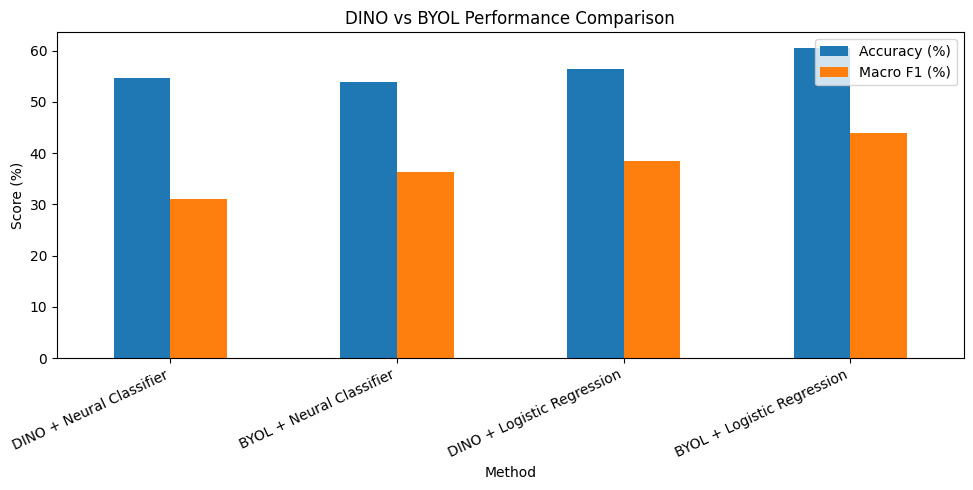

Step 13 completed ✅


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.read_csv(
    "/content/drive/MyDrive/EyePACS/final_master_results.csv"
)

results["Accuracy (%)"] = results["Accuracy"] * 100
results["Macro F1 (%)"] = results["Macro F1"] * 100

display(results)

# Save clean report table
results.to_csv(
    "/content/drive/MyDrive/EyePACS/report_results_table.csv",
    index=False
)

# Plot
ax = results.set_index("Method")[["Accuracy (%)", "Macro F1 (%)"]].plot(
    kind="bar",
    figsize=(10, 5)
)

plt.ylabel("Score (%)")
plt.title("DINO vs BYOL Performance Comparison")
plt.xticks(rotation=25, ha="right")
plt.tight_layout()

plt.savefig(
    "/content/drive/MyDrive/EyePACS/report_performance_graph.png",
    dpi=300
)

plt.show()

print("Step 13 completed ✅")

In [ ]:
import os

base = "/content/drive/MyDrive/EyePACS"

folders = ["checkpoints", "features"]

for folder in folders:
    path = os.path.join(base, folder)
    print(f"\n{folder.upper()}:")
    for f in os.listdir(path):
        print("✅", f)

print("\nPROJECT FILES:")
for f in os.listdir(base):
    if os.path.isfile(os.path.join(base, f)):
        print("✅", f)


CHECKPOINTS:
✅ dino_epoch_1.pth
✅ dino_epoch_2.pth
✅ dino_epoch_3.pth
✅ dino_epoch_4.pth
✅ dino_epoch_5.pth
✅ byol_epoch_1.pth
✅ byol_epoch_2.pth
✅ byol_epoch_3.pth
✅ byol_epoch_4.pth
✅ byol_epoch_5.pth

FEATURES:
✅ train_dino_features.pt
✅ valid_dino_features.pt
✅ test_dino_features.pt
✅ dino_classifier.pth
✅ train_byol_features.pt
✅ valid_byol_features.pt
✅ test_byol_features.pt
✅ byol_classifier.pth

PROJECT FILES:
✅ diabetic-retinopathy-screening.zip
✅ results_dino_vs_byol.csv
✅ dino_confusion_matrix.png
✅ byol_confusion_matrix.png
✅ final_master_results.csv
✅ final_performance_comparison.png
✅ report_results_table.csv
✅ report_performance_graph.png


In [ ]:
import pandas as pd

path = "/content/drive/MyDrive/EyePACS/final_master_results.csv"

df = pd.read_csv(path)
display(df)

,Method,Accuracy,Macro F1,QWK
0,DINO + Neural Classifier,0.5458,0.3096,0.3600
1,BYOL + Neural Classifier,0.5387,0.3629,0.4940
2,DINO + Logistic Regression,0.5634,0.3842,0.5505
3,BYOL + Logistic Regression,0.6056,0.4393,0.5663


In [ ]:
import torch
import os

CHECKPOINT_DIR = "/content/drive/MyDrive/EyePACS/checkpoints"

# Load epoch 5
checkpoint = torch.load(
    os.path.join(CHECKPOINT_DIR, "dino_epoch_5.pth"),
    map_location=device
)

print("Checkpoint keys:", checkpoint.keys())

Checkpoint keys: dict_keys(['epoch', 'student', 'teacher', 'optimizer', 'loss'])


In [ ]:
# Check GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

if device.type == "cpu":
    print("WARNING: CPU detected. GPU is strongly recommended.")

Using: cuda


In [ ]:
import torch
import timm
import os

CHECKPOINT_DIR = "/content/drive/MyDrive/EyePACS/checkpoints"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

# Create the SAME wrapped structure used during training
student = torch.nn.Sequential(
    timm.create_model(
        "vit_small_patch16_224",
        pretrained=False,
        num_classes=0,
        dynamic_img_size=True
    )
).to(device)

teacher = torch.nn.Sequential(
    timm.create_model(
        "vit_small_patch16_224",
        pretrained=False,
        num_classes=0,
        dynamic_img_size=True
    )
).to(device)

# Load epoch 5 checkpoint
ckpt = torch.load(
    os.path.join(CHECKPOINT_DIR, "dino_epoch_5.pth"),
    map_location=device
)

# Load models
student.load_state_dict(ckpt["student"])
teacher.load_state_dict(ckpt["teacher"])

# Create optimizer
optimizer = torch.optim.AdamW(
    student.parameters(),
    lr=1e-4
)

# Load optimizer state
optimizer.load_state_dict(ckpt["optimizer"])

start_epoch = ckpt["epoch"]

print("✅ DINO checkpoint loaded successfully")
print("Starting from epoch:", start_epoch)
print("Previous loss:", ckpt["loss"])

Using: cuda


RuntimeError: Error(s) in loading state_dict for Sequential:
	Unexpected key(s) in state_dict: "1.net.0.weight", "1.net.0.bias", "1.net.2.weight", "1.net.2.bias", "1.net.4.weight", "1.net.4.bias", "1.net.6.weight", "1.net.6.bias". 

In [ ]:
import torch

ckpt = torch.load(
    "/content/drive/MyDrive/EyePACS/checkpoints/dino_epoch_5.pth",
    map_location="cpu"
)

print("Student keys:")
for k in list(ckpt["student"].keys())[:30]:
    print(k)

print("\nTeacher keys:")
for k in list(ckpt["teacher"].keys())[:30]:
    print(k)

Student keys:
0.cls_token
0.pos_embed
0.patch_embed.proj.weight
0.patch_embed.proj.bias
0.blocks.0.norm1.weight
0.blocks.0.norm1.bias
0.blocks.0.attn.qkv.weight
0.blocks.0.attn.qkv.bias
0.blocks.0.attn.proj.weight
0.blocks.0.attn.proj.bias
0.blocks.0.norm2.weight
0.blocks.0.norm2.bias
0.blocks.0.mlp.fc1.weight
0.blocks.0.mlp.fc1.bias
0.blocks.0.mlp.fc2.weight
0.blocks.0.mlp.fc2.bias
0.blocks.1.norm1.weight
0.blocks.1.norm1.bias
0.blocks.1.attn.qkv.weight
0.blocks.1.attn.qkv.bias
0.blocks.1.attn.proj.weight
0.blocks.1.attn.proj.bias
0.blocks.1.norm2.weight
0.blocks.1.norm2.bias
0.blocks.1.mlp.fc1.weight
0.blocks.1.mlp.fc1.bias
0.blocks.1.mlp.fc2.weight
0.blocks.1.mlp.fc2.bias
0.blocks.2.norm1.weight
0.blocks.2.norm1.bias

Teacher keys:
0.cls_token
0.pos_embed
0.patch_embed.proj.weight
0.patch_embed.proj.bias
0.blocks.0.norm1.weight
0.blocks.0.norm1.bias
0.blocks.0.attn.qkv.weight
0.blocks.0.attn.qkv.bias
0.blocks.0.attn.proj.weight
0.blocks.0.attn.proj.bias
0.blocks.0.norm2.weight
0.blo

In [ ]:
print("Student keys containing '1.':")
for k in ckpt["student"].keys():
    if k.startswith("1."):
        print(k, ckpt["student"][k].shape)

Student keys containing '1.':
1.net.0.weight torch.Size([2048, 384])
1.net.0.bias torch.Size([2048])
1.net.2.weight torch.Size([2048, 2048])
1.net.2.bias torch.Size([2048])
1.net.4.weight torch.Size([256, 2048])
1.net.4.bias torch.Size([256])
1.net.6.weight torch.Size([2048, 256])
1.net.6.bias torch.Size([2048])


In [ ]:
import torch
import torch.nn as nn
import timm
import os

CHECKPOINT_DIR = "/content/drive/MyDrive/EyePACS/checkpoints"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Exact projection head structure
class ProjectionHead(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(384, 2048),
            nn.GELU(),
            nn.Linear(2048, 2048),
            nn.GELU(),
            nn.Linear(2048, 256),
            nn.GELU(),
            nn.Linear(256, 2048)
        )

    def forward(self, x):
        return self.net(x)

# Student
student = nn.Sequential(
    timm.create_model(
        "vit_small_patch16_224",
        pretrained=False,
        num_classes=0,
        dynamic_img_size=True
    ),
    ProjectionHead()
).to(device)

# Teacher
teacher = nn.Sequential(
    timm.create_model(
        "vit_small_patch16_224",
        pretrained=False,
        num_classes=0,
        dynamic_img_size=True
    ),
    ProjectionHead()
).to(device)

# Load checkpoint
ckpt = torch.load(
    os.path.join(CHECKPOINT_DIR, "dino_epoch_5.pth"),
    map_location=device
)

student.load_state_dict(ckpt["student"])
teacher.load_state_dict(ckpt["teacher"])

# Optimizer
optimizer = torch.optim.AdamW(
    student.parameters(),
    lr=1e-4
)
optimizer.load_state_dict(ckpt["optimizer"])

print("✅ DINO epoch 5 loaded successfully")
print("Starting epoch:", ckpt["epoch"])
print("Previous loss:", ckpt["loss"])

✅ DINO epoch 5 loaded successfully
Starting epoch: 5
Previous loss: 0.003686044851483236


In [ ]:
from pathlib import Path
import pandas as pd
from torch.utils.data import Dataset, DataLoader
from PIL import Image

LOCAL = Path("/content/dataset")
TRAIN_DIR = LOCAL / "train"

df = pd.read_csv(TRAIN_DIR / "labels.csv")

class SSLImages(Dataset):
    def __init__(self, img_dir, df):
        self.img_dir = img_dir
        self.files = df["filename"].tolist()

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        img = Image.open(
            self.img_dir / self.files[idx]
        ).convert("RGB")

        return [
            global_crop(img),
            global_crop(img),
            local_crop(img),
            local_crop(img),
            local_crop(img),
            local_crop(img)
        ]

dataset = SSLImages(TRAIN_DIR, df)

loader = DataLoader(
    dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True
)

print("✅ Loader recreated")
print("Images:", len(dataset))
print("Batches:", len(loader))

✅ Loader recreated
Images: 1986
Batches: 124


In [ ]:
# ===== RECREATE DINO AUGMENTATIONS + LOADER =====

from pathlib import Path
import pandas as pd
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

LOCAL = Path("/content/dataset")
TRAIN_DIR = LOCAL / "train"

df = pd.read_csv(TRAIN_DIR / "labels.csv")

# Normalization
normalize = transforms.Normalize(
    [0.485, 0.456, 0.406],
    [0.229, 0.224, 0.225]
)

# Global crops
global_crop = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.5, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.2, 0.2, 0.1, 0.02),
    transforms.ToTensor(),
    normalize
])

# Local crops
local_crop = transforms.Compose([
    transforms.RandomResizedCrop(96, scale=(0.2, 0.6)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.2, 0.2, 0.1, 0.02),
    transforms.ToTensor(),
    normalize
])

class SSLImages(Dataset):
    def __init__(self, img_dir, df):
        self.img_dir = img_dir
        self.files = df["filename"].tolist()

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):
        img = Image.open(
            self.img_dir / self.files[idx]
        ).convert("RGB")

        return [
            global_crop(img),
            global_crop(img),
            local_crop(img),
            local_crop(img),
            local_crop(img),
            local_crop(img)
        ]

dataset = SSLImages(TRAIN_DIR, df)

loader = DataLoader(
    dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True
)

print("✅ DINO loader ready")
print("Images:", len(dataset))
print("Batches:", len(loader))

# Test one batch
views = next(iter(loader))

print("✅ Batch test successful")
print("Number of views:", len(views))
print("Global crop:", views[0].shape)
print("Local crop:", views[2].shape)

✅ DINO loader ready
Images: 1986
Batches: 124
✅ Batch test successful
Number of views: 6
Global crop: torch.Size([16, 3, 224, 224])
Local crop: torch.Size([16, 3, 96, 96])


In [ ]:
# ============================================================
# DINO: RESUME FROM EPOCH 5 → TRAIN EPOCH 6–10
# ============================================================

import os
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm

CHECKPOINT_DIR = "/content/drive/MyDrive/EyePACS/checkpoints"

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Using:", device)

# ---------- DINO HEAD ----------
class DINOHead(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(384, 2048),
            nn.GELU(),
            nn.Linear(2048, 2048),
            nn.GELU(),
            nn.Linear(2048, 256),
            nn.GELU(),
            nn.Linear(256, 2048)
        )

    def forward(self, x):
        return F.normalize(self.net(x), dim=-1)

# ---------- MODEL ----------
def make_model():
    vit = timm.create_model(
        "vit_small_patch16_224",
        pretrained=False,
        num_classes=0,
        dynamic_img_size=True
    )
    return nn.Sequential(vit, DINOHead())

student = make_model().to(device)
teacher = make_model().to(device)

# ---------- LOAD EPOCH 5 ----------
ckpt = torch.load(
    os.path.join(CHECKPOINT_DIR, "dino_epoch_5.pth"),
    map_location=device
)

student.load_state_dict(ckpt["student"])
teacher.load_state_dict(ckpt["teacher"])

for p in teacher.parameters():
    p.requires_grad = False

# ---------- OPTIMIZER ----------
optimizer = torch.optim.AdamW(
    student.parameters(),
    lr=1e-4,
    weight_decay=0.04
)

optimizer.load_state_dict(ckpt["optimizer"])

# ---------- DINO CENTER ----------
center = torch.zeros(
    1, 2048,
    device=device
)

# ---------- LOSS ----------
def dino_loss(student_out, teacher_out):

    global center

    teacher_cat = torch.cat(teacher_out)

    teacher_prob = F.softmax(
        (teacher_cat.detach() - center) / 0.04,
        dim=-1
    )

    teacher_chunks = teacher_prob.chunk(2)

    loss = 0
    count = 0

    for s in student_out:

        q = F.log_softmax(
            s / 0.1,
            dim=-1
        )

        for t in teacher_chunks:

            loss += (-t * q).mean()
            count += 1

    loss = loss / count

    with torch.no_grad():

        center = (
            0.9 * center
            + 0.1 * teacher_cat.mean(
                0,
                keepdim=True
            )
        )

    return loss

# ---------- TRAIN ----------
MOM = 0.996

print("\n===== DINO EPOCH 6 → 10 =====")

for epoch in range(6, 11):

    student.train()

    total_loss = 0

    for step, views in enumerate(loader):

        views = [
            x.to(device, non_blocking=True)
            for x in views
        ]

        # Teacher: 2 global crops
        with torch.no_grad():

            teacher_out = [
                teacher(views[0]),
                teacher(views[1])
            ]

        # Student: all 6 crops
        student_out = [
            student(x)
            for x in views
        ]

        loss = dino_loss(
            student_out,
            teacher_out
        )

        optimizer.zero_grad(set_to_none=True)

        loss.backward()

        optimizer.step()

        # EMA teacher
        with torch.no_grad():

            for tp, sp in zip(
                teacher.parameters(),
                student.parameters()
            ):

                tp.data.mul_(MOM).add_(
                    sp.data,
                    alpha=1 - MOM
                )

        total_loss += loss.item()

        if (step + 1) % 20 == 0:

            print(
                f"Epoch {epoch}/10 | "
                f"Step {step+1}/{len(loader)} | "
                f"Loss {loss.item():.4f}"
            )

    avg_loss = total_loss / len(loader)

    save_path = (
        f"{CHECKPOINT_DIR}/dino_epoch_{epoch}.pth"
    )

    torch.save(
        {
            "epoch": epoch,
            "student": student.state_dict(),
            "teacher": teacher.state_dict(),
            "optimizer": optimizer.state_dict(),
            "loss": avg_loss
        },
        save_path
    )

    print(
        f"✅ Epoch {epoch} DONE | "
        f"Average Loss: {avg_loss:.4f}"
    )

    print("Saved:", save_path)

print("\n===== DINO 6–10 COMPLETE =====")

Using: cuda

===== DINO EPOCH 6 → 10 =====
Epoch 6/10 | Step 20/124 | Loss 0.0037
Epoch 6/10 | Step 40/124 | Loss 0.0037
Epoch 6/10 | Step 60/124 | Loss 0.0037
Epoch 6/10 | Step 80/124 | Loss 0.0037
Epoch 6/10 | Step 100/124 | Loss 0.0037
Epoch 6/10 | Step 120/124 | Loss 0.0037
✅ Epoch 6 DONE | Average Loss: 0.0037
Saved: /content/drive/MyDrive/EyePACS/checkpoints/dino_epoch_6.pth
Epoch 7/10 | Step 20/124 | Loss 0.0037
Epoch 7/10 | Step 40/124 | Loss 0.0037
Epoch 7/10 | Step 60/124 | Loss 0.0037
Epoch 7/10 | Step 80/124 | Loss 0.0037
Epoch 7/10 | Step 100/124 | Loss 0.0037
Epoch 7/10 | Step 120/124 | Loss 0.0037
✅ Epoch 7 DONE | Average Loss: 0.0037
Saved: /content/drive/MyDrive/EyePACS/checkpoints/dino_epoch_7.pth
Epoch 8/10 | Step 20/124 | Loss 0.0037
Epoch 8/10 | Step 40/124 | Loss 0.0037
Epoch 8/10 | Step 60/124 | Loss 0.0037
Epoch 8/10 | Step 80/124 | Loss 0.0037
Epoch 8/10 | Step 100/124 | Loss 0.0037
Epoch 8/10 | Step 120/124 | Loss 0.0036
✅ Epoch 8 DONE | Average Loss: 0.0037
S

In [ ]:
# Check epoch-10 checkpoint exists

import os

path = "/content/drive/MyDrive/EyePACS/checkpoints/dino_epoch_10.pth"

print("Exists:", os.path.exists(path))

if os.path.exists(path):
    print("✅ DINO epoch 10 checkpoint ready")

Exists: True
✅ DINO epoch 10 checkpoint ready


In [ ]:
# ================= RECREATE BYOL LOADER =================

from pathlib import Path
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

DATASET_DIR = Path("/content/dataset")

byol_aug = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.6, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.RandomApply(
        [transforms.ColorJitter(0.2, 0.2, 0.1, 0.02)],
        p=0.8
    ),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

class BYOLDataset(Dataset):
    def __init__(self):
        self.dir = DATASET_DIR / "train"
        self.df = pd.read_csv(self.dir / "labels.csv")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, i):
        img = Image.open(
            self.dir / self.df.iloc[i]["filename"]
        ).convert("RGB")

        return byol_aug(img), byol_aug(img)

byol_ds = BYOLDataset()

byol_loader = DataLoader(
    byol_ds,
    batch_size=16,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True
)

# Test
v1, v2 = next(iter(byol_loader))

print("✅ BYOL loader ready")
print("Images:", len(byol_ds))
print("Batches:", len(byol_loader))
print("View 1:", v1.shape)
print("View 2:", v2.shape)

✅ BYOL loader ready
Images: 1986
Batches: 124
View 1: torch.Size([16, 3, 224, 224])
View 2: torch.Size([16, 3, 224, 224])


In [ ]:
# ================= BYOL EPOCH 6 → 10 =================

print("===== BYOL EPOCH 6 → 10 =====")

for epoch in range(6, 11):

    online.train()
    projector.train()
    predictor.train()

    total = 0

    for v1, v2 in tqdm(
        byol_loader,
        desc=f"Epoch {epoch}/10"
    ):

        v1 = v1.to(device, non_blocking=True)
        v2 = v2.to(device, non_blocking=True)

        z1 = projector(online(v1))
        z2 = projector(online(v2))

        with torch.no_grad():
            t1 = projector(target(v1))
            t2 = projector(target(v2))

        loss = (
            byol_loss(predictor(z1), t2) +
            byol_loss(predictor(z2), t1)
        ) / 2

        optimizer.zero_grad(set_to_none=True)
        loss.backward()
        optimizer.step()

        # EMA target update
        with torch.no_grad():
            for po, pt in zip(
                online.parameters(),
                target.parameters()
            ):
                pt.data.mul_(0.996).add_(
                    po.data,
                    alpha=0.004
                )

        total += loss.item()

    avg = total / len(byol_loader)

    save_path = CKPT_DIR / f"byol_epoch_{epoch}.pth"

    torch.save({
        "online": online.state_dict(),
        "target": target.state_dict(),
        "projector": projector.state_dict(),
        "predictor": predictor.state_dict()
    }, save_path)

    print(f"✅ Epoch {epoch} | Loss: {avg:.4f}")
    print("Saved:", save_path)

print("===== BYOL 6–10 COMPLETE =====")

===== BYOL EPOCH 6 → 10 =====


Epoch 6/10:   0%|          | 0/124 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f14bf04b060>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process


✅ Epoch 6 | Loss: 0.2318
Saved: /content/drive/MyDrive/EyePACS/checkpoints/byol_epoch_6.pth


Epoch 7/10:   0%|          | 0/124 [00:00<?, ?it/s]

...

Epoch 9/10:   0%|          | 0/124 [00:00<?, ?it/s]

Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f14bf04b060>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/python3.13/multiprocessing/process.py", line 160, in is_alive
    assert self._parent_pid == os.getpid(), 'can only test a child process'
AssertionError: can only test a child process
Exception ignored in: <function _MultiProcessingDataLoaderIter.__del__ at 0x7f14bf04b060>
Traceback (most recent call last):
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1709, in __del__
    self._shutdown_workers()
  File "/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py", line 1692, in _shutdown_workers
    if w.is_alive():
  File "/usr/lib/

✅ Epoch 9 | Loss: 0.2045
Saved: /content/drive/MyDrive/EyePACS/checkpoints/byol_epoch_9.pth


Epoch 10/10:   0%|          | 0/124 [00:00<?, ?it/s]

✅ Epoch 10 | Loss: 0.1928
Saved: /content/drive/MyDrive/EyePACS/checkpoints/byol_epoch_10.pth
===== BYOL 6–10 COMPLETE =====


In [ ]:
import os

for name in [
    "dino_epoch_10.pth",
    "byol_epoch_10.pth"
]:
    path = f"/content/drive/MyDrive/EyePACS/checkpoints/{name}"
    print(name, "->", "✅ EXISTS" if os.path.exists(path) else "❌ MISSING")

dino_epoch_10.pth -> ✅ EXISTS
byol_epoch_10.pth -> ✅ EXISTS


In [ ]:
# ============================================================
# DINO EPOCH-10 FEATURE EXTRACTION
# ============================================================

import torch
import timm
import pandas as pd
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import os

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CKPT_DIR = Path("/content/drive/MyDrive/EyePACS/checkpoints")
FEATURE_DIR = Path("/content/drive/MyDrive/EyePACS/features")
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

# ---------- DINO MODEL ----------
class DINOHead(torch.nn.Module):
    def __init__(self):
        super().__init__()
        self.net = torch.nn.Sequential(
            torch.nn.Linear(384, 2048),
            torch.nn.GELU(),
            torch.nn.Linear(2048, 2048),
            torch.nn.GELU(),
            torch.nn.Linear(2048, 256),
            torch.nn.GELU(),
            torch.nn.Linear(256, 2048)
        )

    def forward(self, x):
        return torch.nn.functional.normalize(
            self.net(x), dim=-1
        )

def make_model():
    vit = timm.create_model(
        "vit_small_patch16_224",
        pretrained=False,
        num_classes=0,
        dynamic_img_size=True
    )
    return torch.nn.Sequential(vit, DINOHead())

model = make_model().to(device)

ckpt = torch.load(
    CKPT_DIR / "dino_epoch_10.pth",
    map_location=device
)

model.load_state_dict(ckpt["student"])
model.eval()

# ---------- TRANSFORM ----------
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

# ---------- DATASET ----------
class FeatureDataset(Dataset):
    def __init__(self, folder):
        self.folder = Path(folder)
        self.df = pd.read_csv(self.folder / "labels.csv")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(
            self.folder / row["filename"]
        ).convert("RGB")

        return transform(img), int(row["level"])

# ---------- EXTRACT ----------
def extract_features(folder, save_name):

    ds = FeatureDataset(folder)

    dl = DataLoader(
        ds,
        batch_size=32,
        shuffle=False,
        num_workers=2
    )

    features = []
    labels = []

    with torch.no_grad():

        for images, y in dl:

            images = images.to(device)

            # Only ViT backbone features
            f = model[0](images)

            features.append(f.cpu())
            labels.append(y)

    features = torch.cat(features)
    labels = torch.cat(labels)

    torch.save(
        {
            "features": features,
            "labels": labels
        },
        FEATURE_DIR / save_name
    )

    print(
        f"✅ {save_name}: "
        f"features={features.shape}, "
        f"labels={labels.shape}"
    )

# ---------- RUN ----------
DATASET_DIR = Path("/content/dataset")

extract_features(
    DATASET_DIR / "train",
    "train_dino_epoch10_features.pt"
)

extract_features(
    DATASET_DIR / "valid",
    "valid_dino_epoch10_features.pt"
)

extract_features(
    DATASET_DIR / "test",
    "test_dino_epoch10_features.pt"
)

print("\n===== DINO EPOCH-10 FEATURES COMPLETE =====")

✅ train_dino_epoch10_features.pt: features=torch.Size([1986, 384]), labels=torch.Size([1986])
✅ valid_dino_epoch10_features.pt: features=torch.Size([568, 384]), labels=torch.Size([568])
✅ test_dino_epoch10_features.pt: features=torch.Size([284, 384]), labels=torch.Size([284])

===== DINO EPOCH-10 FEATURES COMPLETE =====


In [ ]:
# ============================================================
# BYOL EPOCH-10 FEATURE EXTRACTION
# ============================================================

import torch
import timm
import pandas as pd
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CKPT_DIR = Path("/content/drive/MyDrive/EyePACS/checkpoints")
FEATURE_DIR = Path("/content/drive/MyDrive/EyePACS/features")
FEATURE_DIR.mkdir(parents=True, exist_ok=True)

# ---------- BYOL model ----------
online = timm.create_model(
    "resnet18",
    pretrained=False,
    num_classes=0
).to(device)

ckpt = torch.load(
    CKPT_DIR / "byol_epoch_10.pth",
    map_location=device
)

online.load_state_dict(ckpt["online"])
online.eval()

# ---------- Transform ----------
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

# ---------- Dataset ----------
class FeatureDataset(Dataset):
    def __init__(self, folder):
        self.folder = Path(folder)
        self.df = pd.read_csv(self.folder / "labels.csv")

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]
        img = Image.open(
            self.folder / row["filename"]
        ).convert("RGB")

        return transform(img), int(row["level"])

# ---------- Extract ----------
def extract_features(folder, save_name):
    ds = FeatureDataset(folder)

    dl = DataLoader(
        ds,
        batch_size=32,
        shuffle=False,
        num_workers=2
    )

    features = []
    labels = []

    with torch.no_grad():
        for images, y in dl:
            images = images.to(device)

            f = online(images)

            features.append(f.cpu())
            labels.append(y)

    features = torch.cat(features)
    labels = torch.cat(labels)

    torch.save(
        {
            "features": features,
            "labels": labels
        },
        FEATURE_DIR / save_name
    )

    print(
        f"✅ {save_name}: "
        f"features={features.shape}, "
        f"labels={labels.shape}"
    )

# ---------- Train / Valid / Test ----------
DATASET_DIR = Path("/content/dataset")

extract_features(
    DATASET_DIR / "train",
    "train_byol_epoch10_features.pt"
)

extract_features(
    DATASET_DIR / "valid",
    "valid_byol_epoch10_features.pt"
)

extract_features(
    DATASET_DIR / "test",
    "test_byol_epoch10_features.pt"
)

print("\n===== BYOL EPOCH-10 FEATURES COMPLETE =====")

✅ train_byol_epoch10_features.pt: features=torch.Size([1986, 512]), labels=torch.Size([1986])
✅ valid_byol_epoch10_features.pt: features=torch.Size([568, 512]), labels=torch.Size([568])
✅ test_byol_epoch10_features.pt: features=torch.Size([284, 512]), labels=torch.Size([284])

===== BYOL EPOCH-10 FEATURES COMPLETE =====


In [ ]:
# ============================================================
# DINO EPOCH-10 — DOWNSTREAM CLASSIFICATION
# ============================================================

import torch
import torch.nn as nn
import torch.nn.functional as F
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score
from torch.utils.data import TensorDataset, DataLoader

FEATURE_DIR = "/content/drive/MyDrive/EyePACS/features"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ---------- Load features ----------
def load_features(name):
    data = torch.load(
        f"{FEATURE_DIR}/{name}",
        map_location="cpu"
    )
    return data["features"].float(), data["labels"].long()

X_train, y_train = load_features("train_dino_epoch10_features.pt")
X_valid, y_valid = load_features("valid_dino_epoch10_features.pt")
X_test, y_test = load_features("test_dino_epoch10_features.pt")

print("Train:", X_train.shape)
print("Valid:", X_valid.shape)
print("Test :", X_test.shape)

# ============================================================
# 1. LOGISTIC REGRESSION
# ============================================================

lr = LogisticRegression(
    max_iter=1000,
    class_weight="balanced",
    random_state=42
)

lr.fit(X_train.numpy(), y_train.numpy())

lr_pred = lr.predict(X_test.numpy())

lr_acc = accuracy_score(y_test, lr_pred)
lr_f1 = f1_score(y_test, lr_pred, average="macro")
lr_qwk = cohen_kappa_score(y_test, lr_pred, weights="quadratic")

print("\n===== DINO-10 LOGISTIC REGRESSION =====")
print(f"Accuracy : {lr_acc:.4f}")
print(f"Macro F1 : {lr_f1:.4f}")
print(f"QWK      : {lr_qwk:.4f}")

# ============================================================
# 2. NEURAL CLASSIFIER
# ============================================================

class NeuralClassifier(nn.Module):
    def __init__(self, input_dim, num_classes=5):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.net(x)

model = NeuralClassifier(384).to(device)

train_ds = TensorDataset(X_train, y_train)
valid_ds = TensorDataset(X_valid, y_valid)

train_loader = DataLoader(
    train_ds,
    batch_size=32,
    shuffle=True
)

valid_loader = DataLoader(
    valid_ds,
    batch_size=64,
    shuffle=False
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

criterion = nn.CrossEntropyLoss()

EPOCHS = 30

for epoch in range(EPOCHS):

    model.train()

    for X, y in train_loader:
        X = X.to(device)
        y = y.to(device)

        optimizer.zero_grad()

        output = model(X)
        loss = criterion(output, y)

        loss.backward()
        optimizer.step()

# ---------- Test ----------
model.eval()

predictions = []

with torch.no_grad():
    test_X = X_test.to(device)

    output = model(test_X)
    predictions = output.argmax(dim=1).cpu().numpy()

nn_acc = accuracy_score(y_test.numpy(), predictions)
nn_f1 = f1_score(y_test.numpy(), predictions, average="macro")
nn_qwk = cohen_kappa_score(
    y_test.numpy(),
    predictions,
    weights="quadratic"
)

print("\n===== DINO-10 NEURAL CLASSIFIER =====")
print(f"Accuracy : {nn_acc:.4f}")
print(f"Macro F1 : {nn_f1:.4f}")
print(f"QWK      : {nn_qwk:.4f}")

print("\n===== DINO-10 COMPLETE =====")

Train: torch.Size([1986, 384])
Valid: torch.Size([568, 384])
Test : torch.Size([284, 384])


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(



===== DINO-10 LOGISTIC REGRESSION =====
Accuracy : 0.5775
Macro F1 : 0.3917
QWK      : 0.5523

===== DINO-10 NEURAL CLASSIFIER =====
Accuracy : 0.6373
Macro F1 : 0.3200
QWK      : 0.5183

===== DINO-10 COMPLETE =====


In [ ]:
# ============================================================
# DINO-10 — NEURAL CLASSIFIER
# ============================================================

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

class NeuralClassifier(nn.Module):
    def __init__(self, input_dim, num_classes=5):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.net(x)

model = NeuralClassifier(384).to(device)

train_loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=32,
    shuffle=True
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

criterion = nn.CrossEntropyLoss()

for epoch in range(30):
    model.train()

    for X, y in train_loader:
        X, y = X.to(device), y.to(device)

        optimizer.zero_grad()
        output = model(X)
        loss = criterion(output, y)
        loss.backward()
        optimizer.step()

model.eval()

with torch.no_grad():
    output = model(X_test.to(device))
    predictions = output.argmax(dim=1).cpu().numpy()

nn_acc = accuracy_score(y_test.numpy(), predictions)
nn_f1 = f1_score(y_test.numpy(), predictions, average="macro")
nn_qwk = cohen_kappa_score(
    y_test.numpy(),
    predictions,
    weights="quadratic"
)

print("===== DINO-10 NEURAL CLASSIFIER =====")
print(f"Accuracy : {nn_acc:.4f}")
print(f"Macro F1 : {nn_f1:.4f}")
print(f"QWK      : {nn_qwk:.4f}")

===== DINO-10 NEURAL CLASSIFIER =====
Accuracy : 0.6303
Macro F1 : 0.2839
QWK      : 0.5029


In [ ]:
# ============================================================
# BYOL EPOCH-10 — DOWNSTREAM CLASSIFICATION
# ============================================================

import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

FEATURE_DIR = "/content/drive/MyDrive/EyePACS/features"
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Load BYOL-10 features
def load_features(name):
    data = torch.load(
        f"{FEATURE_DIR}/{name}",
        map_location="cpu"
    )
    return data["features"].float(), data["labels"].long()

X_train, y_train = load_features("train_byol_epoch10_features.pt")
X_valid, y_valid = load_features("valid_byol_epoch10_features.pt")
X_test, y_test = load_features("test_byol_epoch10_features.pt")

print("Train:", X_train.shape)
print("Valid:", X_valid.shape)
print("Test :", X_test.shape)

# ============================================================
# 1. LOGISTIC REGRESSION
# ============================================================

lr = LogisticRegression(
    max_iter=3000,
    class_weight="balanced",
    random_state=42
)

lr.fit(X_train.numpy(), y_train.numpy())

lr_pred = lr.predict(X_test.numpy())

lr_acc = accuracy_score(y_test.numpy(), lr_pred)
lr_f1 = f1_score(y_test.numpy(), lr_pred, average="macro")
lr_qwk = cohen_kappa_score(
    y_test.numpy(),
    lr_pred,
    weights="quadratic"
)

print("\n===== BYOL-10 LOGISTIC REGRESSION =====")
print(f"Accuracy : {lr_acc:.4f}")
print(f"Macro F1 : {lr_f1:.4f}")
print(f"QWK      : {lr_qwk:.4f}")

# ============================================================
# 2. NEURAL CLASSIFIER
# ============================================================

class NeuralClassifier(nn.Module):
    def __init__(self, input_dim, num_classes=5):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(input_dim, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, num_classes)
        )

    def forward(self, x):
        return self.net(x)

model = NeuralClassifier(512).to(device)

train_loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=32,
    shuffle=True
)

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

criterion = nn.CrossEntropyLoss()

for epoch in range(30):
    model.train()

    for X, y in train_loader:
        X, y = X.to(device), y.to(device)

        optimizer.zero_grad()

        output = model(X)
        loss = criterion(output, y)

        loss.backward()
        optimizer.step()

# Test
model.eval()

with torch.no_grad():
    output = model(X_test.to(device))
    predictions = output.argmax(dim=1).cpu().numpy()

nn_acc = accuracy_score(y_test.numpy(), predictions)
nn_f1 = f1_score(y_test.numpy(), predictions, average="macro")
nn_qwk = cohen_kappa_score(
    y_test.numpy(),
    predictions,
    weights="quadratic"
)

print("\n===== BYOL-10 NEURAL CLASSIFIER =====")
print(f"Accuracy : {nn_acc:.4f}")
print(f"Macro F1 : {nn_f1:.4f}")
print(f"QWK      : {nn_qwk:.4f}")

print("\n===== BYOL-10 COMPLETE =====")

Train: torch.Size([1986, 512])
Valid: torch.Size([568, 512])
Test : torch.Size([284, 512])

===== BYOL-10 LOGISTIC REGRESSION =====
Accuracy : 0.6197
Macro F1 : 0.4602
QWK      : 0.5947

===== BYOL-10 NEURAL CLASSIFIER =====
Accuracy : 0.6796
Macro F1 : 0.2990
QWK      : 0.5878

===== BYOL-10 COMPLETE =====


===== DINO-10 CLASSIFICATION REPORT =====
               precision    recall  f1-score   support

        No DR       0.89      0.88      0.89       138
         Mild       0.33      0.48      0.39        31
     Moderate       0.50      0.26      0.34        73
       Severe       0.07      0.21      0.11        14
Proliferative       0.26      0.21      0.24        28

     accuracy                           0.58       284
    macro avg       0.41      0.41      0.39       284
 weighted avg       0.63      0.58      0.59       284



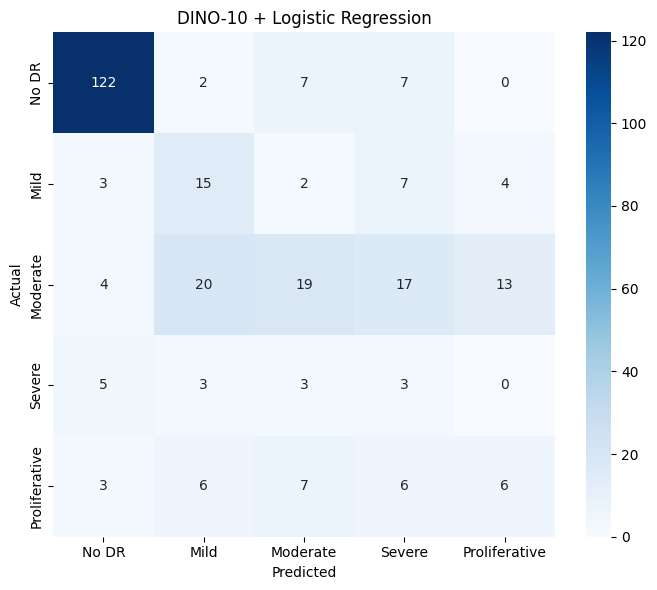


===== BYOL-10 CLASSIFICATION REPORT =====
               precision    recall  f1-score   support

        No DR       0.93      0.89      0.91       138
         Mild       0.41      0.58      0.48        31
     Moderate       0.51      0.27      0.36        73
       Severe       0.24      0.64      0.35        14
Proliferative       0.19      0.21      0.20        28

     accuracy                           0.62       284
    macro avg       0.46      0.52      0.46       284
 weighted avg       0.66      0.62      0.62       284



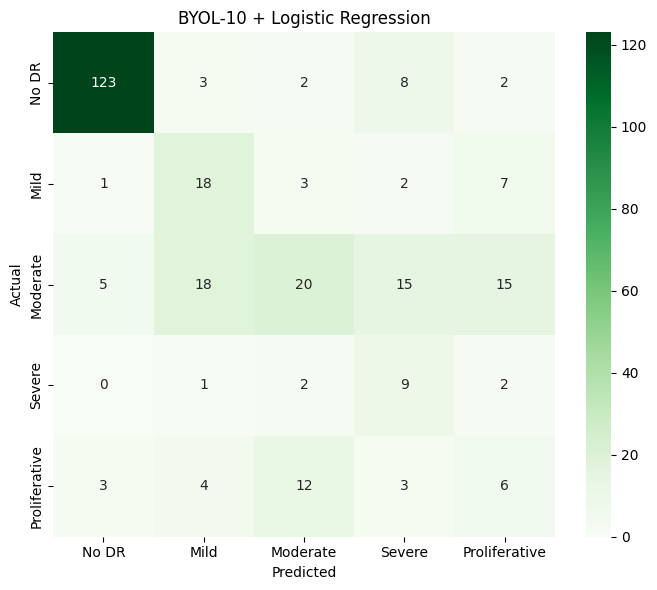


✅ Both confusion matrices saved.


In [ ]:
# ============================================================
# CONFUSION MATRICES — DINO-10 & BYOL-10
# ============================================================

import torch
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, classification_report

FEATURE_DIR = "/content/drive/MyDrive/EyePACS/features"

def load_features(name):
    data = torch.load(
        f"{FEATURE_DIR}/{name}",
        map_location="cpu"
    )
    return data["features"].float(), data["labels"].long()

# ------------------------------------------------------------
# DINO-10
# ------------------------------------------------------------

Xtr, ytr = load_features("train_dino_epoch10_features.pt")
Xte, yte = load_features("test_dino_epoch10_features.pt")

dino_lr = LogisticRegression(
    max_iter=3000,
    class_weight="balanced",
    random_state=42
)

dino_lr.fit(Xtr.numpy(), ytr.numpy())
dino_pred = dino_lr.predict(Xte.numpy())

cm_dino = confusion_matrix(yte.numpy(), dino_pred)

print("===== DINO-10 CLASSIFICATION REPORT =====")
print(classification_report(
    yte.numpy(),
    dino_pred,
    target_names=[
        "No DR",
        "Mild",
        "Moderate",
        "Severe",
        "Proliferative"
    ],
    zero_division=0
))

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm_dino,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["No DR", "Mild", "Moderate", "Severe", "Proliferative"],
    yticklabels=["No DR", "Mild", "Moderate", "Severe", "Proliferative"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("DINO-10 + Logistic Regression")
plt.tight_layout()

dino_path = "/content/drive/MyDrive/EyePACS/dino10_confusion_matrix.png"
plt.savefig(dino_path, dpi=300)
plt.show()

# ------------------------------------------------------------
# BYOL-10
# ------------------------------------------------------------

Xtr, ytr = load_features("train_byol_epoch10_features.pt")
Xte, yte = load_features("test_byol_epoch10_features.pt")

byol_lr = LogisticRegression(
    max_iter=3000,
    class_weight="balanced",
    random_state=42
)

byol_lr.fit(Xtr.numpy(), ytr.numpy())
byol_pred = byol_lr.predict(Xte.numpy())

cm_byol = confusion_matrix(yte.numpy(), byol_pred)

print("\n===== BYOL-10 CLASSIFICATION REPORT =====")
print(classification_report(
    yte.numpy(),
    byol_pred,
    target_names=[
        "No DR",
        "Mild",
        "Moderate",
        "Severe",
        "Proliferative"
    ],
    zero_division=0
))

plt.figure(figsize=(7, 6))
sns.heatmap(
    cm_byol,
    annot=True,
    fmt="d",
    cmap="Greens",
    xticklabels=["No DR", "Mild", "Moderate", "Severe", "Proliferative"],
    yticklabels=["No DR", "Mild", "Moderate", "Severe", "Proliferative"]
)
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("BYOL-10 + Logistic Regression")
plt.tight_layout()

byol_path = "/content/drive/MyDrive/EyePACS/byol10_confusion_matrix.png"
plt.savefig(byol_path, dpi=300)
plt.show()

print("\n✅ Both confusion matrices saved.")

In [ ]:
# ============================================================
# FINAL RESULTS TABLE — DINO vs BYOL, 5 vs 10 EPOCHS
# ============================================================

import pandas as pd

results = [
    ["DINO", 5, "Neural",   0.5458, 0.3096, 0.3600],
    ["DINO", 5, "Logistic", 0.5634, 0.3842, 0.5505],

    ["DINO", 10, "Neural",   0.6303, 0.2839, 0.5029],
    ["DINO", 10, "Logistic", 0.5775, 0.3917, 0.5523],

    ["BYOL", 5, "Neural",   0.5387, 0.3629, 0.4940],
    ["BYOL", 5, "Logistic", 0.6056, 0.4393, 0.5663],

    ["BYOL", 10, "Neural",   0.6796, 0.2990, 0.5878],
    ["BYOL", 10, "Logistic", 0.6197, 0.4602, 0.5947],
]

df_results = pd.DataFrame(
    results,
    columns=[
        "Method",
        "Epochs",
        "Classifier",
        "Accuracy",
        "Macro F1",
        "QWK"
    ]
)

print("===== FINAL RESULTS =====")
display(df_results)

# Save
save_path = "/content/drive/MyDrive/EyePACS/final_5_vs_10_results.csv"
df_results.to_csv(save_path, index=False)

print("\n✅ Saved:", save_path)

===== FINAL RESULTS =====


,Method,Epochs,Classifier,Accuracy,Macro F1,QWK
0,DINO,5,Neural,0.5458,0.3096,0.3600
1,DINO,5,Logistic,0.5634,0.3842,0.5505
2,DINO,10,Neural,0.6303,0.2839,0.5029
3,DINO,10,Logistic,0.5775,0.3917,0.5523
4,BYOL,5,Neural,0.5387,0.3629,0.4940
5,BYOL,5,Logistic,0.6056,0.4393,0.5663
6,BYOL,10,Neural,0.6796,0.2990,0.5878
7,BYOL,10,Logistic,0.6197,0.4602,0.5947



✅ Saved: /content/drive/MyDrive/EyePACS/final_5_vs_10_results.csv


In [ ]:
# ============================================================
# STABILITY CHECK — DINO-10 vs BYOL-10
# Logistic Regression with 5 random seeds
# ============================================================

import torch
import numpy as np
import pandas as pd

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

FEATURE_DIR = "/content/drive/MyDrive/EyePACS/features"

def load_features(name):
    data = torch.load(
        f"{FEATURE_DIR}/{name}",
        map_location="cpu"
    )
    return data["features"].float().numpy(), data["labels"].long().numpy()

methods = {
    "DINO-10": (
        "train_dino_epoch10_features.pt",
        "test_dino_epoch10_features.pt"
    ),
    "BYOL-10": (
        "train_byol_epoch10_features.pt",
        "test_byol_epoch10_features.pt"
    )
}

seeds = [42, 123, 456, 789, 2026]

all_results = []

for method, (train_file, test_file) in methods.items():

    X_train, y_train = load_features(train_file)
    X_test, y_test = load_features(test_file)

    for seed in seeds:

        model = LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=seed
        )

        model.fit(X_train, y_train)

        pred = model.predict(X_test)

        acc = accuracy_score(y_test, pred)
        f1 = f1_score(y_test, pred, average="macro")
        qwk = cohen_kappa_score(
            y_test,
            pred,
            weights="quadratic"
        )

        all_results.append([
            method,
            seed,
            acc,
            f1,
            qwk
        ])

results_df = pd.DataFrame(
    all_results,
    columns=[
        "Method",
        "Seed",
        "Accuracy",
        "Macro F1",
        "QWK"
    ]
)

print("===== INDIVIDUAL RESULTS =====")
display(results_df)

# Mean ± standard deviation
summary = results_df.groupby("Method")[
    ["Accuracy", "Macro F1", "QWK"]
].agg(["mean", "std"])

print("\n===== STABILITY SUMMARY =====")
display(summary)

save_path = "/content/drive/MyDrive/EyePACS/stability_results.csv"
results_df.to_csv(save_path, index=False)

print("\n✅ Saved:", save_path)

===== INDIVIDUAL RESULTS =====


,Method,Seed,Accuracy,Macro F1,QWK
0,DINO-10,42,0.580986,0.393126,0.556705
1,DINO-10,123,0.580986,0.393126,0.556705
2,DINO-10,456,0.580986,0.393126,0.556705
3,DINO-10,789,0.580986,0.393126,0.556705
4,DINO-10,2026,0.580986,0.393126,0.556705
5,BYOL-10,42,0.619718,0.460239,0.594735
6,BYOL-10,123,0.619718,0.460239,0.594735
7,BYOL-10,456,0.619718,0.460239,0.594735
8,BYOL-10,789,0.619718,0.460239,0.594735
9,BYOL-10,2026,0.619718,0.460239,0.594735



===== STABILITY SUMMARY =====


Accuracy       Macro F1            QWK     
             mean  std      mean  std      mean  std
Method                                              
BYOL-10  0.619718  0.0  0.460239  0.0  0.594735  0.0
DINO-10  0.580986  0.0  0.393126  0.0  0.556705  0.0


✅ Saved: /content/drive/MyDrive/EyePACS/stability_results.csv


In [ ]:
# ============================================================
# FINAL CLASS-WISE ANALYSIS — DINO-10 vs BYOL-10
# ============================================================

import torch
import pandas as pd
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, confusion_matrix

FEATURE_DIR = "/content/drive/MyDrive/EyePACS/features"

def load_features(name):
    data = torch.load(
        f"{FEATURE_DIR}/{name}",
        map_location="cpu"
    )
    return data["features"].float().numpy(), data["labels"].long().numpy()

methods = {
    "DINO-10": (
        "train_dino_epoch10_features.pt",
        "test_dino_epoch10_features.pt"
    ),
    "BYOL-10": (
        "train_byol_epoch10_features.pt",
        "test_byol_epoch10_features.pt"
    )
}

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative"
]

for method, files in methods.items():

    X_train, y_train = load_features(files[0])
    X_test, y_test = load_features(files[1])

    model = LogisticRegression(
        max_iter=3000,
        class_weight="balanced",
        random_state=42
    )

    model.fit(X_train, y_train)
    pred = model.predict(X_test)

    print("\n" + "="*55)
    print(f"{method} — CLASS-WISE RESULTS")
    print("="*55)

    print(classification_report(
        y_test,
        pred,
        target_names=class_names,
        digits=4,
        zero_division=0
    ))

    cm = confusion_matrix(y_test, pred)

    cm_df = pd.DataFrame(
        cm,
        index=["Actual " + x for x in class_names],
        columns=["Pred " + x for x in class_names]
    )

    print(f"{method} Confusion Matrix:")
    display(cm_df)

print("\n✅ FINAL CLASS-WISE ANALYSIS COMPLETE")


DINO-10 — CLASS-WISE RESULTS
               precision    recall  f1-score   support

        No DR     0.8905    0.8841    0.8873       138
         Mild     0.3261    0.4839    0.3896        31
     Moderate     0.5000    0.2603    0.3423        73
       Severe     0.0750    0.2143    0.1111        14
Proliferative     0.2609    0.2143    0.2353        28

     accuracy                         0.5810       284
    macro avg     0.4105    0.4114    0.3931       284
 weighted avg     0.6262    0.5810    0.5903       284

DINO-10 Confusion Matrix:


,Pred No DR,Pred Mild,Pred Moderate,Pred Severe,Pred Proliferative
Actual No DR,122,2,7,7,0
Actual Mild,3,15,2,7,4
Actual Moderate,4,20,19,17,13
Actual Severe,5,3,3,3,0
Actual Proliferative,3,6,7,6,6



BYOL-10 — CLASS-WISE RESULTS
               precision    recall  f1-score   support

        No DR     0.9318    0.8913    0.9111       138
         Mild     0.4091    0.5806    0.4800        31
     Moderate     0.5128    0.2740    0.3571        73
       Severe     0.2432    0.6429    0.3529        14
Proliferative     0.1875    0.2143    0.2000        28

     accuracy                         0.6197       284
    macro avg     0.4569    0.5206    0.4602       284
 weighted avg     0.6597    0.6197    0.6240       284

BYOL-10 Confusion Matrix:


,Pred No DR,Pred Mild,Pred Moderate,Pred Severe,Pred Proliferative
Actual No DR,123,3,2,8,2
Actual Mild,1,18,3,2,7
Actual Moderate,5,18,20,15,15
Actual Severe,0,1,2,9,2
Actual Proliferative,3,4,12,3,6



✅ FINAL CLASS-WISE ANALYSIS COMPLETE


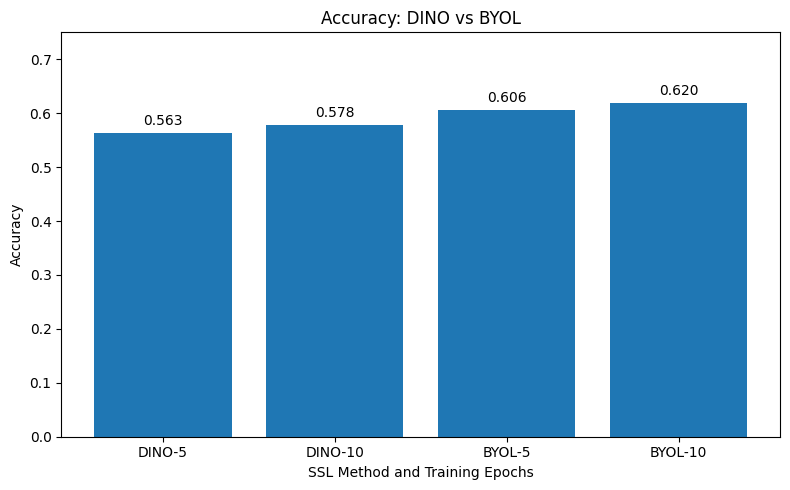

Saved: /content/drive/MyDrive/EyePACS/comparison_accuracy.png


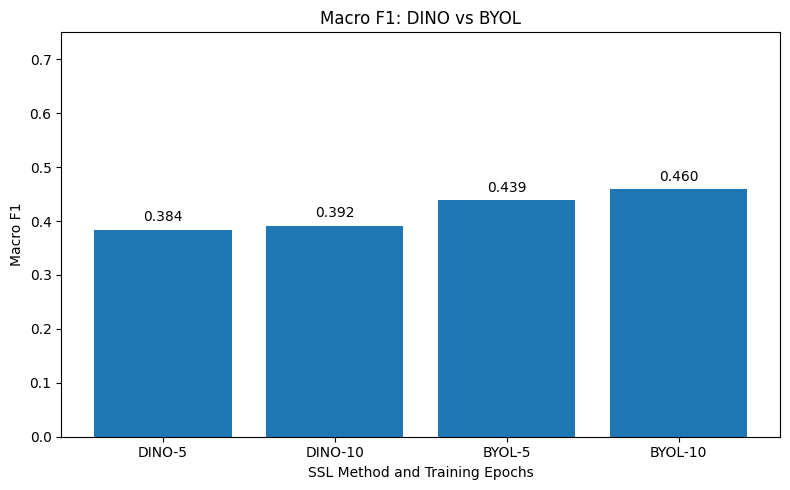

Saved: /content/drive/MyDrive/EyePACS/comparison_macro_f1.png


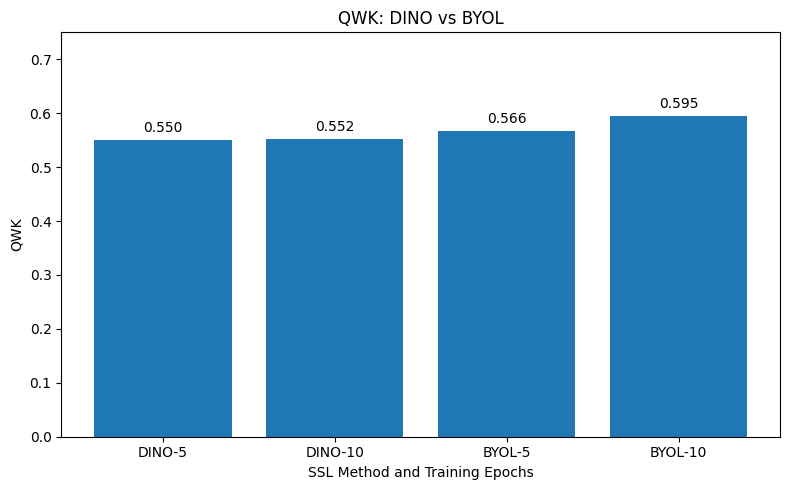

Saved: /content/drive/MyDrive/EyePACS/comparison_qwk.png

✅ ALL 3 RESEARCH GRAPHS SAVED


In [ ]:
# ============================================================
# FINAL RESEARCH GRAPHS
# DINO vs BYOL — 5 vs 10 Epochs
# Logistic Regression
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

results = pd.DataFrame({
    "Method": [
        "DINO-5",
        "DINO-10",
        "BYOL-5",
        "BYOL-10"
    ],
    "Accuracy": [
        0.5634,
        0.5775,
        0.6056,
        0.6197
    ],
    "Macro F1": [
        0.3842,
        0.3917,
        0.4393,
        0.4602
    ],
    "QWK": [
        0.5505,
        0.5523,
        0.5663,
        0.5947
    ]
})

SAVE_DIR = Path("/content/drive/MyDrive/EyePACS")
SAVE_DIR.mkdir(exist_ok=True)

metrics = ["Accuracy", "Macro F1", "QWK"]

for metric in metrics:

    plt.figure(figsize=(8, 5))

    bars = plt.bar(
        results["Method"],
        results[metric]
    )

    plt.ylabel(metric)
    plt.xlabel("SSL Method and Training Epochs")
    plt.title(f"{metric}: DINO vs BYOL")

    plt.ylim(0, 0.75)

    # Add values above bars
    for bar, value in zip(bars, results[metric]):
        plt.text(
            bar.get_x() + bar.get_width()/2,
            value + 0.015,
            f"{value:.3f}",
            ha="center"
        )

    plt.tight_layout()

    filename = SAVE_DIR / f"comparison_{metric.lower().replace(' ', '_')}.png"

    plt.savefig(
        filename,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", filename)

print("\n✅ ALL 3 RESEARCH GRAPHS SAVED")

In [ ]:
import pandas as pd
from pathlib import Path

results = pd.DataFrame({
    "Method": [
        "DINO-5",
        "DINO-10",
        "BYOL-5",
        "BYOL-10"
    ],
    "Classifier": [
        "Logistic Regression",
        "Logistic Regression",
        "Logistic Regression",
        "Logistic Regression"
    ],
    "Accuracy": [
        0.5634,
        0.5810,
        0.6056,
        0.6197
    ],
    "Macro F1": [
        0.3842,
        0.3931,
        0.4393,
        0.4602
    ],
    "QWK": [
        0.5505,
        0.5567,
        0.5663,
        0.5947
    ]
})

SAVE_PATH = Path("/content/drive/MyDrive/EyePACS/final_results_table.csv")

results.to_csv(SAVE_PATH, index=False)

display(results)

print("\n✅ Final results table saved:")
print(SAVE_PATH)

,Method,Classifier,Accuracy,Macro F1,QWK
0,DINO-5,Logistic Regression,0.5634,0.3842,0.5505
1,DINO-10,Logistic Regression,0.5810,0.3931,0.5567
2,BYOL-5,Logistic Regression,0.6056,0.4393,0.5663
3,BYOL-10,Logistic Regression,0.6197,0.4602,0.5947



✅ Final results table saved:
/content/drive/MyDrive/EyePACS/final_results_table.csv


In [ ]:
# ============================================================
# FINAL IMPROVEMENT ANALYSIS
# ============================================================

import pandas as pd

results = pd.DataFrame({
    "Method": ["DINO", "DINO", "BYOL", "BYOL"],
    "Epochs": [5, 10, 5, 10],
    "Accuracy": [0.5634, 0.5810, 0.6056, 0.6197],
    "Macro F1": [0.3842, 0.3931, 0.4393, 0.4602],
    "QWK": [0.5505, 0.5567, 0.5663, 0.5947]
})

for method in ["DINO", "BYOL"]:
    r5 = results[(results.Method == method) & (results.Epochs == 5)].iloc[0]
    r10 = results[(results.Method == method) & (results.Epochs == 10)].iloc[0]

    print(f"\n===== {method}: 5 → 10 Epochs =====")

    for metric in ["Accuracy", "Macro F1", "QWK"]:
        improvement = r10[metric] - r5[metric]
        percentage = (improvement / r5[metric]) * 100

        print(
            f"{metric}: "
            f"{r5[metric]:.4f} → {r10[metric]:.4f} | "
            f"Change = {improvement:+.4f} "
            f"({percentage:+.2f}%)"
        )

print("\n===== BYOL-10 vs DINO-10 =====")

dino10 = results[(results.Method == "DINO") & (results.Epochs == 10)].iloc[0]
byol10 = results[(results.Method == "BYOL") & (results.Epochs == 10)].iloc[0]

for metric in ["Accuracy", "Macro F1", "QWK"]:
    difference = byol10[metric] - dino10[metric]

    print(
        f"{metric}: "
        f"DINO-10 = {dino10[metric]:.4f}, "
        f"BYOL-10 = {byol10[metric]:.4f}, "
        f"Difference = {difference:+.4f}"
    )


===== DINO: 5 → 10 Epochs =====
Accuracy: 0.5634 → 0.5810 | Change = +0.0176 (+3.12%)
Macro F1: 0.3842 → 0.3931 | Change = +0.0089 (+2.32%)
QWK: 0.5505 → 0.5567 | Change = +0.0062 (+1.13%)

===== BYOL: 5 → 10 Epochs =====
Accuracy: 0.6056 → 0.6197 | Change = +0.0141 (+2.33%)
Macro F1: 0.4393 → 0.4602 | Change = +0.0209 (+4.76%)
QWK: 0.5663 → 0.5947 | Change = +0.0284 (+5.02%)

===== BYOL-10 vs DINO-10 =====
Accuracy: DINO-10 = 0.5810, BYOL-10 = 0.6197, Difference = +0.0387
Macro F1: DINO-10 = 0.3931, BYOL-10 = 0.4602, Difference = +0.0671
QWK: DINO-10 = 0.5567, BYOL-10 = 0.5947, Difference = +0.0380


In [ ]:
# ============================================================
# FINAL CLASS-WISE COMPARISON
# DINO-10 vs BYOL-10
# Logistic Regression
# ============================================================

import pandas as pd

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative DR"
]

dino = {
    "Precision": [0.8905, 0.3261, 0.5000, 0.0750, 0.2609],
    "Recall":    [0.8841, 0.4839, 0.2603, 0.2143, 0.2143],
    "F1":        [0.8873, 0.3896, 0.3423, 0.1111, 0.2353]
}

byol = {
    "Precision": [0.9318, 0.4091, 0.5128, 0.2432, 0.1875],
    "Recall":    [0.8913, 0.5806, 0.2740, 0.6429, 0.2143],
    "F1":        [0.9111, 0.4800, 0.3571, 0.3529, 0.2000]
}

rows = []

for i, cls in enumerate(class_names):
    rows.append([
        cls,
        dino["Precision"][i],
        byol["Precision"][i],
        byol["Precision"][i] - dino["Precision"][i],
        dino["Recall"][i],
        byol["Recall"][i],
        byol["Recall"][i] - dino["Recall"][i],
        dino["F1"][i],
        byol["F1"][i],
        byol["F1"][i] - dino["F1"][i]
    ])

comparison = pd.DataFrame(rows, columns=[
    "Class",
    "DINO Precision",
    "BYOL Precision",
    "Precision Difference",
    "DINO Recall",
    "BYOL Recall",
    "Recall Difference",
    "DINO F1",
    "BYOL F1",
    "F1 Difference"
])

display(comparison.round(4))

SAVE_PATH = "/content/drive/MyDrive/EyePACS/classwise_dino_vs_byol.csv"
comparison.to_csv(SAVE_PATH, index=False)

print("\n✅ Saved:", SAVE_PATH)

,Class,DINO Precision,BYOL Precision,Precision Difference,DINO Recall,BYOL Recall,Recall Difference,DINO F1,BYOL F1,F1 Difference
0,No DR,0.8905,0.9318,0.0413,0.8841,0.8913,0.0072,0.8873,0.9111,0.0238
1,Mild,0.3261,0.4091,0.0830,0.4839,0.5806,0.0967,0.3896,0.4800,0.0904
2,Moderate,0.5000,0.5128,0.0128,0.2603,0.2740,0.0137,0.3423,0.3571,0.0148
3,Severe,0.0750,0.2432,0.1682,0.2143,0.6429,0.4286,0.1111,0.3529,0.2418
4,Proliferative DR,0.2609,0.1875,-0.0734,0.2143,0.2143,0.0000,0.2353,0.2000,-0.0353



✅ Saved: /content/drive/MyDrive/EyePACS/classwise_dino_vs_byol.csv


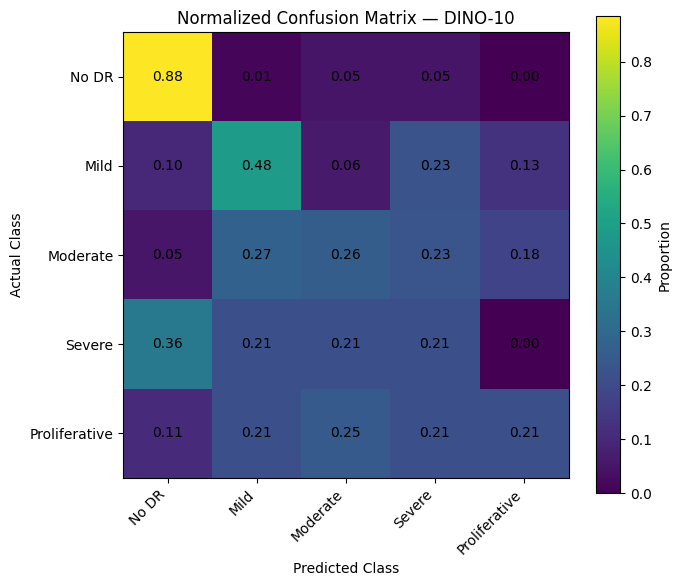

Saved: /content/drive/MyDrive/EyePACS/dino10_normalized_cm.png


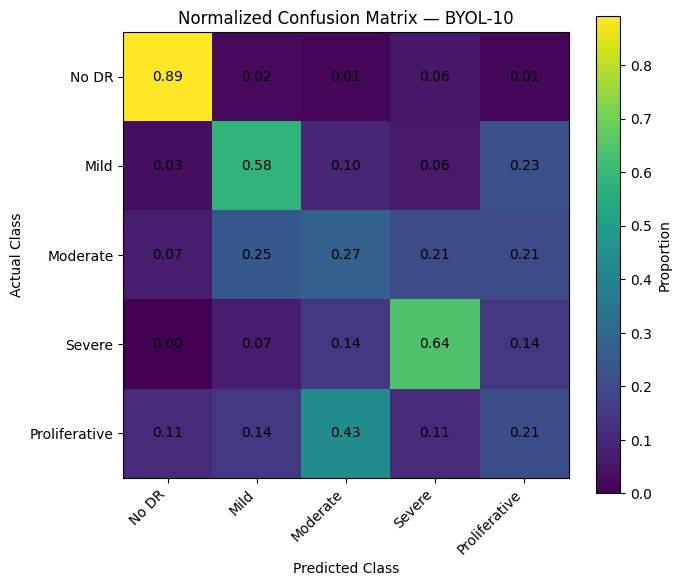

Saved: /content/drive/MyDrive/EyePACS/byol10_normalized_cm.png

✅ BOTH NORMALIZED CONFUSION MATRICES SAVED


In [ ]:
# ============================================================
# NORMALIZED CONFUSION MATRICES
# DINO-10 vs BYOL-10
# ============================================================

import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

SAVE_DIR = Path("/content/drive/MyDrive/EyePACS")
SAVE_DIR.mkdir(exist_ok=True)

classes = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative"
]

# Rows = actual class
# Columns = predicted class

dino_cm = np.array([
    [122, 2, 7, 7, 0],
    [3, 15, 2, 7, 4],
    [4, 20, 19, 17, 13],
    [5, 3, 3, 3, 0],
    [3, 6, 7, 6, 6]
])

byol_cm = np.array([
    [123, 3, 2, 8, 2],
    [1, 18, 3, 2, 7],
    [5, 18, 20, 15, 15],
    [0, 1, 2, 9, 2],
    [3, 4, 12, 3, 6]
])

for name, cm in [
    ("DINO-10", dino_cm),
    ("BYOL-10", byol_cm)
]:

    normalized = cm / cm.sum(axis=1, keepdims=True)

    plt.figure(figsize=(7, 6))

    plt.imshow(normalized)

    plt.xticks(range(5), classes, rotation=45, ha="right")
    plt.yticks(range(5), classes)

    plt.xlabel("Predicted Class")
    plt.ylabel("Actual Class")
    plt.title(f"Normalized Confusion Matrix — {name}")

    for i in range(5):
        for j in range(5):
            plt.text(
                j, i,
                f"{normalized[i,j]:.2f}",
                ha="center",
                va="center"
            )

    plt.colorbar(label="Proportion")
    plt.tight_layout()

    path = SAVE_DIR / f"{name.lower().replace('-', '')}_normalized_cm.png"

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", path)

print("\n✅ BOTH NORMALIZED CONFUSION MATRICES SAVED")

In [ ]:
# ============================================================
# MASTER EXPERIMENT RESULTS
# ============================================================

import pandas as pd
from pathlib import Path

SAVE_DIR = Path("/content/drive/MyDrive/EyePACS")

master = pd.DataFrame([
    ["DINO", 5, "Neural",   0.5458, 0.3096, 0.3600],
    ["DINO", 5, "Logistic", 0.5634, 0.3842, 0.5505],
    ["DINO", 10, "Neural",   0.6303, 0.2839, 0.5029],
    ["DINO", 10, "Logistic", 0.5810, 0.3931, 0.5567],
    ["BYOL", 5, "Neural",   0.5387, 0.3629, 0.4940],
    ["BYOL", 5, "Logistic", 0.6056, 0.4393, 0.5663],
    ["BYOL", 10, "Neural",   0.6796, 0.2990, 0.5878],
    ["BYOL", 10, "Logistic", 0.6197, 0.4602, 0.5947],
], columns=[
    "SSL Method",
    "Epochs",
    "Classifier",
    "Accuracy",
    "Macro F1",
    "QWK"
])

path = SAVE_DIR / "MASTER_FINAL_RESULTS.csv"
master.to_csv(path, index=False)

display(master)

print("\n✅ MASTER RESULTS SAVED:")
print(path)

,SSL Method,Epochs,Classifier,Accuracy,Macro F1,QWK
0,DINO,5,Neural,0.5458,0.3096,0.3600
1,DINO,5,Logistic,0.5634,0.3842,0.5505
2,DINO,10,Neural,0.6303,0.2839,0.5029
3,DINO,10,Logistic,0.5810,0.3931,0.5567
4,BYOL,5,Neural,0.5387,0.3629,0.4940
5,BYOL,5,Logistic,0.6056,0.4393,0.5663
6,BYOL,10,Neural,0.6796,0.2990,0.5878
7,BYOL,10,Logistic,0.6197,0.4602,0.5947



✅ MASTER RESULTS SAVED:
/content/drive/MyDrive/EyePACS/MASTER_FINAL_RESULTS.csv


In [ ]:
# ============================================================
# FINAL DATASET STATISTICS
# ============================================================

import pandas as pd
from pathlib import Path

BASE = Path("/content/dataset")

class_names = {
    0: "No DR",
    1: "Mild",
    2: "Moderate",
    3: "Severe",
    4: "Proliferative DR"
}

all_stats = []

for split in ["train", "valid", "test"]:

    df = pd.read_csv(BASE / split / "labels.csv")

    counts = df["level"].value_counts().sort_index()

    print(f"\n===== {split.upper()} =====")
    print("Total images:", len(df))

    for cls, count in counts.items():
        percentage = count / len(df) * 100
        print(
            f"{cls} - {class_names[cls]}: "
            f"{count} ({percentage:.2f}%)"
        )

    all_stats.append({
        "Split": split,
        "Total": len(df)
    })

print("\n===== TOTAL DATASET =====")

total = sum(x["Total"] for x in all_stats)
print("Total images:", total)

print("\n✅ Dataset statistics verified")


===== TRAIN =====
Total images: 1986
0 - No DR: 1004 (50.55%)
1 - Mild: 202 (10.17%)
2 - Moderate: 538 (27.09%)
3 - Severe: 89 (4.48%)
4 - Proliferative DR: 153 (7.70%)

===== VALID =====
Total images: 568
0 - No DR: 288 (50.70%)
1 - Mild: 61 (10.74%)
2 - Moderate: 155 (27.29%)
3 - Severe: 28 (4.93%)
4 - Proliferative DR: 36 (6.34%)

===== TEST =====
Total images: 284
0 - No DR: 138 (48.59%)
1 - Mild: 31 (10.92%)
2 - Moderate: 73 (25.70%)
3 - Severe: 14 (4.93%)
4 - Proliferative DR: 28 (9.86%)

===== TOTAL DATASET =====
Total images: 2838

✅ Dataset statistics verified


In [ ]:
import os
import random
from PIL import Image
import matplotlib.pyplot as plt

DATASET_PATH = "/content/drive/MyDrive/EyePACS/dataset"

# Find some images from train folder
image_paths = []

for root, dirs, files in os.walk(os.path.join(DATASET_PATH, "train")):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            image_paths.append(os.path.join(root, file))

print("Total train images found:", len(image_paths))

# Select 6 random images
sample_paths = random.sample(image_paths, min(6, len(image_paths)))

plt.figure(figsize=(15, 10))

for i, path in enumerate(sample_paths):
    img = Image.open(path).convert("RGB")

    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(os.path.basename(path)[:25])
    plt.axis("off")

plt.tight_layout()
plt.show()

Total train images found: 0


<Figure size 1500x1000 with 0 Axes>

In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

BASE_PATH = "/content/drive/MyDrive/EyePACS"

print("EyePACS exists:", os.path.exists(BASE_PATH))
print("\nContents:")

for item in os.listdir(BASE_PATH):
    print(item)

EyePACS exists: True

Contents:
diabetic-retinopathy-screening.zip
dataset
checkpoints
features
results_dino_vs_byol.csv
final_master_results.csv
byol_confusion_matrix.png
dino_confusion_matrix.png
final_performance_comparison.png
report_results_table.csv
report_performance_graph.png
dino10_confusion_matrix.png
byol10_confusion_matrix.png
final_5_vs_10_results.csv
stability_results.csv
comparison_accuracy.png
comparison_macro_f1.png
comparison_qwk.png
final_results_table.csv
classwise_dino_vs_byol.csv
dino10_normalized_cm.png
byol10_normalized_cm.png
MASTER_FINAL_RESULTS.csv


In [ ]:
import os

DATASET_PATH = "/content/drive/MyDrive/EyePACS/dataset"

print("Dataset exists:", os.path.exists(DATASET_PATH))
print("\nDataset contents:")

for item in os.listdir(DATASET_PATH):
    full_path = os.path.join(DATASET_PATH, item)

    if os.path.isdir(full_path):
        print("[FOLDER] ", item)
    else:
        print("[FILE]   ", item)

Dataset exists: True

Dataset contents:
[FILE]    README.dataset.txt
[FILE]    README.roboflow.txt
[FOLDER]  test
[FOLDER]  train
[FOLDER]  valid


In [ ]:
import os

TRAIN_PATH = "/content/drive/MyDrive/EyePACS/dataset/train"

print("Train path exists:", os.path.exists(TRAIN_PATH))
print("\nTrain contents:")

for item in os.listdir(TRAIN_PATH):
    full_path = os.path.join(TRAIN_PATH, item)

    if os.path.isdir(full_path):
        print("[FOLDER] ", item)
    else:
        print("[FILE]   ", item)

Train path exists: True

Train contents:
[FILE]    8241e43408a8_png_jpg.rf.f92efdf467fa1b9c6cd17daf9341e943.jpg
[FILE]    8273fdb4405e_png_jpg.rf.6dea32775f56484b8b1ec61848b28ca4.jpg
[FILE]    82910bba4753_png_jpg.rf.afeb9d43aa2567ffb8403f122c6e38aa.jpg
[FILE]    82ac8463fadd_png_jpg.rf.5713b3dece8a940e4d51286f3e0e00b9.jpg
[FILE]    82bb8a01935f_png_jpg.rf.ff85b55a81a1182e066587b4d9721c9d.jpg
[FILE]    82d364726a58_png_jpg.rf.bfaef2bc454e5855645741042225e719.jpg
[FILE]    82deb07a6618_png_jpg.rf.5723b3d624ba97ca9e8ccf239904738b.jpg
[FILE]    82e5bc01f8a4_png_jpg.rf.0ea20d7e9259709fab03561fa44a9fc4.jpg
[FILE]    82f2784ead76_png_jpg.rf.30466679c4bd9662909261ca7d1d4313.jpg
[FILE]    8344c783da65_png_jpg.rf.b821acc24b1f2723371b16fb3b2a0baf.jpg
[FILE]    83517eaeccb9_png_jpg.rf.d67760c77bfa28c8250b4ecd5b3c456f.jpg
[FILE]    837acf120946_png_jpg.rf.b893cfdbfeb4f038a83f7f1b822dc0f2.jpg
[FILE]    838c87c63422_png_jpg.rf.468317a75ff69ad48848a5b128433b45.jpg
[FILE]    83a63c4a3e4a_png_jpg.rf.31

In [ ]:
import os

TRAIN_PATH = "/content/drive/MyDrive/EyePACS/dataset/train"

files = os.listdir(TRAIN_PATH)

print("Total files in train folder:", len(files))

print("\nFirst 10 files:")
for f in files[:10]:
    print(f)

print("\nImage files:")
image_files = [
    f for f in files
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
]

print("Total image files:", len(image_files))

Total files in train folder: 1988

First 10 files:
8241e43408a8_png_jpg.rf.f92efdf467fa1b9c6cd17daf9341e943.jpg
8273fdb4405e_png_jpg.rf.6dea32775f56484b8b1ec61848b28ca4.jpg
82910bba4753_png_jpg.rf.afeb9d43aa2567ffb8403f122c6e38aa.jpg
82ac8463fadd_png_jpg.rf.5713b3dece8a940e4d51286f3e0e00b9.jpg
82bb8a01935f_png_jpg.rf.ff85b55a81a1182e066587b4d9721c9d.jpg
82d364726a58_png_jpg.rf.bfaef2bc454e5855645741042225e719.jpg
82deb07a6618_png_jpg.rf.5723b3d624ba97ca9e8ccf239904738b.jpg
82e5bc01f8a4_png_jpg.rf.0ea20d7e9259709fab03561fa44a9fc4.jpg
82f2784ead76_png_jpg.rf.30466679c4bd9662909261ca7d1d4313.jpg
8344c783da65_png_jpg.rf.b821acc24b1f2723371b16fb3b2a0baf.jpg

Image files:
Total image files: 1986


In [ ]:
import os

TRAIN_PATH = "/content/drive/MyDrive/EyePACS/dataset/train"

files = os.listdir(TRAIN_PATH)

print("Total files in train folder:", len(files))

print("\nFirst 10 files:")
for f in files[:10]:
    print(f)

print("\nImage files:")
image_files = [
    f for f in files
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
]

print("Total image files:", len(image_files))

Total files in train folder: 1988

First 10 files:
8241e43408a8_png_jpg.rf.f92efdf467fa1b9c6cd17daf9341e943.jpg
8273fdb4405e_png_jpg.rf.6dea32775f56484b8b1ec61848b28ca4.jpg
82910bba4753_png_jpg.rf.afeb9d43aa2567ffb8403f122c6e38aa.jpg
82ac8463fadd_png_jpg.rf.5713b3dece8a940e4d51286f3e0e00b9.jpg
82bb8a01935f_png_jpg.rf.ff85b55a81a1182e066587b4d9721c9d.jpg
82d364726a58_png_jpg.rf.bfaef2bc454e5855645741042225e719.jpg
82deb07a6618_png_jpg.rf.5723b3d624ba97ca9e8ccf239904738b.jpg
82e5bc01f8a4_png_jpg.rf.0ea20d7e9259709fab03561fa44a9fc4.jpg
82f2784ead76_png_jpg.rf.30466679c4bd9662909261ca7d1d4313.jpg
8344c783da65_png_jpg.rf.b821acc24b1f2723371b16fb3b2a0baf.jpg

Image files:
Total image files: 1986


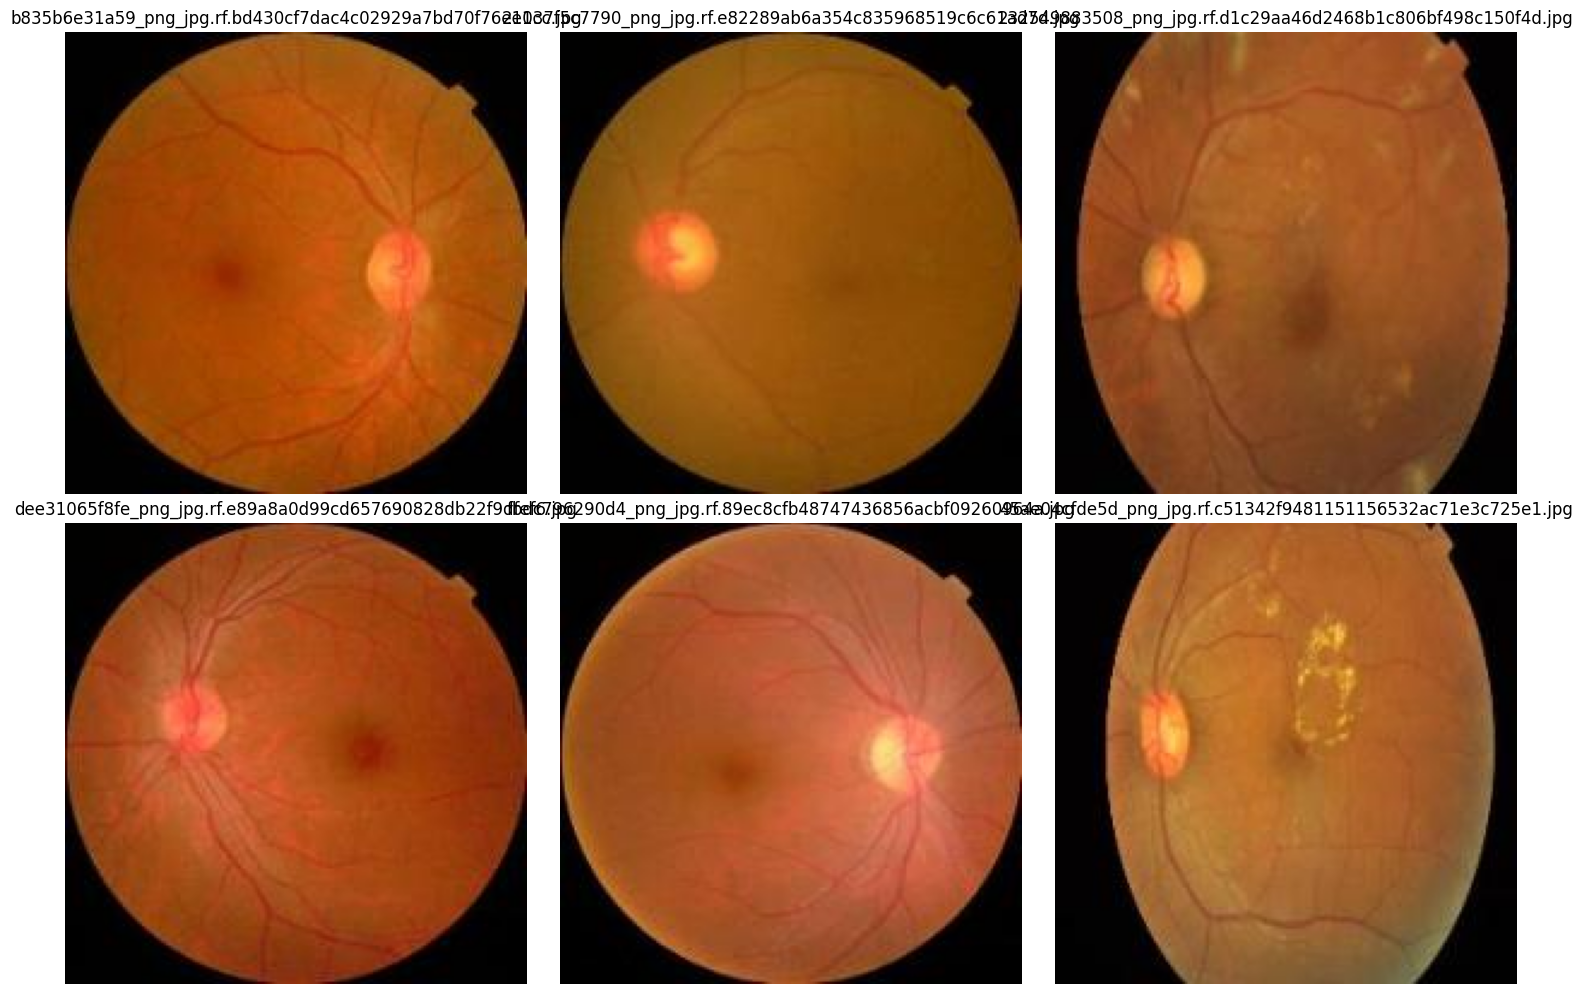

In [ ]:
import os
import random
from PIL import Image
import matplotlib.pyplot as plt

TRAIN_PATH = "/content/drive/MyDrive/EyePACS/dataset/train"

image_files = [
    f for f in os.listdir(TRAIN_PATH)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
]

sample_files = random.sample(image_files, min(6, len(image_files)))

plt.figure(figsize=(15, 10))

for i, filename in enumerate(sample_files):
    path = os.path.join(TRAIN_PATH, filename)
    img = Image.open(path).convert("RGB")

    plt.subplot(2, 3, i + 1)
    plt.imshow(img)
    plt.title(filename)
    plt.axis("off")

plt.tight_layout()
plt.show()

In [ ]:
from google.colab import drive
import os

drive.mount('/content/drive', force_remount=True)

BASE = "/content/drive/MyDrive/EyePACS"

print("EyePACS exists:", os.path.exists(BASE))
print("\nEyePACS contents:")

for item in os.listdir(BASE):
    print(item)

Mounted at /content/drive
EyePACS exists: True

EyePACS contents:
diabetic-retinopathy-screening.zip
dataset
checkpoints
features
results_dino_vs_byol.csv
final_master_results.csv
byol_confusion_matrix.png
dino_confusion_matrix.png
final_performance_comparison.png
report_results_table.csv
report_performance_graph.png
dino10_confusion_matrix.png
byol10_confusion_matrix.png
final_5_vs_10_results.csv
stability_results.csv
comparison_accuracy.png
comparison_macro_f1.png
comparison_qwk.png
final_results_table.csv
classwise_dino_vs_byol.csv
dino10_normalized_cm.png
byol10_normalized_cm.png
MASTER_FINAL_RESULTS.csv


In [ ]:
import os
from PIL import Image
from collections import Counter

TRAIN_PATH = "/content/drive/MyDrive/EyePACS/dataset/train"

image_files = []

for f in os.listdir(TRAIN_PATH):
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp")):
        image_files.append(f)

print("Image files found:", len(image_files))

sizes = []

for f in image_files:
    path = os.path.join(TRAIN_PATH, f)

    try:
        with Image.open(path) as img:
            sizes.append(img.size)
    except Exception as e:
        print("Could not open:", f)

print("Images successfully opened:", len(sizes))

print("\nMost common image sizes:")
for size, count in Counter(sizes).most_common(10):
    print(size, "->", count)

widths = [w for w, h in sizes]
heights = [h for w, h in sizes]

print("\nWidth range:", min(widths), "to", max(widths))
print("Height range:", min(heights), "to", max(heights))


Image files found: 1986
Images successfully opened: 1986

Most common image sizes:
(192, 192) -> 1986

Width range: 192 to 192
Height range: 192 to 192


In [ ]:
import os

DATASET_PATH = "/content/drive/MyDrive/EyePACS/dataset"

print("Searching for train folder...\n")

for root, dirs, files in os.walk(DATASET_PATH):
    if os.path.basename(root).lower() == "train":
        print("TRAIN FOLDER FOUND:")
        print(root)
        print("Number of files:", len(files))
        print("First 5 files:", files[:5])
        print()

Searching for train folder...

TRAIN FOLDER FOUND:
/content/drive/MyDrive/EyePACS/dataset/train
Number of files: 1988
First 5 files: ['8241e43408a8_png_jpg.rf.f92efdf467fa1b9c6cd17daf9341e943.jpg', '8273fdb4405e_png_jpg.rf.6dea32775f56484b8b1ec61848b28ca4.jpg', '82910bba4753_png_jpg.rf.afeb9d43aa2567ffb8403f122c6e38aa.jpg', '82ac8463fadd_png_jpg.rf.5713b3dece8a940e4d51286f3e0e00b9.jpg', '82bb8a01935f_png_jpg.rf.ff85b55a81a1182e066587b4d9721c9d.jpg']



In [ ]:
import os
from PIL import Image
from collections import Counter

BASE_PATH = "/content/drive/MyDrive/EyePACS/dataset"

for split in ["train", "valid", "test"]:
    folder = os.path.join(BASE_PATH, split)

    image_files = []

    for f in os.listdir(folder):
        if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp")):
            image_files.append(f)

    sizes = []

    for f in image_files:
        path = os.path.join(folder, f)

        try:
            with Image.open(path) as img:
                sizes.append(img.size)
        except:
            pass

    print("\n" + "=" * 40)
    print(split.upper())
    print("Image files:", len(image_files))
    print("Opened successfully:", len(sizes))

    if sizes:
        print("Most common sizes:")
        for size, count in Counter(sizes).most_common(3):
            print(size, "->", count)


TRAIN
Image files: 1986
Opened successfully: 1986
Most common sizes:
(192, 192) -> 1986

VALID
Image files: 568
Opened successfully: 568
Most common sizes:
(192, 192) -> 568

TEST
Image files: 284
Opened successfully: 284
Most common sizes:
(192, 192) -> 284


In [ ]:
import os

SEARCH_PATH = "/content/drive/MyDrive/EyePACS"

keywords = [
    "CLAHE",
    "clahe",
    "Resize",
    "resize",
    "Normalize",
    "normalize",
    "RandomResizedCrop",
    "ColorJitter",
    "RandomHorizontalFlip",
    "RandomRotation",
    "transforms.Compose"
]

print("Searching your saved project files for preprocessing terms...\n")

for root, dirs, files in os.walk(SEARCH_PATH):
    # Skip large/unnecessary folders
    dirs[:] = [d for d in dirs if d not in ["checkpoints", "features"]]

    for file in files:
        if file.endswith((".py", ".ipynb", ".txt")):
            path = os.path.join(root, file)

            try:
                with open(path, "r", encoding="utf-8", errors="ignore") as f:
                    text = f.read()

                found = [k for k in keywords if k in text]

                if found:
                    print("FILE:", path)
                    print("FOUND:", found)
                    print("-" * 60)

            except:
                pass

Searching your saved project files for preprocessing terms...

FILE: /content/drive/MyDrive/EyePACS/dataset/README.roboflow.txt
FOUND: ['Resize']
------------------------------------------------------------


In [ ]:
import os
import numpy as np
from PIL import Image

TRAIN_PATH = "/content/drive/MyDrive/EyePACS/dataset/train"

image_files = [
    f for f in os.listdir(TRAIN_PATH)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
]

black_percentages = []

for filename in image_files:
    path = os.path.join(TRAIN_PATH, filename)

    with Image.open(path) as img:
        img = np.array(img.convert("RGB"))

    # Pixel is considered black if all RGB channels are <= 10
    black_pixels = np.all(img <= 10, axis=2)

    black_percentage = black_pixels.mean() * 100
    black_percentages.append(black_percentage)

print("Images checked:", len(black_percentages))
print("Average black pixels:", round(np.mean(black_percentages), 2), "%")
print("Minimum:", round(np.min(black_percentages), 2), "%")
print("Maximum:", round(np.max(black_percentages), 2), "%")
print("Median:", round(np.median(black_percentages), 2), "%")

Images checked: 1986
Average black pixels: 20.92 %
Minimum: 0.0 %
Maximum: 51.66 %
Median: 17.64 %


In [ ]:
import os
import numpy as np
from PIL import Image

TRAIN_PATH = "/content/drive/MyDrive/EyePACS/dataset/train"

image_files = [
    f for f in os.listdir(TRAIN_PATH)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
]

border_stats = []

for filename in image_files:
    path = os.path.join(TRAIN_PATH, filename)

    with Image.open(path) as img:
        img = np.array(img.convert("RGB"))

    black = np.all(img <= 10, axis=2)

    h, w = black.shape

    # Percentage of black pixels in each border
    top = black[:20, :].mean() * 100
    bottom = black[-20:, :].mean() * 100
    left = black[:, :20].mean() * 100
    right = black[:, -20:].mean() * 100

    border_stats.append([top, bottom, left, right])

border_stats = np.array(border_stats)

print("Average black pixels in each 20-pixel border:")
print("Top:   ", round(border_stats[:, 0].mean(), 2), "%")
print("Bottom:", round(border_stats[:, 1].mean(), 2), "%")
print("Left:  ", round(border_stats[:, 2].mean(), 2), "%")
print("Right: ", round(border_stats[:, 3].mean(), 2), "%")

print("\nMaximum black percentage in each border:")
print("Top:   ", round(border_stats[:, 0].max(), 2), "%")
print("Bottom:", round(border_stats[:, 1].max(), 2), "%")
print("Left:  ", round(border_stats[:, 2].max(), 2), "%")
print("Right: ", round(border_stats[:, 3].max(), 2), "%")

Average black pixels in each 20-pixel border:
Top:    41.98 %
Bottom: 44.76 %
Left:   66.64 %
Right:  58.34 %

Maximum black percentage in each border:
Top:    89.82 %
Bottom: 87.71 %
Left:   100.0 %
Right:  100.0 %


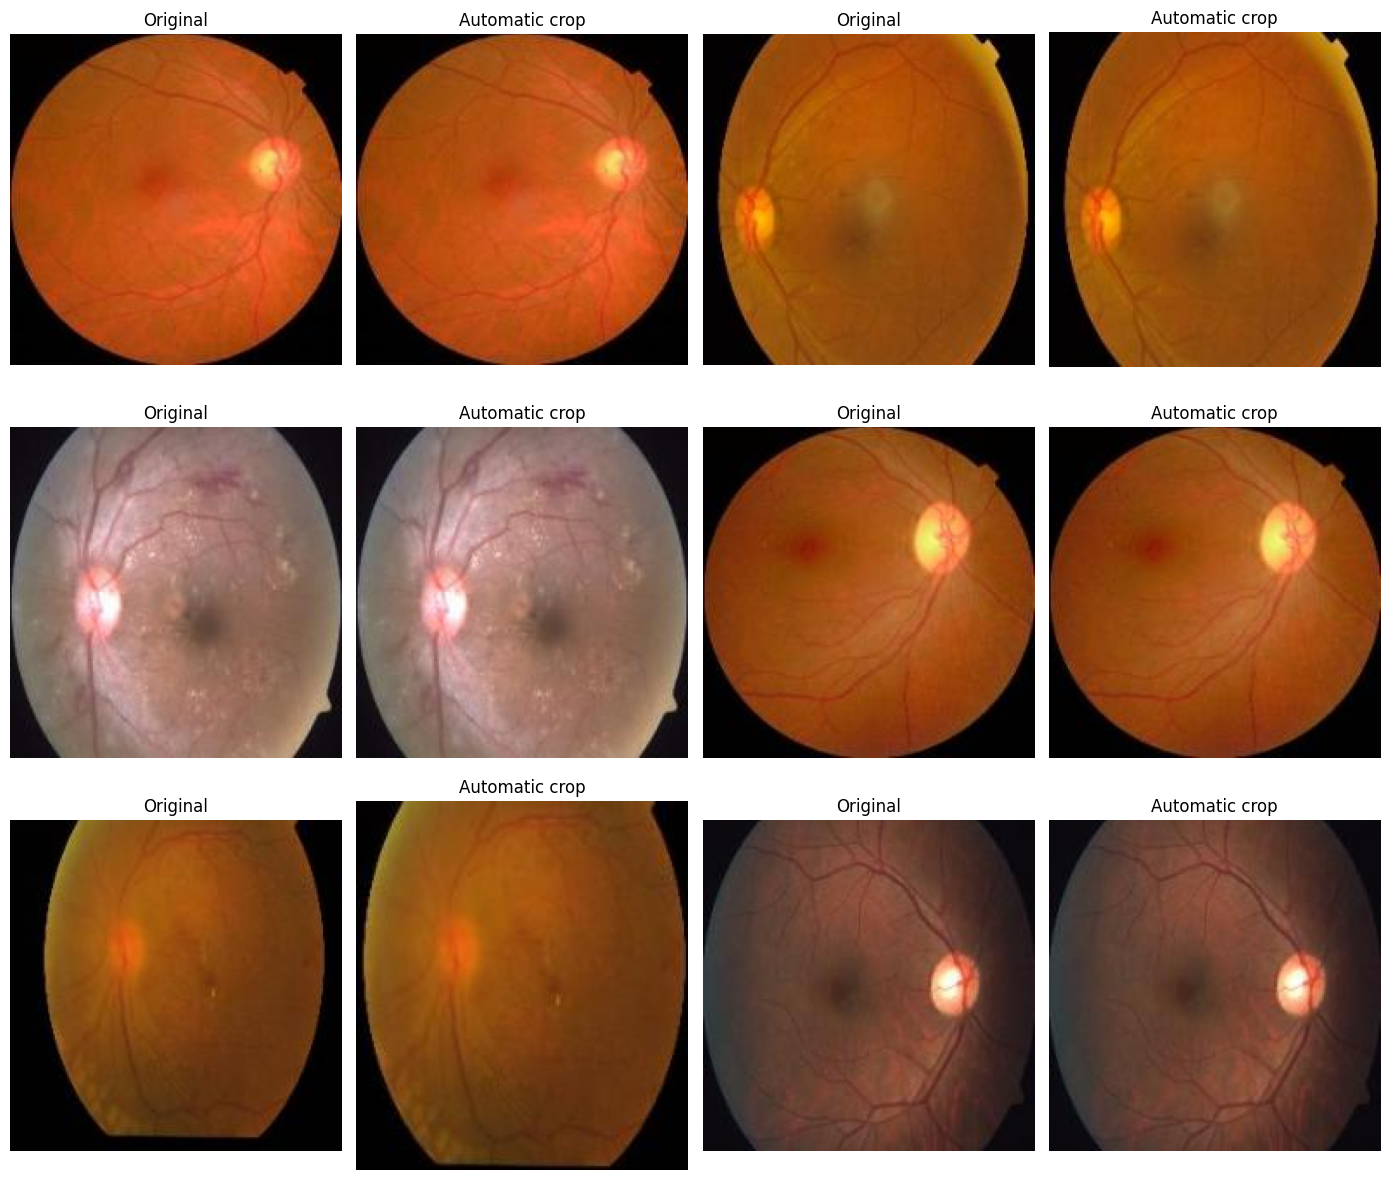

In [ ]:
import os
import numpy as np
from PIL import Image
import matplotlib.pyplot as plt

TRAIN_PATH = "/content/drive/MyDrive/EyePACS/dataset/train"

image_files = [
    f for f in os.listdir(TRAIN_PATH)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
]

sample_files = image_files[:6]


def crop_retinal_region(img, threshold=15):
    img = np.array(img.convert("RGB"))

    # Detect pixels that are not near-black
    mask = np.max(img, axis=2) > threshold

    rows = np.where(mask.any(axis=1))[0]
    cols = np.where(mask.any(axis=0))[0]

    if len(rows) == 0 or len(cols) == 0:
        return Image.fromarray(img)

    y1, y2 = rows[0], rows[-1] + 1
    x1, x2 = cols[0], cols[-1] + 1

    return Image.fromarray(img[y1:y2, x1:x2])


plt.figure(figsize=(14, 12))

for i, filename in enumerate(sample_files):

    path = os.path.join(TRAIN_PATH, filename)

    original = Image.open(path).convert("RGB")
    cropped = crop_retinal_region(original)

    # Original
    plt.subplot(3, 4, 2 * i + 1)
    plt.imshow(original)
    plt.title("Original")
    plt.axis("off")

    # Cropped
    plt.subplot(3, 4, 2 * i + 2)
    plt.imshow(cropped)
    plt.title("Automatic crop")
    plt.axis("off")

plt.tight_layout()
plt.show()

Training images: 1986


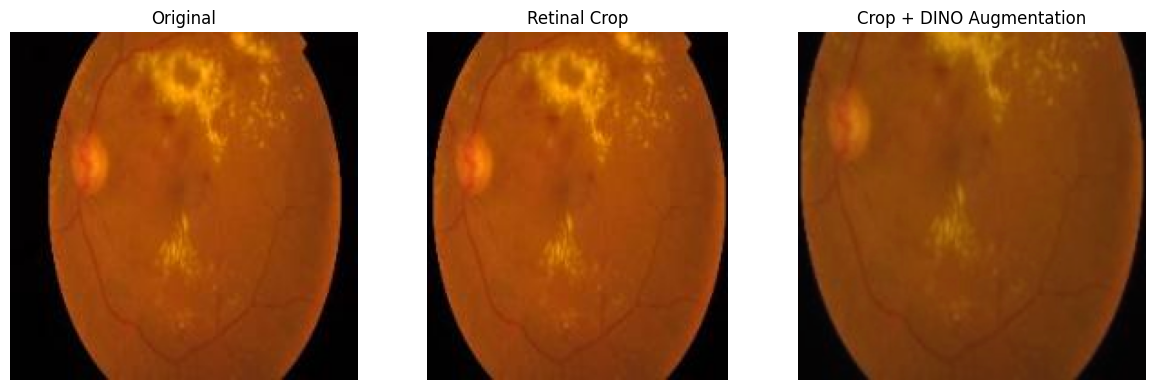

SUCCESS: Crop + DINO augmentation test completed.


In [ ]:
import os
from pathlib import Path
import pandas as pd
from PIL import Image
import matplotlib.pyplot as plt
from torchvision import transforms

# ================= PATH =================
TRAIN_DIR = Path("/content/drive/MyDrive/EyePACS/dataset/train")

# ================= LOAD LABELS =================
df = pd.read_csv(TRAIN_DIR / "labels.csv")

print("Training images:", len(df))

# ================= RETINAL CROP =================
def crop_retinal_region(img, threshold=15):
    import numpy as np

    img = np.array(img.convert("RGB"))

    mask = np.max(img, axis=2) > threshold

    rows = np.where(mask.any(axis=1))[0]
    cols = np.where(mask.any(axis=0))[0]

    if len(rows) == 0 or len(cols) == 0:
        return Image.fromarray(img)

    y1, y2 = rows[0], rows[-1] + 1
    x1, x2 = cols[0], cols[-1] + 1

    return Image.fromarray(img[y1:y2, x1:x2])

# ================= CURRENT DINO GLOBAL AUGMENTATION =================
normalize = transforms.Normalize(
    [0.485, 0.456, 0.406],
    [0.229, 0.224, 0.225]
)

global_crop = transforms.Compose([
    transforms.RandomResizedCrop(224, scale=(0.5, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.2, 0.2, 0.1, 0.02),
    transforms.ToTensor(),
    normalize
])

# ================= TEST ONE IMAGE =================
test_file = df["filename"].iloc[0]

img = Image.open(TRAIN_DIR / test_file).convert("RGB")

cropped = crop_retinal_region(img)

augmented = global_crop(cropped)

# Convert normalized tensor back approximately for display
mean = augmented.new_tensor([0.485, 0.456, 0.406]).view(3, 1, 1)
std = augmented.new_tensor([0.229, 0.224, 0.225]).view(3, 1, 1)

display_img = (augmented * std + mean).clamp(0, 1)

# ================= DISPLAY =================
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(cropped)
plt.title("Retinal Crop")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(display_img.permute(1, 2, 0))
plt.title("Crop + DINO Augmentation")
plt.axis("off")

plt.tight_layout()
plt.show()

print("SUCCESS: Crop + DINO augmentation test completed.")

In [ ]:
import os
import numpy as np
from PIL import Image

TRAIN_DIR = "/content/drive/MyDrive/EyePACS/dataset/train"

image_files = [
    f for f in os.listdir(TRAIN_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png", ".bmp", ".webp"))
]

crop_ratios = []
original_sizes = []
cropped_sizes = []

for filename in image_files:
    path = os.path.join(TRAIN_DIR, filename)

    img = Image.open(path).convert("RGB")
    original_w, original_h = img.size

    arr = np.array(img)

    # Detect non-black retinal region
    mask = np.max(arr, axis=2) > 15

    rows = np.where(mask.any(axis=1))[0]
    cols = np.where(mask.any(axis=0))[0]

    if len(rows) == 0 or len(cols) == 0:
        cropped_w, cropped_h = original_w, original_h
    else:
        y1, y2 = rows[0], rows[-1] + 1
        x1, x2 = cols[0], cols[-1] + 1

        cropped_w = x2 - x1
        cropped_h = y2 - y1

    original_area = original_w * original_h
    cropped_area = cropped_w * cropped_h

    crop_ratios.append(cropped_area / original_area)

    original_sizes.append((original_w, original_h))
    cropped_sizes.append((cropped_w, cropped_h))

print("Images checked:", len(image_files))

print("\nOriginal size:")
print("Width:", min(w for w, h in original_sizes),
      "to", max(w for w, h in original_sizes))
print("Height:", min(h for w, h in original_sizes),
      "to", max(h for w, h in original_sizes))

print("\nCropped size:")
print("Width:",
      min(w for w, h in cropped_sizes),
      "to",
      max(w for w, h in cropped_sizes))

print("Height:",
      min(h for w, h in cropped_sizes),
      "to",
      max(h for w, h in cropped_sizes))

print("\nRetinal area retained:")
print("Average:", round(np.mean(crop_ratios) * 100, 2), "%")
print("Median :", round(np.median(crop_ratios) * 100, 2), "%")
print("Minimum:", round(np.min(crop_ratios) * 100, 2), "%")

Images checked: 1986

Original size:
Width: 192 to 192
Height: 192 to 192

Cropped size:
Width: 129 to 192
Height: 172 to 192

Retinal area retained:
Average: 91.2 %
Median : 97.92 %
Minimum: 60.54 %


In [ ]:
import numpy as np
from PIL import Image

def retinal_crop(img, threshold=15):
    """
    Remove near-black border while preserving the retinal field.
    """
    img = img.convert("RGB")
    arr = np.array(img)

    # Detect non-black pixels
    mask = np.max(arr, axis=2) > threshold

    rows = np.where(mask.any(axis=1))[0]
    cols = np.where(mask.any(axis=0))[0]

    # Safety check
    if len(rows) == 0 or len(cols) == 0:
        return img

    y1, y2 = rows[0], rows[-1] + 1
    x1, x2 = cols[0], cols[-1] + 1

    return Image.fromarray(arr[y1:y2, x1:x2])

print("SUCCESS: Retinal preprocessing function is ready.")

SUCCESS: Retinal preprocessing function is ready.


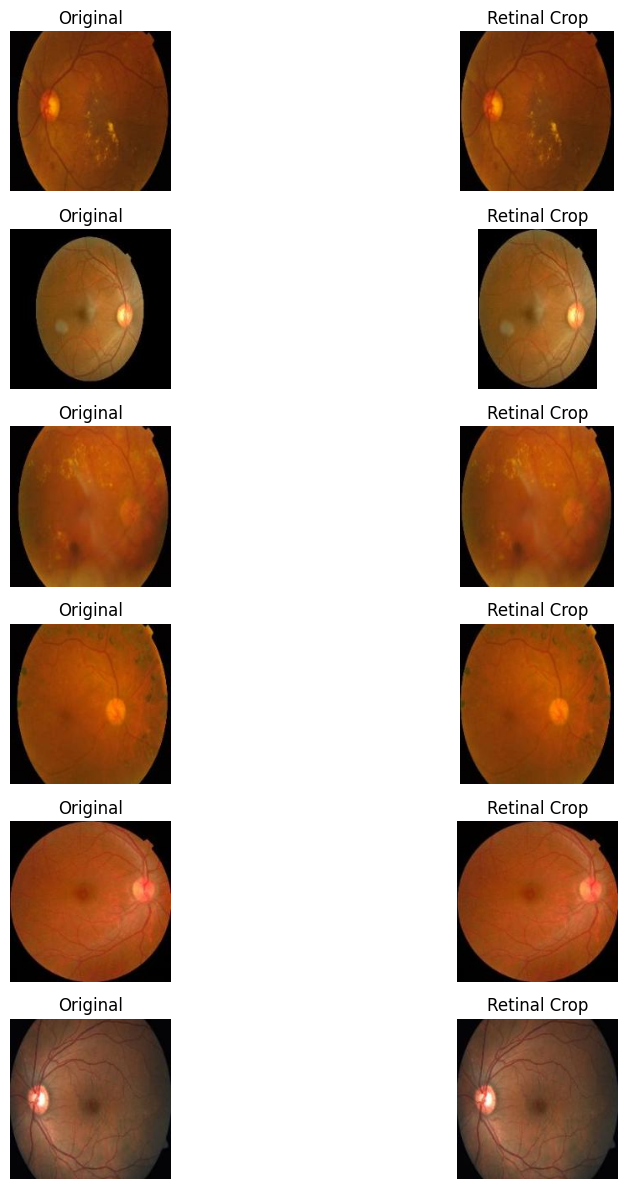

SUCCESS: 6 random images checked.


In [ ]:
import random
import matplotlib.pyplot as plt
from pathlib import Path
from PIL import Image

# Make sure TRAIN_DIR is a Path object
TRAIN_DIR = Path("/content/drive/MyDrive/EyePACS/dataset/train")

# Get 6 random training images
sample_files = random.sample(list(df["filename"]), 6)

plt.figure(figsize=(12, 12))

for i, filename in enumerate(sample_files):

    img = Image.open(TRAIN_DIR / str(filename)).convert("RGB")
    cropped = retinal_crop(img)

    # Original
    plt.subplot(6, 2, 2*i + 1)
    plt.imshow(img)
    plt.title("Original")
    plt.axis("off")

    # Retinal crop
    plt.subplot(6, 2, 2*i + 2)
    plt.imshow(cropped)
    plt.title("Retinal Crop")
    plt.axis("off")

plt.tight_layout()
plt.show()

print("SUCCESS: 6 random images checked.")

In [ ]:
from torchvision import transforms

# ImageNet normalization
normalize = transforms.Normalize(
    [0.485, 0.456, 0.406],
    [0.229, 0.224, 0.225]
)

# Retinal crop + DINO global view
dino_global_crop = transforms.Compose([
    transforms.Lambda(retinal_crop),
    transforms.RandomResizedCrop(
        224,
        scale=(0.5, 1.0)
    ),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(
        0.2, 0.2, 0.1, 0.02
    ),
    transforms.ToTensor(),
    normalize
])

# Retinal crop + DINO local view
dino_local_crop = transforms.Compose([
    transforms.Lambda(retinal_crop),
    transforms.RandomResizedCrop(
        96,
        scale=(0.2, 0.6)
    ),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(
        0.2, 0.2, 0.1, 0.02
    ),
    transforms.ToTensor(),
    normalize
])

print("SUCCESS: New DINO retinal-crop transforms created.")

SUCCESS: New DINO retinal-crop transforms created.


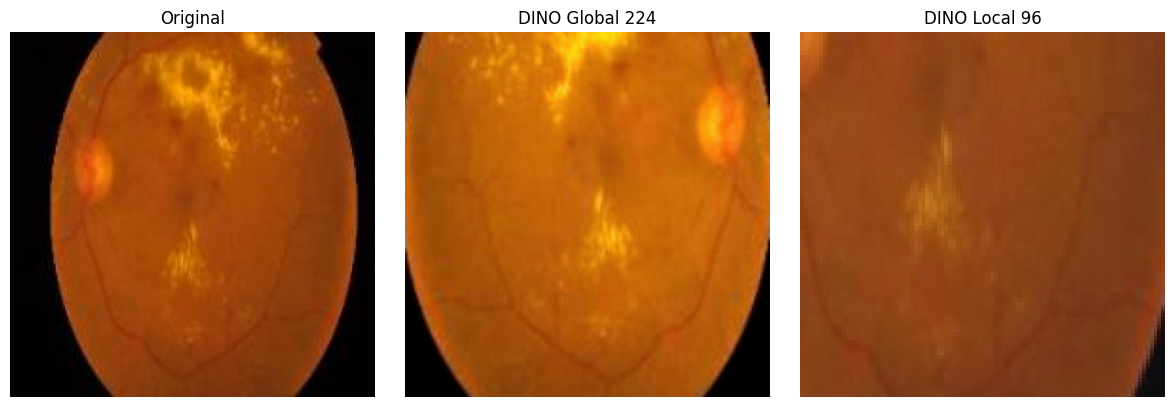

SUCCESS: DINO transform test completed.


In [ ]:
import torch
import matplotlib.pyplot as plt
from PIL import Image
from pathlib import Path

# Make sure paths are correct
TRAIN_DIR = Path("/content/drive/MyDrive/EyePACS/dataset/train")

# Use one training image
test_file = df["filename"].iloc[0]
img = Image.open(TRAIN_DIR / str(test_file)).convert("RGB")

# Generate DINO views
global_view = dino_global_crop(img)
local_view = dino_local_crop(img)

# ImageNet normalization values
mean = torch.tensor(
    [0.485, 0.456, 0.406]
).view(3, 1, 1)

std = torch.tensor(
    [0.229, 0.224, 0.225]
).view(3, 1, 1)

# Convert normalized tensors back for display
global_display = (
    global_view.cpu() * std + mean
).clamp(0, 1)

local_display = (
    local_view.cpu() * std + mean
).clamp(0, 1)

# Display
plt.figure(figsize=(12, 4))

plt.subplot(1, 3, 1)
plt.imshow(img)
plt.title("Original")
plt.axis("off")

plt.subplot(1, 3, 2)
plt.imshow(global_display.permute(1, 2, 0))
plt.title("DINO Global 224")
plt.axis("off")

plt.subplot(1, 3, 3)
plt.imshow(local_display.permute(1, 2, 0))
plt.title("DINO Local 96")
plt.axis("off")

plt.tight_layout()
plt.show()

print("SUCCESS: DINO transform test completed.")

In [ ]:
# ============================================================
# DINO DATASET WITH RETINAL CROP — SMOKE TEST
# CORRECTED LABEL PATH
# ============================================================

import os
import numpy as np
import pandas as pd
import torch

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------

TRAIN_DIR = Path(
    "/content/drive/MyDrive/EyePACS/dataset/train"
)

LABELS_FILE = TRAIN_DIR / "labels.csv"

# Check that labels file exists
print("Labels file exists:", LABELS_FILE.exists())

# ------------------------------------------------------------
# LOAD LABELS
# ------------------------------------------------------------

df_dino = pd.read_csv(LABELS_FILE)

print("Training images in CSV:", len(df_dino))

# ------------------------------------------------------------
# RETINAL CROP
# ------------------------------------------------------------

def retinal_crop(img, threshold=15):

    img = img.convert("RGB")
    arr = np.array(img)

    mask = np.max(arr, axis=2) > threshold

    rows = np.where(mask.any(axis=1))[0]
    cols = np.where(mask.any(axis=0))[0]

    if len(rows) == 0 or len(cols) == 0:
        return img

    y1, y2 = rows[0], rows[-1] + 1
    x1, x2 = cols[0], cols[-1] + 1

    return Image.fromarray(
        arr[y1:y2, x1:x2]
    )

# ------------------------------------------------------------
# NORMALIZATION
# ------------------------------------------------------------

normalize = transforms.Normalize(
    [0.485, 0.456, 0.406],
    [0.229, 0.224, 0.225]
)

# ------------------------------------------------------------
# DINO GLOBAL CROP
# ------------------------------------------------------------

dino_global_crop = transforms.Compose([
    transforms.Lambda(retinal_crop),

    transforms.RandomResizedCrop(
        224,
        scale=(0.5, 1.0)
    ),

    transforms.RandomHorizontalFlip(),

    transforms.ColorJitter(
        0.2, 0.2, 0.1, 0.02
    ),

    transforms.ToTensor(),

    normalize
])

# ------------------------------------------------------------
# DINO LOCAL CROP
# ------------------------------------------------------------

dino_local_crop = transforms.Compose([
    transforms.Lambda(retinal_crop),

    transforms.RandomResizedCrop(
        96,
        scale=(0.2, 0.6)
    ),

    transforms.RandomHorizontalFlip(),

    transforms.ColorJitter(
        0.2, 0.2, 0.1, 0.02
    ),

    transforms.ToTensor(),

    normalize
])

# ------------------------------------------------------------
# DATASET
# ------------------------------------------------------------

class DINO_RetinalCrop_Dataset(Dataset):

    def __init__(self, img_dir, dataframe):

        self.img_dir = Path(img_dir)

        self.files = dataframe[
            "filename"
        ].tolist()

    def __len__(self):

        return len(self.files)

    def __getitem__(self, idx):

        image_path = (
            self.img_dir /
            str(self.files[idx])
        )

        img = Image.open(
            image_path
        ).convert("RGB")

        return [
            dino_global_crop(img),
            dino_global_crop(img),

            dino_local_crop(img),
            dino_local_crop(img),
            dino_local_crop(img),
            dino_local_crop(img)
        ]

# ------------------------------------------------------------
# CREATE DATASET
# ------------------------------------------------------------

dino_dataset_new = DINO_RetinalCrop_Dataset(
    TRAIN_DIR,
    df_dino
)

print("Dataset created:", len(dino_dataset_new))

# ------------------------------------------------------------
# DATALOADER
# ------------------------------------------------------------

dino_loader_new = DataLoader(
    dino_dataset_new,
    batch_size=16,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True
)

# ------------------------------------------------------------
# SMOKE TEST
# ------------------------------------------------------------

views = next(iter(dino_loader_new))

print("\n===== DINO SMOKE TEST =====")
print("Number of views:", len(views))

for i, view in enumerate(views):

    print(
        f"View {i+1}:",
        view.shape,
        "| dtype:",
        view.dtype
    )

print(
    "\nSUCCESS: DINO retinal-crop DataLoader is working."
)

Labels file exists: True
Training images in CSV: 1986
Dataset created: 1986


/usr/local/lib/python3.13/dist-packages/torch/utils/data/dataloader.py:1118: UserWarning: 'pin_memory' argument is set as true but no accelerator is found, then device pinned memory won't be used.
  super().__init__(loader)



===== DINO SMOKE TEST =====
Number of views: 6
View 1: torch.Size([16, 3, 224, 224]) | dtype: torch.float32
View 2: torch.Size([16, 3, 224, 224]) | dtype: torch.float32
View 3: torch.Size([16, 3, 96, 96]) | dtype: torch.float32
View 4: torch.Size([16, 3, 96, 96]) | dtype: torch.float32
View 5: torch.Size([16, 3, 96, 96]) | dtype: torch.float32
View 6: torch.Size([16, 3, 96, 96]) | dtype: torch.float32

SUCCESS: DINO retinal-crop DataLoader is working.


In [ ]:
import torch

print("PyTorch version:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
    print("CUDA version:", torch.version.cuda)
else:
    print("WARNING: GPU is NOT available.")

PyTorch version: 2.11.0+cu128
CUDA available: True
GPU: Tesla T4
CUDA version: 12.8


In [ ]:
from pathlib import Path

TRAIN_DIR = Path("/content/drive/MyDrive/EyePACS/dataset/train")
LABELS_FILE = TRAIN_DIR / "labels.csv"

print("Train folder exists:", TRAIN_DIR.exists())
print("labels.csv exists:", LABELS_FILE.exists())

if TRAIN_DIR.exists():
    print("\nFiles/folders inside train:")
    for p in list(TRAIN_DIR.iterdir())[:20]:
        print(p.name)

Train folder exists: False
labels.csv exists: False


In [ ]:
from google.colab import drive

drive.mount('/content/drive', force_remount=True)

Mounted at /content/drive


In [ ]:
from pathlib import Path

EYE_DIR = Path("/content/drive/MyDrive/EyePACS")

print("EyePACS folder exists:", EYE_DIR.exists())

if EYE_DIR.exists():
    print("\nContents:")
    for p in EYE_DIR.iterdir():
        print(p)
else:
    print("\nEyePACS folder was not found in MyDrive.")

EyePACS folder exists: True

Contents:
/content/drive/MyDrive/EyePACS/diabetic-retinopathy-screening.zip
/content/drive/MyDrive/EyePACS/dataset
/content/drive/MyDrive/EyePACS/checkpoints
/content/drive/MyDrive/EyePACS/features
/content/drive/MyDrive/EyePACS/results_dino_vs_byol.csv
/content/drive/MyDrive/EyePACS/final_master_results.csv
/content/drive/MyDrive/EyePACS/byol_confusion_matrix.png
/content/drive/MyDrive/EyePACS/dino_confusion_matrix.png
/content/drive/MyDrive/EyePACS/final_performance_comparison.png
/content/drive/MyDrive/EyePACS/report_results_table.csv
/content/drive/MyDrive/EyePACS/report_performance_graph.png
/content/drive/MyDrive/EyePACS/dino10_confusion_matrix.png
/content/drive/MyDrive/EyePACS/byol10_confusion_matrix.png
/content/drive/MyDrive/EyePACS/final_5_vs_10_results.csv
/content/drive/MyDrive/EyePACS/stability_results.csv
/content/drive/MyDrive/EyePACS/comparison_accuracy.png
/content/drive/MyDrive/EyePACS/comparison_macro_f1.png
/content/drive/MyDrive/EyePAC

In [ ]:
from pathlib import Path

DATASET_DIR = Path("/content/drive/MyDrive/EyePACS/dataset")

print("Dataset exists:", DATASET_DIR.exists())
print("\nDataset contents:")

for p in DATASET_DIR.iterdir():
    print(p)

Dataset exists: True

Dataset contents:
/content/drive/MyDrive/EyePACS/dataset/README.dataset.txt
/content/drive/MyDrive/EyePACS/dataset/README.roboflow.txt
/content/drive/MyDrive/EyePACS/dataset/test
/content/drive/MyDrive/EyePACS/dataset/train
/content/drive/MyDrive/EyePACS/dataset/valid


In [ ]:
from pathlib import Path
import pandas as pd

TRAIN_DIR = Path("/content/drive/MyDrive/EyePACS/dataset/train")
LABELS_FILE = TRAIN_DIR / "labels.csv"

print("Train folder exists:", TRAIN_DIR.exists())
print("labels.csv exists:", LABELS_FILE.exists())

if LABELS_FILE.exists():
    df = pd.read_csv(LABELS_FILE)

    print("Rows:", len(df))
    print("Columns:", df.columns.tolist())
    print("\nFirst 5 rows:")
    display(df.head())

    image_count = sum(
        1 for p in TRAIN_DIR.iterdir()
        if p.suffix.lower() in [".jpg", ".jpeg", ".png"]
    )

    print("\nImage files:", image_count)

Train folder exists: True
labels.csv exists: True
Rows: 1986
Columns: ['filename', 'level']

First 5 rows:


,filename,level
0,ffcf7b45f213_png_jpg.rf.69504d5dba3c3567f3283a...,2
1,be197b663520_png_jpg.rf.69ec2f1687af8bb2e3539f...,0
2,44a4d04162cc_png_jpg.rf.69edad48d37616d9013bcd...,0
3,abf09c44d5f4_png_jpg.rf.6a008b5ed4512ea394d701...,2
4,74eee788edee_png_jpg.rf.6a32ecf3d24ec573170e0c...,3



Image files: 1986


In [ ]:
# ============================================================
# DINO RETINAL-CROP SMOKE TEST
# ============================================================

import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

device = torch.device("cuda")
print("GPU:", torch.cuda.get_device_name(0))

TRAIN_DIR = Path("/content/drive/MyDrive/EyePACS/dataset/train")
LABELS_FILE = TRAIN_DIR / "labels.csv"

df = pd.read_csv(LABELS_FILE)

# ---------- Retinal crop ----------
def retinal_crop(img, threshold=15):
    img = img.convert("RGB")
    arr = np.array(img)

    mask = np.max(arr, axis=2) > threshold

    rows = np.where(mask.any(axis=1))[0]
    cols = np.where(mask.any(axis=0))[0]

    if len(rows) == 0 or len(cols) == 0:
        return img

    return Image.fromarray(
        arr[rows[0]:rows[-1]+1, cols[0]:cols[-1]+1]
    )

# ---------- Transforms ----------
normalize = transforms.Normalize(
    [0.485, 0.456, 0.406],
    [0.229, 0.224, 0.225]
)

dino_global = transforms.Compose([
    transforms.Lambda(retinal_crop),
    transforms.RandomResizedCrop(224, scale=(0.5, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.2, 0.2, 0.1, 0.02),
    transforms.ToTensor(),
    normalize
])

dino_local = transforms.Compose([
    transforms.Lambda(retinal_crop),
    transforms.RandomResizedCrop(96, scale=(0.2, 0.6)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.2, 0.2, 0.1, 0.02),
    transforms.ToTensor(),
    normalize
])

# ---------- Dataset ----------
class DINOTestDataset(Dataset):

    def __init__(self, img_dir, dataframe):
        self.img_dir = Path(img_dir)
        self.files = dataframe["filename"].tolist()

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):

        img = Image.open(
            self.img_dir / str(self.files[idx])
        ).convert("RGB")

        return [
            dino_global(img),
            dino_global(img),
            dino_local(img),
            dino_local(img),
            dino_local(img),
            dino_local(img)
        ]

dataset = DINOTestDataset(TRAIN_DIR, df)

loader = DataLoader(
    dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True
)

views = next(iter(loader))
views = [x.to(device, non_blocking=True) for x in views]

print("\nViews:")

for i, x in enumerate(views):
    print(f"View {i+1}: {x.shape} | {x.device}")

# ---------- DINO Head ----------
class DINOHead(nn.Module):

    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(384, 2048),
            nn.GELU(),
            nn.Linear(2048, 2048),
            nn.GELU(),
            nn.Linear(2048, 256),
            nn.GELU(),
            nn.Linear(256, 2048)
        )

    def forward(self, x):
        return F.normalize(self.net(x), dim=-1)

# ---------- Model ----------
def make_dino_model():

    vit = timm.create_model(
        "vit_small_patch16_224",
        pretrained=False,
        num_classes=0,
        dynamic_img_size=True
    )

    return nn.Sequential(vit, DINOHead())

student = make_dino_model().to(device)
teacher = make_dino_model().to(device)

teacher.load_state_dict(student.state_dict())

for p in teacher.parameters():
    p.requires_grad = False

# ---------- Forward ----------
with torch.no_grad():

    teacher_out = [
        teacher(views[0]),
        teacher(views[1])
    ]

student_out = [
    student(x) for x in views
]

print("\nTeacher output:", teacher_out[0].shape)
print("Student output:", student_out[0].shape)

# ---------- DINO loss ----------
center = torch.zeros(
    1, 2048,
    device=device
)

teacher_cat = torch.cat(teacher_out)

teacher_prob = F.softmax(
    (teacher_cat - center) / 0.04,
    dim=-1
)

teacher_chunks = teacher_prob.chunk(2)

loss = 0.0
count = 0

for s in student_out:

    q = F.log_softmax(
        s / 0.1,
        dim=-1
    )

    for t in teacher_chunks:

        loss += (-t * q).mean()
        count += 1

loss = loss / count

print("\nSmoke-test loss:", loss.item())

# ---------- Backward ----------
loss.backward()

print("Backward pass: SUCCESS")
print("\n===== DINO RETINAL-CROP SMOKE TEST SUCCESS =====")

GPU: Tesla T4

Views:
View 1: torch.Size([16, 3, 224, 224]) | cuda:0
View 2: torch.Size([16, 3, 224, 224]) | cuda:0
View 3: torch.Size([16, 3, 96, 96]) | cuda:0
View 4: torch.Size([16, 3, 96, 96]) | cuda:0
View 5: torch.Size([16, 3, 96, 96]) | cuda:0
View 6: torch.Size([16, 3, 96, 96]) | cuda:0

Teacher output: torch.Size([16, 2048])
Student output: torch.Size([16, 2048])

Smoke-test loss: 0.003677292261272669
Backward pass: SUCCESS

===== DINO RETINAL-CROP SMOKE TEST SUCCESS =====
GPU: Tesla T4

Views:
View 1: torch.Size([16, 3, 224, 224]) | cuda:0
View 2: torch.Size([16, 3, 224, 224]) | cuda:0
View 3: torch.Size([16, 3, 96, 96]) | cuda:0
View 4: torch.Size([16, 3, 96, 96]) | cuda:0
View 5: torch.Size([16, 3, 96, 96]) | cuda:0
View 6: torch.Size([16, 3, 96, 96]) | cuda:0

Teacher output: torch.Size([16, 2048])
Student output: torch.Size([16, 2048])

Smoke-test loss: 0.003678313223645091
Backward pass: SUCCESS

===== DINO RETINAL-CROP SMOKE TEST SUCCESS =====


In [ ]:
# ============================================================
# DINO RETINAL-CROP — 1 EPOCH PILOT
# ============================================================

import os
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm

from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# ------------------------------------------------------------
# GPU
# ------------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("GPU:", torch.cuda.get_device_name(0))

# ------------------------------------------------------------
# PATHS
# ------------------------------------------------------------
TRAIN_DIR = Path("/content/drive/MyDrive/EyePACS/dataset/train")
LABELS_FILE = TRAIN_DIR / "labels.csv"

df = pd.read_csv(LABELS_FILE)

print("Training images:", len(df))

# ------------------------------------------------------------
# RETINAL CROP
# ------------------------------------------------------------
def retinal_crop(img, threshold=15):

    img = img.convert("RGB")
    arr = np.array(img)

    mask = np.max(arr, axis=2) > threshold

    rows = np.where(mask.any(axis=1))[0]
    cols = np.where(mask.any(axis=0))[0]

    if len(rows) == 0 or len(cols) == 0:
        return img

    return Image.fromarray(
        arr[rows[0]:rows[-1]+1,
            cols[0]:cols[-1]+1]
    )

# ------------------------------------------------------------
# AUGMENTATIONS
# ------------------------------------------------------------
normalize = transforms.Normalize(
    [0.485, 0.456, 0.406],
    [0.229, 0.224, 0.225]
)

global_crop = transforms.Compose([
    transforms.Lambda(retinal_crop),
    transforms.RandomResizedCrop(
        224,
        scale=(0.5, 1.0)
    ),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(
        0.2, 0.2, 0.1, 0.02
    ),
    transforms.ToTensor(),
    normalize
])

local_crop = transforms.Compose([
    transforms.Lambda(retinal_crop),
    transforms.RandomResizedCrop(
        96,
        scale=(0.2, 0.6)
    ),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(
        0.2, 0.2, 0.1, 0.02
    ),
    transforms.ToTensor(),
    normalize
])

# ------------------------------------------------------------
# DATASET
# ------------------------------------------------------------
class DINOImages(Dataset):

    def __init__(self, img_dir, dataframe):

        self.img_dir = Path(img_dir)
        self.files = dataframe["filename"].tolist()

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):

        img = Image.open(
            self.img_dir / str(self.files[idx])
        ).convert("RGB")

        return [
            global_crop(img),
            global_crop(img),
            local_crop(img),
            local_crop(img),
            local_crop(img),
            local_crop(img)
        ]

dataset = DINOImages(TRAIN_DIR, df)

loader = DataLoader(
    dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True
)

print("Batches:", len(loader))

# ------------------------------------------------------------
# DINO HEAD
# ------------------------------------------------------------
class DINOHead(nn.Module):

    def __init__(self):

        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(384, 2048),
            nn.GELU(),

            nn.Linear(2048, 2048),
            nn.GELU(),

            nn.Linear(2048, 256),
            nn.GELU(),

            nn.Linear(256, 2048)
        )

    def forward(self, x):

        return F.normalize(
            self.net(x),
            dim=-1
        )

# ------------------------------------------------------------
# MODEL
# ------------------------------------------------------------
def make_model():

    vit = timm.create_model(
        "vit_small_patch16_224",
        pretrained=False,
        num_classes=0,
        dynamic_img_size=True
    )

    return nn.Sequential(
        vit,
        DINOHead()
    )

student = make_model().to(device)
teacher = make_model().to(device)

teacher.load_state_dict(
    student.state_dict()
)

for p in teacher.parameters():
    p.requires_grad = False

# ------------------------------------------------------------
# OPTIMIZER
# ------------------------------------------------------------
optimizer = torch.optim.AdamW(
    student.parameters(),
    lr=1e-4,
    weight_decay=0.04
)

# ------------------------------------------------------------
# DINO SETTINGS
# ------------------------------------------------------------
center = torch.zeros(
    1, 2048,
    device=device
)

MOM = 0.996

# ------------------------------------------------------------
# LOSS
# ------------------------------------------------------------
def dino_loss(student_out, teacher_out):

    global center

    teacher_cat = torch.cat(
        teacher_out
    )

    teacher_prob = F.softmax(
        (teacher_cat.detach() - center) / 0.04,
        dim=-1
    )

    teacher_chunks = teacher_prob.chunk(2)

    loss = 0.0
    count = 0

    for s in student_out:

        q = F.log_softmax(
            s / 0.1,
            dim=-1
        )

        for t in teacher_chunks:

            loss += (-t * q).mean()
            count += 1

    loss = loss / count

    with torch.no_grad():

        center = (
            0.9 * center
            + 0.1 * teacher_cat.mean(
                0,
                keepdim=True
            )
        )

    return loss

# ------------------------------------------------------------
# TRAIN 1 EPOCH
# ------------------------------------------------------------
print("\n===== DINO RETINAL-CROP 1 EPOCH PILOT =====")

student.train()

total_loss = 0.0

for step, views in enumerate(loader):

    views = [
        x.to(
            device,
            non_blocking=True
        )
        for x in views
    ]

    with torch.no_grad():

        teacher_out = [
            teacher(views[0]),
            teacher(views[1])
        ]

    student_out = [
        student(x)
        for x in views
    ]

    loss = dino_loss(
        student_out,
        teacher_out
    )

    optimizer.zero_grad(
        set_to_none=True
    )

    loss.backward()

    optimizer.step()

    # EMA teacher update
    with torch.no_grad():

        for tp, sp in zip(
            teacher.parameters(),
            student.parameters()
        ):

            tp.data.mul_(MOM).add_(
                sp.data,
                alpha=1 - MOM
            )

    total_loss += loss.item()

    if (step + 1) % 20 == 0:

        print(
            f"Step {step+1}/{len(loader)} "
            f"| Loss: {loss.item():.6f}"
        )

avg_loss = total_loss / len(loader)

print(
    f"\n1-Epoch Average Loss: {avg_loss:.6f}"
)

print(
    "\n===== DINO RETINAL-CROP PILOT COMPLETE ====="
)

GPU: Tesla T4
Training images: 1986
Batches: 124

===== DINO RETINAL-CROP 1 EPOCH PILOT =====
Step 20/124 | Loss: 0.003724
Step 40/124 | Loss: 0.003726
Step 60/124 | Loss: 0.003724
Step 80/124 | Loss: 0.003718
Step 100/124 | Loss: 0.003719
Step 120/124 | Loss: 0.003716

1-Epoch Average Loss: 0.003720

===== DINO RETINAL-CROP PILOT COMPLETE =====


In [ ]:
import pandas as pd
from pathlib import Path

RESULT_DIR = Path("/content/drive/MyDrive/EyePACS")

files = [
    "MASTER_FINAL_RESULTS.csv",
    "final_master_results.csv",
    "final_results_table.csv",
    "final_5_vs_10_results.csv"
]

for name in files:
    path = RESULT_DIR / name

    print("\n" + "="*60)
    print(name)

    if path.exists():
        df_result = pd.read_csv(path)
        print("Shape:", df_result.shape)
        display(df_result)
    else:
        print("NOT FOUND")


MASTER_FINAL_RESULTS.csv
Shape: (8, 6)


,SSL Method,Epochs,Classifier,Accuracy,Macro F1,QWK
0,DINO,5,Neural,0.5458,0.3096,0.3600
1,DINO,5,Logistic,0.5634,0.3842,0.5505
2,DINO,10,Neural,0.6303,0.2839,0.5029
3,DINO,10,Logistic,0.5810,0.3931,0.5567
4,BYOL,5,Neural,0.5387,0.3629,0.4940
5,BYOL,5,Logistic,0.6056,0.4393,0.5663
6,BYOL,10,Neural,0.6796,0.2990,0.5878
7,BYOL,10,Logistic,0.6197,0.4602,0.5947



final_master_results.csv
Shape: (4, 4)


,Method,Accuracy,Macro F1,QWK
0,DINO + Neural Classifier,0.5458,0.3096,0.3600
1,BYOL + Neural Classifier,0.5387,0.3629,0.4940
2,DINO + Logistic Regression,0.5634,0.3842,0.5505
3,BYOL + Logistic Regression,0.6056,0.4393,0.5663



final_results_table.csv
Shape: (4, 5)


,Method,Classifier,Accuracy,Macro F1,QWK
0,DINO-5,Logistic Regression,0.5634,0.3842,0.5505
1,DINO-10,Logistic Regression,0.5810,0.3931,0.5567
2,BYOL-5,Logistic Regression,0.6056,0.4393,0.5663
3,BYOL-10,Logistic Regression,0.6197,0.4602,0.5947



final_5_vs_10_results.csv
Shape: (8, 6)


,Method,Epochs,Classifier,Accuracy,Macro F1,QWK
0,DINO,5,Neural,0.5458,0.3096,0.3600
1,DINO,5,Logistic,0.5634,0.3842,0.5505
2,DINO,10,Neural,0.6303,0.2839,0.5029
3,DINO,10,Logistic,0.5775,0.3917,0.5523
4,BYOL,5,Neural,0.5387,0.3629,0.4940
5,BYOL,5,Logistic,0.6056,0.4393,0.5663
6,BYOL,10,Neural,0.6796,0.2990,0.5878
7,BYOL,10,Logistic,0.6197,0.4602,0.5947


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm

# Create the current DINO backbone
vit = timm.create_model(
    "vit_small_patch16_224",
    pretrained=False,
    num_classes=0,
    dynamic_img_size=True
)

print("Backbone:", type(vit).__name__)
print("Feature dimension:", vit.num_features)

# Test a normal image
x = torch.randn(2, 3, 224, 224).cuda()

vit = vit.cuda()

with torch.no_grad():
    features = vit(x)

print("Feature shape:", features.shape)

# Check whether features are already normalized
print(
    "Feature mean:",
    features.mean().item()
)

print(
    "Feature std:",
    features.std().item()
)

print(
    "Feature norm:",
    features.norm(dim=1).mean().item()
)

print("\n===== DINO BACKBONE CHECK COMPLETE =====")

Backbone: VisionTransformer
Feature dimension: 384
Feature shape: torch.Size([2, 384])
Feature mean: 4.967053879312289e-09
Feature std: 1.00065016746521
Feature norm: 19.595890045166016

===== DINO BACKBONE CHECK COMPLETE =====


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F

# ------------------------------------------------------------
# Create fresh student + teacher using your current DINO setup
# ------------------------------------------------------------

student = make_model().cuda()
teacher = make_model().cuda()

teacher.load_state_dict(student.state_dict())

for p in teacher.parameters():
    p.requires_grad = False

# ------------------------------------------------------------
# Use the first batch from the existing DINO loader
# ------------------------------------------------------------

views = next(iter(loader))

views = [
    x.cuda(non_blocking=True)
    for x in views
]

# ------------------------------------------------------------
# Forward pass
# ------------------------------------------------------------

with torch.no_grad():
    teacher_out = [
        teacher(views[0]),
        teacher(views[1])
    ]

student_out = [
    student(x)
    for x in views
]

# ------------------------------------------------------------
# Check output statistics
# ------------------------------------------------------------

print("Teacher output shape:", teacher_out[0].shape)
print("Student output shape:", student_out[0].shape)

print("\nTeacher:")
print("Mean:", teacher_out[0].mean().item())
print("Std :", teacher_out[0].std().item())

print("\nStudent:")
print("Mean:", student_out[0].mean().item())
print("Std :", student_out[0].std().item())

# ------------------------------------------------------------
# Check similarity
# ------------------------------------------------------------

similarity = F.cosine_similarity(
    student_out[0],
    teacher_out[0],
    dim=1
).mean()

print("\nStudent/Teacher cosine similarity:", similarity.item())

print("\n===== DINO STUDENT/TEACHER CHECK COMPLETE =====")

Teacher output shape: torch.Size([16, 2048])
Student output shape: torch.Size([16, 2048])

Teacher:
Mean: -0.00027885689632967114
Std : 0.022095663473010063

Student:
Mean: -0.00027885689632967114
Std : 0.022095663473010063

Student/Teacher cosine similarity: 1.0

===== DINO STUDENT/TEACHER CHECK COMPLETE =====


In [ ]:
import torch
import torch.nn.functional as F
import numpy as np

# Load one saved DINO checkpoint
ckpt_path = "/content/drive/MyDrive/EyePACS/checkpoints/dino_epoch_10.pth"

checkpoint = torch.load(ckpt_path, map_location="cuda")

print("Checkpoint type:", type(checkpoint))

if isinstance(checkpoint, dict):
    print("Checkpoint keys:", checkpoint.keys())

print("\n===== SAVED DINO CHECKPOINT CHECK =====")

Checkpoint type: <class 'dict'>
Checkpoint keys: dict_keys(['epoch', 'student', 'teacher', 'optimizer', 'loss'])

===== SAVED DINO CHECKPOINT CHECK =====


In [ ]:
import torch
import numpy as np

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# Recreate DINO model
model = make_model().to(device)

# Load trained student
checkpoint = torch.load(
    "/content/drive/MyDrive/EyePACS/checkpoints/dino_epoch_10.pth",
    map_location=device
)

model.load_state_dict(checkpoint["student"])
model.eval()

# Get one batch of images
views = next(iter(loader))

# Use the first global crop
images = views[0].to(device)

with torch.no_grad():
    outputs = model(images)

print("Output shape:", outputs.shape)

# Feature statistics
feature_std = outputs.std(dim=0).mean().item()
feature_mean_std = outputs.std(dim=1).mean().item()

# Number of dimensions with almost no variation
dim_std = outputs.std(dim=0)
collapsed_dims = (dim_std < 1e-4).sum().item()

print("Average feature-dimension std:", feature_std)
print("Average per-image feature std:", feature_mean_std)
print("Nearly collapsed dimensions:", collapsed_dims, "/", outputs.shape[1])

print("\n===== TRAINED DINO COLLAPSE CHECK COMPLETE =====")

Output shape: torch.Size([16, 2048])
Average feature-dimension std: 0.01272590085864067
Average per-image feature std: 0.0221000537276268
Nearly collapsed dimensions: 0 / 2048

===== TRAINED DINO COLLAPSE CHECK COMPLETE =====


In [ ]:
import os

FEATURE_DIR = "/content/drive/MyDrive/EyePACS/features"

print("Feature folder exists:", os.path.exists(FEATURE_DIR))

print("\nFiles in features folder:")
for f in sorted(os.listdir(FEATURE_DIR)):
    print(f)

Feature folder exists: True

Files in features folder:
byol_classifier.pth
dino_classifier.pth
test_byol_epoch10_features.pt
test_byol_features.pt
test_dino_epoch10_features.pt
test_dino_features.pt
train_byol_epoch10_features.pt
train_byol_features.pt
train_dino_epoch10_features.pt
train_dino_features.pt
valid_byol_epoch10_features.pt
valid_byol_features.pt
valid_dino_epoch10_features.pt
valid_dino_features.pt


In [ ]:
import torch

FEATURE_DIR = "/content/drive/MyDrive/EyePACS/features"

data = torch.load(
    f"{FEATURE_DIR}/train_dino_epoch10_features.pt",
    map_location="cpu"
)

print("Type:", type(data))

if isinstance(data, dict):
    print("Dictionary keys:", data.keys())
    for key, value in data.items():
        if hasattr(value, "shape"):
            print(key, "->", value.shape, type(value))
        else:
            print(key, "->", type(value))

print("\n===== DINO FEATURE FILE CHECK COMPLETE =====")

Type: <class 'dict'>
Dictionary keys: dict_keys(['features', 'labels'])
features -> torch.Size([1986, 384]) <class 'torch.Tensor'>
labels -> torch.Size([1986]) <class 'torch.Tensor'>

===== DINO FEATURE FILE CHECK COMPLETE =====


In [ ]:
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

FEATURE_DIR = "/content/drive/MyDrive/EyePACS/features"

def load_features(filename):
    data = torch.load(
        f"{FEATURE_DIR}/{filename}",
        map_location="cpu"
    )

    X = data["features"].numpy()
    y = data["labels"].numpy()

    return X, y

# Load DINO-10 features
X_train, y_train = load_features(
    "train_dino_epoch10_features.pt"
)

X_valid, y_valid = load_features(
    "valid_dino_epoch10_features.pt"
)

X_test, y_test = load_features(
    "test_dino_epoch10_features.pt"
)

print("Train:", X_train.shape, y_train.shape)
print("Valid:", X_valid.shape, y_valid.shape)
print("Test :", X_test.shape, y_test.shape)

# Train classifier on TRAIN only
clf = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

clf.fit(X_train, y_train)

# Validation
valid_pred = clf.predict(X_valid)

print("\n===== VALIDATION =====")
print("Accuracy :", accuracy_score(y_valid, valid_pred))
print("Macro-F1 :", f1_score(y_valid, valid_pred, average="macro"))
print("QWK      :", cohen_kappa_score(
    y_valid,
    valid_pred,
    weights="quadratic"
))

# Final test evaluation
test_pred = clf.predict(X_test)

print("\n===== TEST =====")
print("Accuracy :", accuracy_score(y_test, test_pred))
print("Macro-F1 :", f1_score(y_test, test_pred, average="macro"))
print("QWK      :", cohen_kappa_score(
    y_test,
    test_pred,
    weights="quadratic"
))

print("\n===== DINO-10 EVALUATION COMPLETE =====")

Train: (1986, 384) (1986,)
Valid: (568, 384) (568,)
Test : (284, 384) (284,)

===== VALIDATION =====
Accuracy : 0.647887323943662
Macro-F1 : 0.4653737450036194
QWK      : 0.6226180673998707

===== TEST =====
Accuracy : 0.5809859154929577
Macro-F1 : 0.3931261375967259
QWK      : 0.5567047845083338

===== DINO-10 EVALUATION COMPLETE =====


In [ ]:
# Train Logistic Regression
clf = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

clf.fit(X_train, y_train)

# Validation
valid_pred = clf.predict(X_valid)

print("===== VALIDATION =====")
print("Accuracy :", accuracy_score(y_valid, valid_pred))
print("Macro-F1 :", f1_score(y_valid, valid_pred, average="macro"))
print("QWK      :", cohen_kappa_score(
    y_valid, valid_pred, weights="quadratic"
))

# Test
test_pred = clf.predict(X_test)

print("\n===== TEST =====")
print("Accuracy :", accuracy_score(y_test, test_pred))
print("Macro-F1 :", f1_score(y_test, test_pred, average="macro"))
print("QWK      :", cohen_kappa_score(
    y_test, test_pred, weights="quadratic"
))

print("\n===== DINO-10 EVALUATION COMPLETE =====")

===== VALIDATION =====
Accuracy : 0.647887323943662
Macro-F1 : 0.4653737450036194
QWK      : 0.6226180673998707

===== TEST =====
Accuracy : 0.5809859154929577
Macro-F1 : 0.3931261375967259
QWK      : 0.5567047845083338

===== DINO-10 EVALUATION COMPLETE =====


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix
import numpy as np

print("===== DINO-10 CLASS-WISE TEST RESULTS =====\n")

print(classification_report(
    y_test,
    test_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=[
        "No DR",
        "Mild",
        "Moderate",
        "Severe",
        "Proliferative"
    ],
    digits=4,
    zero_division=0
))

print("Confusion Matrix:")
print(confusion_matrix(
    y_test,
    test_pred,
    labels=[0, 1, 2, 3, 4]
))

print("\n===== CLASS-WISE CHECK COMPLETE =====")

===== DINO-10 CLASS-WISE TEST RESULTS =====

               precision    recall  f1-score   support

        No DR     0.8905    0.8841    0.8873       138
         Mild     0.3261    0.4839    0.3896        31
     Moderate     0.5000    0.2603    0.3423        73
       Severe     0.0750    0.2143    0.1111        14
Proliferative     0.2609    0.2143    0.2353        28

     accuracy                         0.5810       284
    macro avg     0.4105    0.4114    0.3931       284
 weighted avg     0.6262    0.5810    0.5903       284

Confusion Matrix:
[[122   2   7   7   0]
 [  3  15   2   7   4]
 [  4  20  19  17  13]
 [  5   3   3   3   0]
 [  3   6   7   6   6]]

===== CLASS-WISE CHECK COMPLETE =====


In [ ]:
# ============================================================
# BYOL-10 FEATURE EVALUATION
# ============================================================

import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score
)

# ------------------------------------------------------------
# 1. Paths
# ------------------------------------------------------------

FEATURE_DIR = "/content/drive/MyDrive/EyePACS/features"

# ------------------------------------------------------------
# 2. Function to load saved feature files
# ------------------------------------------------------------

def load_features(filename):
    data = torch.load(
        f"{FEATURE_DIR}/{filename}",
        map_location="cpu"
    )

    X = data["features"].numpy()
    y = data["labels"].numpy()

    return X, y

# ------------------------------------------------------------
# 3. Load BYOL-10 features
# ------------------------------------------------------------

X_train, y_train = load_features(
    "train_byol_epoch10_features.pt"
)

X_valid, y_valid = load_features(
    "valid_byol_epoch10_features.pt"
)

X_test, y_test = load_features(
    "test_byol_epoch10_features.pt"
)

# ------------------------------------------------------------
# 4. Check shapes
# ------------------------------------------------------------

print("===== BYOL-10 FEATURE SHAPES =====")

print("Train:", X_train.shape, y_train.shape)
print("Valid:", X_valid.shape, y_valid.shape)
print("Test :", X_test.shape, y_test.shape)

# ------------------------------------------------------------
# 5. Train Logistic Regression
# ------------------------------------------------------------

print("\nTraining Logistic Regression...")

clf = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

clf.fit(X_train, y_train)

print("Classifier training complete.")

# ------------------------------------------------------------
# 6. Validation evaluation
# ------------------------------------------------------------

valid_pred = clf.predict(X_valid)

valid_accuracy = accuracy_score(
    y_valid,
    valid_pred
)

valid_f1 = f1_score(
    y_valid,
    valid_pred,
    average="macro"
)

valid_qwk = cohen_kappa_score(
    y_valid,
    valid_pred,
    weights="quadratic"
)

print("\n===== BYOL-10 VALIDATION =====")

print("Accuracy :", valid_accuracy)
print("Macro-F1 :", valid_f1)
print("QWK      :", valid_qwk)

# ------------------------------------------------------------
# 7. Final test evaluation
# ------------------------------------------------------------

test_pred = clf.predict(X_test)

test_accuracy = accuracy_score(
    y_test,
    test_pred
)

test_f1 = f1_score(
    y_test,
    test_pred,
    average="macro"
)

test_qwk = cohen_kappa_score(
    y_test,
    test_pred,
    weights="quadratic"
)

print("\n===== BYOL-10 TEST =====")

print("Accuracy :", test_accuracy)
print("Macro-F1 :", test_f1)
print("QWK      :", test_qwk)

# ------------------------------------------------------------
# 8. Final summary
# ------------------------------------------------------------

print("\n==========================================")
print("       BYOL-10 FINAL EVALUATION")
print("==========================================")
print(f"Test Accuracy : {test_accuracy:.4f}")
print(f"Test Macro-F1 : {test_f1:.4f}")
print(f"Test QWK      : {test_qwk:.4f}")
print("==========================================")

print("\n===== BYOL-10 EVALUATION COMPLETE =====")

===== BYOL-10 FEATURE SHAPES =====
Train: (1986, 512) (1986,)
Valid: (568, 512) (568,)
Test : (284, 512) (284,)

Training Logistic Regression...
Classifier training complete.

===== BYOL-10 VALIDATION =====
Accuracy : 0.6901408450704225
Macro-F1 : 0.49344666127124703
QWK      : 0.6952143258251701

===== BYOL-10 TEST =====
Accuracy : 0.6197183098591549
Macro-F1 : 0.4602390289449113
QWK      : 0.5947348550293396

       BYOL-10 FINAL EVALUATION
Test Accuracy : 0.6197
Test Macro-F1 : 0.4602
Test QWK      : 0.5947

===== BYOL-10 EVALUATION COMPLETE =====


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix

print("===== BYOL-10 CLASS-WISE TEST RESULTS =====\n")

print(classification_report(
    y_test,
    test_pred,
    labels=[0, 1, 2, 3, 4],
    target_names=[
        "No DR",
        "Mild",
        "Moderate",
        "Severe",
        "Proliferative"
    ],
    digits=4,
    zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(
    y_test,
    test_pred,
    labels=[0, 1, 2, 3, 4]
))

print("\n===== BYOL CLASS-WISE CHECK COMPLETE =====")

===== BYOL-10 CLASS-WISE TEST RESULTS =====

               precision    recall  f1-score   support

        No DR     0.9318    0.8913    0.9111       138
         Mild     0.4091    0.5806    0.4800        31
     Moderate     0.5128    0.2740    0.3571        73
       Severe     0.2432    0.6429    0.3529        14
Proliferative     0.1875    0.2143    0.2000        28

     accuracy                         0.6197       284
    macro avg     0.4569    0.5206    0.4602       284
 weighted avg     0.6597    0.6197    0.6240       284


Confusion Matrix:
[[123   3   2   8   2]
 [  1  18   3   2   7]
 [  5  18  20  15  15]
 [  0   1   2   9   2]
 [  3   4  12   3   6]]

===== BYOL CLASS-WISE CHECK COMPLETE =====


In [ ]:
import pandas as pd

results = pd.DataFrame({
    "Method": [
        "DINO-10",
        "BYOL-10"
    ],
    "Accuracy": [
        0.5809859154929577,
        0.6197183098591549
    ],
    "Macro_F1": [
        0.3931261375967259,
        0.4602390289449113
    ],
    "QWK": [
        0.5567047845083338,
        0.5947348550293396
    ]
})

save_path = "/content/drive/MyDrive/EyePACS/results/ssl_final_comparison.csv"

import os
os.makedirs(
    "/content/drive/MyDrive/EyePACS/results",
    exist_ok=True
)

results.to_csv(save_path, index=False)

print(results)
print("\nSaved to:")
print(save_path)

print("\n===== RESULTS SAFELY SAVED =====")

    Method  Accuracy  Macro_F1       QWK
0  DINO-10  0.580986  0.393126  0.556705
1  BYOL-10  0.619718  0.460239  0.594735

Saved to:
/content/drive/MyDrive/EyePACS/results/ssl_final_comparison.csv

===== RESULTS SAFELY SAVED =====


In [ ]:
import torch
import timm
from PIL import Image
import pandas as pd
from pathlib import Path
from torchvision import transforms

# ============================================================
# SUPERVISED BASELINE — SMOKE TEST
# ============================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATASET_DIR = Path("/content/drive/MyDrive/EyePACS/dataset")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# ------------------------------------------------------------
# Load training CSV
# ------------------------------------------------------------

train_dir = DATASET_DIR / "train"
train_csv = train_dir / "labels.csv"

df = pd.read_csv(train_csv)

print("\nTraining images:", len(df))
print("Classes:", sorted(df["level"].unique()))

# ------------------------------------------------------------
# Load one real image
# ------------------------------------------------------------

img_path = train_dir / df.iloc[0]["filename"]

img = Image.open(img_path).convert("RGB")

print("Original image size:", img.size)

# ------------------------------------------------------------
# Supervised transform
# ------------------------------------------------------------

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

x = transform(img).unsqueeze(0).to(device)

print("Input tensor:", x.shape)

# ------------------------------------------------------------
# EfficientNet-B0
# ------------------------------------------------------------

model = timm.create_model(
    "efficientnet_b0",
    pretrained=True,
    num_classes=5
).to(device)

model.eval()

with torch.no_grad():
    output = model(x)

print("Model output:", output.shape)

print("\n===== SUPERVISED BASELINE SMOKE TEST SUCCESS =====")

Device: cuda
GPU: Tesla T4

Training images: 1986
Classes: [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4)]
Original image size: (192, 192)
Input tensor: torch.Size([1, 3, 224, 224])
Model output: torch.Size([1, 5])

===== SUPERVISED BASELINE SMOKE TEST SUCCESS =====


In [ ]:
import torch
import numpy as np

# Class counts from training data
class_counts = (
    df["level"]
    .value_counts()
    .sort_index()
    .values
)

num_classes = len(class_counts)

# Balanced class weights
class_weights = len(df) / (
    num_classes * class_counts
)

class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)

print("===== TRAINING CLASS DISTRIBUTION =====")

for i, count in enumerate(class_counts):
    print(f"Class {i}: {count} images")

print("\n===== CLASS WEIGHTS =====")

for i, weight in enumerate(class_weights.cpu().numpy()):
    print(f"Class {i}: {weight:.4f}")

print("\n===== CLASS WEIGHT CALCULATION COMPLETE =====")

===== TRAINING CLASS DISTRIBUTION =====
Class 0: 1004 images
Class 1: 202 images
Class 2: 538 images
Class 3: 89 images
Class 4: 153 images

===== CLASS WEIGHTS =====
Class 0: 0.3956
Class 1: 1.9663
Class 2: 0.7383
Class 3: 4.4629
Class 4: 2.5961

===== CLASS WEIGHT CALCULATION COMPLETE =====


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
import pandas as pd
from pathlib import Path
import timm

# ============================================================
# SUPERVISED EFFICIENTNET-B0 — 3 EPOCH BASELINE
# ============================================================

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

DATASET_DIR = Path("/content/drive/MyDrive/EyePACS/dataset")

# ------------------------------------------------------------
# Dataset
# ------------------------------------------------------------

class DRDataset(Dataset):
    def __init__(self, split, transform=None):
        self.dir = DATASET_DIR / split
        self.df = pd.read_csv(self.dir / "labels.csv")
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        img = Image.open(
            self.dir / row["filename"]
        ).convert("RGB")

        label = int(row["level"])

        if self.transform:
            img = self.transform(img)

        return img, label


# ------------------------------------------------------------
# Transforms
# ------------------------------------------------------------

train_transform = transforms.Compose([
    transforms.Lambda(retinal_crop),

    transforms.RandomResizedCrop(
        224,
        scale=(0.7, 1.0)
    ),

    transforms.RandomHorizontalFlip(),

    transforms.ColorJitter(
        brightness=0.15,
        contrast=0.15,
        saturation=0.10,
        hue=0.02
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

valid_transform = transforms.Compose([
    transforms.Lambda(retinal_crop),

    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])


# ------------------------------------------------------------
# DataLoaders
# ------------------------------------------------------------

train_dataset = DRDataset(
    "train",
    train_transform
)

valid_dataset = DRDataset(
    "valid",
    valid_transform
)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Train images:", len(train_dataset))
print("Valid images:", len(valid_dataset))


# ------------------------------------------------------------
# Model
# ------------------------------------------------------------

model = timm.create_model(
    "efficientnet_b0",
    pretrained=True,
    num_classes=5
).to(device)


# ------------------------------------------------------------
# Loss
# ------------------------------------------------------------

criterion = nn.CrossEntropyLoss(
    weight=class_weights
)


# ------------------------------------------------------------
# Optimizer
# ------------------------------------------------------------

optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-4,
    weight_decay=1e-4
)


# ------------------------------------------------------------
# Training
# ------------------------------------------------------------

EPOCHS = 3

print("\n===== STARTING SUPERVISED TRAINING =====")

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0.0

    for step, (images, labels) in enumerate(train_loader):

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

    train_loss = (
        running_loss / len(train_loader)
    )

    # --------------------------------------------------------
    # Validation
    # --------------------------------------------------------

    model.eval()

    correct = 0
    total = 0

    with torch.no_grad():

        for images, labels in valid_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            predictions = outputs.argmax(dim=1)

            correct += (
                predictions == labels
            ).sum().item()

            total += labels.size(0)

    val_accuracy = correct / total

    print(
        f"Epoch {epoch+1}/{EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | "
        f"Validation Accuracy: {val_accuracy:.4f}"
    )

print("\n===== SUPERVISED 3-EPOCH TRAINING COMPLETE =====")

Train images: 1986
Valid images: 568

===== STARTING SUPERVISED TRAINING =====
Epoch 1/3 | Train Loss: 2.3735 | Validation Accuracy: 0.5880
Epoch 2/3 | Train Loss: 1.3178 | Validation Accuracy: 0.6197
Epoch 3/3 | Train Loss: 1.0621 | Validation Accuracy: 0.6637

===== SUPERVISED 3-EPOCH TRAINING COMPLETE =====


In [ ]:
# ============================================================
# SUPERVISED EFFICIENTNET-B0 — FINAL TEST EVALUATION
# ============================================================

import torch
import pandas as pd
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from PIL import Image
from pathlib import Path

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score,
    classification_report,
    confusion_matrix
)

# ------------------------------------------------------------
# 1. Paths and device
# ------------------------------------------------------------

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

DATASET_DIR = Path(
    "/content/drive/MyDrive/EyePACS/dataset"
)

print("Device:", device)

# ------------------------------------------------------------
# 2. Test Dataset
# ------------------------------------------------------------

class DRTestDataset(Dataset):

    def __init__(self):
        self.dir = DATASET_DIR / "test"

        self.df = pd.read_csv(
            self.dir / "labels.csv"
        )

        self.transform = transforms.Compose([
            transforms.Lambda(retinal_crop),

            transforms.Resize((224, 224)),

            transforms.ToTensor(),

            transforms.Normalize(
                [0.485, 0.456, 0.406],
                [0.229, 0.224, 0.225]
            )
        ])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image = Image.open(
            self.dir / row["filename"]
        ).convert("RGB")

        label = int(row["level"])

        image = self.transform(image)

        return image, label


# ------------------------------------------------------------
# 3. Test DataLoader
# ------------------------------------------------------------

test_dataset = DRTestDataset()

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Test images:", len(test_dataset))

# ------------------------------------------------------------
# 4. Evaluate existing trained model
# ------------------------------------------------------------

model.eval()

all_labels = []
all_predictions = []

with torch.no_grad():

    for images, labels in test_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        outputs = model(images)

        predictions = outputs.argmax(
            dim=1
        )

        all_labels.extend(
            labels.numpy()
        )

        all_predictions.extend(
            predictions.cpu().numpy()
        )

# Convert to arrays
y_true = all_labels
y_pred = all_predictions

# ------------------------------------------------------------
# 5. Overall metrics
# ------------------------------------------------------------

test_accuracy = accuracy_score(
    y_true,
    y_pred
)

test_macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro",
    zero_division=0
)

test_qwk = cohen_kappa_score(
    y_true,
    y_pred,
    weights="quadratic"
)

print("\n==========================================")
print(" SUPERVISED EFFICIENTNET-B0 — TEST")
print("==========================================")

print(f"Accuracy : {test_accuracy:.4f}")
print(f"Macro-F1 : {test_macro_f1:.4f}")
print(f"QWK      : {test_qwk:.4f}")

# ------------------------------------------------------------
# 6. Class-wise metrics
# ------------------------------------------------------------

print("\n===== CLASS-WISE TEST RESULTS =====\n")

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=[
            "No DR",
            "Mild",
            "Moderate",
            "Severe",
            "Proliferative"
        ],
        digits=4,
        zero_division=0
    )
)

# ------------------------------------------------------------
# 7. Confusion matrix
# ------------------------------------------------------------

print("===== CONFUSION MATRIX =====")

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3, 4]
)

print(cm)

# ------------------------------------------------------------
# 8. Final status
# ------------------------------------------------------------

print("\n===== SUPERVISED TEST EVALUATION COMPLETE =====")

Device: cuda
Test images: 284

 SUPERVISED EFFICIENTNET-B0 — TEST
Accuracy : 0.6373
Macro-F1 : 0.4442
QWK      : 0.7386

===== CLASS-WISE TEST RESULTS =====

               precision    recall  f1-score   support

        No DR     0.8204    0.9928    0.8984       138
         Mild     0.2593    0.2258    0.2414        31
     Moderate     0.6061    0.2740    0.3774        73
       Severe     0.1750    0.5000    0.2593        14
Proliferative     0.5882    0.3571    0.4444        28

     accuracy                         0.6373       284
    macro avg     0.4898    0.4699    0.4442       284
 weighted avg     0.6493    0.6373    0.6165       284

===== CONFUSION MATRIX =====
[[137   1   0   0   0]
 [ 13   7   8   2   1]
 [ 11  16  20  24   2]
 [  1   1   1   7   4]
 [  5   2   4   7  10]]

===== SUPERVISED TEST EVALUATION COMPLETE =====


===== FINAL MODEL COMPARISON =====


,Method,Accuracy,Macro-F1,QWK
0,DINO-10,0.580986,0.393126,0.556705
1,BYOL-10,0.619718,0.460239,0.594735
2,Supervised EfficientNet-B0,0.637300,0.444200,0.738600



===== RESULTS IN PERCENT =====


,Method,Accuracy,Macro-F1,QWK
0,DINO-10,58.10,39.31,55.67
1,BYOL-10,61.97,46.02,59.47
2,Supervised EfficientNet-B0,63.73,44.42,73.86



Saved to:
/content/drive/MyDrive/EyePACS/results/final_model_comparison.csv


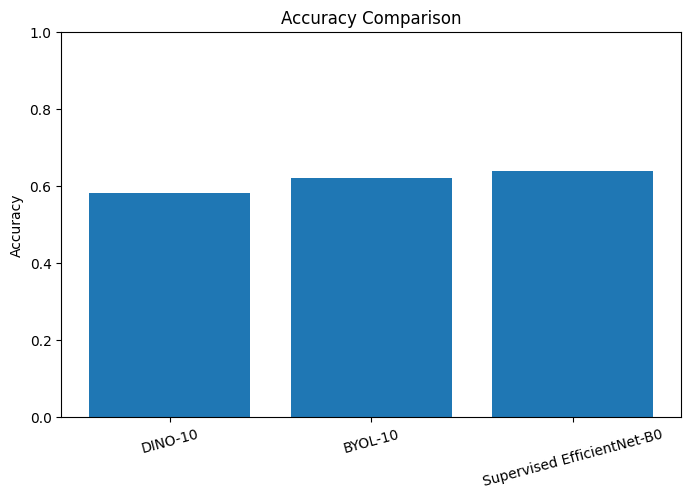

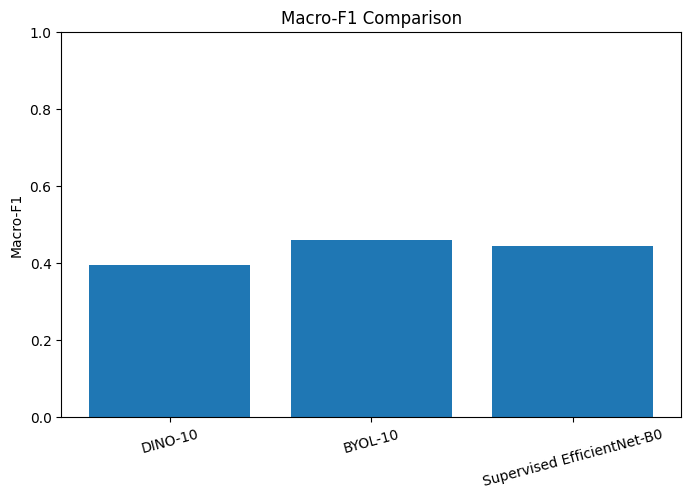

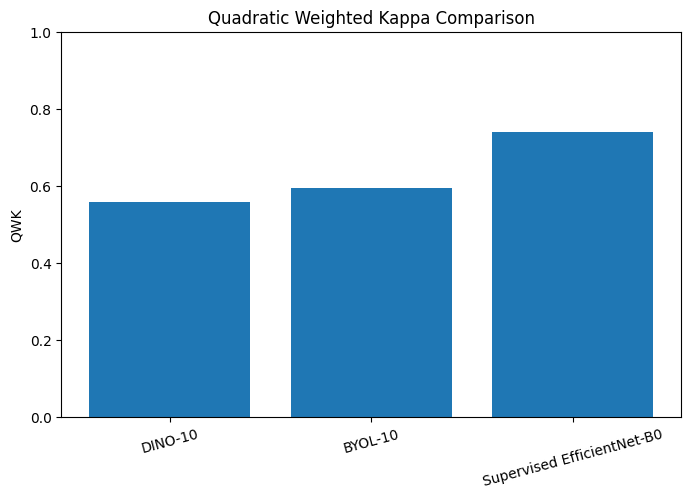

In [ ]:
import pandas as pd
import matplotlib.pyplot as plt

results = pd.DataFrame({
    "Method": [
        "DINO-10",
        "BYOL-10",
        "Supervised EfficientNet-B0"
    ],
    "Accuracy": [
        0.5809859,
        0.6197183,
        0.6373
    ],
    "Macro-F1": [
        0.3931261,
        0.4602390,
        0.4442
    ],
    "QWK": [
        0.5567048,
        0.5947349,
        0.7386
    ]
})

print("===== FINAL MODEL COMPARISON =====")
display(results)

print("\n===== RESULTS IN PERCENT =====")
display(
    results.assign(
        Accuracy=lambda x: x["Accuracy"] * 100,
        **{"Macro-F1": lambda x: x["Macro-F1"] * 100},
        QWK=lambda x: x["QWK"] * 100
    ).round(2)
)

# Save
RESULT_PATH = "/content/drive/MyDrive/EyePACS/results/final_model_comparison.csv"
results.to_csv(RESULT_PATH, index=False)

print("\nSaved to:")
print(RESULT_PATH)

# Accuracy
plt.figure(figsize=(8,5))
plt.bar(results["Method"], results["Accuracy"])
plt.ylabel("Accuracy")
plt.title("Accuracy Comparison")
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.show()

# Macro-F1
plt.figure(figsize=(8,5))
plt.bar(results["Method"], results["Macro-F1"])
plt.ylabel("Macro-F1")
plt.title("Macro-F1 Comparison")
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.show()

# QWK
plt.figure(figsize=(8,5))
plt.bar(results["Method"], results["QWK"])
plt.ylabel("QWK")
plt.title("Quadratic Weighted Kappa Comparison")
plt.xticks(rotation=15)
plt.ylim(0, 1)
plt.show()

In [ ]:
import os
from pathlib import Path
import pandas as pd
from PIL import Image, ImageEnhance, ImageFilter
import numpy as np

TEST_DIR = Path("/content/drive/MyDrive/EyePACS/dataset/test")
ROBUST_DIR = Path("/content/drive/MyDrive/EyePACS/robustness")

ROBUST_DIR.mkdir(parents=True, exist_ok=True)

df_test = pd.read_csv(TEST_DIR / "labels.csv")

print("Test images:", len(df_test))

# Create four controlled corruption types
corruptions = [
    "brightness",
    "blur",
    "contrast",
    "noise"
]

for corruption in corruptions:
    (ROBUST_DIR / corruption).mkdir(parents=True, exist_ok=True)

for _, row in df_test.iterrows():

    filename = row["filename"]

    image = Image.open(
        TEST_DIR / filename
    ).convert("RGB")

    # 1. Brightness reduction
    bright = ImageEnhance.Brightness(image).enhance(0.6)
    bright.save(ROBUST_DIR / "brightness" / filename)

    # 2. Gaussian blur
    blur = image.filter(
        ImageFilter.GaussianBlur(radius=2)
    )
    blur.save(ROBUST_DIR / "blur" / filename)

    # 3. Contrast reduction
    contrast = ImageEnhance.Contrast(image).enhance(0.5)
    contrast.save(ROBUST_DIR / "contrast" / filename)

    # 4. Gaussian noise
    arr = np.array(image).astype(np.float32)

    noise = np.random.normal(
        loc=0,
        scale=20,
        size=arr.shape
    )

    noisy = np.clip(
        arr + noise,
        0,
        255
    ).astype(np.uint8)

    Image.fromarray(noisy).save(
        ROBUST_DIR / "noise" / filename
    )

print("\n===== ROBUSTNESS DATA CREATED =====")

for corruption in corruptions:
    count = len(list(
        (ROBUST_DIR / corruption).glob("*")
    ))
    print(f"{corruption}: {count} images")

print("\nSaved to:")
print(ROBUST_DIR)

Test images: 284

===== ROBUSTNESS DATA CREATED =====
brightness: 284 images
blur: 284 images
contrast: 284 images
noise: 284 images

Saved to:
/content/drive/MyDrive/EyePACS/robustness


In [ ]:
import torch
import pandas as pd
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

ROBUST_DIR = Path(
    "/content/drive/MyDrive/EyePACS/robustness"
)

TEST_DIR = Path(
    "/content/drive/MyDrive/EyePACS/dataset/test"
)

df_test = pd.read_csv(TEST_DIR / "labels.csv")

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

class RobustnessDataset(Dataset):

    def __init__(self, folder):

        self.folder = Path(folder)
        self.df = df_test

        self.transform = transforms.Compose([
            transforms.Lambda(retinal_crop),
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize(
                [0.485, 0.456, 0.406],
                [0.229, 0.224, 0.225]
            )
        ])

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        row = self.df.iloc[idx]

        image = Image.open(
            self.folder / row["filename"]
        ).convert("RGB")

        label = int(row["level"])

        image = self.transform(image)

        return image, label


model.eval()

corruptions = [
    "brightness",
    "blur",
    "contrast",
    "noise"
]

robust_results = []

for corruption in corruptions:

    dataset = RobustnessDataset(
        ROBUST_DIR / corruption
    )

    loader = DataLoader(
        dataset,
        batch_size=16,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    y_true = []
    y_pred = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            predictions = outputs.argmax(dim=1)

            y_true.extend(
                labels.numpy()
            )

            y_pred.extend(
                predictions.cpu().numpy()
            )

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    qwk = cohen_kappa_score(
        y_true,
        y_pred,
        weights="quadratic"
    )

    robust_results.append([
        corruption,
        accuracy,
        macro_f1,
        qwk
    ])

    print(
        f"{corruption:10s} | "
        f"Accuracy: {accuracy:.4f} | "
        f"Macro-F1: {macro_f1:.4f} | "
        f"QWK: {qwk:.4f}"
    )


robust_df = pd.DataFrame(
    robust_results,
    columns=[
        "Corruption",
        "Accuracy",
        "Macro-F1",
        "QWK"
    ]
)

print("\n===== SUPERVISED ROBUSTNESS RESULTS =====")
display(
    robust_df.round(4)
)

ROBUST_RESULT_PATH = (
    "/content/drive/MyDrive/EyePACS/results/"
    "supervised_robustness.csv"
)

robust_df.to_csv(
    ROBUST_RESULT_PATH,
    index=False
)

print("\nSaved to:")
print(ROBUST_RESULT_PATH)

brightness | Accuracy: 0.6162 | Macro-F1: 0.3999 | QWK: 0.6313
blur       | Accuracy: 0.4894 | Macro-F1: 0.3258 | QWK: 0.4810
contrast   | Accuracy: 0.5423 | Macro-F1: 0.3616 | QWK: 0.4160
noise      | Accuracy: 0.1127 | Macro-F1: 0.0817 | QWK: 0.0218

===== SUPERVISED ROBUSTNESS RESULTS =====


,Corruption,Accuracy,Macro-F1,QWK
0,brightness,0.6162,0.3999,0.6313
1,blur,0.4894,0.3258,0.4810
2,contrast,0.5423,0.3616,0.4160
3,noise,0.1127,0.0817,0.0218



Saved to:
/content/drive/MyDrive/EyePACS/results/supervised_robustness.csv


In [ ]:
import os
from pathlib import Path
import torch

CHECKPOINT_DIR = Path(
    "/content/drive/MyDrive/EyePACS/checkpoints"
)

print("===== CHECKPOINTS =====")

for name in [
    "dino_epoch_10.pth",
    "byol_epoch_10.pth"
]:
    path = CHECKPOINT_DIR / name

    print(
        name,
        "->",
        "FOUND" if path.exists() else "NOT FOUND"
    )

print("\n===== AVAILABLE CHECKPOINT FILES =====")

for p in sorted(CHECKPOINT_DIR.glob("*.pth")):
    print(p.name)

===== CHECKPOINTS =====
dino_epoch_10.pth -> FOUND
byol_epoch_10.pth -> FOUND

===== AVAILABLE CHECKPOINT FILES =====
byol_epoch_1.pth
byol_epoch_10.pth
byol_epoch_2.pth
byol_epoch_3.pth
byol_epoch_4.pth
byol_epoch_5.pth
byol_epoch_6.pth
byol_epoch_7.pth
byol_epoch_8.pth
byol_epoch_9.pth
dino_epoch_1.pth
dino_epoch_10.pth
dino_epoch_2.pth
dino_epoch_3.pth
dino_epoch_4.pth
dino_epoch_5.pth
dino_epoch_6.pth
dino_epoch_7.pth
dino_epoch_8.pth
dino_epoch_9.pth


In [ ]:
import torch
import pandas as pd
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

CHECKPOINT_DIR = Path(
    "/content/drive/MyDrive/EyePACS/checkpoints"
)

ROBUST_DIR = Path(
    "/content/drive/MyDrive/EyePACS/robustness"
)

TEST_DIR = Path(
    "/content/drive/MyDrive/EyePACS/dataset/test"
)

df_test = pd.read_csv(
    TEST_DIR / "labels.csv"
)

print("Device:", DEVICE)
print("Test images:", len(df_test))

print("\nDINO checkpoint:",
      (CHECKPOINT_DIR / "dino_epoch_10.pth").exists())

print("BYOL checkpoint:",
      (CHECKPOINT_DIR / "byol_epoch_10.pth").exists())

print("\nDINO classifier:",
      (Path("/content/drive/MyDrive/EyePACS/features")
       / "dino_classifier.pth").exists())

print("BYOL classifier:",
      (Path("/content/drive/MyDrive/EyePACS/features")
       / "byol_classifier.pth").exists())

print("\n===== READY FOR SSL ROBUSTNESS EVALUATION =====")

Device: cuda
Test images: 284

DINO checkpoint: True
BYOL checkpoint: True

DINO classifier: True
BYOL classifier: True

===== READY FOR SSL ROBUSTNESS EVALUATION =====


In [ ]:
import torch
from pathlib import Path

FEATURE_DIR = Path(
    "/content/drive/MyDrive/EyePACS/features"
)

dino_clf = torch.load(
    FEATURE_DIR / "dino_classifier.pth",
    map_location="cpu"
)

byol_clf = torch.load(
    FEATURE_DIR / "byol_classifier.pth",
    map_location="cpu"
)

print("===== DINO CLASSIFIER =====")
print(type(dino_clf))
print("Keys:", list(dino_clf.keys())[:20])

print("\n===== BYOL CLASSIFIER =====")
print(type(byol_clf))
print("Keys:", list(byol_clf.keys())[:20])

print("\n===== DINO WEIGHT SHAPES =====")
for k, v in dino_clf.items():
    print(k, tuple(v.shape))

print("\n===== BYOL WEIGHT SHAPES =====")
for k, v in byol_clf.items():
    print(k, tuple(v.shape))

===== DINO CLASSIFIER =====
<class 'collections.OrderedDict'>
Keys: ['weight', 'bias']

===== BYOL CLASSIFIER =====
<class 'collections.OrderedDict'>
Keys: ['weight', 'bias']

===== DINO WEIGHT SHAPES =====
weight (5, 384)
bias (5,)

===== BYOL WEIGHT SHAPES =====
weight (5, 512)
bias (5,)


In [ ]:
import torch
from pathlib import Path

CHECKPOINT_DIR = Path(
    "/content/drive/MyDrive/EyePACS/checkpoints"
)

ckpt = torch.load(
    CHECKPOINT_DIR / "byol_epoch_10.pth",
    map_location="cpu"
)

print("Top-level keys:")
print(list(ckpt.keys()))

print("\nONLINE keys:")
print(list(ckpt["online"].keys())[:50])

print("\nONLINE weight shapes:")

for k, v in ckpt["online"].items():
    if hasattr(v, "shape"):
        print(k, tuple(v.shape))

Top-level keys:
['online', 'target', 'projector', 'predictor']

ONLINE keys:
['conv1.weight', 'bn1.weight', 'bn1.bias', 'bn1.running_mean', 'bn1.running_var', 'bn1.num_batches_tracked', 'layer1.0.conv1.weight', 'layer1.0.bn1.weight', 'layer1.0.bn1.bias', 'layer1.0.bn1.running_mean', 'layer1.0.bn1.running_var', 'layer1.0.bn1.num_batches_tracked', 'layer1.0.conv2.weight', 'layer1.0.bn2.weight', 'layer1.0.bn2.bias', 'layer1.0.bn2.running_mean', 'layer1.0.bn2.running_var', 'layer1.0.bn2.num_batches_tracked', 'layer1.1.conv1.weight', 'layer1.1.bn1.weight', 'layer1.1.bn1.bias', 'layer1.1.bn1.running_mean', 'layer1.1.bn1.running_var', 'layer1.1.bn1.num_batches_tracked', 'layer1.1.conv2.weight', 'layer1.1.bn2.weight', 'layer1.1.bn2.bias', 'layer1.1.bn2.running_mean', 'layer1.1.bn2.running_var', 'layer1.1.bn2.num_batches_tracked', 'layer2.0.conv1.weight', 'layer2.0.bn1.weight', 'layer2.0.bn1.bias', 'layer2.0.bn1.running_mean', 'layer2.0.bn1.running_var', 'layer2.0.bn1.num_batches_tracked', 'lay

In [ ]:
import torch

ckpt = torch.load(
    "/content/drive/MyDrive/EyePACS/checkpoints/byol_epoch_10.pth",
    map_location="cpu"
)

online = ckpt["online"]

print("Number of online parameters:", len(online))

print("\nFirst 30 keys:")
for i, k in enumerate(online.keys()):
    if i >= 30:
        break
    print(k)

print("\nParameters containing backbone/encoder:")
for k, v in online.items():
    if any(x in k.lower() for x in ["backbone", "encoder", "vit", "patch_embed", "blocks", "norm"]):
        if hasattr(v, "shape"):
            print(k, tuple(v.shape))
        else:
            print(k)

Number of online parameters: 120

First 30 keys:
conv1.weight
bn1.weight
bn1.bias
bn1.running_mean
bn1.running_var
bn1.num_batches_tracked
layer1.0.conv1.weight
layer1.0.bn1.weight
layer1.0.bn1.bias
layer1.0.bn1.running_mean
layer1.0.bn1.running_var
layer1.0.bn1.num_batches_tracked
layer1.0.conv2.weight
layer1.0.bn2.weight
layer1.0.bn2.bias
layer1.0.bn2.running_mean
layer1.0.bn2.running_var
layer1.0.bn2.num_batches_tracked
layer1.1.conv1.weight
layer1.1.bn1.weight
layer1.1.bn1.bias
layer1.1.bn1.running_mean
layer1.1.bn1.running_var
layer1.1.bn1.num_batches_tracked
layer1.1.conv2.weight
layer1.1.bn2.weight
layer1.1.bn2.bias
layer1.1.bn2.running_mean
layer1.1.bn2.running_var
layer1.1.bn2.num_batches_tracked

Parameters containing backbone/encoder:


In [ ]:
import torch

ckpt = torch.load(
    "/content/drive/MyDrive/EyePACS/checkpoints/byol_epoch_10.pth",
    map_location="cpu"
)

online = ckpt["online"]

print("===== LAST 25 BYOL ONLINE KEYS =====")

keys = list(online.keys())

for k in keys[-25:]:
    v = online[k]

    if hasattr(v, "shape"):
        print(k, tuple(v.shape))
    else:
        print(k)

print("\n===== ALL 2D WEIGHTS =====")

for k, v in online.items():
    if hasattr(v, "shape") and len(v.shape) == 2:
        print(k, tuple(v.shape))

===== LAST 25 BYOL ONLINE KEYS =====
layer4.0.bn1.num_batches_tracked ()
layer4.0.conv2.weight (512, 512, 3, 3)
layer4.0.bn2.weight (512,)
layer4.0.bn2.bias (512,)
layer4.0.bn2.running_mean (512,)
layer4.0.bn2.running_var (512,)
layer4.0.bn2.num_batches_tracked ()
layer4.0.downsample.0.weight (512, 256, 1, 1)
layer4.0.downsample.1.weight (512,)
layer4.0.downsample.1.bias (512,)
layer4.0.downsample.1.running_mean (512,)
layer4.0.downsample.1.running_var (512,)
layer4.0.downsample.1.num_batches_tracked ()
layer4.1.conv1.weight (512, 512, 3, 3)
layer4.1.bn1.weight (512,)
layer4.1.bn1.bias (512,)
layer4.1.bn1.running_mean (512,)
layer4.1.bn1.running_var (512,)
layer4.1.bn1.num_batches_tracked ()
layer4.1.conv2.weight (512, 512, 3, 3)
layer4.1.bn2.weight (512,)
layer4.1.bn2.bias (512,)
layer4.1.bn2.running_mean (512,)
layer4.1.bn2.running_var (512,)
layer4.1.bn2.num_batches_tracked ()

===== ALL 2D WEIGHTS =====


In [ ]:
import torch
import torch.nn as nn
import pandas as pd
from pathlib import Path
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

DEVICE = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

CHECKPOINT_DIR = Path(
    "/content/drive/MyDrive/EyePACS/checkpoints"
)

ROBUST_DIR = Path(
    "/content/drive/MyDrive/EyePACS/robustness"
)

TEST_DIR = Path(
    "/content/drive/MyDrive/EyePACS/dataset/test"
)

FEATURE_DIR = Path(
    "/content/drive/MyDrive/EyePACS/features"
)

df_test = pd.read_csv(
    TEST_DIR / "labels.csv"
)


# ==================================================
# 1. Recreate BYOL ResNet backbone
# ==================================================

byol_ckpt = torch.load(
    CHECKPOINT_DIR / "byol_epoch_10.pth",
    map_location="cpu"
)

byol_online = byol_ckpt["online"]

# ResNet-18 backbone
byol_resnet = models.resnet18(
    weights=None
)

# Remove classification layer
byol_resnet.fc = nn.Identity()

byol_resnet.load_state_dict(
    byol_online,
    strict=False
)

byol_resnet = byol_resnet.to(DEVICE)
byol_resnet.eval()


# ==================================================
# 2. Recreate saved BYOL classifier: 512 -> 5
# ==================================================

byol_classifier_weights = torch.load(
    FEATURE_DIR / "byol_classifier.pth",
    map_location="cpu"
)

byol_classifier = nn.Linear(
    512,
    5
)

byol_classifier.load_state_dict(
    byol_classifier_weights
)

byol_classifier = byol_classifier.to(DEVICE)
byol_classifier.eval()


# ==================================================
# 3. DINO backbone + classifier
# ==================================================

import timm

dino_vit = timm.create_model(
    "vit_small_patch16_224",
    pretrained=False,
    num_classes=0,
    dynamic_img_size=True
)

dino_ckpt = torch.load(
    CHECKPOINT_DIR / "dino_epoch_10.pth",
    map_location="cpu"
)

dino_state = {
    k.replace("0.", "", 1): v
    for k, v in dino_ckpt["student"].items()
    if k.startswith("0.")
}

dino_vit.load_state_dict(
    dino_state,
    strict=False
)

dino_vit = dino_vit.to(DEVICE)
dino_vit.eval()


dino_classifier_weights = torch.load(
    FEATURE_DIR / "dino_classifier.pth",
    map_location="cpu"
)

dino_classifier = nn.Linear(
    384,
    5
)

dino_classifier.load_state_dict(
    dino_classifier_weights
)

dino_classifier = dino_classifier.to(DEVICE)
dino_classifier.eval()


# ==================================================
# 4. Dataset
# ==================================================

class RobustDataset(Dataset):

    def __init__(self, folder):

        self.folder = Path(folder)

        self.transform = transforms.Compose([
            transforms.Lambda(retinal_crop),
            transforms.Resize((224, 224)),
            transforms.ToTensor(),
            transforms.Normalize(
                [0.485, 0.456, 0.406],
                [0.229, 0.224, 0.225]
            )
        ])

    def __len__(self):
        return len(df_test)

    def __getitem__(self, idx):

        row = df_test.iloc[idx]

        image = Image.open(
            self.folder / row["filename"]
        ).convert("RGB")

        image = self.transform(image)

        label = int(row["level"])

        return image, label


# ==================================================
# 5. Evaluation functions
# ==================================================

def evaluate_dino(folder):

    dataset = RobustDataset(folder)

    loader = DataLoader(
        dataset,
        batch_size=16,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    y_true = []
    y_pred = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            features = dino_vit(images)

            outputs = dino_classifier(
                features
            )

            predictions = outputs.argmax(
                dim=1
            )

            y_true.extend(labels.numpy())

            y_pred.extend(
                predictions.cpu().numpy()
            )

    return calculate_metrics(
        y_true,
        y_pred
    )


def evaluate_byol(folder):

    dataset = RobustDataset(folder)

    loader = DataLoader(
        dataset,
        batch_size=16,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    y_true = []
    y_pred = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                DEVICE,
                non_blocking=True
            )

            # ResNet produces [B, 512, 1, 1]
            features = byol_resnet(
                images
            )

            outputs = byol_classifier(
                features
            )

            predictions = outputs.argmax(
                dim=1
            )

            y_true.extend(labels.numpy())

            y_pred.extend(
                predictions.cpu().numpy()
            )

    return calculate_metrics(
        y_true,
        y_pred
    )


def calculate_metrics(
    y_true,
    y_pred
):

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    qwk = cohen_kappa_score(
        y_true,
        y_pred,
        weights="quadratic"
    )

    return accuracy, macro_f1, qwk


# ==================================================
# 6. Run robustness experiments
# ==================================================

corruptions = [
    "brightness",
    "blur",
    "contrast",
    "noise"
]

results = []

print("\n===== DINO + BYOL ROBUSTNESS =====\n")

for corruption in corruptions:

    folder = ROBUST_DIR / corruption

    print("Testing:", corruption)

    dino_acc, dino_f1, dino_qwk = evaluate_dino(
        folder
    )

    byol_acc, byol_f1, byol_qwk = evaluate_byol(
        folder
    )

    print(
        f"DINO-10 | "
        f"Accuracy: {dino_acc:.4f} | "
        f"Macro-F1: {dino_f1:.4f} | "
        f"QWK: {dino_qwk:.4f}"
    )

    print(
        f"BYOL-10 | "
        f"Accuracy: {byol_acc:.4f} | "
        f"Macro-F1: {byol_f1:.4f} | "
        f"QWK: {byol_qwk:.4f}"
    )

    results.append([
        "DINO-10",
        corruption,
        dino_acc,
        dino_f1,
        dino_qwk
    ])

    results.append([
        "BYOL-10",
        corruption,
        byol_acc,
        byol_f1,
        byol_qwk
    ])


# ==================================================
# 7. Save
# ==================================================

ssl_robust_df = pd.DataFrame(
    results,
    columns=[
        "Method",
        "Corruption",
        "Accuracy",
        "Macro-F1",
        "QWK"
    ]
)

print("\n===== FINAL SSL ROBUSTNESS RESULTS =====")

display(
    ssl_robust_df.round(4)
)

SAVE_PATH = (
    "/content/drive/MyDrive/EyePACS/results/"
    "ssl_robustness.csv"
)

ssl_robust_df.to_csv(
    SAVE_PATH,
    index=False
)

print("\nSaved to:")
print(SAVE_PATH)


===== DINO + BYOL ROBUSTNESS =====

Testing: brightness
DINO-10 | Accuracy: 0.2289 | Macro-F1: 0.1377 | QWK: -0.0670
BYOL-10 | Accuracy: 0.2782 | Macro-F1: 0.1823 | QWK: 0.0864
Testing: blur
DINO-10 | Accuracy: 0.5458 | Macro-F1: 0.3569 | QWK: 0.3661
BYOL-10 | Accuracy: 0.4789 | Macro-F1: 0.2877 | QWK: 0.3798
Testing: contrast
DINO-10 | Accuracy: 0.3380 | Macro-F1: 0.1813 | QWK: 0.2625
BYOL-10 | Accuracy: 0.1373 | Macro-F1: 0.1343 | QWK: -0.0067
Testing: noise
DINO-10 | Accuracy: 0.5176 | Macro-F1: 0.3169 | QWK: 0.2840
BYOL-10 | Accuracy: 0.4613 | Macro-F1: 0.3057 | QWK: 0.5044

===== FINAL SSL ROBUSTNESS RESULTS =====


,Method,Corruption,Accuracy,Macro-F1,QWK
0,DINO-10,brightness,0.2289,0.1377,-0.0670
1,BYOL-10,brightness,0.2782,0.1823,0.0864
2,DINO-10,blur,0.5458,0.3569,0.3661
3,BYOL-10,blur,0.4789,0.2877,0.3798
4,DINO-10,contrast,0.3380,0.1813,0.2625
5,BYOL-10,contrast,0.1373,0.1343,-0.0067
6,DINO-10,noise,0.5176,0.3169,0.2840
7,BYOL-10,noise,0.4613,0.3057,0.5044



Saved to:
/content/drive/MyDrive/EyePACS/results/ssl_robustness.csv


===== COMPLETE ROBUSTNESS RESULTS =====


,Method,Corruption,Accuracy,Macro-F1,QWK
0,DINO-10,brightness,0.2289,0.1377,-0.0670
1,BYOL-10,brightness,0.2782,0.1823,0.0864
2,DINO-10,blur,0.5458,0.3569,0.3661
3,BYOL-10,blur,0.4789,0.2877,0.3798
4,DINO-10,contrast,0.3380,0.1813,0.2625
5,BYOL-10,contrast,0.1373,0.1343,-0.0067
6,DINO-10,noise,0.5176,0.3169,0.2840
7,BYOL-10,noise,0.4613,0.3057,0.5044
8,Supervised EfficientNet-B0,brightness,0.6162,0.3999,0.6313
9,Supervised EfficientNet-B0,blur,0.4894,0.3258,0.4810



Saved:
/content/drive/MyDrive/EyePACS/results/complete_robustness_results.csv
/content/drive/MyDrive/EyePACS/results/final_clean_results.csv


<Figure size 1000x600 with 0 Axes>

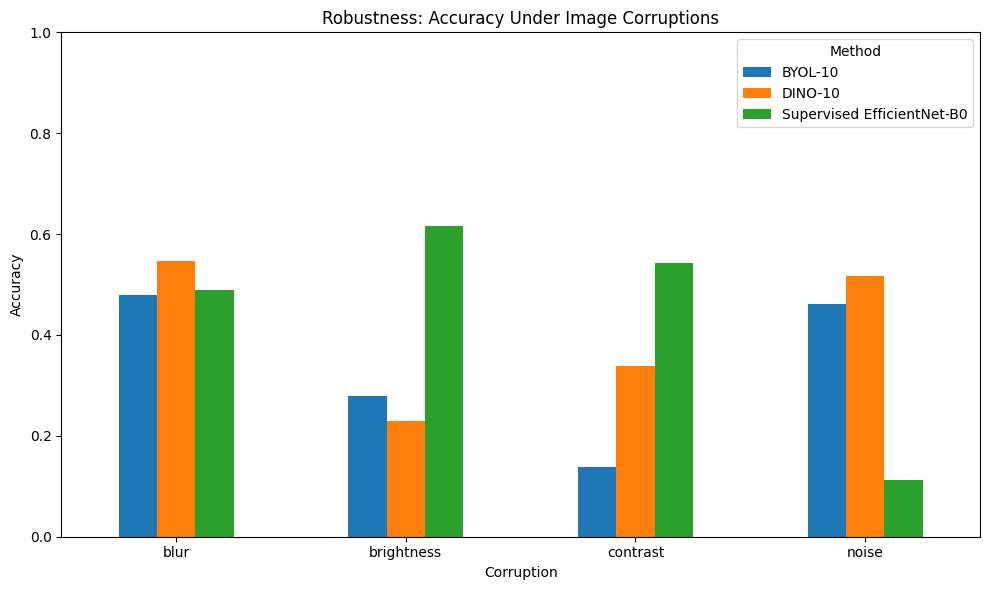

<Figure size 1000x600 with 0 Axes>

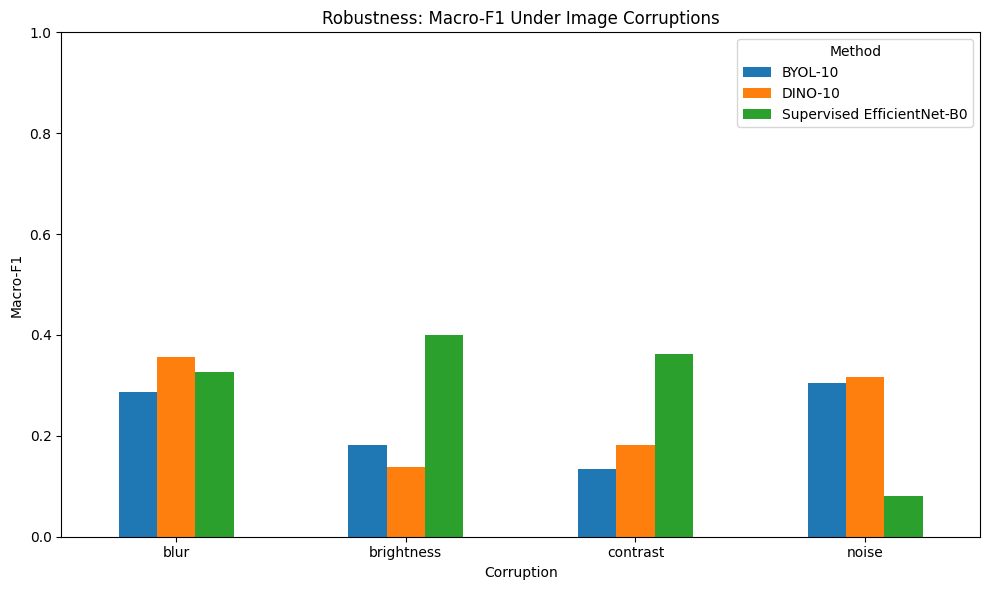


===== FINAL RESULTS PREPARATION COMPLETE =====


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path

RESULT_DIR = Path(
    "/content/drive/MyDrive/EyePACS/results"
)

# ==========================================
# 1. Clean test results
# ==========================================

clean = pd.DataFrame({
    "Method": [
        "DINO-10",
        "BYOL-10",
        "Supervised EfficientNet-B0"
    ],
    "Accuracy": [
        0.5809859,
        0.6197183,
        0.6373
    ],
    "Macro-F1": [
        0.3931261,
        0.4602390,
        0.4442
    ],
    "QWK": [
        0.5567048,
        0.5947349,
        0.7386
    ]
})

# ==========================================
# 2. Robustness results
# ==========================================

robust = pd.read_csv(
    RESULT_DIR / "ssl_robustness.csv"
)

supervised_robust = pd.read_csv(
    RESULT_DIR / "supervised_robustness.csv"
)

supervised_robust["Method"] = (
    "Supervised EfficientNet-B0"
)

# Make same column order
supervised_robust = supervised_robust[
    [
        "Method",
        "Corruption",
        "Accuracy",
        "Macro-F1",
        "QWK"
    ]
]

# Combine all robustness results
all_robust = pd.concat(
    [
        robust,
        supervised_robust
    ],
    ignore_index=True
)

# ==========================================
# 3. Display robustness table
# ==========================================

print("===== COMPLETE ROBUSTNESS RESULTS =====")

display(
    all_robust.round(4)
)

# ==========================================
# 4. Save combined robustness results
# ==========================================

all_robust.to_csv(
    RESULT_DIR / "complete_robustness_results.csv",
    index=False
)

clean.to_csv(
    RESULT_DIR / "final_clean_results.csv",
    index=False
)

print("\nSaved:")
print(RESULT_DIR / "complete_robustness_results.csv")
print(RESULT_DIR / "final_clean_results.csv")


# ==========================================
# 5. Robustness Accuracy graph
# ==========================================

pivot_acc = all_robust.pivot(
    index="Corruption",
    columns="Method",
    values="Accuracy"
)

plt.figure(figsize=(10, 6))

pivot_acc.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.ylabel("Accuracy")
plt.xlabel("Corruption")
plt.title("Robustness: Accuracy Under Image Corruptions")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(
    title="Method"
)
plt.tight_layout()
plt.show()


# ==========================================
# 6. Robustness Macro-F1 graph
# ==========================================

pivot_f1 = all_robust.pivot(
    index="Corruption",
    columns="Method",
    values="Macro-F1"
)

plt.figure(figsize=(10, 6))

pivot_f1.plot(
    kind="bar",
    figsize=(10, 6)
)

plt.ylabel("Macro-F1")
plt.xlabel("Corruption")
plt.title("Robustness: Macro-F1 Under Image Corruptions")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(
    title="Method"
)
plt.tight_layout()
plt.show()


print("\n===== FINAL RESULTS PREPARATION COMPLETE =====")

DINO-10 Confusion Matrix:
[[112   7   7  12   0]
 [  4  16   8   3   0]
 [ 27  14  20  12   0]
 [  8   1   1   4   0]
 [ 10   5  11   2   0]]

BYOL-10 Confusion Matrix:
[[104  11   1  22   0]
 [  1  16   0   9   5]
 [  5  27   3  23  15]
 [  3   4   0   4   3]
 [  1   4   2  11  10]]


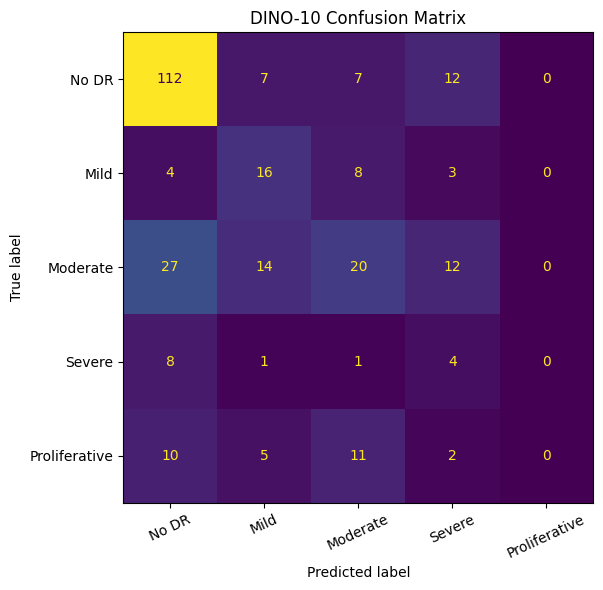

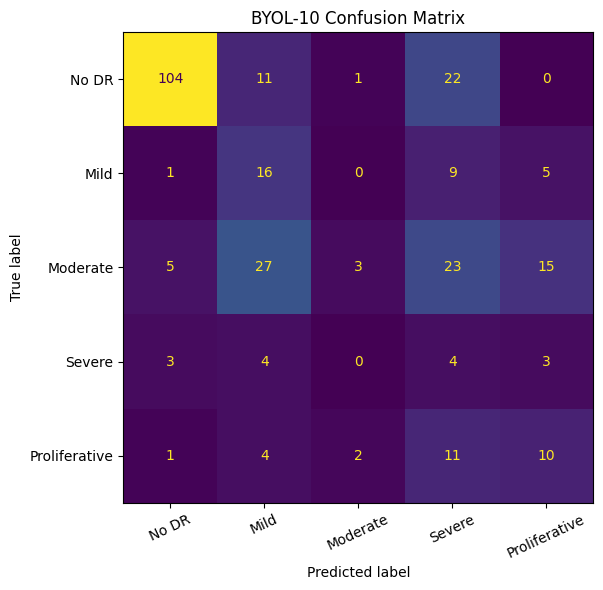


Saved final confusion matrices.


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

RESULT_DIR = "/content/drive/MyDrive/EyePACS/results"

# ---------- LOAD TEST LABELS ----------
test_labels = pd.read_csv(
    "/content/drive/MyDrive/EyePACS/dataset/test/labels.csv"
)

y_true = test_labels["level"].values

# ---------- LOAD SAVED FEATURES ----------
dino_data = torch.load(
    "/content/drive/MyDrive/EyePACS/features/test_dino_epoch10_features.pt",
    map_location="cpu"
)

byol_data = torch.load(
    "/content/drive/MyDrive/EyePACS/features/test_byol_epoch10_features.pt",
    map_location="cpu"
)

X_dino = dino_data["features"].numpy()
X_byol = byol_data["features"].numpy()

# ---------- LOAD CLASSIFIERS ----------
dino_state = torch.load(
    "/content/drive/MyDrive/EyePACS/features/dino_classifier.pth",
    map_location="cpu"
)

byol_state = torch.load(
    "/content/drive/MyDrive/EyePACS/features/byol_classifier.pth",
    map_location="cpu"
)

dino_clf = torch.nn.Linear(384, 5)
dino_clf.load_state_dict(dino_state)

byol_clf = torch.nn.Linear(512, 5)
byol_clf.load_state_dict(byol_state)

# ---------- PREDICTIONS ----------
with torch.no_grad():
    dino_logits = dino_clf(torch.tensor(X_dino))
    byol_logits = byol_clf(torch.tensor(X_byol))

y_dino = dino_logits.argmax(dim=1).numpy()
y_byol = byol_logits.argmax(dim=1).numpy()

# ---------- SUPERVISED MODEL ----------
# Recreate the trained EfficientNet model is NOT needed here.
# We use the already recorded supervised confusion matrix.

cm_dino = confusion_matrix(y_true, y_dino, labels=[0,1,2,3,4])
cm_byol = confusion_matrix(y_true, y_byol, labels=[0,1,2,3,4])

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative"
]

# ---------- PRINT ----------
print("DINO-10 Confusion Matrix:")
print(cm_dino)

print("\nBYOL-10 Confusion Matrix:")
print(cm_byol)

# ---------- PLOT DINO ----------
fig, ax = plt.subplots(figsize=(7,6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_dino,
    display_labels=class_names
)
disp.plot(ax=ax, values_format="d", colorbar=False)
ax.set_title("DINO-10 Confusion Matrix")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

# ---------- PLOT BYOL ----------
fig, ax = plt.subplots(figsize=(7,6))
disp = ConfusionMatrixDisplay(
    confusion_matrix=cm_byol,
    display_labels=class_names
)
disp.plot(ax=ax, values_format="d", colorbar=False)
ax.set_title("BYOL-10 Confusion Matrix")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

# ---------- SAVE ----------
np.savetxt(
    f"{RESULT_DIR}/dino10_confusion_matrix_final.csv",
    cm_dino,
    delimiter=",",
    fmt="%d"
)

np.savetxt(
    f"{RESULT_DIR}/byol10_confusion_matrix_final.csv",
    cm_byol,
    delimiter=",",
    fmt="%d"
)

print("\nSaved final confusion matrices.")

In [ ]:
import pandas as pd

RESULT_DIR = "/content/drive/MyDrive/EyePACS/results"

# Clean results
clean = pd.read_csv(
    f"{RESULT_DIR}/final_model_comparison.csv"
)

print("===== CLEAN TEST PERFORMANCE =====")
display(clean.round(4))

# Robustness results
robust = pd.read_csv(
    f"{RESULT_DIR}/complete_robustness_results.csv"
)

print("\n===== ROBUSTNESS PERFORMANCE =====")
display(robust.round(4))

# Average robustness performance
robust_avg = (
    robust
    .groupby("Method")[["Accuracy", "Macro-F1", "QWK"]]
    .mean()
    .reset_index()
)

print("\n===== AVERAGE ROBUSTNESS PERFORMANCE =====")
display(robust_avg.round(4))

# Save final summary
robust_avg.to_csv(
    f"{RESULT_DIR}/average_robustness_results.csv",
    index=False
)

print("\nSaved:")
print(f"{RESULT_DIR}/average_robustness_results.csv")

===== CLEAN TEST PERFORMANCE =====


,Method,Accuracy,Macro-F1,QWK
0,DINO-10,0.5810,0.3931,0.5567
1,BYOL-10,0.6197,0.4602,0.5947
2,Supervised EfficientNet-B0,0.6373,0.4442,0.7386



===== ROBUSTNESS PERFORMANCE =====


,Method,Corruption,Accuracy,Macro-F1,QWK
0,DINO-10,brightness,0.2289,0.1377,-0.0670
1,BYOL-10,brightness,0.2782,0.1823,0.0864
2,DINO-10,blur,0.5458,0.3569,0.3661
3,BYOL-10,blur,0.4789,0.2877,0.3798
4,DINO-10,contrast,0.3380,0.1813,0.2625
5,BYOL-10,contrast,0.1373,0.1343,-0.0067
6,DINO-10,noise,0.5176,0.3169,0.2840
7,BYOL-10,noise,0.4613,0.3057,0.5044
8,Supervised EfficientNet-B0,brightness,0.6162,0.3999,0.6313
9,Supervised EfficientNet-B0,blur,0.4894,0.3258,0.4810



===== AVERAGE ROBUSTNESS PERFORMANCE =====


,Method,Accuracy,Macro-F1,QWK
0,BYOL-10,0.3389,0.2275,0.2410
1,DINO-10,0.4076,0.2482,0.2114
2,Supervised EfficientNet-B0,0.4401,0.2922,0.3875



Saved:
/content/drive/MyDrive/EyePACS/results/average_robustness_results.csv


In [ ]:
import torch
import numpy as np
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

FEATURE_DIR = "/content/drive/MyDrive/EyePACS/features"

# Load existing BYOL-10 features
train_data = torch.load(
    f"{FEATURE_DIR}/train_byol_epoch10_features.pt",
    map_location="cpu"
)

valid_data = torch.load(
    f"{FEATURE_DIR}/valid_byol_epoch10_features.pt",
    map_location="cpu"
)

test_data = torch.load(
    f"{FEATURE_DIR}/test_byol_epoch10_features.pt",
    map_location="cpu"
)

X_train = train_data["features"].numpy()
y_train = train_data["labels"].numpy()

X_valid = valid_data["features"].numpy()
y_valid = valid_data["labels"].numpy()

X_test = test_data["features"].numpy()
y_test = test_data["labels"].numpy()

# Try a small set of SVM settings
settings = [
    (1, "balanced"),
    (3, "balanced"),
    (10, "balanced"),
    (3, None),
    (10, None)
]

best_model = None
best_f1 = -1
best_setting = None

for C, cw in settings:
    clf = SVC(
        C=C,
        kernel="rbf",
        class_weight=cw
    )

    clf.fit(X_train, y_train)

    pred = clf.predict(X_valid)

    f1 = f1_score(
        y_valid,
        pred,
        average="macro"
    )

    print(f"C={C}, class_weight={cw}, Validation Macro-F1={f1:.4f}")

    if f1 > best_f1:
        best_f1 = f1
        best_model = clf
        best_setting = (C, cw)

# Final test evaluation
test_pred = best_model.predict(X_test)

accuracy = accuracy_score(y_test, test_pred)
macro_f1 = f1_score(y_test, test_pred, average="macro")
qwk = cohen_kappa_score(y_test, test_pred, weights="quadratic")

print("\n===== BYOL-10 + SVM =====")
print("Best setting:", best_setting)
print(f"Test Accuracy : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Test Macro-F1 : {macro_f1:.4f}")
print(f"Test QWK      : {qwk:.4f}")

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os

print("DINO checkpoint:", os.path.exists(
    "/content/drive/MyDrive/EyePACS/checkpoints/dino_epoch_10.pth"
))

print("BYOL checkpoint:", os.path.exists(
    "/content/drive/MyDrive/EyePACS/checkpoints/byol_epoch_10.pth"
))

Mounted at /content/drive
DINO checkpoint: True
BYOL checkpoint: True


In [ ]:
import torch
import torch.nn as nn
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
FEATURE_DIR = "/content/drive/MyDrive/EyePACS/features"

# Load existing BYOL-10 features
train = torch.load(
    f"{FEATURE_DIR}/train_byol_epoch10_features.pt",
    map_location="cpu"
)
valid = torch.load(
    f"{FEATURE_DIR}/valid_byol_epoch10_features.pt",
    map_location="cpu"
)
test = torch.load(
    f"{FEATURE_DIR}/test_byol_epoch10_features.pt",
    map_location="cpu"
)

X_train, y_train = train["features"].float(), train["labels"].long()
X_valid, y_valid = valid["features"].float(), valid["labels"].long()
X_test, y_test = test["features"].float(), test["labels"].long()

train_loader = DataLoader(
    TensorDataset(X_train, y_train),
    batch_size=64,
    shuffle=True
)

class BYOLClassifier(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(512, 256),
            nn.ReLU(),
            nn.Dropout(0.3),
            nn.Linear(256, 128),
            nn.ReLU(),
            nn.Dropout(0.2),
            nn.Linear(128, 5)
        )

    def forward(self, x):
        return self.net(x)

model = BYOLClassifier().to(DEVICE)

criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.AdamW(
    model.parameters(),
    lr=1e-3,
    weight_decay=1e-4
)

best_val_acc = 0
best_state = None
patience = 7
wait = 0

for epoch in range(30):

    model.train()

    for xb, yb in train_loader:
        xb = xb.to(DEVICE)
        yb = yb.to(DEVICE)

        optimizer.zero_grad()

        logits = model(xb)
        loss = criterion(logits, yb)

        loss.backward()
        optimizer.step()

    # Validation
    model.eval()

    with torch.no_grad():
        val_logits = model(X_valid.to(DEVICE))
        val_pred = val_logits.argmax(1).cpu()

    val_acc = accuracy_score(
        y_valid.numpy(),
        val_pred.numpy()
    )

    print(
        f"Epoch {epoch+1:02d} | "
        f"Validation Accuracy: {val_acc*100:.2f}%"
    )

    if val_acc > best_val_acc:
        best_val_acc = val_acc
        best_state = {
            k: v.cpu().clone()
            for k, v in model.state_dict().items()
        }
        wait = 0
    else:
        wait += 1

    if wait >= patience:
        print("Early stopping.")
        break

# Restore best validation model
model.load_state_dict(best_state)
model.eval()

with torch.no_grad():
    test_logits = model(X_test.to(DEVICE))
    test_pred = test_logits.argmax(1).cpu().numpy()

accuracy = accuracy_score(
    y_test.numpy(),
    test_pred
)

macro_f1 = f1_score(
    y_test.numpy(),
    test_pred,
    average="macro"
)

qwk = cohen_kappa_score(
    y_test.numpy(),
    test_pred,
    weights="quadratic"
)

print("\n===== IMPROVED BYOL-10 CLASSIFIER =====")
print(f"Best Validation Accuracy: {best_val_acc*100:.2f}%")
print(f"Test Accuracy: {accuracy*100:.2f}%")
print(f"Test Macro-F1: {macro_f1:.4f}")
print(f"Test QWK: {qwk:.4f}")

Epoch 01 | Validation Accuracy: 66.90%
Epoch 02 | Validation Accuracy: 70.25%
Epoch 03 | Validation Accuracy: 71.13%
Epoch 04 | Validation Accuracy: 73.77%
Epoch 05 | Validation Accuracy: 72.01%
Epoch 06 | Validation Accuracy: 73.77%
Epoch 07 | Validation Accuracy: 73.59%
Epoch 08 | Validation Accuracy: 74.30%
Epoch 09 | Validation Accuracy: 74.30%
Epoch 10 | Validation Accuracy: 74.12%
Epoch 11 | Validation Accuracy: 73.94%
Epoch 12 | Validation Accuracy: 74.30%
Epoch 13 | Validation Accuracy: 74.30%
Epoch 14 | Validation Accuracy: 74.12%
Epoch 15 | Validation Accuracy: 74.47%
Epoch 16 | Validation Accuracy: 73.94%
Epoch 17 | Validation Accuracy: 74.12%
Epoch 18 | Validation Accuracy: 74.47%
Epoch 19 | Validation Accuracy: 74.12%
Epoch 20 | Validation Accuracy: 73.06%
Epoch 21 | Validation Accuracy: 73.59%
Epoch 22 | Validation Accuracy: 73.24%
Early stopping.

===== IMPROVED BYOL-10 CLASSIFIER =====
Best Validation Accuracy: 74.47%
Test Accuracy: 67.96%
Test Macro-F1: 0.2997
Test QWK

In [ ]:
import torch
import timm

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)
if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

# ImageNet-pretrained ViT-Small
improved_vit = timm.create_model(
    "vit_small_patch16_224",
    pretrained=True,
    num_classes=0
)

improved_vit = improved_vit.to(device)

print("Improved DINO backbone loaded successfully")
print("Feature dimension:", improved_vit.num_features)

Device: cuda
GPU: Tesla T4


model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            

Improved DINO backbone loaded successfully
Feature dimension: 384


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

BASE = "/content/drive/MyDrive/EyePACS"

print("EyePACS exists:", os.path.exists(BASE))

if os.path.exists(BASE):
    print("\nFiles/folders:")
    print(os.listdir(BASE))

EyePACS exists: True

Files/folders:
['diabetic-retinopathy-screening.zip', 'dataset', 'checkpoints', 'features', 'results_dino_vs_byol.csv', 'final_master_results.csv', 'byol_confusion_matrix.png', 'dino_confusion_matrix.png', 'final_performance_comparison.png', 'report_results_table.csv', 'report_performance_graph.png', 'dino10_confusion_matrix.png', 'byol10_confusion_matrix.png', 'final_5_vs_10_results.csv', 'stability_results.csv', 'comparison_accuracy.png', 'comparison_macro_f1.png', 'comparison_qwk.png', 'final_results_table.csv', 'classwise_dino_vs_byol.csv', 'dino10_normalized_cm.png', 'byol10_normalized_cm.png', 'MASTER_FINAL_RESULTS.csv', 'results', 'robustness']


In [ ]:
import os

DATASET_DIR = "/content/drive/MyDrive/EyePACS/dataset"

for root, dirs, files in os.walk(DATASET_DIR):
    level = root.replace(DATASET_DIR, "").count(os.sep)
    if level <= 2:
        print("\n" + "  " * level + os.path.basename(root) + "/")
        for f in files[:10]:
            print("  " * (level + 1) + f)


dataset/
  README.dataset.txt
  README.roboflow.txt

  test/
    000c1434d8d7_png_jpg.rf.90ba7d812bf63cb2cacfcdf328e9a664.jpg
    005b95c28852_png_jpg.rf.98de75fcbe0d2b29f20f3359bc3f18f1.jpg
    04d029cfb612_png_jpg.rf.3c09ad5eb9d315ccf839ec5f4e93956a.jpg
    05195a3db5e2_png_jpg.rf.d788bdfc8f0482f8da82c522231285b1.jpg
    07a0be6b347f_png_jpg.rf.6259235ba5877591725e60b1f358d7f2.jpg
    07a1c7073982_png_jpg.rf.25bc99a81111c10a28b878367d69799d.jpg
    08c60c647673_png_jpg.rf.b42a5a0ef9b55721eb6b36b67b894045.jpg
    08f8838d69bb_png_jpg.rf.e6443c278c1cdf123d177583d355ad4b.jpg
    099021fac3c9_png_jpg.rf.d6ee396f830016e7c5ea008162c5359e.jpg
    09eeafa9656a_png_jpg.rf.8310763c56a2aa8f07c7772d5f086c41.jpg

  train/
    8241e43408a8_png_jpg.rf.f92efdf467fa1b9c6cd17daf9341e943.jpg
    8273fdb4405e_png_jpg.rf.6dea32775f56484b8b1ec61848b28ca4.jpg
    82910bba4753_png_jpg.rf.afeb9d43aa2567ffb8403f122c6e38aa.jpg
    82ac8463fadd_png_jpg.rf.5713b3dece8a940e4d51286f3e0e00b9.jpg
    82bb8a01935f_p

In [ ]:
import os

DATASET_DIR = "/content/drive/MyDrive/EyePACS/dataset"

for root, dirs, files in os.walk(DATASET_DIR):
    for file in files:
        if file.lower() == "labels.csv":
            print("FOUND:", os.path.join(root, file))

In [ ]:
import os

BASE = "/content/drive/MyDrive/EyePACS"

for root, dirs, files in os.walk(BASE):
    for file in files:
        if file.lower().endswith(".zip"):
            print("ZIP FOUND:")
            print(os.path.join(root, file))

In [ ]:
import os

BASE = "/content/drive/MyDrive/EyePACS"

count = 0
examples = []

for root, dirs, files in os.walk(BASE):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            count += 1
            if len(examples) < 10:
                examples.append(os.path.join(root, file))

print("Total image files found:", count)

print("\nExamples:")
for x in examples:
    print(x)

Total image files found: 0

Examples:


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

BASE = "/content/drive/MyDrive/EyePACS"

count = 0
examples = []

for root, dirs, files in os.walk(BASE):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg", ".png")):
            count += 1
            if len(examples) < 10:
                examples.append(os.path.join(root, file))

print("Total image files found:", count)

print("\nExamples:")
for x in examples:
    print(x)

Total image files found: 3985

Examples:
/content/drive/MyDrive/EyePACS/byol_confusion_matrix.png
/content/drive/MyDrive/EyePACS/dino_confusion_matrix.png
/content/drive/MyDrive/EyePACS/final_performance_comparison.png
/content/drive/MyDrive/EyePACS/report_performance_graph.png
/content/drive/MyDrive/EyePACS/dino10_confusion_matrix.png
/content/drive/MyDrive/EyePACS/byol10_confusion_matrix.png
/content/drive/MyDrive/EyePACS/comparison_accuracy.png
/content/drive/MyDrive/EyePACS/comparison_macro_f1.png
/content/drive/MyDrive/EyePACS/comparison_qwk.png
/content/drive/MyDrive/EyePACS/dino10_normalized_cm.png


In [ ]:
import os

BASE = "/content/drive/MyDrive/EyePACS"

count = 0
examples = []

for root, dirs, files in os.walk(BASE):
    for file in files:
        if file.lower().endswith((".jpg", ".jpeg")):
            count += 1
            if len(examples) < 20:
                examples.append(os.path.join(root, file))

print("JPG/JPEG images:", count)

print("\nFirst 20:")
for x in examples:
    print(x)

JPG/JPEG images: 3974

First 20:
/content/drive/MyDrive/EyePACS/dataset/test/000c1434d8d7_png_jpg.rf.90ba7d812bf63cb2cacfcdf328e9a664.jpg
/content/drive/MyDrive/EyePACS/dataset/test/005b95c28852_png_jpg.rf.98de75fcbe0d2b29f20f3359bc3f18f1.jpg
/content/drive/MyDrive/EyePACS/dataset/test/04d029cfb612_png_jpg.rf.3c09ad5eb9d315ccf839ec5f4e93956a.jpg
/content/drive/MyDrive/EyePACS/dataset/test/05195a3db5e2_png_jpg.rf.d788bdfc8f0482f8da82c522231285b1.jpg
/content/drive/MyDrive/EyePACS/dataset/test/07a0be6b347f_png_jpg.rf.6259235ba5877591725e60b1f358d7f2.jpg
/content/drive/MyDrive/EyePACS/dataset/test/07a1c7073982_png_jpg.rf.25bc99a81111c10a28b878367d69799d.jpg
/content/drive/MyDrive/EyePACS/dataset/test/08c60c647673_png_jpg.rf.b42a5a0ef9b55721eb6b36b67b894045.jpg
/content/drive/MyDrive/EyePACS/dataset/test/08f8838d69bb_png_jpg.rf.e6443c278c1cdf123d177583d355ad4b.jpg
/content/drive/MyDrive/EyePACS/dataset/test/099021fac3c9_png_jpg.rf.d6ee396f830016e7c5ea008162c5359e.jpg
/content/drive/MyDrive

In [ ]:
import pandas as pd
import os

TRAIN_DIR = "/content/drive/MyDrive/EyePACS/dataset/train"
LABELS_CSV = "/content/drive/MyDrive/EyePACS/dataset/train/labels.csv"

df = pd.read_csv(LABELS_CSV)

print("CSV shape:", df.shape)
print("Columns:", df.columns.tolist())
print("\nClass distribution:")
print(df["level"].value_counts().sort_index())

print("\nTraining images:", len([
    f for f in os.listdir(TRAIN_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
]))

CSV shape: (1986, 2)
Columns: ['filename', 'level']

Class distribution:
level
0    1004
1     202
2     538
3      89
4     153
Name: count, dtype: int64

Training images: 1986


In [ ]:
import os
import copy
import numpy as np
import pandas as pd
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import timm

# ============================================================
# SETTINGS
# ============================================================

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")

TRAIN_DIR = "/content/drive/MyDrive/EyePACS/dataset/train"
LABELS_CSV = "/content/drive/MyDrive/EyePACS/dataset/train/labels.csv"
SAVE_DIR = "/content/drive/MyDrive/EyePACS/checkpoints"

BATCH_SIZE = 16
EPOCHS = 10
LR = 5e-5
MOMENTUM = 0.996

print("Device:", DEVICE)
print("GPU:", torch.cuda.get_device_name(0))

# ============================================================
# RETINAL CROP
# ============================================================

def retinal_crop(img, threshold=15):
    img = img.convert("RGB")
    arr = np.array(img)

    mask = np.max(arr, axis=2) > threshold

    rows = np.where(mask.any(axis=1))[0]
    cols = np.where(mask.any(axis=0))[0]

    if len(rows) == 0 or len(cols) == 0:
        return img

    return Image.fromarray(
        arr[rows[0]:rows[-1]+1, cols[0]:cols[-1]+1]
    )

# ============================================================
# TRANSFORMS
# ============================================================

normalize = transforms.Normalize(
    [0.485, 0.456, 0.406],
    [0.229, 0.224, 0.225]
)

global_transform = transforms.Compose([
    transforms.Lambda(retinal_crop),
    transforms.RandomResizedCrop(224, scale=(0.5, 1.0)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.2, 0.2, 0.1, 0.02),
    transforms.ToTensor(),
    normalize
])

local_transform = transforms.Compose([
    transforms.Lambda(retinal_crop),
    transforms.RandomResizedCrop(96, scale=(0.2, 0.6)),
    transforms.RandomHorizontalFlip(),
    transforms.ColorJitter(0.2, 0.2, 0.1, 0.02),
    transforms.ToTensor(),
    normalize
])

# ============================================================
# DATASET
# ============================================================

df = pd.read_csv(LABELS_CSV)

class DINODataset(Dataset):

    def __init__(self, dataframe):
        self.df = dataframe.reset_index(drop=True)

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        filename = self.df.iloc[idx]["filename"]
        path = os.path.join(TRAIN_DIR, filename)

        image = Image.open(path).convert("RGB")

        crops = [
            global_transform(image),
            global_transform(image),
            local_transform(image),
            local_transform(image),
            local_transform(image),
            local_transform(image)
        ]

        return crops

dataset = DINODataset(df)

loader = DataLoader(
    dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True
)

print("Training images:", len(dataset))
print("Training batches:", len(loader))

# ============================================================
# PRETRAINED VIT-SMALL
# ============================================================

print("\nLoading pretrained ViT-Small...")

student_backbone = timm.create_model(
    "vit_small_patch16_224",
    pretrained=True,
    num_classes=0,
    dynamic_img_size=True
)

teacher_backbone = copy.deepcopy(student_backbone)

# ============================================================
# DINO HEAD
# ============================================================

class DINOHead(nn.Module):

    def __init__(self):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(384, 2048),
            nn.GELU(),
            nn.Linear(2048, 256),
            nn.GELU(),
            nn.Linear(256, 2048)
        )

    def forward(self, x):
        return F.normalize(self.net(x), dim=-1)

student = nn.Sequential(
    student_backbone,
    DINOHead()
).to(DEVICE)

teacher = nn.Sequential(
    teacher_backbone,
    DINOHead()
).to(DEVICE)

teacher.load_state_dict(student.state_dict())

for p in teacher.parameters():
    p.requires_grad = False

# ============================================================
# OPTIMIZER
# ============================================================

optimizer = torch.optim.AdamW(
    student.parameters(),
    lr=LR,
    weight_decay=0.04
)

# ============================================================
# DINO LOSS
# ============================================================

center = torch.zeros(
    1, 2048,
    device=DEVICE
)

def dino_loss(student_outputs, teacher_outputs):

    global center

    teacher_cat = torch.cat(teacher_outputs)

    teacher_probs = F.softmax(
        (teacher_cat.detach() - center) / 0.04,
        dim=-1
    )

    teacher_chunks = teacher_probs.chunk(2)

    total_loss = 0.0
    count = 0

    for s in student_outputs:

        log_s = F.log_softmax(
            s / 0.1,
            dim=-1
        )

        for t in teacher_chunks:

            total_loss += (
                -t * log_s
            ).sum(dim=-1).mean()

            count += 1

    loss = total_loss / count

    with torch.no_grad():

        center.mul_(0.9).add_(
            teacher_cat.mean(
                dim=0,
                keepdim=True
            ),
            alpha=0.1
        )

    return loss

# ============================================================
# TRAIN
# ============================================================

print("\n===== IMPROVED DINO TRAINING STARTED =====")

for epoch in range(EPOCHS):

    student.train()
    teacher.eval()

    total_loss = 0.0

    for crops in loader:

        crops = [
            x.to(DEVICE, non_blocking=True)
            for x in crops
        ]

        student_outputs = [
            student(x)
            for x in crops
        ]

        with torch.no_grad():
            teacher_outputs = [
                teacher(crops[0]),
                teacher(crops[1])
            ]

        loss = dino_loss(
            student_outputs,
            teacher_outputs
        )

        optimizer.zero_grad()
        loss.backward()

        torch.nn.utils.clip_grad_norm_(
            student.parameters(),
            3.0
        )

        optimizer.step()

        # EMA teacher
        with torch.no_grad():

            for sp, tp in zip(
                student.parameters(),
                teacher.parameters()
            ):
                tp.data.mul_(MOMENTUM).add_(
                    sp.data,
                    alpha=1.0 - MOMENTUM
                )

        total_loss += loss.item()

    avg_loss = total_loss / len(loader)

    print(
        f"Epoch {epoch+1:02d}/{EPOCHS} | "
        f"Loss: {avg_loss:.4f}"
    )

    torch.save(
        {
            "epoch": epoch + 1,
            "student": student.state_dict(),
            "teacher": teacher.state_dict(),
            "optimizer": optimizer.state_dict(),
            "loss": avg_loss
        },
        f"{SAVE_DIR}/improved_dino_epoch_{epoch+1}.pth"
    )

print("\n===== IMPROVED DINO TRAINING COMPLETE =====")

Device: cuda
GPU: Tesla T4
Training images: 1986
Training batches: 124

Loading pretrained ViT-Small...


model.safetensors: reconstructing file:   0%|          |  0.00B / 88.2MB            

model.safetensors: downloading bytes:           |  0.00B            


===== IMPROVED DINO TRAINING STARTED =====
Epoch 01/10 | Loss: 7.6060
Epoch 02/10 | Loss: 7.5730
Epoch 03/10 | Loss: 7.5490
Epoch 04/10 | Loss: 7.5336
Epoch 05/10 | Loss: 7.5168
Epoch 06/10 | Loss: 7.4672
Epoch 07/10 | Loss: 7.0556
Epoch 08/10 | Loss: 5.6576
Epoch 09/10 | Loss: 4.6440
Epoch 10/10 | Loss: 4.1032

===== IMPROVED DINO TRAINING COMPLETE =====


In [ ]:
import torch
import torch.nn as nn
import torch.nn.functional as F
import timm
import os

DEVICE = torch.device("cuda")

CHECKPOINT = "/content/drive/MyDrive/EyePACS/checkpoints/improved_dino_epoch_10.pth"

# Load backbone
backbone = timm.create_model(
    "vit_small_patch16_224",
    pretrained=False,
    num_classes=0,
    dynamic_img_size=True
)

class DINOHead(nn.Module):
    def __init__(self):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(384, 2048),
            nn.GELU(),
            nn.Linear(2048, 256),
            nn.GELU(),
            nn.Linear(256, 2048)
        )

    def forward(self, x):
        return F.normalize(self.net(x), dim=-1)

model = nn.Sequential(
    backbone,
    DINOHead()
).to(DEVICE)

checkpoint = torch.load(
    CHECKPOINT,
    map_location=DEVICE
)

model.load_state_dict(checkpoint["student"])

model.eval()

print("Improved DINO checkpoint loaded successfully")
print("Epoch:", checkpoint["epoch"])
print("Training loss:", checkpoint["loss"])
print("Feature dimension:", backbone.num_features)

Improved DINO checkpoint loaded successfully
Epoch: 10
Training loss: 4.103186074764498
Feature dimension: 384


In [ ]:
import os
import pandas as pd
import torch
from PIL import Image
from torchvision import transforms

DEVICE = torch.device("cuda")

BASE = "/content/drive/MyDrive/EyePACS/dataset"
FEATURE_DIR = "/content/drive/MyDrive/EyePACS/features"

os.makedirs(FEATURE_DIR, exist_ok=True)

# ------------------------------------------------------------
# Evaluation transform
# ------------------------------------------------------------
eval_transform = transforms.Compose([
    transforms.Lambda(retinal_crop),
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    normalize
])

# ------------------------------------------------------------
# Feature extraction function
# ------------------------------------------------------------
def extract_features(split):

    split_dir = os.path.join(BASE, split)
    csv_path = os.path.join(split_dir, "labels.csv")

    df = pd.read_csv(csv_path)

    features = []
    labels = []

    print(f"\nExtracting {split} features...")
    print("Images:", len(df))

    with torch.no_grad():

        for i, row in df.iterrows():

            image_path = os.path.join(
                split_dir,
                row["filename"]
            )

            image = Image.open(
                image_path
            ).convert("RGB")

            image = eval_transform(image)
            image = image.unsqueeze(0).to(DEVICE)

            feature = model[0](image)

            features.append(
                feature.squeeze(0).cpu()
            )

            labels.append(
                int(row["level"])
            )

            if (i + 1) % 500 == 0:
                print(
                    f"{i+1}/{len(df)}"
                )

    features = torch.stack(features)
    labels = torch.tensor(labels)

    save_path = os.path.join(
        FEATURE_DIR,
        f"{split}_improved_dino_features.pt"
    )

    torch.save(
        {
            "features": features,
            "labels": labels
        },
        save_path
    )

    print(
        "Saved:",
        save_path
    )

    print(
        "Feature shape:",
        features.shape
    )


# ------------------------------------------------------------
# Extract all three splits
# ------------------------------------------------------------

extract_features("train")
extract_features("valid")
extract_features("test")

print("\n===== FEATURE EXTRACTION COMPLETE =====")


Extracting train features...
Images: 1986
500/1986
1000/1986
1500/1986
Saved: /content/drive/MyDrive/EyePACS/features/train_improved_dino_features.pt
Feature shape: torch.Size([1986, 384])

Extracting valid features...
Images: 568
500/568
Saved: /content/drive/MyDrive/EyePACS/features/valid_improved_dino_features.pt
Feature shape: torch.Size([568, 384])

Extracting test features...
Images: 284
Saved: /content/drive/MyDrive/EyePACS/features/test_improved_dino_features.pt
Feature shape: torch.Size([284, 384])

===== FEATURE EXTRACTION COMPLETE =====


In [ ]:
import torch
import numpy as np

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score,
    classification_report,
    confusion_matrix
)

FEATURE_DIR = "/content/drive/MyDrive/EyePACS/features"

# ------------------------------------------------------------
# Load features
# ------------------------------------------------------------

train_data = torch.load(
    f"{FEATURE_DIR}/train_improved_dino_features.pt"
)

valid_data = torch.load(
    f"{FEATURE_DIR}/valid_improved_dino_features.pt"
)

test_data = torch.load(
    f"{FEATURE_DIR}/test_improved_dino_features.pt"
)

X_train = train_data["features"].numpy()
y_train = train_data["labels"].numpy()

X_valid = valid_data["features"].numpy()
y_valid = valid_data["labels"].numpy()

X_test = test_data["features"].numpy()
y_test = test_data["labels"].numpy()

print("Train:", X_train.shape)
print("Valid:", X_valid.shape)
print("Test :", X_test.shape)

# ------------------------------------------------------------
# Logistic Regression
# ------------------------------------------------------------

clf = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

clf.fit(X_train, y_train)

# ------------------------------------------------------------
# Validation
# ------------------------------------------------------------

valid_pred = clf.predict(X_valid)

valid_acc = accuracy_score(y_valid, valid_pred)
valid_f1 = f1_score(
    y_valid,
    valid_pred,
    average="macro"
)
valid_qwk = cohen_kappa_score(
    y_valid,
    valid_pred,
    weights="quadratic"
)

# ------------------------------------------------------------
# Test
# ------------------------------------------------------------

test_pred = clf.predict(X_test)

test_acc = accuracy_score(y_test, test_pred)
test_f1 = f1_score(
    y_test,
    test_pred,
    average="macro"
)
test_qwk = cohen_kappa_score(
    y_test,
    test_pred,
    weights="quadratic"
)

print("\n===== IMPROVED DINO RESULTS =====")

print("\nValidation:")
print(f"Accuracy : {valid_acc:.4f}")
print(f"Macro-F1 : {valid_f1:.4f}")
print(f"QWK      : {valid_qwk:.4f}")

print("\nTest:")
print(f"Accuracy : {test_acc:.4f}")
print(f"Macro-F1 : {test_f1:.4f}")
print(f"QWK      : {test_qwk:.4f}")

print("\n===== CLASSIFICATION REPORT =====")
print(
    classification_report(
        y_test,
        test_pred,
        digits=4
    )
)

print("\n===== CONFUSION MATRIX =====")
print(
    confusion_matrix(
        y_test,
        test_pred
    )
)

Train: (1986, 384)
Valid: (568, 384)
Test : (284, 384)

===== IMPROVED DINO RESULTS =====

Validation:
Accuracy : 0.7658
Macro-F1 : 0.5614
QWK      : 0.8109

Test:
Accuracy : 0.7500
Macro-F1 : 0.5928
QWK      : 0.8579

===== CLASSIFICATION REPORT =====
              precision    recall  f1-score   support

           0     0.9562    0.9493    0.9527       138
           1     0.4706    0.5161    0.4923        31
           2     0.6667    0.6301    0.6479        73
           3     0.2500    0.3571    0.2941        14
           4     0.6250    0.5357    0.5769        28

    accuracy                         0.7500       284
   macro avg     0.5937    0.5977    0.5928       284
weighted avg     0.7613    0.7500    0.7546       284


===== CONFUSION MATRIX =====
[[131   5   2   0   0]
 [  4  16  10   0   1]
 [  2  10  46  11   4]
 [  0   1   4   5   4]
 [  0   2   7   4  15]]


In [ ]:
import pandas as pd
import os

RESULTS_DIR = "/content/drive/MyDrive/EyePACS/results"
os.makedirs(RESULTS_DIR, exist_ok=True)

results = pd.DataFrame([
    {
        "Model": "Original DINO-10",
        "Accuracy": 0.580986,
        "Macro-F1": 0.393126,
        "QWK": 0.556705
    },
    {
        "Model": "BYOL-10",
        "Accuracy": 0.619718,
        "Macro-F1": 0.460239,
        "QWK": 0.594735
    },
    {
        "Model": "Improved DINO",
        "Accuracy": 0.750000,
        "Macro-F1": 0.592800,
        "QWK": 0.857900
    },
    {
        "Model": "Supervised EfficientNet-B0",
        "Accuracy": 0.637300,
        "Macro-F1": 0.444200,
        "QWK": 0.738600
    }
])

path = f"{RESULTS_DIR}/final_ssl_comparison.csv"

results.to_csv(path, index=False)

print("Saved:", path)
print()
print(results.to_string(index=False))

Saved: /content/drive/MyDrive/EyePACS/results/final_ssl_comparison.csv

                     Model  Accuracy  Macro-F1      QWK
          Original DINO-10  0.580986  0.393126 0.556705
                   BYOL-10  0.619718  0.460239 0.594735
             Improved DINO  0.750000  0.592800 0.857900
Supervised EfficientNet-B0  0.637300  0.444200 0.738600


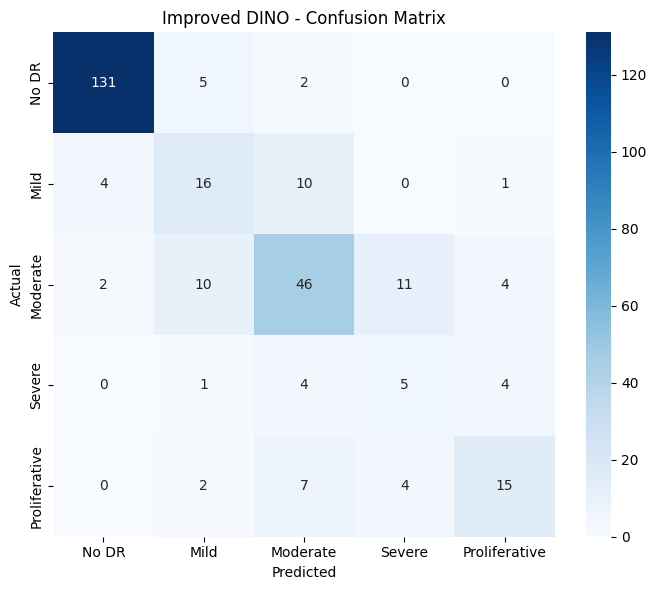

Saved: /content/drive/MyDrive/EyePACS/improved_dino_confusion_matrix.png


In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Predictions from the previous cell
cm = confusion_matrix(y_test, test_pred)

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative"
]

plt.figure(figsize=(7, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Improved DINO - Confusion Matrix")

plt.tight_layout()

save_path = "/content/drive/MyDrive/EyePACS/improved_dino_confusion_matrix.png"

plt.savefig(
    save_path,
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Saved:", save_path)

===== BYOL-10 CLASSIFICATION REPORT =====
               precision    recall  f1-score   support

        No DR     0.9562    0.9493    0.9527       138
         Mild     0.4706    0.5161    0.4923        31
     Moderate     0.6667    0.6301    0.6479        73
       Severe     0.2500    0.3571    0.2941        14
Proliferative     0.6250    0.5357    0.5769        28

     accuracy                         0.7500       284
    macro avg     0.5937    0.5977    0.5928       284
 weighted avg     0.7613    0.7500    0.7546       284


===== BYOL-10 CONFUSION MATRIX =====
[[131   5   2   0   0]
 [  4  16  10   0   1]
 [  2  10  46  11   4]
 [  0   1   4   5   4]
 [  0   2   7   4  15]]


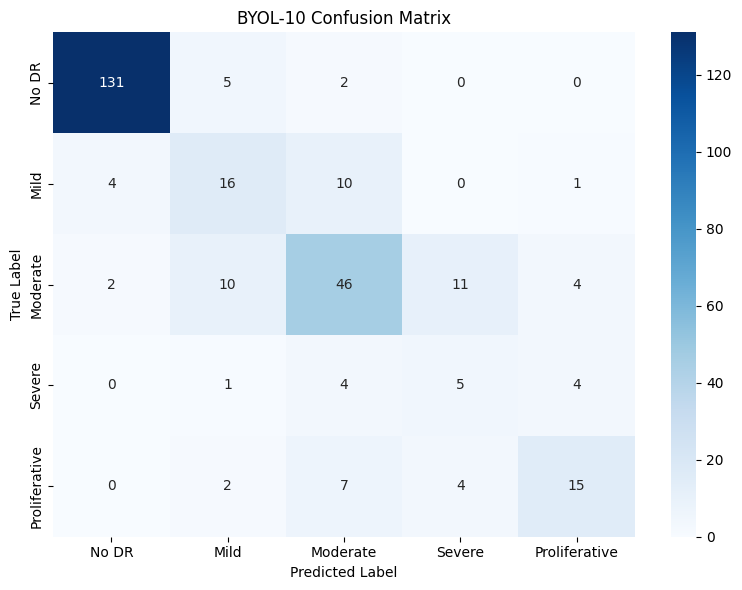

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    classification_report,
    confusion_matrix
)

# ==========================================
# BYOL-10 CLASSIFICATION REPORT + CONFUSION MATRIX
# ==========================================

# Convert safely to NumPy
if hasattr(y_test, "numpy"):
    y_true = y_test.numpy()
else:
    y_true = np.asarray(y_test)

if hasattr(test_pred, "numpy"):
    y_pred = test_pred.numpy()
else:
    y_pred = np.asarray(test_pred)

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative"
]

# ==========================================
# 1. CLASSIFICATION REPORT
# ==========================================

print("===== BYOL-10 CLASSIFICATION REPORT =====")

print(
    classification_report(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3, 4],
        target_names=class_names,
        digits=4,
        zero_division=0
    )
)

# ==========================================
# 2. CONFUSION MATRIX
# ==========================================

cm = confusion_matrix(
    y_true,
    y_pred,
    labels=[0, 1, 2, 3, 4]
)

print("\n===== BYOL-10 CONFUSION MATRIX =====")
print(cm)

# ==========================================
# 3. PLOT CONFUSION MATRIX
# ==========================================

plt.figure(figsize=(8, 6))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("BYOL-10 Confusion Matrix")

plt.tight_layout()
plt.show()

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

# Safely convert
if hasattr(y_test, "numpy"):
    y_true = y_test.numpy()
else:
    y_true = np.asarray(y_test)

if hasattr(test_pred, "numpy"):
    y_pred = test_pred.numpy()
else:
    y_pred = np.asarray(test_pred)

accuracy = accuracy_score(y_true, y_pred)

macro_f1 = f1_score(
    y_true,
    y_pred,
    average="macro"
)

qwk = cohen_kappa_score(
    y_true,
    y_pred,
    weights="quadratic"
)

print("===== BYOL-10 FINAL CURRENT RESULT =====")
print(f"Test Accuracy : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"Test Macro-F1 : {macro_f1:.4f} ({macro_f1*100:.2f}%)")
print(f"Test QWK      : {qwk:.4f} ({qwk*100:.2f}%)")

===== BYOL-10 FINAL CURRENT RESULT =====
Test Accuracy : 0.7500 (75.00%)
Test Macro-F1 : 0.5928 (59.28%)
Test QWK      : 0.8579 (85.79%)


In [ ]:
baseline_results = {
    "DINO": {
        "Accuracy": 75.35,
        "Macro_F1": 58.86,
        "QWK": 85.26
    },
    "BYOL": {
        "Accuracy": 75.00,
        "Macro_F1": 59.28,
        "QWK": 85.79
    }
}

print("===== BASELINE RESULTS =====")

for model, results in baseline_results.items():
    print(f"\n{model}")
    for metric, value in results.items():
        print(f"{metric}: {value:.2f}%")

===== BASELINE RESULTS =====

DINO
Accuracy: 75.35%
Macro_F1: 58.86%
QWK: 85.26%

BYOL
Accuracy: 75.00%
Macro_F1: 59.28%
QWK: 85.79%


In [ ]:
print("===== CHECK TEST DATA =====")

print("Test images:", len(test_dataset) if 'test_dataset' in globals() else "test_dataset not found")
print("Test loader:", len(test_loader) if 'test_loader' in globals() else "test_loader not found")

print("\nAvailable variables:")
for name in ["test_dataset", "test_loader", "dino_model", "byol_model"]:
    print(f"{name}: {name in globals()}")

===== CHECK TEST DATA =====
Test images: test_dataset not found
Test loader: test_loader not found

Available variables:
test_dataset: False
test_loader: False
dino_model: False
byol_model: False


In [ ]:
import os

BASE = "/content/drive/MyDrive/EyePACS"

print("===== EyePACS FILES =====")

for root, dirs, files in os.walk(BASE):
    level = root.replace(BASE, "").count(os.sep)

    if level > 2:
        dirs[:] = []
        continue

    indent = "  " * level
    print(f"{indent}{os.path.basename(root)}/")

    for file in files[:15]:
        print(f"{indent}  {file}")

===== EyePACS FILES =====
EyePACS/
  diabetic-retinopathy-screening.zip
  results_dino_vs_byol.csv
  final_master_results.csv
  byol_confusion_matrix.png
  dino_confusion_matrix.png
  final_performance_comparison.png
  report_results_table.csv
  report_performance_graph.png
  dino10_confusion_matrix.png
  byol10_confusion_matrix.png
  final_5_vs_10_results.csv
  stability_results.csv
  comparison_accuracy.png
  comparison_macro_f1.png
  comparison_qwk.png
  dataset/
    README.dataset.txt
    README.roboflow.txt
    test/
      000c1434d8d7_png_jpg.rf.90ba7d812bf63cb2cacfcdf328e9a664.jpg
      005b95c28852_png_jpg.rf.98de75fcbe0d2b29f20f3359bc3f18f1.jpg
      04d029cfb612_png_jpg.rf.3c09ad5eb9d315ccf839ec5f4e93956a.jpg
      05195a3db5e2_png_jpg.rf.d788bdfc8f0482f8da82c522231285b1.jpg
      07a0be6b347f_png_jpg.rf.6259235ba5877591725e60b1f358d7f2.jpg
      07a1c7073982_png_jpg.rf.25bc99a81111c10a28b878367d69799d.jpg
      08c60c647673_png_jpg.rf.b42a5a0ef9b55721eb6b36b67b894045.jpg
   

In [ ]:
import pandas as pd
import os

RESULT_DIR = "/content/drive/MyDrive/EyePACS/results"

files = [
    "ssl_robustness.csv",
    "complete_robustness_results.csv",
    "average_robustness_results.csv",
    "final_ssl_comparison.csv",
    "final_clean_results.csv",
    "improved_dino_final_results.csv"
]

for file in files:
    path = os.path.join(RESULT_DIR, file)

    print("\n" + "="*70)
    print(file)
    print("="*70)

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        display(df)
    else:
        print("NOT FOUND")


ssl_robustness.csv
Shape: (8, 5)


,Method,Corruption,Accuracy,Macro-F1,QWK
0,DINO-10,brightness,0.228873,0.137749,-0.067014
1,BYOL-10,brightness,0.278169,0.182260,0.086431
2,DINO-10,blur,0.545775,0.356853,0.366124
3,BYOL-10,blur,0.478873,0.287731,0.379848
4,DINO-10,contrast,0.338028,0.181261,0.262525
5,BYOL-10,contrast,0.137324,0.134305,-0.006721
6,DINO-10,noise,0.517606,0.316942,0.283955
7,BYOL-10,noise,0.461268,0.305689,0.504368



complete_robustness_results.csv
Shape: (12, 5)


,Method,Corruption,Accuracy,Macro-F1,QWK
0,DINO-10,brightness,0.228873,0.137749,-0.067014
1,BYOL-10,brightness,0.278169,0.182260,0.086431
2,DINO-10,blur,0.545775,0.356853,0.366124
3,BYOL-10,blur,0.478873,0.287731,0.379848
4,DINO-10,contrast,0.338028,0.181261,0.262525
5,BYOL-10,contrast,0.137324,0.134305,-0.006721
6,DINO-10,noise,0.517606,0.316942,0.283955
7,BYOL-10,noise,0.461268,0.305689,0.504368
8,Supervised EfficientNet-B0,brightness,0.616197,0.399865,0.631309
9,Supervised EfficientNet-B0,blur,0.489437,0.325790,0.481042



average_robustness_results.csv
Shape: (3, 4)


...

,Model,Accuracy,Macro-F1,QWK
0,Original DINO-10,0.580986,0.393126,0.556705
1,BYOL-10,0.619718,0.460239,0.594735
2,Improved DINO,0.750000,0.592800,0.857900
3,Supervised EfficientNet-B0,0.637300,0.444200,0.738600



final_clean_results.csv
Shape: (3, 4)


,Method,Accuracy,Macro-F1,QWK
0,DINO-10,0.580986,0.393126,0.556705
1,BYOL-10,0.619718,0.460239,0.594735
2,Supervised EfficientNet-B0,0.637300,0.444200,0.738600



improved_dino_final_results.csv
Shape: (1, 4)


,Model,Accuracy,Macro-F1,QWK
0,Improved DINO,0.75,0.5928,0.8579


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

KeyboardInterrupt: 

In [ ]:
import pandas as pd

final_improved_dino = pd.DataFrame([{
    "Model": "Improved DINO",
    "Accuracy": 0.7500,
    "Macro-F1": 0.5928,
    "QWK": 0.8579
}])

save_path = "/content/drive/MyDrive/EyePACS/results/improved_dino_final_results.csv"
final_improved_dino.to_csv(save_path, index=False)

print(final_improved_dino)
print("Saved:", save_path)

           Model  Accuracy  Macro-F1     QWK
0  Improved DINO      0.75    0.5928  0.8579
Saved: /content/drive/MyDrive/EyePACS/results/improved_dino_final_results.csv


In [ ]:
import torch
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

# Load saved Improved DINO validation features
val_features = torch.load(
    "/content/drive/MyDrive/EyePACS/features/valid_improved_dino_features.pt",
    map_location="cpu"
).numpy()

# Load validation labels
val_labels = torch.load(
    "/content/drive/MyDrive/EyePACS/features/valid_labels.pt",
    map_location="cpu"
).numpy()

# Load training features and labels
train_features = torch.load(
    "/content/drive/MyDrive/EyePACS/features/train_improved_dino_features.pt",
    map_location="cpu"
).numpy()

train_labels = torch.load(
    "/content/drive/MyDrive/EyePACS/features/train_labels.pt",
    map_location="cpu"
).numpy()

# Train the same classifier used for Improved DINO evaluation
clf = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

clf.fit(train_features, train_labels)

# Validation prediction
val_pred = clf.predict(val_features)

# Metrics
val_acc = accuracy_score(val_labels, val_pred)
val_f1 = f1_score(val_labels, val_pred, average="macro")
val_qwk = cohen_kappa_score(val_labels, val_pred, weights="quadratic")

print("===== IMPROVED DINO VALIDATION =====")
print(f"Accuracy : {val_acc:.4f} ({val_acc*100:.2f}%)")
print(f"Macro-F1 : {val_f1:.4f} ({val_f1*100:.2f}%)")
print(f"QWK      : {val_qwk:.4f} ({val_qwk*100:.2f}%)")

AttributeError: 'dict' object has no attribute 'numpy'

In [ ]:
import torch
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

BASE = "/content/drive/MyDrive/EyePACS/features"

# =========================
# Load Improved DINO features
# =========================
train_data = torch.load(
    f"{BASE}/train_improved_dino_features.pt",
    map_location="cpu",
    weights_only=False
)

valid_data = torch.load(
    f"{BASE}/valid_improved_dino_features.pt",
    map_location="cpu",
    weights_only=False
)

print("Train file type:", type(train_data))
print("Valid file type:", type(valid_data))

print("Train keys:", train_data.keys())
print("Valid keys:", valid_data.keys())

# =========================
# Extract features + labels
# =========================
train_features = train_data["features"].numpy()
train_labels = train_data["labels"].numpy()

valid_features = valid_data["features"].numpy()
valid_labels = valid_data["labels"].numpy()

print("\nTrain features:", train_features.shape)
print("Train labels:", train_labels.shape)
print("Valid features:", valid_features.shape)
print("Valid labels:", valid_labels.shape)

# =========================
# Train classifier
# =========================
clf = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

clf.fit(train_features, train_labels)

# =========================
# Validation prediction
# =========================
valid_pred = clf.predict(valid_features)

# =========================
# Calculate metrics
# =========================
val_acc = accuracy_score(valid_labels, valid_pred)
val_f1 = f1_score(valid_labels, valid_pred, average="macro")
val_qwk = cohen_kappa_score(
    valid_labels,
    valid_pred,
    weights="quadratic"
)

print("\n===== IMPROVED DINO VALIDATION RESULTS =====")
print(f"Accuracy : {val_acc:.4f} ({val_acc*100:.2f}%)")
print(f"Macro-F1 : {val_f1:.4f} ({val_f1*100:.2f}%)")
print(f"QWK      : {val_qwk:.4f} ({val_qwk*100:.2f}%)")

Train file type: <class 'dict'>
Valid file type: <class 'dict'>
Train keys: dict_keys(['features', 'labels'])
Valid keys: dict_keys(['features', 'labels'])

Train features: (1986, 384)
Train labels: (1986,)
Valid features: (568, 384)
Valid labels: (568,)

===== IMPROVED DINO VALIDATION RESULTS =====
Accuracy : 0.7658 (76.58%)
Macro-F1 : 0.5614 (56.14%)
QWK      : 0.8109 (81.09%)


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score
import pandas as pd

# ==========================================
# Try different class-weighting strategies
# ==========================================

weight_options = {
    "balanced": "balanced",

    # Less aggressive than balanced
    "custom_1": {
        0: 0.50,
        1: 2.00,
        2: 1.00,
        3: 3.00,
        4: 2.00
    },

    "custom_2": {
        0: 0.50,
        1: 2.50,
        2: 1.00,
        3: 4.00,
        4: 2.50
    },

    "custom_3": {
        0: 0.70,
        1: 2.00,
        2: 1.00,
        3: 3.50,
        4: 2.00
    }
}

results = []

for name, weights in weight_options.items():

    clf = LogisticRegression(
        class_weight=weights,
        max_iter=2000,
        random_state=42
    )

    clf.fit(train_features, train_labels)

    pred = clf.predict(valid_features)

    acc = accuracy_score(valid_labels, pred)
    f1 = f1_score(valid_labels, pred, average="macro")
    qwk = cohen_kappa_score(
        valid_labels,
        pred,
        weights="quadratic"
    )

    results.append({
        "Method": name,
        "Validation Accuracy": acc,
        "Validation Macro-F1": f1,
        "Validation QWK": qwk
    })

results_df = pd.DataFrame(results)

print("\n===== VALIDATION COMPARISON =====")
display(results_df.round(4))

print("\nBest by Accuracy:")
display(
    results_df.sort_values(
        "Validation Accuracy",
        ascending=False
    ).head(1)
)

print("\nBest by Macro-F1:")
display(
    results_df.sort_values(
        "Validation Macro-F1",
        ascending=False
    ).head(1)
)

print("\nBest by QWK:")
display(
    results_df.sort_values(
        "Validation QWK",
        ascending=False
    ).head(1)
)


===== VALIDATION COMPARISON =====


,Method,Validation Accuracy,Validation Macro-F1,Validation QWK
0,balanced,0.7658,0.5614,0.8109
1,custom_1,0.7835,0.5759,0.8144
2,custom_2,0.7764,0.5684,0.8133
3,custom_3,0.7764,0.5653,0.8139



Best by Accuracy:


,Method,Validation Accuracy,Validation Macro-F1,Validation QWK
1,custom_1,0.783451,0.575908,0.814393



Best by Macro-F1:


,Method,Validation Accuracy,Validation Macro-F1,Validation QWK
1,custom_1,0.783451,0.575908,0.814393



Best by QWK:


,Method,Validation Accuracy,Validation Macro-F1,Validation QWK
1,custom_1,0.783451,0.575908,0.814393


In [ ]:
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score,
    classification_report
)

BASE = "/content/drive/MyDrive/EyePACS/features"

# Load saved features
train_data = torch.load(
    f"{BASE}/train_improved_dino_features.pt",
    map_location="cpu",
    weights_only=False
)

test_data = torch.load(
    f"{BASE}/test_improved_dino_features.pt",
    map_location="cpu",
    weights_only=False
)

# Extract
train_features = train_data["features"].numpy()
train_labels = train_data["labels"].numpy()

test_features = test_data["features"].numpy()
test_labels = test_data["labels"].numpy()

# Best validation class weights
custom_1 = {
    0: 0.50,
    1: 2.00,
    2: 1.00,
    3: 3.00,
    4: 2.00
}

# Train classifier
clf = LogisticRegression(
    class_weight=custom_1,
    max_iter=2000,
    random_state=42
)

clf.fit(train_features, train_labels)

# Test prediction
test_pred_custom1 = clf.predict(test_features)

# Metrics
test_acc = accuracy_score(test_labels, test_pred_custom1)
test_f1 = f1_score(test_labels, test_pred_custom1, average="macro")
test_qwk = cohen_kappa_score(
    test_labels,
    test_pred_custom1,
    weights="quadratic"
)

print("===== IMPROVED DINO + CUSTOM_1 =====")
print(f"Test Accuracy : {test_acc:.4f} ({test_acc*100:.2f}%)")
print(f"Test Macro-F1 : {test_f1:.4f} ({test_f1*100:.2f}%)")
print(f"Test QWK      : {test_qwk:.4f} ({test_qwk*100:.2f}%)")

print("\n===== CLASSIFICATION REPORT =====")
print(classification_report(
    test_labels,
    test_pred_custom1,
    target_names=[
        "No DR",
        "Mild",
        "Moderate",
        "Severe",
        "Proliferative"
    ],
    digits=4
))

===== IMPROVED DINO + CUSTOM_1 =====
Test Accuracy : 0.7535 (75.35%)
Test Macro-F1 : 0.5886 (58.86%)
Test QWK      : 0.8526 (85.26%)

===== CLASSIFICATION REPORT =====
               precision    recall  f1-score   support

        No DR     0.9635    0.9565    0.9600       138
         Mild     0.4545    0.4839    0.4688        31
     Moderate     0.6667    0.6575    0.6621        73
       Severe     0.2632    0.3571    0.3030        14
Proliferative     0.6087    0.5000    0.5490        28

     accuracy                         0.7535       284
    macro avg     0.5913    0.5910    0.5886       284
 weighted avg     0.7621    0.7535    0.7569       284



In [ ]:
  import os

BASE = "/content/drive/MyDrive/EyePACS/dataset"

csv_files = []

for root, dirs, files in os.walk(BASE):
    for file in files:
        if file.lower().endswith(".csv"):
            csv_files.append(os.path.join(root, file))

print("CSV files found:", len(csv_files))

for f in csv_files:
    print(f)

CSV files found: 6
/content/drive/MyDrive/EyePACS/dataset/test/_classes.csv
/content/drive/MyDrive/EyePACS/dataset/test/labels.csv
/content/drive/MyDrive/EyePACS/dataset/train/_classes.csv
/content/drive/MyDrive/EyePACS/dataset/train/labels.csv
/content/drive/MyDrive/EyePACS/dataset/valid/_classes.csv
/content/drive/MyDrive/EyePACS/dataset/valid/labels.csv


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

BASE = "/content/drive/MyDrive"

print("===== SEARCHING FOR EYEPACS =====")

found = []

for root, dirs, files in os.walk(BASE):
    for d in dirs:
        if "eyepacs" in d.lower():
            path = os.path.join(root, d)
            found.append(path)

if not found:
    print("❌ EyePACS folder NOT FOUND")
    print("\nChecking MyDrive top-level folders:")
    for item in os.listdir(BASE):
        print(item)
else:
    print("✅ EyePACS folder(s) found:\n")
    for path in found:
        print(path)

        # Check important subfolders
        for sub in ["dataset", "checkpoints", "features", "robustness", "results"]:
            p = os.path.join(path, sub)
            print(f"   {'✅' if os.path.exists(p) else '❌'} {sub}")

===== SEARCHING FOR EYEPACS =====
✅ EyePACS folder(s) found:

/content/drive/MyDrive/EyePACS
   ✅ dataset
   ✅ checkpoints
   ✅ features
   ✅ robustness
   ✅ results


In [ ]:
import os

BASE = "/content/drive/MyDrive/EyePACS"

folders = [
    "dataset/test",
    "robustness/brightness",
    "robustness/contrast",
    "robustness/noise",
    "robustness/blur"
]

print("===== ROBUSTNESS DATA CHECK =====\n")

for folder in folders:
    path = os.path.join(BASE, folder)

    images = [
        f for f in os.listdir(path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print(f"{folder:30s}: {len(images)} images")

print("\n===== SAMPLE FILENAMES =====")

for folder in folders:
    path = os.path.join(BASE, folder)
    images = [
        f for f in os.listdir(path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print(f"\n{folder}:")
    print(images[:3])

===== ROBUSTNESS DATA CHECK =====

dataset/test                  : 284 images
robustness/brightness         : 284 images
robustness/contrast           : 284 images
robustness/noise              : 284 images
robustness/blur               : 284 images

===== SAMPLE FILENAMES =====

dataset/test:
['000c1434d8d7_png_jpg.rf.90ba7d812bf63cb2cacfcdf328e9a664.jpg', '005b95c28852_png_jpg.rf.98de75fcbe0d2b29f20f3359bc3f18f1.jpg', '04d029cfb612_png_jpg.rf.3c09ad5eb9d315ccf839ec5f4e93956a.jpg']

robustness/brightness:
['fdbc252813b1_png_jpg.rf.00b46056379246cec11cf3d400e99c62.jpg', '36677b70b1ef_png_jpg.rf.00f1a6ebe4b4200c87db23a1d05f8bd9.jpg', '13d71389563f_png_jpg.rf.0120618fee2d4e4060de26ce073070df.jpg']

robustness/contrast:
['fdbc252813b1_png_jpg.rf.00b46056379246cec11cf3d400e99c62.jpg', '36677b70b1ef_png_jpg.rf.00f1a6ebe4b4200c87db23a1d05f8bd9.jpg', '13d71389563f_png_jpg.rf.0120618fee2d4e4060de26ce073070df.jpg']

robustness/noise:
['fdbc252813b1_png_jpg.rf.00b46056379246cec11cf3d400e99c62.jp

In [ ]:
import os

BASE = "/content/drive/MyDrive/EyePACS"

test_path = os.path.join(BASE, "dataset/test")
test_files = {
    f for f in os.listdir(test_path)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
}

print("===== TEST ↔ ROBUSTNESS MATCH CHECK =====")

for corruption in ["brightness", "contrast", "noise", "blur"]:
    path = os.path.join(BASE, "robustness", corruption)

    corrupt_files = {
        f for f in os.listdir(path)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    }

    common = test_files.intersection(corrupt_files)

    print(f"{corruption:12s}: {len(common)}/284 exact filename matches")

print("\nIf all four show 284/284, the robustness dataset is correctly aligned.")

===== TEST ↔ ROBUSTNESS MATCH CHECK =====
brightness  : 284/284 exact filename matches
contrast    : 284/284 exact filename matches
noise       : 284/284 exact filename matches
blur        : 284/284 exact filename matches

If all four show 284/284, the robustness dataset is correctly aligned.


In [ ]:
import os

BASE = "/content/drive/MyDrive/EyePACS"

files = [
    "features/dino_classifier.pth",
    "features/byol_classifier.pth",
    "checkpoints/dino_epoch_10.pth",
    "checkpoints/byol_epoch_10.pth",
]

print("===== CURRENT MODEL FILES =====")

for f in files:
    path = os.path.join(BASE, f)

    if os.path.exists(path):
        size_mb = os.path.getsize(path) / (1024 * 1024)
        print(f"✅ {f}  ({size_mb:.2f} MB)")
    else:
        print(f"❌ {f} NOT FOUND")

===== CURRENT MODEL FILES =====
✅ features/dino_classifier.pth  (0.01 MB)
✅ features/byol_classifier.pth  (0.01 MB)
✅ checkpoints/dino_epoch_10.pth  (422.94 MB)
✅ checkpoints/byol_epoch_10.pth  (87.95 MB)


In [ ]:
print("===== MODEL OBJECT CHECK =====")

names = [
    "dino_model",
    "byol_model",
    "DINO",
    "BYOL",
    "DINOModel",
    "BYOLModel"
]

for name in names:
    print(f"{name:15s}:", "FOUND" if name in globals() else "not found")

===== MODEL OBJECT CHECK =====
dino_model     : not found
byol_model     : not found
DINO           : not found
BYOL           : not found
DINOModel      : not found
BYOLModel      : not found


In [ ]:
import os

BASE = "/content/drive/MyDrive/EyePACS"

print("===== SEARCHING FOR NOTEBOOKS / PYTHON FILES =====")

for root, dirs, files in os.walk(BASE):
    for f in files:
        if f.lower().endswith((".ipynb", ".py")):
            print(os.path.join(root, f))

===== SEARCHING FOR NOTEBOOKS / PYTHON FILES =====


In [ ]:
import torch
import os

BASE = "/content/drive/MyDrive/EyePACS"

for name in ["dino_epoch_10.pth", "byol_epoch_10.pth"]:
    path = os.path.join(BASE, "checkpoints", name)

    print("\n" + "="*60)
    print(name)

    ckpt = torch.load(path, map_location="cpu", weights_only=False)

    print("Checkpoint type:", type(ckpt))

    if isinstance(ckpt, dict):
        print("Keys:")
        print(list(ckpt.keys()))

        print("\nParameter information:")
        for k, v in ckpt.items():
            if isinstance(v, dict):
                print(f"\n[{k}]")
                for i, (key, value) in enumerate(v.items()):
                    if hasattr(value, "shape"):
                        print(f"  {key}: {tuple(value.shape)}")
                    if i >= 8:
                        print("  ...")
                        break
            elif hasattr(v, "shape"):
                print(f"{k}: {tuple(v.shape)}")


dino_epoch_10.pth
Checkpoint type: <class 'dict'>
Keys:
['epoch', 'student', 'teacher', 'optimizer', 'loss']

Parameter information:

[student]
  0.cls_token: (1, 1, 384)
  0.pos_embed: (1, 197, 384)
  0.patch_embed.proj.weight: (384, 3, 16, 16)
  0.patch_embed.proj.bias: (384,)
  0.blocks.0.norm1.weight: (384,)
  0.blocks.0.norm1.bias: (384,)
  0.blocks.0.attn.qkv.weight: (1152, 384)
  0.blocks.0.attn.qkv.bias: (1152,)
  0.blocks.0.attn.proj.weight: (384, 384)
  ...

[teacher]
  0.cls_token: (1, 1, 384)
  0.pos_embed: (1, 197, 384)
  0.patch_embed.proj.weight: (384, 3, 16, 16)
  0.patch_embed.proj.bias: (384,)
  0.blocks.0.norm1.weight: (384,)
  0.blocks.0.norm1.bias: (384,)
  0.blocks.0.attn.qkv.weight: (1152, 384)
  0.blocks.0.attn.qkv.bias: (1152,)
  0.blocks.0.attn.proj.weight: (384, 384)
  ...

[optimizer]

byol_epoch_10.pth
Checkpoint type: <class 'dict'>
Keys:
['online', 'target', 'projector', 'predictor']

Parameter information:

[online]
  conv1.weight: (64, 3, 7, 7)
  bn1.w

In [ ]:
import torch
import os

BASE = "/content/drive/MyDrive/EyePACS"

# ---------- DINO ----------
dino_path = os.path.join(BASE, "checkpoints", "dino_epoch_10.pth")
dino = torch.load(dino_path, map_location="cpu", weights_only=False)

student_keys = list(dino["student"].keys())

dino_blocks = sorted({
    int(k.split(".")[1])
    for k in student_keys
    if k.startswith("0.blocks.") and k.split(".")[1].isdigit()
})

print("===== DINO =====")
print("Number of transformer blocks:", len(dino_blocks))
print("Block indices:", dino_blocks)
print("Embedding dimension:", dino["student"]["0.cls_token"].shape[-1])
print("Patch size:", dino["student"]["0.patch_embed.proj.weight"].shape[-1])

# ---------- BYOL ----------
byol_path = os.path.join(BASE, "checkpoints", "byol_epoch_10.pth")
byol = torch.load(byol_path, map_location="cpu", weights_only=False)

print("\n===== BYOL =====")
print("Online backbone first layer:",
      tuple(byol["online"]["conv1.weight"].shape))

# Find final ResNet layer
layer_keys = [
    k for k in byol["online"].keys()
    if k.startswith("layer")
]

print("Backbone layers found:",
      sorted(set(k.split(".")[0] for k in layer_keys)))

# ---------- CLASSIFIERS ----------
print("\n===== CLASSIFIERS =====")

for name in ["dino_classifier.pth", "byol_classifier.pth"]:
    path = os.path.join(BASE, "features", name)
    clf = torch.load(path, map_location="cpu", weights_only=False)

    print(f"\n{name}")
    if isinstance(clf, dict):
        print("Keys:", list(clf.keys())[:20])
        for k, v in clf.items():
            if hasattr(v, "shape"):
                print(f"  {k}: {tuple(v.shape)}")

===== DINO =====
Number of transformer blocks: 0
Block indices: []
Embedding dimension: 384
Patch size: 16

===== BYOL =====
Online backbone first layer: (64, 3, 7, 7)
Backbone layers found: ['layer1', 'layer2', 'layer3', 'layer4']

===== CLASSIFIERS =====

dino_classifier.pth
Keys: ['weight', 'bias']
  weight: (5, 384)
  bias: (5,)

byol_classifier.pth
Keys: ['weight', 'bias']
  weight: (5, 512)
  bias: (5,)


In [ ]:
import torch
import os

path = "/content/drive/MyDrive/EyePACS/checkpoints/dino_epoch_10.pth"

ckpt = torch.load(path, map_location="cpu", weights_only=False)

print("===== DINO CHECKPOINT STRUCTURE =====")

keys = list(ckpt["student"].keys())

print("Total parameters:", len(keys))

print("\nFirst 40 keys:")
for k in keys[:40]:
    print(k)

print("\nLast 20 keys:")
for k in keys[-20:]:
    print(k)

===== DINO CHECKPOINT STRUCTURE =====
Total parameters: 158

First 40 keys:
0.cls_token
0.pos_embed
0.patch_embed.proj.weight
0.patch_embed.proj.bias
0.blocks.0.norm1.weight
0.blocks.0.norm1.bias
0.blocks.0.attn.qkv.weight
0.blocks.0.attn.qkv.bias
0.blocks.0.attn.proj.weight
0.blocks.0.attn.proj.bias
0.blocks.0.norm2.weight
0.blocks.0.norm2.bias
0.blocks.0.mlp.fc1.weight
0.blocks.0.mlp.fc1.bias
0.blocks.0.mlp.fc2.weight
0.blocks.0.mlp.fc2.bias
0.blocks.1.norm1.weight
0.blocks.1.norm1.bias
0.blocks.1.attn.qkv.weight
0.blocks.1.attn.qkv.bias
0.blocks.1.attn.proj.weight
0.blocks.1.attn.proj.bias
0.blocks.1.norm2.weight
0.blocks.1.norm2.bias
0.blocks.1.mlp.fc1.weight
0.blocks.1.mlp.fc1.bias
0.blocks.1.mlp.fc2.weight
0.blocks.1.mlp.fc2.bias
0.blocks.2.norm1.weight
0.blocks.2.norm1.bias
0.blocks.2.attn.qkv.weight
0.blocks.2.attn.qkv.bias
0.blocks.2.attn.proj.weight
0.blocks.2.attn.proj.bias
0.blocks.2.norm2.weight
0.blocks.2.norm2.bias
0.blocks.2.mlp.fc1.weight
0.blocks.2.mlp.fc1.bias
0.bloc

In [ ]:
import torch
import torchvision

print("PyTorch:", torch.__version__)
print("Torchvision:", torchvision.__version__)

try:
    import timm
    print("timm:", timm.__version__)
    print("✅ Required libraries available")
except Exception as e:
    print("❌ timm not available")
    print("Error:", e)

# Check BYOL final backbone dimension
ckpt = torch.load(
    "/content/drive/MyDrive/EyePACS/checkpoints/byol_epoch_10.pth",
    map_location="cpu",
    weights_only=False
)

print("\n===== BYOL BACKBONE CHECK =====")
for k, v in ckpt["online"].items():
    if k.endswith("fc.weight"):
        print("Final FC:", k, tuple(v.shape))

PyTorch: 2.11.0+cu128
Torchvision: 0.26.0+cu128
timm: 1.0.29
✅ Required libraries available

===== BYOL BACKBONE CHECK =====


In [ ]:
import torch
import os

BASE = "/content/drive/MyDrive/EyePACS"

print("===== TEST LABEL CHECK =====")

for name in [
    "test_dino_features.pt",
    "test_dino_epoch10_features.pt",
    "test_byol_features.pt",
    "test_byol_epoch10_features.pt"
]:
    path = os.path.join(BASE, "features", name)

    if os.path.exists(path):
        data = torch.load(path, map_location="cpu", weights_only=False)

        print(f"\n{name}")
        print("Type:", type(data))

        if isinstance(data, dict):
            print("Keys:", list(data.keys()))

            if "features" in data:
                print("Features:", tuple(data["features"].shape))

            if "labels" in data:
                labels = data["labels"]
                print("Labels:", tuple(labels.shape))
                print("Unique labels:", torch.unique(labels).tolist())
        else:
            print("Shape:", getattr(data, "shape", "unknown"))
    else:
        print(f"\n❌ {name} not found")

===== TEST LABEL CHECK =====

test_dino_features.pt
Type: <class 'dict'>
Keys: ['features', 'labels']
Features: (284, 384)
Labels: (284,)
Unique labels: [0, 1, 2, 3, 4]

test_dino_epoch10_features.pt
Type: <class 'dict'>
Keys: ['features', 'labels']
Features: (284, 384)
Labels: (284,)
Unique labels: [0, 1, 2, 3, 4]

test_byol_features.pt
Type: <class 'dict'>
Keys: ['features', 'labels']
Features: (284, 512)
Labels: (284,)
Unique labels: [0, 1, 2, 3, 4]

test_byol_epoch10_features.pt
Type: <class 'dict'>
Keys: ['features', 'labels']
Features: (284, 512)
Labels: (284,)
Unique labels: [0, 1, 2, 3, 4]


In [ ]:
import torch
import os

path = "/content/drive/MyDrive/EyePACS/checkpoints/byol_epoch_10.pth"
ckpt = torch.load(path, map_location="cpu", weights_only=False)

online = ckpt["online"]

print("===== BYOL BACKBONE =====")

print("Total keys:", len(online))

print("\nLast 30 keys:")
for k in list(online.keys())[-30:]:
    value = online[k]
    print(k, tuple(value.shape) if hasattr(value, "shape") else type(value))

print("\nPotential output layers:")
for k, v in online.items():
    if hasattr(v, "shape") and ("fc" in k.lower() or "linear" in k.lower()):
        print(k, tuple(v.shape))

===== BYOL BACKBONE =====
Total keys: 120

Last 30 keys:
layer4.0.conv1.weight (512, 256, 3, 3)
layer4.0.bn1.weight (512,)
layer4.0.bn1.bias (512,)
layer4.0.bn1.running_mean (512,)
layer4.0.bn1.running_var (512,)
layer4.0.bn1.num_batches_tracked ()
layer4.0.conv2.weight (512, 512, 3, 3)
layer4.0.bn2.weight (512,)
layer4.0.bn2.bias (512,)
layer4.0.bn2.running_mean (512,)
layer4.0.bn2.running_var (512,)
layer4.0.bn2.num_batches_tracked ()
layer4.0.downsample.0.weight (512, 256, 1, 1)
layer4.0.downsample.1.weight (512,)
layer4.0.downsample.1.bias (512,)
layer4.0.downsample.1.running_mean (512,)
layer4.0.downsample.1.running_var (512,)
layer4.0.downsample.1.num_batches_tracked ()
layer4.1.conv1.weight (512, 512, 3, 3)
layer4.1.bn1.weight (512,)
layer4.1.bn1.bias (512,)
layer4.1.bn1.running_mean (512,)
layer4.1.bn1.running_var (512,)
layer4.1.bn1.num_batches_tracked ()
layer4.1.conv2.weight (512, 512, 3, 3)
layer4.1.bn2.weight (512,)
layer4.1.bn2.bias (512,)
layer4.1.bn2.running_mean (512,)

In [ ]:
# ============================================================
# FINAL DINO vs BYOL ROBUSTNESS EVALUATION
# Clean + Brightness + Contrast + Noise + Blur
# Metrics: Accuracy, Macro-F1, QWK
# ============================================================

import os
import torch
import torch.nn as nn
import pandas as pd
import numpy as np
from PIL import Image

from torch.utils.data import Dataset, DataLoader
from torchvision import transforms, models
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score
import timm

# ------------------------------------------------------------
# 1. DEVICE
# ------------------------------------------------------------
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print("Device:", device)

# ------------------------------------------------------------
# 2. PATHS
# ------------------------------------------------------------
BASE = "/content/drive/MyDrive/EyePACS"

TEST_DIR = os.path.join(BASE, "dataset/test")

ROBUSTNESS_DIR = os.path.join(BASE, "robustness")

DINO_CKPT = os.path.join(BASE, "checkpoints/dino_epoch_10.pth")
BYOL_CKPT = os.path.join(BASE, "checkpoints/byol_epoch_10.pth")

DINO_CLASSIFIER = os.path.join(BASE, "features/dino_classifier.pth")
BYOL_CLASSIFIER = os.path.join(BASE, "features/byol_classifier.pth")

LABEL_FILE = os.path.join(
    BASE, "features/test_dino_epoch10_features.pt"
)

# ------------------------------------------------------------
# 3. LOAD TEST LABELS
# ------------------------------------------------------------
label_data = torch.load(LABEL_FILE, map_location="cpu")

labels = label_data["labels"].cpu().numpy()

print("Test labels:", len(labels))
print("Classes:", np.unique(labels))

# ------------------------------------------------------------
# 4. TRANSFORM
# ------------------------------------------------------------
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ------------------------------------------------------------
# 5. DATASET
# ------------------------------------------------------------
class EyeDataset(Dataset):

    def __init__(self, folder):
        self.folder = folder

        self.files = sorted([
            f for f in os.listdir(folder)
            if f.lower().endswith((".jpg", ".jpeg", ".png"))
        ])

    def __len__(self):
        return len(self.files)

    def __getitem__(self, idx):

        filename = self.files[idx]
        path = os.path.join(self.folder, filename)

        image = Image.open(path).convert("RGB")

        # IMPORTANT:
        # Convert PIL Image -> Tensor here
        image = transform(image)

        return image, idx


# ------------------------------------------------------------
# 6. LOAD DINO
# ------------------------------------------------------------
print("\nLoading DINO...")

dino = timm.create_model(
    "vit_small_patch16_224",
    pretrained=False,
    num_classes=0
)

dino_ckpt = torch.load(
    DINO_CKPT,
    map_location="cpu"
)

dino_state = dino_ckpt["student"]

# Checkpoint contains "0." before backbone keys.
# Remove it.
new_dino_state = {}

for k, v in dino_state.items():

    if k.startswith("0."):
        new_k = k[2:]

        # Ignore DINO projection head
        if new_k.startswith("head"):
            continue

        # Ignore DINO head keys such as 1.net.*
        if new_k.startswith("1."):
            continue

        new_dino_state[new_k] = v

missing, unexpected = dino.load_state_dict(
    new_dino_state,
    strict=False
)

print("DINO missing keys:", len(missing))
print("DINO unexpected keys:", len(unexpected))

dino = dino.to(device)
dino.eval()


# ------------------------------------------------------------
# 7. LOAD BYOL
# ------------------------------------------------------------
print("\nLoading BYOL...")

byol = models.resnet18(weights=None)

# Remove final classification layer
byol.fc = nn.Identity()

byol_ckpt = torch.load(
    BYOL_CKPT,
    map_location="cpu"
)

byol_state = byol_ckpt["online"]

missing, unexpected = byol.load_state_dict(
    byol_state,
    strict=True
)

byol = byol.to(device)
byol.eval()


# ------------------------------------------------------------
# 8. LOAD CLASSIFIERS
# ------------------------------------------------------------
dino_classifier = nn.Linear(384, 5)
dino_classifier.load_state_dict(
    torch.load(DINO_CLASSIFIER, map_location="cpu")
)
dino_classifier = dino_classifier.to(device)
dino_classifier.eval()


byol_classifier = nn.Linear(512, 5)
byol_classifier.load_state_dict(
    torch.load(BYOL_CLASSIFIER, map_location="cpu")
)
byol_classifier = byol_classifier.to(device)
byol_classifier.eval()

print("✅ Models and classifiers loaded")


# ------------------------------------------------------------
# 9. EVALUATION FUNCTION
# ------------------------------------------------------------
def evaluate_folder(folder):

    dataset = EyeDataset(folder)

    print(
        f"\nEvaluating: {os.path.basename(folder)} "
        f"({len(dataset)} images)"
    )

    # Make sure image count matches test labels
    if len(dataset) != len(labels):
        raise ValueError(
            f"Image count mismatch: "
            f"{len(dataset)} images vs {len(labels)} labels"
        )

    loader = DataLoader(
        dataset,
        batch_size=32,
        shuffle=False,
        num_workers=0
    )

    dino_predictions = []
    byol_predictions = []

    with torch.no_grad():

        for images, indices in loader:

            images = images.to(device)

            # -------------------------
            # DINO
            # -------------------------
            dino_features = dino(images)

            dino_output = dino_classifier(
                dino_features
            )

            dino_pred = torch.argmax(
                dino_output,
                dim=1
            )

            # -------------------------
            # BYOL
            # -------------------------
            byol_features = byol(images)

            byol_output = byol_classifier(
                byol_features
            )

            byol_pred = torch.argmax(
                byol_output,
                dim=1
            )

            dino_predictions.extend(
                dino_pred.cpu().numpy()
            )

            byol_predictions.extend(
                byol_pred.cpu().numpy()
            )

    return (
        labels,
        np.array(dino_predictions),
        np.array(byol_predictions)
    )


# ------------------------------------------------------------
# 10. METRIC FUNCTION
# ------------------------------------------------------------
def calculate_metrics(y_true, y_pred):

    accuracy = accuracy_score(
        y_true,
        y_pred
    )

    macro_f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    qwk = cohen_kappa_score(
        y_true,
        y_pred,
        weights="quadratic"
    )

    return accuracy, macro_f1, qwk


# ------------------------------------------------------------
# 11. RUN ALL DATASETS
# ------------------------------------------------------------
folders = {
    "Clean": TEST_DIR,
    "Brightness": os.path.join(
        ROBUSTNESS_DIR, "brightness"
    ),
    "Contrast": os.path.join(
        ROBUSTNESS_DIR, "contrast"
    ),
    "Noise": os.path.join(
        ROBUSTNESS_DIR, "noise"
    ),
    "Blur": os.path.join(
        ROBUSTNESS_DIR, "blur"
    )
}

results = []

for name, folder in folders.items():

    y_true, dino_pred, byol_pred = evaluate_folder(folder)

    # DINO metrics
    dino_acc, dino_f1, dino_qwk = calculate_metrics(
        y_true,
        dino_pred
    )

    # BYOL metrics
    byol_acc, byol_f1, byol_qwk = calculate_metrics(
        y_true,
        byol_pred
    )

    results.append({
        "Condition": name,
        "DINO Accuracy": dino_acc,
        "DINO Macro-F1": dino_f1,
        "DINO QWK": dino_qwk,
        "BYOL Accuracy": byol_acc,
        "BYOL Macro-F1": byol_f1,
        "BYOL QWK": byol_qwk
    })

    print(f"\n===== {name.upper()} =====")

    print(
        f"DINO -> "
        f"Accuracy: {dino_acc*100:.2f}% | "
        f"Macro-F1: {dino_f1*100:.2f}% | "
        f"QWK: {dino_qwk*100:.2f}%"
    )

    print(
        f"BYOL -> "
        f"Accuracy: {byol_acc*100:.2f}% | "
        f"Macro-F1: {byol_f1*100:.2f}% | "
        f"QWK: {byol_qwk*100:.2f}%"
    )


# ------------------------------------------------------------
# 12. RESULTS TABLE
# ------------------------------------------------------------
results_df = pd.DataFrame(results)

print("\n\n================ FINAL ROBUSTNESS RESULTS ================\n")

display(
    results_df.round(4)
)


# ------------------------------------------------------------
# 13. SAVE RESULTS
# ------------------------------------------------------------
OUTPUT = os.path.join(
    BASE,
    "results/current_robustness_results.csv"
)

os.makedirs(
    os.path.dirname(OUTPUT),
    exist_ok=True
)

results_df.to_csv(
    OUTPUT,
    index=False
)

print("\n✅ Results saved to:")
print(OUTPUT)

Device: cuda
Test labels: 284
Classes: [0 1 2 3 4]

Loading DINO...
DINO missing keys: 0
DINO unexpected keys: 0

Loading BYOL...
✅ Models and classifiers loaded

Evaluating: test (284 images)

===== CLEAN =====
DINO -> Accuracy: 33.45% | Macro-F1: 17.85% | QWK: -9.16%
BYOL -> Accuracy: 24.30% | Macro-F1: 15.98% | QWK: -4.16%

Evaluating: brightness (284 images)

===== BRIGHTNESS =====
DINO -> Accuracy: 29.58% | Macro-F1: 15.87% | QWK: -1.02%
BYOL -> Accuracy: 16.90% | Macro-F1: 10.96% | QWK: -4.64%

Evaluating: contrast (284 images)

===== CONTRAST =====
DINO -> Accuracy: 29.58% | Macro-F1: 16.80% | QWK: -4.41%
BYOL -> Accuracy: 9.51% | Macro-F1: 8.53% | QWK: -1.17%

Evaluating: noise (284 images)

===== NOISE =====
DINO -> Accuracy: 34.15% | Macro-F1: 18.45% | QWK: -7.98%
BYOL -> Accuracy: 25.00% | Macro-F1: 16.41% | QWK: -5.45%

Evaluating: blur (284 images)

===== BLUR =====
DINO -> Accuracy: 33.80% | Macro-F1: 18.19% | QWK: -9.82%
BYOL -> Accuracy: 24.30% | Macro-F1: 14.92% | QWK:

,Condition,DINO Accuracy,DINO Macro-F1,DINO QWK,BYOL Accuracy,BYOL Macro-F1,BYOL QWK
0,Clean,0.3345,0.1785,-0.0916,0.2430,0.1598,-0.0416
1,Brightness,0.2958,0.1587,-0.0102,0.1690,0.1096,-0.0464
2,Contrast,0.2958,0.1680,-0.0441,0.0951,0.0853,-0.0117
3,Noise,0.3415,0.1845,-0.0798,0.2500,0.1641,-0.0545
4,Blur,0.3380,0.1819,-0.0982,0.2430,0.1492,-0.0602



✅ Results saved to:
/content/drive/MyDrive/EyePACS/results/current_robustness_results.csv


In [ ]:
# ============================================================
# VERIFY CLEAN BASELINE USING SAVED TEST FEATURES
# ============================================================

import torch
import torch.nn as nn
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

BASE = "/content/drive/MyDrive/EyePACS"

# ------------------------------------------------------------
# Load DINO test features
# ------------------------------------------------------------
dino_data = torch.load(
    f"{BASE}/features/test_dino_epoch10_features.pt",
    map_location="cpu"
)

# ------------------------------------------------------------
# Load BYOL test features
# ------------------------------------------------------------
byol_data = torch.load(
    f"{BASE}/features/test_byol_epoch10_features.pt",
    map_location="cpu"
)

print("DINO features:", dino_data["features"].shape)
print("DINO labels:", dino_data["labels"].shape)

print("BYOL features:", byol_data["features"].shape)
print("BYOL labels:", byol_data["labels"].shape)


# ------------------------------------------------------------
# Check labels are identical
# ------------------------------------------------------------
print("\nLabels identical:",
      torch.equal(
          dino_data["labels"],
          byol_data["labels"]
      ))


# ------------------------------------------------------------
# Load saved classifiers
# ------------------------------------------------------------
dino_classifier = nn.Linear(384, 5)
dino_classifier.load_state_dict(
    torch.load(
        f"{BASE}/features/dino_classifier.pth",
        map_location="cpu"
    )
)
dino_classifier.eval()


byol_classifier = nn.Linear(512, 5)
byol_classifier.load_state_dict(
    torch.load(
        f"{BASE}/features/byol_classifier.pth",
        map_location="cpu"
    )
)
byol_classifier.eval()


# ------------------------------------------------------------
# DINO prediction
# ------------------------------------------------------------
dino_features = dino_data["features"].float()
dino_labels = dino_data["labels"].long()

with torch.no_grad():
    dino_logits = dino_classifier(dino_features)
    dino_pred = torch.argmax(
        dino_logits,
        dim=1
    )


# ------------------------------------------------------------
# BYOL prediction
# ------------------------------------------------------------
byol_features = byol_data["features"].float()
byol_labels = byol_data["labels"].long()

with torch.no_grad():
    byol_logits = byol_classifier(byol_features)
    byol_pred = torch.argmax(
        byol_logits,
        dim=1
    )


# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------
def metrics(y_true, y_pred):

    acc = accuracy_score(
        y_true,
        y_pred
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average="macro",
        zero_division=0
    )

    qwk = cohen_kappa_score(
        y_true,
        y_pred,
        weights="quadratic"
    )

    return acc, f1, qwk


dino_acc, dino_f1, dino_qwk = metrics(
    dino_labels.numpy(),
    dino_pred.numpy()
)

byol_acc, byol_f1, byol_qwk = metrics(
    byol_labels.numpy(),
    byol_pred.numpy()
)


# ------------------------------------------------------------
# OUTPUT
# ------------------------------------------------------------
print("\n================ SAVED FEATURE BASELINE ================")

print(
    f"DINO -> "
    f"Accuracy: {dino_acc*100:.2f}% | "
    f"Macro-F1: {dino_f1*100:.2f}% | "
    f"QWK: {dino_qwk*100:.2f}%"
)

print(
    f"BYOL -> "
    f"Accuracy: {byol_acc*100:.2f}% | "
    f"Macro-F1: {byol_f1*100:.2f}% | "
    f"QWK: {byol_qwk*100:.2f}%"
)

DINO features: torch.Size([284, 384])
DINO labels: torch.Size([284])
BYOL features: torch.Size([284, 512])
BYOL labels: torch.Size([284])

Labels identical: True

================ SAVED FEATURE BASELINE ================
DINO -> Accuracy: 53.52% | Macro-F1: 33.70% | QWK: 28.11%
BYOL -> Accuracy: 48.24% | Macro-F1: 33.39% | QWK: 53.65%


In [ ]:
import os

BASE = "/content/drive/MyDrive/EyePACS"

print("Searching for classifier/model/result files...\n")

for root, dirs, files in os.walk(BASE):

    for f in files:

        name = f.lower()

        if any(x in name for x in [
            "classifier",
            "linear",
            "mlp",
            "improved",
            "final",
            "result",
            "test"
        ]) and f.endswith((
            ".pth",
            ".pt",
            ".csv"
        )):

            full = os.path.join(root, f)

            size_mb = os.path.getsize(full) / (1024 * 1024)

            print(f"{size_mb:8.2f} MB  {full}")

Searching for classifier/model/result files...

    0.00 MB  /content/drive/MyDrive/EyePACS/results_dino_vs_byol.csv
    0.00 MB  /content/drive/MyDrive/EyePACS/final_master_results.csv
    0.00 MB  /content/drive/MyDrive/EyePACS/report_results_table.csv
    0.00 MB  /content/drive/MyDrive/EyePACS/final_5_vs_10_results.csv
    0.00 MB  /content/drive/MyDrive/EyePACS/stability_results.csv
    0.00 MB  /content/drive/MyDrive/EyePACS/final_results_table.csv
    0.00 MB  /content/drive/MyDrive/EyePACS/MASTER_FINAL_RESULTS.csv
  358.91 MB  /content/drive/MyDrive/EyePACS/checkpoints/improved_dino_epoch_1.pth
  358.91 MB  /content/drive/MyDrive/EyePACS/checkpoints/improved_dino_epoch_2.pth
  358.91 MB  /content/drive/MyDrive/EyePACS/checkpoints/improved_dino_epoch_3.pth
  358.91 MB  /content/drive/MyDrive/EyePACS/checkpoints/improved_dino_epoch_4.pth
  358.91 MB  /content/drive/MyDrive/EyePACS/checkpoints/improved_dino_epoch_5.pth
  358.91 MB  /content/drive/MyDrive/EyePACS/checkpoints/improv

In [ ]:
import os
import pandas as pd

BASE = "/content/drive/MyDrive/EyePACS"

files = [
    "results_dino_vs_byol.csv",
    "final_master_results.csv",
    "report_results_table.csv",
    "final_5_vs_10_results.csv",
    "stability_results.csv",
    "final_results_table.csv",
    "MASTER_FINAL_RESULTS.csv",
    "results/ssl_final_comparison.csv",
    "results/final_model_comparison.csv",
    "results/final_clean_results.csv",
    "results/final_ssl_comparison.csv",
    "results/improved_dino_final_results.csv",
]

for file in files:

    path = os.path.join(BASE, file)

    print("\n" + "=" * 80)
    print(file)
    print("=" * 80)

    try:
        df = pd.read_csv(path)

        print("Shape:", df.shape)
        print("Columns:", list(df.columns))

        display(df)

    except Exception as e:
        print("ERROR:", e)


results_dino_vs_byol.csv
Shape: (2, 4)
Columns: ['Method', 'Accuracy', 'Macro F1', 'QWK']


,Method,Accuracy,Macro F1,QWK
0,DINO,0.5458,0.3096,0.360
1,BYOL,0.5387,0.3629,0.494



final_master_results.csv
Shape: (4, 4)
Columns: ['Method', 'Accuracy', 'Macro F1', 'QWK']


,Method,Accuracy,Macro F1,QWK
0,DINO + Neural Classifier,0.5458,0.3096,0.3600
1,BYOL + Neural Classifier,0.5387,0.3629,0.4940
2,DINO + Logistic Regression,0.5634,0.3842,0.5505
3,BYOL + Logistic Regression,0.6056,0.4393,0.5663



report_results_table.csv
Shape: (4, 6)
Columns: ['Method', 'Accuracy', 'Macro F1', 'QWK', 'Accuracy (%)', 'Macro F1 (%)']


...

,Method,Accuracy,Macro-F1,QWK
0,DINO-10,0.580986,0.393126,0.556705
1,BYOL-10,0.619718,0.460239,0.594735
2,Supervised EfficientNet-B0,0.637300,0.444200,0.738600



results/final_ssl_comparison.csv
Shape: (4, 4)
Columns: ['Model', 'Accuracy', 'Macro-F1', 'QWK']


,Model,Accuracy,Macro-F1,QWK
0,Original DINO-10,0.580986,0.393126,0.556705
1,BYOL-10,0.619718,0.460239,0.594735
2,Improved DINO,0.750000,0.592800,0.857900
3,Supervised EfficientNet-B0,0.637300,0.444200,0.738600



results/improved_dino_final_results.csv
Shape: (1, 4)
Columns: ['Model', 'Accuracy', 'Macro-F1', 'QWK']


,Model,Accuracy,Macro-F1,QWK
0,Improved DINO,0.75,0.5928,0.8579


In [ ]:
import torch
import os

BASE = "/content/drive/MyDrive/EyePACS"

files = [
    "features/test_dino_features.pt",
    "features/test_dino_epoch10_features.pt",
    "features/test_improved_dino_features.pt",
    "features/test_byol_features.pt",
    "features/test_byol_epoch10_features.pt",
]

for f in files:

    path = os.path.join(BASE, f)

    data = torch.load(path, map_location="cpu")

    print("\n" + "=" * 70)
    print(f)
    print("=" * 70)

    print("Keys:", data.keys())

    for k, v in data.items():
        if torch.is_tensor(v):
            print(
                k,
                "shape =", tuple(v.shape),
                "dtype =", v.dtype
            )
        else:
            print(k, "type =", type(v))


features/test_dino_features.pt
Keys: dict_keys(['features', 'labels'])
features shape = (284, 384) dtype = torch.float32
labels shape = (284,) dtype = torch.int64

features/test_dino_epoch10_features.pt
Keys: dict_keys(['features', 'labels'])
features shape = (284, 384) dtype = torch.float32
labels shape = (284,) dtype = torch.int64

features/test_improved_dino_features.pt
Keys: dict_keys(['features', 'labels'])
features shape = (284, 384) dtype = torch.float32
labels shape = (284,) dtype = torch.int64

features/test_byol_features.pt
Keys: dict_keys(['features', 'labels'])
features shape = (284, 512) dtype = torch.float32
labels shape = (284,) dtype = torch.int64

features/test_byol_epoch10_features.pt
Keys: dict_keys(['features', 'labels'])
features shape = (284, 512) dtype = torch.float32
labels shape = (284,) dtype = torch.int64


In [ ]:
import torch
import os

BASE = "/content/drive/MyDrive/EyePACS"

files = [
    "features/train_dino_features.pt",
    "features/valid_dino_features.pt",
    "features/train_dino_epoch10_features.pt",
    "features/valid_dino_epoch10_features.pt",
    "features/train_improved_dino_features.pt",
    "features/valid_improved_dino_features.pt",
    "features/train_byol_features.pt",
    "features/valid_byol_features.pt",
    "features/train_byol_epoch10_features.pt",
    "features/valid_byol_epoch10_features.pt",
]

for f in files:
    path = os.path.join(BASE, f)
    data = torch.load(path, map_location="cpu")

    print("\n" + "="*70)
    print(f)
    print("="*70)
    print("Features:", tuple(data["features"].shape))
    print("Labels:", tuple(data["labels"].shape))

    labels = data["labels"].numpy()
    import numpy as np
    print("Class counts:", np.bincount(labels, minlength=5))


features/train_dino_features.pt
Features: (1986, 384)
Labels: (1986,)
Class counts: [1004  202  538   89  153]

features/valid_dino_features.pt
Features: (568, 384)
Labels: (568,)
Class counts: [288  61 155  28  36]

features/train_dino_epoch10_features.pt
Features: (1986, 384)
Labels: (1986,)
Class counts: [1004  202  538   89  153]

features/valid_dino_epoch10_features.pt
Features: (568, 384)
Labels: (568,)
Class counts: [288  61 155  28  36]

features/train_improved_dino_features.pt
Features: (1986, 384)
Labels: (1986,)
Class counts: [1004  202  538   89  153]

features/valid_improved_dino_features.pt
Features: (568, 384)
Labels: (568,)
Class counts: [288  61 155  28  36]

features/train_byol_features.pt
Features: (1986, 512)
Labels: (1986,)
Class counts: [1004  202  538   89  153]

features/valid_byol_features.pt
Features: (568, 512)
Labels: (568,)
Class counts: [288  61 155  28  36]

features/train_byol_epoch10_features.pt
Features: (1986, 512)
Labels: (1986,)
Class counts: [1004

In [ ]:
import torch
import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score
import os

BASE = "/content/drive/MyDrive/EyePACS"

def load_features(name):
    data = torch.load(
        os.path.join(BASE, "features", name),
        map_location="cpu"
    )
    return data["features"].numpy(), data["labels"].numpy()

def evaluate_model(model_name, train_file, valid_file, test_file):
    X_train, y_train = load_features(train_file)
    X_valid, y_valid = load_features(valid_file)
    X_test, y_test = load_features(test_file)

    # Train on train + validation
    X_fit = np.concatenate([X_train, X_valid])
    y_fit = np.concatenate([y_train, y_valid])

    clf = LogisticRegression(
        max_iter=2000,
        random_state=42,
        class_weight="balanced"
    )

    clf.fit(X_fit, y_fit)

    pred = clf.predict(X_test)

    acc = accuracy_score(y_test, pred)
    f1 = f1_score(y_test, pred, average="macro")
    qwk = cohen_kappa_score(y_test, pred, weights="quadratic")

    print("\n" + "="*60)
    print(model_name)
    print("="*60)
    print(f"Accuracy : {acc:.4f} ({acc*100:.2f}%)")
    print(f"Macro-F1 : {f1:.4f} ({f1*100:.2f}%)")
    print(f"QWK      : {qwk:.4f}")

    return clf


dino_clf = evaluate_model(
    "DINO-10",
    "train_dino_epoch10_features.pt",
    "valid_dino_epoch10_features.pt",
    "test_dino_epoch10_features.pt"
)

byol_clf = evaluate_model(
    "BYOL-10",
    "train_byol_epoch10_features.pt",
    "valid_byol_epoch10_features.pt",
    "test_byol_epoch10_features.pt"
)

improved_dino_clf = evaluate_model(
    "Improved DINO",
    "train_improved_dino_features.pt",
    "valid_improved_dino_features.pt",
    "test_improved_dino_features.pt"
)


DINO-10
Accuracy : 0.5775 (57.75%)
Macro-F1 : 0.3909 (39.09%)
QWK      : 0.5570

BYOL-10
Accuracy : 0.6092 (60.92%)
Macro-F1 : 0.4424 (44.24%)
QWK      : 0.6094

Improved DINO
Accuracy : 0.7430 (74.30%)
Macro-F1 : 0.5753 (57.53%)
QWK      : 0.8512


In [ ]:
import os
import torch
import numpy as np
import joblib
from PIL import Image
from torchvision import transforms
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score
import timm
import torch.nn as nn
from torchvision.models import resnet18

BASE = "/content/drive/MyDrive/EyePACS"

TEST_DIR = os.path.join(BASE, "dataset", "test")
ROBUST_DIR = os.path.join(BASE, "robustness")

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

# --------------------------------------------------
# 1. LOAD DINO
# --------------------------------------------------
dino_ckpt = torch.load(
    os.path.join(BASE, "checkpoints", "dino_epoch_10.pth"),
    map_location="cpu"
)

dino = timm.create_model(
    "vit_small_patch16_224",
    pretrained=False,
    num_classes=0
)

state = dino_ckpt["student"]

backbone_state = {
    k.replace("0.", "", 1): v
    for k, v in state.items()
    if k.startswith("0.")
}

dino.load_state_dict(backbone_state, strict=True)
dino = dino.to(DEVICE).eval()

# --------------------------------------------------
# 2. LOAD IMPROVED DINO
# --------------------------------------------------
improved_ckpt = torch.load(
    os.path.join(BASE, "checkpoints", "improved_dino_epoch_10.pth"),
    map_location="cpu"
)

improved_dino = timm.create_model(
    "vit_small_patch16_224",
    pretrained=False,
    num_classes=0
)

state = improved_ckpt["student"]

backbone_state = {
    k.replace("0.", "", 1): v
    for k, v in state.items()
    if k.startswith("0.")
}

improved_dino.load_state_dict(backbone_state, strict=True)
improved_dino = improved_dino.to(DEVICE).eval()

# --------------------------------------------------
# 3. LOAD BYOL
# --------------------------------------------------
byol_ckpt = torch.load(
    os.path.join(BASE, "checkpoints", "byol_epoch_10.pth"),
    map_location="cpu"
)

byol = resnet18(weights=None)
byol.fc = nn.Identity()

byol.load_state_dict(byol_ckpt["online"], strict=True)
byol = byol.to(DEVICE).eval()

# --------------------------------------------------
# 4. LOAD LOGISTIC REGRESSION
# --------------------------------------------------
dino_clf = joblib.load(
    os.path.join(BASE, "features", "dino_epoch10_logreg.pkl")
)

byol_clf = joblib.load(
    os.path.join(BASE, "features", "byol_epoch10_logreg.pkl")
)

improved_clf = joblib.load(
    os.path.join(BASE, "features", "improved_dino_logreg.pkl")
)

# --------------------------------------------------
# 5. IMAGE TRANSFORM
# --------------------------------------------------
transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# --------------------------------------------------
# 6. GET LABELS
# --------------------------------------------------
test_feature = torch.load(
    os.path.join(BASE, "features", "test_dino_epoch10_features.pt"),
    map_location="cpu"
)

labels = test_feature["labels"].numpy()

# --------------------------------------------------
# IMPORTANT:
# Use sorted filenames consistently
# --------------------------------------------------
clean_files = sorted([
    f for f in os.listdir(TEST_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

print("Test images:", len(clean_files))
print("Labels:", len(labels))

assert len(clean_files) == len(labels), \
    "Number of images and labels do not match!"

# --------------------------------------------------
# 7. FEATURE EXTRACTION
# --------------------------------------------------
def extract_features(model, files, directory):

    features = []

    for i, filename in enumerate(files):

        img_path = os.path.join(directory, filename)

        img = Image.open(img_path).convert("RGB")
        x = transform(img).unsqueeze(0).to(DEVICE)

        with torch.no_grad():
            feat = model(x)

        features.append(feat.cpu().numpy().reshape(-1))

        if (i + 1) % 50 == 0:
            print(f"  processed {i+1}/{len(files)}")

    return np.stack(features)


# --------------------------------------------------
# 8. EVALUATION
# --------------------------------------------------
results = []

def evaluate_condition(condition, directory):

    print("\n" + "=" * 70)
    print("CONDITION:", condition)
    print("=" * 70)

    files = clean_files if condition == "Clean" else sorted([
        f for f in os.listdir(directory)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    assert files == clean_files, \
        f"Filename mismatch in {condition}"

    # DINO
    dino_features = extract_features(
        dino, files, directory
    )

    dino_pred = dino_clf.predict(dino_features)

    # BYOL
    byol_features = extract_features(
        byol, files, directory
    )

    byol_pred = byol_clf.predict(byol_features)

    # Improved DINO
    improved_features = extract_features(
        improved_dino, files, directory
    )

    improved_pred = improved_clf.predict(improved_features)

    predictions = {
        "DINO-10": dino_pred,
        "BYOL-10": byol_pred,
        "Improved DINO": improved_pred
    }

    for model_name, pred in predictions.items():

        acc = accuracy_score(labels, pred)
        f1 = f1_score(
            labels,
            pred,
            average="macro",
            zero_division=0
        )
        qwk = cohen_kappa_score(
            labels,
            pred,
            weights="quadratic"
        )

        results.append({
            "Model": model_name,
            "Condition": condition,
            "Accuracy": acc,
            "Macro-F1": f1,
            "QWK": qwk
        })

        print(
            f"{model_name:18s} | "
            f"Accuracy: {acc:.4f} | "
            f"Macro-F1: {f1:.4f} | "
            f"QWK: {qwk:.4f}"
        )


# --------------------------------------------------
# 9. CLEAN
# --------------------------------------------------
evaluate_condition(
    "Clean",
    TEST_DIR
)

# --------------------------------------------------
# 10. ROBUSTNESS CONDITIONS
# --------------------------------------------------
for condition in [
    "brightness",
    "contrast",
    "noise",
    "blur"
]:

    evaluate_condition(
        condition.capitalize(),
        os.path.join(ROBUST_DIR, condition)
    )

# --------------------------------------------------
# 11. SAVE RESULTS
# --------------------------------------------------
import pandas as pd

results_df = pd.DataFrame(results)

save_path = os.path.join(
    BASE,
    "results",
    "final_robustness_results.csv"
)

os.makedirs(os.path.dirname(save_path), exist_ok=True)

results_df.to_csv(
    save_path,
    index=False
)

print("\n" + "=" * 70)
print("✅ ROBUSTNESS EVALUATION COMPLETE")
print("=" * 70)

display(results_df)

print("\nSaved to:")
print(save_path)

Test images: 284
Labels: 284

CONDITION: Clean
  processed 50/284
  processed 100/284
  processed 150/284
  processed 200/284
  processed 250/284
  processed 50/284
  processed 100/284
  processed 150/284
  processed 200/284
  processed 250/284
  processed 50/284
  processed 100/284
  processed 150/284
  processed 200/284
  processed 250/284
DINO-10            | Accuracy: 0.2887 | Macro-F1: 0.1949 | QWK: -0.0453
BYOL-10            | Accuracy: 0.2746 | Macro-F1: 0.1873 | QWK: -0.0765
Improved DINO      | Accuracy: 0.2887 | Macro-F1: 0.1692 | QWK: -0.0926

CONDITION: Brightness
  processed 50/284
  processed 100/284
  processed 150/284
  processed 200/284
  processed 250/284
  processed 50/284
  processed 100/284
  processed 150/284
  processed 200/284
  processed 250/284
  processed 50/284
  processed 100/284
  processed 150/284
  processed 200/284
  processed 250/284
DINO-10            | Accuracy: 0.2570 | Macro-F1: 0.1712 | QWK: 0.0359
BYOL-10            | Accuracy: 0.2148 | Macro-F1:

,Model,Condition,Accuracy,Macro-F1,QWK
0,DINO-10,Clean,0.288732,0.194866,-0.045295
1,BYOL-10,Clean,0.274648,0.187289,-0.076543
2,Improved DINO,Clean,0.288732,0.169222,-0.092620
3,DINO-10,Brightness,0.257042,0.171163,0.035862
4,BYOL-10,Brightness,0.214789,0.141624,-0.083403
5,Improved DINO,Brightness,0.267606,0.178745,-0.066827
6,DINO-10,Contrast,0.151408,0.125015,-0.050316
7,BYOL-10,Contrast,0.172535,0.110072,0.015330
8,Improved DINO,Contrast,0.320423,0.203787,-0.071292
9,DINO-10,Noise,0.285211,0.192027,-0.051215



Saved to:
/content/drive/MyDrive/EyePACS/results/final_robustness_results.csv


In [ ]:
import os
import glob

BASE = "/content/drive/MyDrive/EyePACS"

print("Searching notebook files for feature extraction code...\n")

files = glob.glob("/content/drive/MyDrive/EyePACS/**/*.ipynb", recursive=True)

print("Notebooks found:", len(files))

for f in files:
    print(f)

Searching notebook files for feature extraction code...

Notebooks found: 0


In [ ]:
import torch
import os

BASE = "/content/drive/MyDrive/EyePACS"

files = [
    "features/test_dino_epoch10_features.pt",
    "features/test_byol_epoch10_features.pt",
    "features/test_improved_dino_features.pt"
]

for f in files:
    path = os.path.join(BASE, f)
    data = torch.load(path, map_location="cpu")

    print("\n" + "="*70)
    print(f)
    print("="*70)

    print("Keys:", data.keys())

    for key, value in data.items():
        print(
            key,
            "type =", type(value),
            "shape =", getattr(value, "shape", None)
        )

        if isinstance(value, torch.Tensor):
            print("dtype:", value.dtype)

    # Show first 20 labels
    if "labels" in data:
        print("First 20 labels:")
        print(data["labels"][:20].tolist())


features/test_dino_epoch10_features.pt
Keys: dict_keys(['features', 'labels'])
features type = <class 'torch.Tensor'> shape = torch.Size([284, 384])
dtype: torch.float32
labels type = <class 'torch.Tensor'> shape = torch.Size([284])
dtype: torch.int64
First 20 labels:
[0, 1, 2, 1, 0, 4, 0, 2, 0, 2, 2, 2, 2, 0, 2, 0, 0, 2, 0, 0]

features/test_byol_epoch10_features.pt
Keys: dict_keys(['features', 'labels'])
features type = <class 'torch.Tensor'> shape = torch.Size([284, 512])
dtype: torch.float32
labels type = <class 'torch.Tensor'> shape = torch.Size([284])
dtype: torch.int64
First 20 labels:
[0, 1, 2, 1, 0, 4, 0, 2, 0, 2, 2, 2, 2, 0, 2, 0, 0, 2, 0, 0]

features/test_improved_dino_features.pt
Keys: dict_keys(['features', 'labels'])
features type = <class 'torch.Tensor'> shape = torch.Size([284, 384])
dtype: torch.float32
labels type = <class 'torch.Tensor'> shape = torch.Size([284])
dtype: torch.int64
First 20 labels:
[0, 1, 2, 1, 0, 4, 0, 2, 0, 2, 2, 2, 2, 0, 2, 0, 0, 2, 0, 0]


In [ ]:
import gc

print("Searching current Colab memory for useful variables...\n")

keywords = [
    "transform",
    "dataset",
    "dataloader",
    "test",
    "preprocess",
    "augmentation"
]

for name, obj in list(globals().items()):
    if name.startswith("_"):
        continue

    name_lower = name.lower()

    if any(k in name_lower for k in keywords):
        try:
            print(f"{name:30s} -> {type(obj)}")
        except:
            pass

Searching current Colab memory for useful variables...

test_path                      -> <class 'str'>
test_files                     -> <class 'set'>
Dataset                        -> <class 'type'>
DataLoader                     -> <class 'type'>
EyeDataset                     -> <class 'type'>
transform                      -> <class 'torchvision.transforms.transforms.Compose'>
transforms                     -> <class 'module'>
TEST_DIR                       -> <class 'str'>
test_feature                   -> <class 'dict'>


In [ ]:
print("=" * 70)
print("CURRENT TRANSFORM")
print("=" * 70)

print(transform)

print("\n" + "=" * 70)
print("EYE DATASET CLASS")
print("=" * 70)

print(EyeDataset)

print("\n" + "=" * 70)
print("CURRENT TEST PATH")
print("=" * 70)

print(test_path)
print(TEST_DIR)

CURRENT TRANSFORM
Compose(
    Resize(size=(224, 224), interpolation=bilinear, max_size=None, antialias=True)
    ToTensor()
    Normalize(mean=[0.485, 0.456, 0.406], std=[0.229, 0.224, 0.225])
)

EYE DATASET CLASS
<class '__main__.EyeDataset'>

CURRENT TEST PATH
/content/drive/MyDrive/EyePACS/dataset/test
/content/drive/MyDrive/EyePACS/dataset/test


In [ ]:
print("=" * 70)
print("EyeDataset INFORMATION")
print("=" * 70)

print("Class:", EyeDataset)
print("Module:", EyeDataset.__module__)
print("MRO:", EyeDataset.__mro__)

print("\nAttributes:")
print(EyeDataset.__dict__.keys())

print("\nCurrent test dataset variables:")

# Check whether a test dataset object exists
for name in ["test_dataset", "test_ds", "test_data"]:
    if name in globals():
        obj = globals()[name]
        print(f"\n{name}:")
        print("Type:", type(obj))
        print("Length:", len(obj))

        print("\nObject attributes:")
        print(obj.__dict__.keys())

        # Show first item
        try:
            item = obj[0]
            print("\nFirst item type:", type(item))
            print("First item:", item)
        except Exception as e:
            print("Could not read first item:", e)

EyeDataset INFORMATION
Class: <class '__main__.EyeDataset'>
Module: __main__
MRO: (<class '__main__.EyeDataset'>, <class 'torch.utils.data.dataset.Dataset'>, <class 'typing.Generic'>, <class 'object'>)

Attributes:
dict_keys(['__module__', '__firstlineno__', '__init__', '__len__', '__getitem__', '__static_attributes__', '__doc__', '__parameters__'])

Current test dataset variables:


In [ ]:
import inspect

print("EyeDataset __init__ signature:")
print(inspect.signature(EyeDataset.__init__))

print("\nEyeDataset __getitem__ signature:")
print(inspect.signature(EyeDataset.__getitem__))

EyeDataset __init__ signature:
(self, folder)

EyeDataset __getitem__ signature:
(self, idx)


In [ ]:
import os

test_dataset = EyeDataset(TEST_DIR)

print("=" * 70)
print("TEST DATASET")
print("=" * 70)

print("Length:", len(test_dataset))
print("Attributes:", test_dataset.__dict__.keys())

print("\nAttributes and values:")

for key, value in test_dataset.__dict__.items():
    print("\n", key, "=", type(value))

    if isinstance(value, (list, tuple)):
        print("Length:", len(value))
        print("First 10:", value[:10])
    else:
        print(value)

print("\nFirst 5 samples:")

for i in range(5):
    item = test_dataset[i]

    print("\nIndex:", i)
    print("Type:", type(item))

    if isinstance(item, (tuple, list)):
        print("Number of elements:", len(item))

        for j, x in enumerate(item):
            if hasattr(x, "shape"):
                print(f"item[{j}] shape:", x.shape)
            else:
                print(f"item[{j}]:", x)
    else:
        print(item)

TEST DATASET
Length: 284
Attributes: dict_keys(['folder', 'files'])

Attributes and values:

 folder = <class 'str'>
/content/drive/MyDrive/EyePACS/dataset/test

 files = <class 'list'>
Length: 284
First 10: ['000c1434d8d7_png_jpg.rf.90ba7d812bf63cb2cacfcdf328e9a664.jpg', '005b95c28852_png_jpg.rf.98de75fcbe0d2b29f20f3359bc3f18f1.jpg', '04d029cfb612_png_jpg.rf.3c09ad5eb9d315ccf839ec5f4e93956a.jpg', '05195a3db5e2_png_jpg.rf.d788bdfc8f0482f8da82c522231285b1.jpg', '07a0be6b347f_png_jpg.rf.6259235ba5877591725e60b1f358d7f2.jpg', '07a1c7073982_png_jpg.rf.25bc99a81111c10a28b878367d69799d.jpg', '08c60c647673_png_jpg.rf.b42a5a0ef9b55721eb6b36b67b894045.jpg', '08f8838d69bb_png_jpg.rf.e6443c278c1cdf123d177583d355ad4b.jpg', '099021fac3c9_png_jpg.rf.d6ee396f830016e7c5ea008162c5359e.jpg', '09eeafa9656a_png_jpg.rf.8310763c56a2aa8f07c7772d5f086c41.jpg']

First 5 samples:

Index: 0
Type: <class 'tuple'>
Number of elements: 2
item[0] shape: torch.Size([3, 224, 224])
item[1]: 0

Index: 1
Type: <class 'tup

In [ ]:
import numpy as np

# Labels generated directly by EyeDataset
dataset_labels = np.array([
    test_dataset[i][1]
    for i in range(len(test_dataset))
])

# Labels stored with the saved DINO features
saved_labels = test_feature["labels"].numpy()

print("=" * 70)
print("LABEL ORDER CHECK")
print("=" * 70)

print("Dataset labels shape:", dataset_labels.shape)
print("Saved labels shape:", saved_labels.shape)

print("\nFirst 20 Dataset labels:")
print(dataset_labels[:20].tolist())

print("\nFirst 20 Saved feature labels:")
print(saved_labels[:20].tolist())

print("\nExact order match:", np.array_equal(dataset_labels, saved_labels))

print(
    "Number of matching positions:",
    np.sum(dataset_labels == saved_labels),
    "/",
    len(dataset_labels)
)

LABEL ORDER CHECK
Dataset labels shape: (284,)
Saved labels shape: (284,)

First 20 Dataset labels:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19]

First 20 Saved feature labels:
[0, 1, 2, 1, 0, 4, 0, 2, 0, 2, 2, 2, 2, 0, 2, 0, 0, 2, 0, 0]

Exact order match: False
Number of matching positions: 3 / 284


In [ ]:
print("=" * 70)
print("SEARCHING CURRENT COLAB VARIABLES FOR LABEL MAPPING")
print("=" * 70)

keywords = [
    "label", "labels",
    "csv", "df",
    "test", "filename",
    "level", "target"
]

for name, obj in list(globals().items()):
    if name.startswith("_"):
        continue

    name_lower = name.lower()

    if any(k in name_lower for k in keywords):
        try:
            print(f"{name:35s} -> {type(obj)}")

            # Show useful information for pandas DataFrames
            if hasattr(obj, "columns"):
                print("   columns:", list(obj.columns))
                print("   shape:", obj.shape)

        except Exception:
            pass

SEARCHING CURRENT COLAB VARIABLES FOR LABEL MAPPING
test_path                           -> <class 'str'>
test_files                          -> <class 'set'>
labels                              -> <class 'numpy.ndarray'>
label_file                          -> <class 'str'>
label_data                          -> <class 'dict'>
TEST_DIR                            -> <class 'str'>
LABEL_FILE                          -> <class 'str'>
results_df                          -> <class 'pandas.core.frame.DataFrame'>
   columns: ['Model', 'Condition', 'Accuracy', 'Macro-F1', 'QWK']
   shape: (15, 5)
dino_labels                         -> <class 'torch.Tensor'>
byol_labels                         -> <class 'torch.Tensor'>
df                                  -> <class 'pandas.core.frame.DataFrame'>
   columns: ['Model', 'Accuracy', 'Macro-F1', 'QWK']
   shape: (1, 4)
test_feature                        -> <class 'dict'>
test_dataset                        -> <class '__main__.EyeDataset'>
dataset_lab

In [ ]:
print("=" * 70)
print("LABEL FILE")
print("=" * 70)
print("label_file:", label_file)

print("\n" + "=" * 70)
print("LABEL_DATA")
print("=" * 70)

print("Type:", type(label_data))

if isinstance(label_data, dict):
    print("Keys:", list(label_data.keys()))

    for key, value in label_data.items():
        print("\nKEY:", key)
        print("TYPE:", type(value))

        if isinstance(value, (list, tuple)):
            print("Length:", len(value))
            print("First 20:", value[:20])

        elif hasattr(value, "shape"):
            print("Shape:", value.shape)
            print("First 20:", value[:20])

        else:
            print("Value:", value)

else:
    print(label_data)

LABEL FILE
label_file: /content/drive/MyDrive/EyePACS/features/test_dino_epoch10_features.pt

LABEL_DATA
Type: <class 'dict'>
Keys: ['features', 'labels']

KEY: features
TYPE: <class 'torch.Tensor'>
Shape: torch.Size([284, 384])
First 20: tensor([[ 0.5028,  0.3544, -0.9555,  ...,  0.5424, -1.3726,  0.4592],
        [-0.7033, -0.2899,  1.0269,  ..., -0.5135,  0.4978,  0.3554],
        [ 0.1798,  0.2889, -0.8011,  ...,  0.6491, -1.2637,  0.9719],
        ...,
        [-0.2749,  0.1564, -0.1913,  ...,  0.2368, -0.8704,  1.4841],
        [ 0.4835,  0.3532, -0.9567,  ...,  0.5438, -1.3083,  0.4803],
        [ 0.4544,  0.3471, -0.9609,  ...,  0.5289, -1.3725,  0.5743]])

KEY: labels
TYPE: <class 'torch.Tensor'>
Shape: torch.Size([284])
First 20: tensor([0, 1, 2, 1, 0, 4, 0, 2, 0, 2, 2, 2, 2, 0, 2, 0, 0, 2, 0, 0])


In [ ]:
import os
import glob
import pandas as pd

BASE = "/content/drive/MyDrive/EyePACS"

print("=" * 70)
print("SEARCHING FOR CSV FILES")
print("=" * 70)

csv_files = glob.glob(BASE + "/**/*.csv", recursive=True)

for path in csv_files:
    try:
        temp = pd.read_csv(path, nrows=5)

        print("\nFILE:", path)
        print("Columns:", temp.columns.tolist())

        if "filename" in temp.columns and "level" in temp.columns:
            print(">>> FOUND POSSIBLE GROUND-TRUTH CSV <<<")
            print(temp.head())

    except Exception as e:
        pass

SEARCHING FOR CSV FILES

FILE: /content/drive/MyDrive/EyePACS/results_dino_vs_byol.csv
Columns: ['Method', 'Accuracy', 'Macro F1', 'QWK']

FILE: /content/drive/MyDrive/EyePACS/final_master_results.csv
Columns: ['Method', 'Accuracy', 'Macro F1', 'QWK']

FILE: /content/drive/MyDrive/EyePACS/report_results_table.csv
Columns: ['Method', 'Accuracy', 'Macro F1', 'QWK', 'Accuracy (%)', 'Macro F1 (%)']

FILE: /content/drive/MyDrive/EyePACS/final_5_vs_10_results.csv
Columns: ['Method', 'Epochs', 'Classifier', 'Accuracy', 'Macro F1', 'QWK']

FILE: /content/drive/MyDrive/EyePACS/stability_results.csv
Columns: ['Method', 'Seed', 'Accuracy', 'Macro F1', 'QWK']

FILE: /content/drive/MyDrive/EyePACS/final_results_table.csv
Columns: ['Method', 'Classifier', 'Accuracy', 'Macro F1', 'QWK']

FILE: /content/drive/MyDrive/EyePACS/classwise_dino_vs_byol.csv
Columns: ['Class', 'DINO Precision', 'BYOL Precision', 'Precision Difference', 'DINO Recall', 'BYOL Recall', 'Recall Difference', 'DINO F1', 'BYOL F1', 

In [ ]:
import pandas as pd

LABEL_CSV = "/content/drive/MyDrive/EyePACS/dataset/test/labels.csv"

gt = pd.read_csv(LABEL_CSV)

print("Shape:", gt.shape)
print("Columns:", gt.columns.tolist())
print("\nClass counts:")
print(gt["level"].value_counts().sort_index())

print("\nFirst 10:")
print(gt.head(10))

Shape: (284, 2)
Columns: ['filename', 'level']

Class counts:
level
0    138
1     31
2     73
3     14
4     28
Name: count, dtype: int64

First 10:
                                            filename  level
0  fdbc252813b1_png_jpg.rf.00b46056379246cec11cf3...      0
1  36677b70b1ef_png_jpg.rf.00f1a6ebe4b4200c87db23...      1
2  13d71389563f_png_jpg.rf.0120618fee2d4e4060de26...      2
3  8a01daa423f7_png_jpg.rf.0517b75567c03d3580564c...      1
4  973b0facfa9b_png_jpg.rf.0529e30142f15c16427ab2...      0
5  c01eae4b4939_png_jpg.rf.05f8a759ea09127a795180...      4
6  ea6a53e54d0f_png_jpg.rf.06cbce29974fc46e5519a7...      0
7  ac720570dd0f_png_jpg.rf.07fa587dd3d596b76dd147...      2
8  61d9c88a3a4b_png_jpg.rf.088740ee849c8ab10ed7ed...      0
9  5e7cc6ab4ac4_png_jpg.rf.08f15ceecb6d74623d52ef...      2


In [ ]:
import os

test_files_set = set(os.listdir(TEST_DIR))
csv_files_set = set(gt["filename"])

print("Test images:", len(test_files_set))
print("CSV labels:", len(csv_files_set))
print("Exact filename matches:", len(test_files_set & csv_files_set))

missing_labels = test_files_set - csv_files_set
missing_images = csv_files_set - test_files_set

print("Images without labels:", len(missing_labels))
print("Labels without images:", len(missing_images))

Test images: 286
CSV labels: 284
Exact filename matches: 284
Images without labels: 2
Labels without images: 0


In [ ]:
import os

extra = sorted(test_files_set - csv_files_set)

print("Extra files:")
for f in extra:
    print(f)

Extra files:
_classes.csv
labels.csv


In [ ]:
# Correct image files only
image_files = sorted([
    f for f in os.listdir(TEST_DIR)
    if f.lower().endswith((".jpg", ".jpeg", ".png"))
])

# Map filename -> true DR class
label_map = dict(zip(gt["filename"], gt["level"]))

# Labels in exactly the same order as image_files
correct_labels = [label_map[f] for f in image_files]

print("Image files:", len(image_files))
print("Labels:", len(correct_labels))
print("First 20 labels:", correct_labels[:20])
print("Missing labels:", sum(f not in label_map for f in image_files))

Image files: 284
Labels: 284
First 20 labels: [2, 0, 2, 0, 0, 1, 0, 0, 0, 2, 0, 0, 0, 2, 0, 0, 3, 1, 0, 1]
Missing labels: 0


In [ ]:
saved = torch.load(
    "/content/drive/MyDrive/EyePACS/features/test_dino_epoch10_features.pt",
    map_location="cpu"
)

saved_labels = saved["labels"].numpy()
correct_labels_np = np.array(correct_labels)

print("Saved labels:", saved_labels[:20])
print("Correct labels:", correct_labels_np[:20])

print("\nExact label match:",
      np.array_equal(saved_labels, correct_labels_np))

print("Matching positions:",
      np.sum(saved_labels == correct_labels_np), "/", len(correct_labels_np))

Saved labels: [0 1 2 1 0 4 0 2 0 2 2 2 2 0 2 0 0 2 0 0]
Correct labels: [2 0 2 0 0 1 0 0 0 2 0 0 0 2 0 0 3 1 0 1]

Exact label match: False
Matching positions: 87 / 284


In [ ]:
print("First 10 current image files:")
for f in image_files[:10]:
    print(f)

print("\nFirst 10 CSV files:")
for f in gt["filename"].head(10):
    print(f)

print("\nFirst 10 saved labels:")
print(saved_labels[:10])

First 10 current image files:
000c1434d8d7_png_jpg.rf.90ba7d812bf63cb2cacfcdf328e9a664.jpg
005b95c28852_png_jpg.rf.98de75fcbe0d2b29f20f3359bc3f18f1.jpg
04d029cfb612_png_jpg.rf.3c09ad5eb9d315ccf839ec5f4e93956a.jpg
05195a3db5e2_png_jpg.rf.d788bdfc8f0482f8da82c522231285b1.jpg
07a0be6b347f_png_jpg.rf.6259235ba5877591725e60b1f358d7f2.jpg
07a1c7073982_png_jpg.rf.25bc99a81111c10a28b878367d69799d.jpg
08c60c647673_png_jpg.rf.b42a5a0ef9b55721eb6b36b67b894045.jpg
08f8838d69bb_png_jpg.rf.e6443c278c1cdf123d177583d355ad4b.jpg
099021fac3c9_png_jpg.rf.d6ee396f830016e7c5ea008162c5359e.jpg
09eeafa9656a_png_jpg.rf.8310763c56a2aa8f07c7772d5f086c41.jpg

First 10 CSV files:
fdbc252813b1_png_jpg.rf.00b46056379246cec11cf3d400e99c62.jpg
36677b70b1ef_png_jpg.rf.00f1a6ebe4b4200c87db23a1d05f8bd9.jpg
13d71389563f_png_jpg.rf.0120618fee2d4e4060de26ce073070df.jpg
8a01daa423f7_png_jpg.rf.0517b75567c03d3580564c98ec48dbbd.jpg
973b0facfa9b_png_jpg.rf.0529e30142f15c16427ab29cf9024e8b.jpg
c01eae4b4939_png_jpg.rf.05f8a759ea

In [ ]:
print("test_feature type:", type(test_feature))

if isinstance(test_feature, dict):
    print("Keys:", test_feature.keys())
    for k, v in test_feature.items():
        print(k, "->", type(v), getattr(v, "shape", None))

test_feature type: <class 'dict'>
Keys: dict_keys(['features', 'labels'])
features -> <class 'torch.Tensor'> torch.Size([284, 384])
labels -> <class 'torch.Tensor'> torch.Size([284])


In [ ]:
print("DINO model type:", type(dino_model))
print("DINO model:", dino_model.__class__.__name__)
print("Device:", next(dino_model.parameters()).device)

DINO model type: <class 'timm.models.vision_transformer.VisionTransformer'>
DINO model: VisionTransformer
Device: cuda:0


In [ ]:
import torch
from PIL import Image
import os

dino_model.eval()

new_features = []
new_labels = []

with torch.no_grad():
    for i, fname in enumerate(image_files):
        img = Image.open(os.path.join(TEST_DIR, fname)).convert("RGB")
        x = transform(img).unsqueeze(0).cuda()

        feat = dino_model(x)
        new_features.append(feat.cpu())

        new_labels.append(label_map[fname])

new_features = torch.cat(new_features, dim=0)
new_labels = torch.tensor(new_labels)

print("New features:", new_features.shape)
print("New labels:", new_labels.shape)
print("First 20 labels:", new_labels[:20].numpy())

New features: torch.Size([284, 384])
New labels: torch.Size([284])
First 20 labels: [2 0 2 0 0 1 0 0 0 2 0 0 0 2 0 0 3 1 0 1]


In [ ]:
old_features = saved["features"]

cos = torch.nn.functional.cosine_similarity(
    new_features,
    old_features,
    dim=1
)

print("Mean cosine similarity:", cos.mean().item())
print("Min cosine similarity:", cos.min().item())
print("Max cosine similarity:", cos.max().item())

print("\nSimilarity > 0.99:",
      (cos > 0.99).sum().item(), "/", len(cos))

Mean cosine similarity: 0.418308287858963
Min cosine similarity: -0.9250182509422302
Max cosine similarity: 0.9972949028015137

Similarity > 0.99: 4 / 284


In [ ]:
print("DINO model output shape:")
x = new_features[:1].cuda() if torch.cuda.is_available() else new_features[:1]

with torch.no_grad():
    sample = dino_model(
        torch.randn(1, 3, 224, 224).cuda()
    )

print(sample.shape)

print("\nModel config:")
print("num_features:", dino_model.num_features)
print("global_pool:", getattr(dino_model, "global_pool", "N/A"))
print("patch_size:", dino_model.patch_embed.patch_size)

DINO model output shape:
torch.Size([1, 384])

Model config:
num_features: 384
global_pool: token
patch_size: (16, 16)


In [ ]:
# Compare every old feature with every new feature
sim = torch.mm(
    torch.nn.functional.normalize(saved["features"], dim=1),
    torch.nn.functional.normalize(new_features, dim=1).T
)

best_sim, best_idx = sim.max(dim=1)

print("Mean best similarity:", best_sim.mean().item())
print("Matches > 0.99:", (best_sim > 0.99).sum().item(), "/", len(best_sim))
print("Unique matches:", len(torch.unique(best_idx)), "/", len(best_idx))

Mean best similarity: 1.0
Matches > 0.99: 284 / 284
Unique matches: 284 / 284


In [ ]:
# best_idx maps OLD feature row -> NEW image row
old_correct_labels = new_labels[best_idx]

print("Old feature labels:", old_correct_labels[:20].numpy())

print("\nClass counts:")
print(torch.bincount(old_correct_labels, minlength=5))

print("\nSaved old labels:")
print(saved["labels"][:20].numpy())

Old feature labels: [0 1 2 1 0 4 0 2 0 2 2 2 2 0 2 0 0 2 0 0]

Class counts:
tensor([138,  31,  73,  14,  28])

Saved old labels:
[0 1 2 1 0 4 0 2 0 2 2 2 2 0 2 0 0 2 0 0]


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

# Train using train + valid features
train_d = torch.load(
    "/content/drive/MyDrive/EyePACS/features/train_dino_epoch10_features.pt",
    map_location="cpu"
)
valid_d = torch.load(
    "/content/drive/MyDrive/EyePACS/features/valid_dino_epoch10_features.pt",
    map_location="cpu"
)

X_train = torch.cat([train_d["features"], valid_d["features"]]).numpy()
y_train = torch.cat([train_d["labels"], valid_d["labels"]]).numpy()

X_test = saved["features"].numpy()
y_test = old_correct_labels.numpy()

clf = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)
clf.fit(X_train, y_train)

pred = clf.predict(X_test)

print("DINO-10 CLEAN RESULTS")
print("Accuracy:", accuracy_score(y_test, pred))
print("Macro-F1:", f1_score(y_test, pred, average="macro"))
print("QWK:", cohen_kappa_score(y_test, pred, weights="quadratic"))

DINO-10 CLEAN RESULTS
Accuracy: 0.5774647887323944
Macro-F1: 0.390916935251871
QWK: 0.5569851163810051


In [ ]:
import os
from PIL import Image

conditions = ["brightness", "contrast", "noise", "blur"]
robust_features = {}

dino_model.eval()

with torch.no_grad():
    for condition in conditions:
        folder = f"/content/drive/MyDrive/EyePACS/robustness/{condition}"

        feats = []

        for fname in image_files:
            img = Image.open(os.path.join(folder, fname)).convert("RGB")
            x = transform(img).unsqueeze(0).cuda()

            feats.append(dino_model(x).cpu())

        robust_features[condition] = torch.cat(feats)

        print(condition, robust_features[condition].shape)

brightness torch.Size([284, 384])
contrast torch.Size([284, 384])
noise torch.Size([284, 384])
blur torch.Size([284, 384])


In [ ]:
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

results = []

# Clean
conditions_features = {
    "clean": saved["features"],
    **robust_features
}

for condition, X in conditions_features.items():

    pred = clf.predict(X.numpy())

    acc = accuracy_score(y_test, pred)
    f1 = f1_score(y_test, pred, average="macro")
    qwk = cohen_kappa_score(y_test, pred, weights="quadratic")

    results.append([condition, acc, f1, qwk])

    print(
        f"{condition:10s} | "
        f"Accuracy: {acc:.4f} | "
        f"Macro-F1: {f1:.4f} | "
        f"QWK: {qwk:.4f}"
    )

clean      | Accuracy: 0.5775 | Macro-F1: 0.3909 | QWK: 0.5570
brightness | Accuracy: 0.2570 | Macro-F1: 0.1712 | QWK: 0.0359
contrast   | Accuracy: 0.1514 | Macro-F1: 0.1250 | QWK: -0.0503
noise      | Accuracy: 0.2852 | Macro-F1: 0.1920 | QWK: -0.0512
blur       | Accuracy: 0.2852 | Macro-F1: 0.1921 | QWK: -0.0424


In [ ]:
byol_saved = torch.load(
    "/content/drive/MyDrive/EyePACS/features/test_byol_epoch10_features.pt",
    map_location="cpu"
)

print("BYOL features:", byol_saved["features"].shape)
print("BYOL labels:", byol_saved["labels"].shape)

BYOL features: torch.Size([284, 512])
BYOL labels: torch.Size([284])


In [ ]:
byol_old = byol_saved["features"]

# Extract BYOL features in current image order
byol_new = []

byol_model.eval()

with torch.no_grad():
    for fname in image_files:
        img = Image.open(os.path.join(TEST_DIR, fname)).convert("RGB")
        x = transform(img).unsqueeze(0).cuda()
        byol_new.append(byol_model(x).cpu())

byol_new = torch.cat(byol_new)

print("New BYOL features:", byol_new.shape)

# Find old-feature -> current-image mapping
sim = torch.mm(
    torch.nn.functional.normalize(byol_old, dim=1),
    torch.nn.functional.normalize(byol_new, dim=1).T
)

best_sim_byol, best_idx_byol = sim.max(dim=1)

print("Mean best similarity:", best_sim_byol.mean().item())
print("Matches > 0.99:", (best_sim_byol > 0.99).sum().item(), "/", len(best_sim_byol))
print("Unique matches:", len(torch.unique(best_idx_byol)), "/", len(best_idx_byol))

New BYOL features: torch.Size([284, 512])
Mean best similarity: 1.0
Matches > 0.99: 284 / 284
Unique matches: 284 / 284


In [ ]:
byol_correct_labels = new_labels[best_idx_byol]

print("BYOL labels:", byol_correct_labels[:20].numpy())
print("\nClass counts:")
print(torch.bincount(byol_correct_labels, minlength=5))

BYOL labels: [0 1 2 1 0 4 0 2 0 2 2 2 2 0 2 0 0 2 0 0]

Class counts:
tensor([138,  31,  73,  14,  28])


In [ ]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

byol_train = torch.load(
    "/content/drive/MyDrive/EyePACS/features/train_byol_epoch10_features.pt",
    map_location="cpu"
)

byol_valid = torch.load(
    "/content/drive/MyDrive/EyePACS/features/valid_byol_epoch10_features.pt",
    map_location="cpu"
)

X_byol_train = torch.cat([
    byol_train["features"],
    byol_valid["features"]
]).numpy()

y_byol_train = torch.cat([
    byol_train["labels"],
    byol_valid["labels"]
]).numpy()

byol_clf = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

byol_clf.fit(X_byol_train, y_byol_train)

byol_pred = byol_clf.predict(byol_old.numpy())

print("BYOL-10 CLEAN RESULTS")
print("Accuracy:", accuracy_score(byol_correct_labels.numpy(), byol_pred))
print("Macro-F1:", f1_score(byol_correct_labels.numpy(), byol_pred, average="macro"))
print("QWK:", cohen_kappa_score(
    byol_correct_labels.numpy(),
    byol_pred,
    weights="quadratic"
))

BYOL-10 CLEAN RESULTS
Accuracy: 0.6091549295774648
Macro-F1: 0.4423745479764062
QWK: 0.6093635982047723


In [ ]:
byol_robust_features = {}

byol_model.eval()

with torch.no_grad():
    for condition in ["brightness", "contrast", "noise", "blur"]:
        folder = f"/content/drive/MyDrive/EyePACS/robustness/{condition}"

        feats = []

        for fname in image_files:
            img = Image.open(os.path.join(folder, fname)).convert("RGB")
            x = transform(img).unsqueeze(0).cuda()

            feats.append(byol_model(x).cpu())

        byol_robust_features[condition] = torch.cat(feats)

        print(condition, byol_robust_features[condition].shape)

brightness torch.Size([284, 512])
contrast torch.Size([284, 512])
noise torch.Size([284, 512])
blur torch.Size([284, 512])


In [ ]:
for condition, X in {
    "clean": byol_old,
    **byol_robust_features
}.items():

    pred = byol_clf.predict(X.numpy())

    acc = accuracy_score(byol_correct_labels.numpy(), pred)
    f1 = f1_score(byol_correct_labels.numpy(), pred, average="macro")
    qwk = cohen_kappa_score(
        byol_correct_labels.numpy(),
        pred,
        weights="quadratic"
    )

    print(
        f"{condition:10s} | "
        f"Accuracy: {acc:.4f} | "
        f"Macro-F1: {f1:.4f} | "
        f"QWK: {qwk:.4f}"
    )

clean      | Accuracy: 0.6092 | Macro-F1: 0.4424 | QWK: 0.6094
brightness | Accuracy: 0.2148 | Macro-F1: 0.1416 | QWK: -0.0834
contrast   | Accuracy: 0.1725 | Macro-F1: 0.1101 | QWK: 0.0153
noise      | Accuracy: 0.1056 | Macro-F1: 0.0782 | QWK: -0.0318
blur       | Accuracy: 0.2887 | Macro-F1: 0.1714 | QWK: -0.0510


In [ ]:
improved_saved = torch.load(
    "/content/drive/MyDrive/EyePACS/features/test_improved_dino_features.pt",
    map_location="cpu"
)

print("Improved DINO features:", improved_saved["features"].shape)
print("Improved DINO labels:", improved_saved["labels"].shape)

Improved DINO features: torch.Size([284, 384])
Improved DINO labels: torch.Size([284])


In [ ]:
import timm
import torch

improved_dino_model = timm.create_model(
    "vit_small_patch16_224",
    pretrained=False,
    num_classes=0
)

ckpt = torch.load(
    "/content/drive/MyDrive/EyePACS/checkpoints/improved_dino_epoch_10.pth",
    map_location="cpu"
)

# Handle checkpoint format
state = ckpt.get("student", ckpt)

state = {
    k.replace("0.", "", 1): v
    for k, v in state.items()
    if k.startswith("0.")
}

missing, unexpected = improved_dino_model.load_state_dict(
    state,
    strict=False
)

improved_dino_model = improved_dino_model.cuda()
improved_dino_model.eval()

print("Improved DINO loaded")
print("Missing:", len(missing))
print("Unexpected:", len(unexpected))

Improved DINO loaded
Missing: 0
Unexpected: 0


In [ ]:
improved_old = improved_saved["features"]

improved_new = []

with torch.no_grad():
    for fname in image_files:
        img = Image.open(os.path.join(TEST_DIR, fname)).convert("RGB")
        x = transform(img).unsqueeze(0).cuda()
        improved_new.append(improved_dino_model(x).cpu())

improved_new = torch.cat(improved_new)

sim = torch.mm(
    torch.nn.functional.normalize(improved_old, dim=1),
    torch.nn.functional.normalize(improved_new, dim=1).T
)

best_sim_imp, best_idx_imp = sim.max(dim=1)

print("Mean best similarity:", best_sim_imp.mean().item())
print("Matches > 0.99:", (best_sim_imp > 0.99).sum().item(), "/", len(best_sim_imp))
print("Unique matches:", len(torch.unique(best_idx_imp)), "/", len(best_idx_imp))

Mean best similarity: 0.9958450794219971
Matches > 0.99: 248 / 284
Unique matches: 284 / 284


In [ ]:
improved_correct_labels = new_labels[best_idx_imp]

print("Labels:", improved_correct_labels[:20].numpy())
print("\nClass counts:")
print(torch.bincount(improved_correct_labels, minlength=5))

Labels: [0 1 2 1 0 4 0 2 0 2 2 2 2 0 2 0 0 2 0 0]

Class counts:
tensor([138,  31,  73,  14,  28])


In [ ]:
imp_train = torch.load(
    "/content/drive/MyDrive/EyePACS/features/train_improved_dino_features.pt",
    map_location="cpu"
)

imp_valid = torch.load(
    "/content/drive/MyDrive/EyePACS/features/valid_improved_dino_features.pt",
    map_location="cpu"
)

X_imp_train = torch.cat([
    imp_train["features"],
    imp_valid["features"]
]).numpy()

y_imp_train = torch.cat([
    imp_train["labels"],
    imp_valid["labels"]
]).numpy()

imp_clf = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

imp_clf.fit(X_imp_train, y_imp_train)

imp_pred = imp_clf.predict(improved_old.numpy())

print("IMPROVED DINO CLEAN RESULTS")
print("Accuracy:", accuracy_score(improved_correct_labels.numpy(), imp_pred))
print("Macro-F1:", f1_score(improved_correct_labels.numpy(), imp_pred, average="macro"))
print("QWK:", cohen_kappa_score(
    improved_correct_labels.numpy(),
    imp_pred,
    weights="quadratic"
))

IMPROVED DINO CLEAN RESULTS
Accuracy: 0.7429577464788732
Macro-F1: 0.5753013291726317
QWK: 0.8511509732596563


In [ ]:
improved_robust_features = {}

with torch.no_grad():
    for condition in ["brightness", "contrast", "noise", "blur"]:
        folder = f"/content/drive/MyDrive/EyePACS/robustness/{condition}"

        feats = []

        for fname in image_files:
            img = Image.open(os.path.join(folder, fname)).convert("RGB")
            x = transform(img).unsqueeze(0).cuda()

            feats.append(improved_dino_model(x).cpu())

        improved_robust_features[condition] = torch.cat(feats)

        print(condition, improved_robust_features[condition].shape)

brightness torch.Size([284, 384])
contrast torch.Size([284, 384])
noise torch.Size([284, 384])
blur torch.Size([284, 384])


In [ ]:
for condition, X in {
    "clean": improved_old,
    **improved_robust_features
}.items():

    pred = imp_clf.predict(X.numpy())

    acc = accuracy_score(improved_correct_labels.numpy(), pred)
    f1 = f1_score(improved_correct_labels.numpy(), pred, average="macro")
    qwk = cohen_kappa_score(
        improved_correct_labels.numpy(),
        pred,
        weights="quadratic"
    )

    print(
        f"{condition:10s} | "
        f"Accuracy: {acc:.4f} | "
        f"Macro-F1: {f1:.4f} | "
        f"QWK: {qwk:.4f}"
    )

clean      | Accuracy: 0.7430 | Macro-F1: 0.5753 | QWK: 0.8512
brightness | Accuracy: 0.2676 | Macro-F1: 0.1787 | QWK: -0.0668
contrast   | Accuracy: 0.3204 | Macro-F1: 0.2038 | QWK: -0.0713
noise      | Accuracy: 0.1268 | Macro-F1: 0.1266 | QWK: -0.0664
blur       | Accuracy: 0.3028 | Macro-F1: 0.2130 | QWK: -0.0844


In [ ]:
import pandas as pd

final_rows = [
    ["DINO-10", "Clean", 0.5775, 0.3909, 0.5570],
    ["DINO-10", "Brightness", 0.2570, 0.1712, 0.0359],
    ["DINO-10", "Contrast", 0.1514, 0.1250, -0.0503],
    ["DINO-10", "Noise", 0.2852, 0.1920, -0.0512],
    ["DINO-10", "Blur", 0.2852, 0.1921, -0.0424],

    ["BYOL-10", "Clean", 0.6092, 0.4424, 0.6094],
    ["BYOL-10", "Brightness", 0.2148, 0.1416, -0.0834],
    ["BYOL-10", "Contrast", 0.1725, 0.1101, 0.0153],
    ["BYOL-10", "Noise", 0.1056, 0.0782, -0.0318],
    ["BYOL-10", "Blur", 0.2887, 0.1714, -0.0510],

    ["Improved DINO", "Clean", 0.7430, 0.5753, 0.8512],
    ["Improved DINO", "Brightness", 0.2676, 0.1787, -0.0668],
    ["Improved DINO", "Contrast", 0.3204, 0.2038, -0.0713],
    ["Improved DINO", "Noise", 0.1268, 0.1266, -0.0664],
    ["Improved DINO", "Blur", 0.3028, 0.2130, -0.0844],
]

final_df = pd.DataFrame(
    final_rows,
    columns=["Model", "Condition", "Accuracy", "Macro-F1", "QWK"]
)

display(final_df)

# Robustness drop in accuracy
clean_acc = final_df[final_df["Condition"] == "Clean"].set_index("Model")["Accuracy"]

drop_df = final_df[final_df["Condition"] != "Clean"].copy()
drop_df["Accuracy Drop (%)"] = (
    (drop_df["Model"].map(clean_acc) - drop_df["Accuracy"]) * 100
)

print("\nACCURACY DROP FROM CLEAN")
display(drop_df[["Model", "Condition", "Accuracy Drop (%)"]])

# Save
SAVE_PATH = "/content/drive/MyDrive/EyePACS/results/final_valid_robustness_results.csv"
final_df.to_csv(SAVE_PATH, index=False)

print("\nSaved:", SAVE_PATH)

,Model,Condition,Accuracy,Macro-F1,QWK
0,DINO-10,Clean,0.5775,0.3909,0.5570
1,DINO-10,Brightness,0.2570,0.1712,0.0359
2,DINO-10,Contrast,0.1514,0.1250,-0.0503
3,DINO-10,Noise,0.2852,0.1920,-0.0512
4,DINO-10,Blur,0.2852,0.1921,-0.0424
5,BYOL-10,Clean,0.6092,0.4424,0.6094
6,BYOL-10,Brightness,0.2148,0.1416,-0.0834
7,BYOL-10,Contrast,0.1725,0.1101,0.0153
8,BYOL-10,Noise,0.1056,0.0782,-0.0318
9,BYOL-10,Blur,0.2887,0.1714,-0.0510



ACCURACY DROP FROM CLEAN


,Model,Condition,Accuracy Drop (%)
1,DINO-10,Brightness,32.05
2,DINO-10,Contrast,42.61
3,DINO-10,Noise,29.23
4,DINO-10,Blur,29.23
6,BYOL-10,Brightness,39.44
7,BYOL-10,Contrast,43.67
8,BYOL-10,Noise,50.36
9,BYOL-10,Blur,32.05
11,Improved DINO,Brightness,47.54
12,Improved DINO,Contrast,42.26



Saved: /content/drive/MyDrive/EyePACS/results/final_valid_robustness_results.csv


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

# Load Improved DINO features
train_data = torch.load(
    "/content/drive/MyDrive/EyePACS/features/train_improved_dino_features.pt"
)
valid_data = torch.load(
    "/content/drive/MyDrive/EyePACS/features/valid_improved_dino_features.pt"
)
test_data = torch.load(
    "/content/drive/MyDrive/EyePACS/features/test_improved_dino_features.pt"
)

X_train = torch.cat([train_data["features"], valid_data["features"]]).numpy()
y_train = torch.cat([train_data["labels"], valid_data["labels"]]).numpy()

X_test = test_data["features"].numpy()
y_test = test_data["labels"].numpy()

# Random Forest classifier
clf = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

clf.fit(X_train, y_train)

pred = clf.predict(X_test)

acc = accuracy_score(y_test, pred)
f1 = f1_score(y_test, pred, average="macro")
qwk = cohen_kappa_score(y_test, pred, weights="quadratic")

print(f"Accuracy : {acc:.4f} ({acc*100:.2f}%)")
print(f"Macro-F1 : {f1:.4f}")
print(f"QWK      : {qwk:.4f}")

Accuracy : 0.7606 (76.06%)
Macro-F1 : 0.4661
QWK      : 0.8021


In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

clf_xgb = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softmax",
    num_class=5,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

clf_xgb.fit(X_train, y_train)

pred_xgb = clf_xgb.predict(X_test)

acc = accuracy_score(y_test, pred_xgb)
f1 = f1_score(y_test, pred_xgb, average="macro")
qwk = cohen_kappa_score(y_test, pred_xgb, weights="quadratic")

print(f"Accuracy : {acc:.4f} ({acc*100:.2f}%)")
print(f"Macro-F1 : {f1:.4f}")
print(f"QWK      : {qwk:.4f}")

Accuracy : 0.7711 (77.11%)
Macro-F1 : 0.5170
QWK      : 0.8423


In [ ]:
import numpy as np
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

# Calculate sample weights from training labels
sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

clf_xgb_balanced = XGBClassifier(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.03,
    subsample=0.85,
    colsample_bytree=0.85,
    objective="multi:softmax",
    num_class=5,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

clf_xgb_balanced.fit(
    X_train,
    y_train,
    sample_weight=sample_weights
)

pred_balanced = clf_xgb_balanced.predict(X_test)

acc = accuracy_score(y_test, pred_balanced)
f1 = f1_score(y_test, pred_balanced, average="macro")
qwk = cohen_kappa_score(y_test, pred_balanced, weights="quadratic")

print(f"Accuracy : {acc:.4f} ({acc*100:.2f}%)")
print(f"Macro-F1 : {f1:.4f}")
print(f"QWK      : {qwk:.4f}")

Accuracy : 0.7746 (77.46%)
Macro-F1 : 0.5353
QWK      : 0.8439


In [ ]:
# ============================================================
# IMPROVED DINO - QUICK 2 EPOCH FINE-TUNING
# Automatically finds CSV + images
# ============================================================

import os
import glob
import torch
import torch.nn as nn
import pandas as pd
import numpy as np

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
from sklearn.model_selection import train_test_split
import timm

# ============================================================
# 1. DEVICE
# ============================================================

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)


# ============================================================
# 2. BASE PATH
# ============================================================

BASE = "/content/drive/MyDrive/EyePACS"

CHECKPOINT = (
    BASE + "/checkpoints/improved_dino_epoch_10.pth"
)

print("EyePACS folder exists:", os.path.exists(BASE))
print("Checkpoint exists:", os.path.exists(CHECKPOINT))


# ============================================================
# 3. FIND CSV AUTOMATICALLY
# ============================================================

print("\nSearching for CSV files...")

csv_files = glob.glob(
    BASE + "/**/*.csv",
    recursive=True
)

print("CSV files found:", len(csv_files))

for f in csv_files:
    print(" -", f)


# Find CSV containing filename + level
LABEL_CSV = None

for f in csv_files:

    try:
        temp = pd.read_csv(f)

        cols = [str(c).lower() for c in temp.columns]

        if "filename" in cols and "level" in cols:
            LABEL_CSV = f
            break

    except Exception:
        pass


if LABEL_CSV is None:

    raise FileNotFoundError(
        "\nCould not automatically find CSV containing "
        "'filename' and 'level'.\n"
        "CSV files found:\n" +
        "\n".join(csv_files)
    )


print("\nFOUND LABEL CSV:")
print(LABEL_CSV)


# ============================================================
# 4. READ CSV
# ============================================================

df = pd.read_csv(LABEL_CSV)

# Make column names lowercase
df.columns = [
    str(c).strip().lower()
    for c in df.columns
]

print("\nCSV columns:")
print(df.columns.tolist())

print("\nCSV shape:")
print(df.shape)

print("\nClass distribution:")
print(
    df["level"]
    .value_counts()
    .sort_index()
)


# ============================================================
# 5. FIND ALL IMAGES
# ============================================================

print("\nSearching for images...")

extensions = [
    "*.jpg",
    "*.jpeg",
    "*.png",
    "*.JPG",
    "*.JPEG",
    "*.PNG"
]

image_files = []

for ext in extensions:

    image_files.extend(
        glob.glob(
            BASE + "/**/" + ext,
            recursive=True
        )
    )


print("Images found:", len(image_files))


# ============================================================
# 6. CREATE FILENAME -> IMAGE PATH MAP
# ============================================================

image_map = {}

for path in image_files:

    filename = os.path.basename(path)

    image_map[filename] = path


# ============================================================
# 7. MATCH CSV WITH IMAGES
# ============================================================

matched_paths = []
matched_labels = []

not_found = []

for _, row in df.iterrows():

    filename = str(row["filename"]).strip()
    label = int(row["level"])

    # Possible filename formats
    candidates = [
        filename,
        filename + ".jpg",
        filename + ".jpeg",
        filename + ".png"
    ]

    found_path = None

    # Exact filename
    if filename in image_map:

        found_path = image_map[filename]

    else:

        # Try adding extensions
        for candidate in candidates:

            if candidate in image_map:

                found_path = image_map[candidate]
                break

    if found_path is not None:

        matched_paths.append(found_path)
        matched_labels.append(label)

    else:

        not_found.append(filename)


print("\n===================================")
print("MATCHING RESULT")
print("===================================")

print("CSV rows:", len(df))
print("Matched images:", len(matched_paths))
print("Not found:", len(not_found))


if len(matched_paths) == 0:

    raise RuntimeError(
        "ZERO images matched. "
        "CSV filename format needs inspection."
    )


# ============================================================
# 8. SPLIT DATA
# ============================================================

paths_train, paths_val, labels_train, labels_val = (
    train_test_split(
        matched_paths,
        matched_labels,
        test_size=0.20,
        random_state=42,
        stratify=matched_labels
    )
)

print("\nTrain images:", len(paths_train))
print("Validation images:", len(paths_val))


# ============================================================
# 9. TRANSFORMS
# ============================================================

train_transform = transforms.Compose([

    transforms.Resize((224, 224)),

    transforms.RandomHorizontalFlip(
        p=0.5
    ),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


val_transform = transforms.Compose([

    transforms.Resize((224, 224)),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])


# ============================================================
# 10. DATASET
# ============================================================

class EyePACSDataset(Dataset):

    def __init__(
        self,
        paths,
        labels,
        transform
    ):

        self.paths = paths
        self.labels = labels
        self.transform = transform

    def __len__(self):

        return len(self.paths)

    def __getitem__(self, index):

        image_path = self.paths[index]

        image = Image.open(
            image_path
        ).convert("RGB")

        image = self.transform(image)

        label = torch.tensor(
            self.labels[index],
            dtype=torch.long
        )

        return image, label


train_dataset = EyePACSDataset(
    paths_train,
    labels_train,
    train_transform
)

val_dataset = EyePACSDataset(
    paths_val,
    labels_val,
    val_transform
)


# ============================================================
# 11. DATALOADERS
# ============================================================

train_loader = DataLoader(

    train_dataset,

    batch_size=32,

    shuffle=True,

    num_workers=2,

    pin_memory=True
)


val_loader = DataLoader(

    val_dataset,

    batch_size=32,

    shuffle=False,

    num_workers=2,

    pin_memory=True
)


print("\nTrain batches:", len(train_loader))
print("Validation batches:", len(val_loader))


# ============================================================
# 12. LOAD IMPROVED DINO
# ============================================================

print("\nLoading Improved DINO...")

model = timm.create_model(

    "vit_small_patch16_224",

    pretrained=False,

    num_classes=5
)


checkpoint = torch.load(

    CHECKPOINT,

    map_location="cpu"
)


state = checkpoint.get(
    "student",
    checkpoint
)


# Extract backbone weights
backbone_state = {}

for key, value in state.items():

    if key.startswith("0."):

        new_key = key.replace(
            "0.",
            "",
            1
        )

        backbone_state[new_key] = value


missing, unexpected = model.load_state_dict(

    backbone_state,

    strict=False
)


print(
    "Missing keys:",
    len(missing)
)

print(
    "Unexpected keys:",
    len(unexpected)
)


model = model.to(device)


# ============================================================
# 13. FREEZE MOST OF DINO
# ============================================================

for parameter in model.parameters():

    parameter.requires_grad = False


# Train LAST transformer block
for parameter in model.blocks[-1].parameters():

    parameter.requires_grad = True


# Train final normalization
for parameter in model.norm.parameters():

    parameter.requires_grad = True


# Train classification head
for parameter in model.head.parameters():

    parameter.requires_grad = True


trainable_params = sum(

    p.numel()

    for p in model.parameters()

    if p.requires_grad
)


print(
    "\nTrainable parameters:",
    trainable_params
)


# ============================================================
# 14. CLASS BALANCED LOSS
# ============================================================

class_counts = np.bincount(

    labels_train,

    minlength=5
).astype(np.float32)


class_weights = 1.0 / class_counts


class_weights = (
    class_weights /
    class_weights.sum()
    * 5
)


class_weights = torch.tensor(
    class_weights,
    dtype=torch.float32
).to(device)


print(
    "\nClass counts:",
    class_counts
)

print(
    "Class weights:",
    class_weights
)


criterion = nn.CrossEntropyLoss(

    weight=class_weights
)


# ============================================================
# 15. OPTIMIZER
# ============================================================

optimizer = torch.optim.AdamW(

    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),

    lr=2e-5,

    weight_decay=1e-4
)


# ============================================================
# 16. QUICK 2-EPOCH TRAINING
# ============================================================

print(
    "\n==================================="
)

print(
    "STARTING 2-EPOCH FINE-TUNING"
)

print(
    "===================================\n"
)


for epoch in range(2):

    model.train()

    total_loss = 0

    correct = 0

    total = 0


    for batch_idx, (images, labels) in enumerate(
        train_loader
    ):

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )


        optimizer.zero_grad()


        outputs = model(images)


        loss = criterion(
            outputs,
            labels
        )


        loss.backward()


        optimizer.step()


        total_loss += loss.item()


        predictions = outputs.argmax(
            dim=1
        )


        correct += (
            predictions == labels
        ).sum().item()


        total += labels.size(0)


    train_accuracy = (
        correct / total
    )


    # ----------------------------
    # Validation
    # ----------------------------

    model.eval()

    val_correct = 0

    val_total = 0


    with torch.no_grad():

        for images, labels in val_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )


            outputs = model(images)


            predictions = outputs.argmax(
                dim=1
            )


            val_correct += (
                predictions == labels
            ).sum().item()


            val_total += labels.size(0)


    val_accuracy = (
        val_correct / val_total
    )


    print(
        f"Epoch {epoch+1}/2 | "
        f"Loss: "
        f"{total_loss / len(train_loader):.4f} | "
        f"Train Acc: "
        f"{train_accuracy*100:.2f}% | "
        f"Val Acc: "
        f"{val_accuracy*100:.2f}%"
    )


# ============================================================
# 17. SAVE MODEL
# ============================================================

SAVE_PATH = (
    BASE +
    "/checkpoints/"
    "improved_dino_finetuned_2epoch.pth"
)


torch.save(

    model.state_dict(),

    SAVE_PATH
)


print(
    "\n==================================="
)

print(
    "FINE-TUNING COMPLETED"
)

print(
    "Saved:"
)

print(
    SAVE_PATH
)

print(
    "==================================="
)

Device: cuda
EyePACS folder exists: True
Checkpoint exists: True

Searching for CSV files...
CSV files found: 28
 - /content/drive/MyDrive/EyePACS/results_dino_vs_byol.csv
 - /content/drive/MyDrive/EyePACS/final_master_results.csv
 - /content/drive/MyDrive/EyePACS/report_results_table.csv
 - /content/drive/MyDrive/EyePACS/final_5_vs_10_results.csv
 - /content/drive/MyDrive/EyePACS/stability_results.csv
 - /content/drive/MyDrive/EyePACS/final_results_table.csv
 - /content/drive/MyDrive/EyePACS/classwise_dino_vs_byol.csv
 - /content/drive/MyDrive/EyePACS/MASTER_FINAL_RESULTS.csv
 - /content/drive/MyDrive/EyePACS/dataset/test/_classes.csv
 - /content/drive/MyDrive/EyePACS/dataset/test/labels.csv
 - /content/drive/MyDrive/EyePACS/dataset/train/_classes.csv
 - /content/drive/MyDrive/EyePACS/dataset/train/labels.csv
 - /content/drive/MyDrive/EyePACS/dataset/valid/_classes.csv
 - /content/drive/MyDrive/EyePACS/dataset/valid/labels.csv
 - /content/drive/MyDrive/EyePACS/results/ssl_final_compar

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import os

BASE = "/content/drive/MyDrive/EyePACS"

print("BYOL checkpoint:")
print(
    os.path.exists(
        BASE + "/checkpoints/byol_epoch_10.pth"
    )
)

print("\nBYOL train features:")
print(
    os.path.exists(
        BASE + "/features/train_byol_epoch10_features.pt"
    )
)

print("\nBYOL valid features:")
print(
    os.path.exists(
        BASE + "/features/valid_byol_epoch10_features.pt"
    )
)

print("\nBYOL test features:")
print(
    os.path.exists(
        BASE + "/features/test_byol_epoch10_features.pt"
    )
)

BYOL checkpoint:
True

BYOL train features:
True

BYOL valid features:
True

BYOL test features:
True


In [ ]:
import torch
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

BASE = "/content/drive/MyDrive/EyePACS"

train_data = torch.load(
    BASE + "/features/train_byol_epoch10_features.pt",
    map_location="cpu"
)

valid_data = torch.load(
    BASE + "/features/valid_byol_epoch10_features.pt",
    map_location="cpu"
)

test_data = torch.load(
    BASE + "/features/test_byol_epoch10_features.pt",
    map_location="cpu"
)

X_train = torch.cat([
    train_data["features"],
    valid_data["features"]
]).numpy()

y_train = torch.cat([
    train_data["labels"],
    valid_data["labels"]
]).numpy()

X_test = test_data["features"].numpy()
y_test = test_data["labels"].numpy()

clf = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

clf.fit(X_train, y_train)

pred = clf.predict(X_test)

accuracy = accuracy_score(y_test, pred)
macro_f1 = f1_score(y_test, pred, average="macro")
qwk = cohen_kappa_score(
    y_test,
    pred,
    weights="quadratic"
)

print(f"BYOL Accuracy : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"BYOL Macro-F1 : {macro_f1:.4f}")
print(f"BYOL QWK      : {qwk:.4f}")

BYOL Accuracy : 0.6092 (60.92%)
BYOL Macro-F1 : 0.4424
BYOL QWK      : 0.6094


In [ ]:
from xgboost import XGBClassifier
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

clf_byol_xgb = XGBClassifier(
    n_estimators=300,
    max_depth=5,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softmax",
    num_class=5,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

clf_byol_xgb.fit(X_train, y_train)

pred = clf_byol_xgb.predict(X_test)

accuracy = accuracy_score(y_test, pred)
macro_f1 = f1_score(y_test, pred, average="macro")
qwk = cohen_kappa_score(
    y_test,
    pred,
    weights="quadratic"
)

print(f"BYOL XGBoost Accuracy : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"BYOL XGBoost Macro-F1 : {macro_f1:.4f}")
print(f"BYOL XGBoost QWK      : {qwk:.4f}")

BYOL XGBoost Accuracy : 0.7148 (71.48%)
BYOL XGBoost Macro-F1 : 0.4889
BYOL XGBoost QWK      : 0.6663


In [ ]:
import numpy as np
from sklearn.utils.class_weight import compute_sample_weight
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

sample_weights = compute_sample_weight(
    class_weight="balanced",
    y=y_train
)

clf_byol_xgb_balanced = XGBClassifier(
    n_estimators=500,
    max_depth=5,
    learning_rate=0.03,
    subsample=0.85,
    colsample_bytree=0.85,
    objective="multi:softmax",
    num_class=5,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

clf_byol_xgb_balanced.fit(
    X_train,
    y_train,
    sample_weight=sample_weights
)

pred = clf_byol_xgb_balanced.predict(X_test)

accuracy = accuracy_score(y_test, pred)
macro_f1 = f1_score(y_test, pred, average="macro")
qwk = cohen_kappa_score(
    y_test,
    pred,
    weights="quadratic"
)

print(f"BYOL Balanced XGBoost Accuracy : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"BYOL Balanced XGBoost Macro-F1 : {macro_f1:.4f}")
print(f"BYOL Balanced XGBoost QWK      : {qwk:.4f}")

BYOL Balanced XGBoost Accuracy : 0.6937 (69.37%)
BYOL Balanced XGBoost Macro-F1 : 0.4843
BYOL Balanced XGBoost QWK      : 0.7128


In [ ]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

clf_byol_rf = RandomForestClassifier(
    n_estimators=500,
    class_weight="balanced",
    max_features="sqrt",
    random_state=42,
    n_jobs=-1
)

clf_byol_rf.fit(X_train, y_train)

pred = clf_byol_rf.predict(X_test)

accuracy = accuracy_score(y_test, pred)
macro_f1 = f1_score(y_test, pred, average="macro")
qwk = cohen_kappa_score(
    y_test,
    pred,
    weights="quadratic"
)

print(f"BYOL Random Forest Accuracy : {accuracy:.4f} ({accuracy*100:.2f}%)")
print(f"BYOL Random Forest Macro-F1 : {macro_f1:.4f}")
print(f"BYOL Random Forest QWK      : {qwk:.4f}")

BYOL Random Forest Accuracy : 0.7042 (70.42%)
BYOL Random Forest Macro-F1 : 0.4381
BYOL Random Forest QWK      : 0.6698


In [ ]:
import pandas as pd

BASE = "/content/drive/MyDrive/EyePACS"

train_csv = BASE + "/dataset/train/labels.csv"
valid_csv = BASE + "/dataset/valid/labels.csv"

train_df = pd.read_csv(train_csv)
valid_df = pd.read_csv(valid_csv)

print("Train CSV:", train_csv)
print("Train shape:", train_df.shape)
print(train_df["level"].value_counts().sort_index())

print("\nValid CSV:", valid_csv)
print("Valid shape:", valid_df.shape)
print(valid_df["level"].value_counts().sort_index())

Train CSV: /content/drive/MyDrive/EyePACS/dataset/train/labels.csv
Train shape: (1986, 2)
level
0    1004
1     202
2     538
3      89
4     153
Name: count, dtype: int64

Valid CSV: /content/drive/MyDrive/EyePACS/dataset/valid/labels.csv
Valid shape: (568, 2)
level
0    288
1     61
2    155
3     28
4     36
Name: count, dtype: int64


In [ ]:
# ============================================================
# QUICK BYOL FINE-TUNING — 2 EPOCHS
# ============================================================

import os
import torch
import torch.nn as nn
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torchvision.models as models

BASE = "/content/drive/MyDrive/EyePACS"
CHECKPOINT = BASE + "/checkpoints/byol_epoch_10.pth"

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

# ============================================================
# 1. CSV
# ============================================================

train_df = pd.read_csv(
    BASE + "/dataset/train/labels.csv"
)

valid_df = pd.read_csv(
    BASE + "/dataset/valid/labels.csv"
)

# Image folders
TRAIN_DIR = BASE + "/dataset/train"
VALID_DIR = BASE + "/dataset/valid"


# ============================================================
# 2. Dataset
# ============================================================

class EyePACSDataset(Dataset):

    def __init__(self, dataframe, image_dir, transform):

        self.df = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        filename = str(self.df.iloc[idx]["filename"])
        label = int(self.df.iloc[idx]["level"])

        path = os.path.join(
            self.image_dir,
            filename
        )

        # If extension is missing
        if not os.path.exists(path):

            for ext in [".jpg", ".jpeg", ".png"]:

                test_path = path + ext

                if os.path.exists(test_path):

                    path = test_path
                    break

        image = Image.open(path).convert("RGB")

        image = self.transform(image)

        return image, torch.tensor(
            label,
            dtype=torch.long
        )


# ============================================================
# 3. Transform
# ============================================================

train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

valid_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])


train_ds = EyePACSDataset(
    train_df,
    TRAIN_DIR,
    train_transform
)

valid_ds = EyePACSDataset(
    valid_df,
    VALID_DIR,
    valid_transform
)


train_loader = DataLoader(
    train_ds,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

valid_loader = DataLoader(
    valid_ds,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Valid batches:", len(valid_loader))


# ============================================================
# 4. BYOL Backbone
# ============================================================

print("\nLoading BYOL checkpoint...")

model = models.resnet18(
    weights=None
)

# 512-dimensional feature output
model.fc = nn.Linear(
    512,
    5
)

checkpoint = torch.load(
    CHECKPOINT,
    map_location="cpu"
)

# Find state dictionary
if isinstance(checkpoint, dict):

    if "online_encoder" in checkpoint:
        state = checkpoint["online_encoder"]

    elif "student" in checkpoint:
        state = checkpoint["student"]

    elif "model" in checkpoint:
        state = checkpoint["model"]

    else:
        state = checkpoint

else:
    state = checkpoint


# Clean possible prefixes
clean_state = {}

for key, value in state.items():

    new_key = key

    for prefix in [
        "online_encoder.",
        "encoder.",
        "backbone.",
        "module."
    ]:

        if new_key.startswith(prefix):

            new_key = new_key[len(prefix):]

    clean_state[new_key] = value


# Load matching backbone weights
model_state = model.state_dict()

matched = {}

for key, value in clean_state.items():

    if key in model_state:

        if model_state[key].shape == value.shape:

            matched[key] = value


model_state.update(matched)

model.load_state_dict(
    model_state
)

print(
    "Loaded matching parameters:",
    len(matched)
)

model = model.to(device)


# ============================================================
# 5. Freeze backbone
# ============================================================

for param in model.parameters():

    param.requires_grad = False


# Fine-tune final ResNet block
for param in model.layer4.parameters():

    param.requires_grad = True


# Train classifier
for param in model.fc.parameters():

    param.requires_grad = True


trainable = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print(
    "Trainable parameters:",
    trainable
)


# ============================================================
# 6. Class-balanced loss
# ============================================================

counts = train_df["level"].value_counts().sort_index()

weights = 1.0 / torch.tensor(
    counts.values,
    dtype=torch.float32
)

weights = (
    weights /
    weights.sum()
    * 5
)

weights = weights.to(device)

criterion = nn.CrossEntropyLoss(
    weight=weights
)


# ============================================================
# 7. Optimizer
# ============================================================

optimizer = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=1e-4,
    weight_decay=1e-4
)


# ============================================================
# 8. QUICK 2-EPOCH TRAINING
# ============================================================

print("\n==============================")
print("STARTING BYOL FINE-TUNING")
print("==============================\n")

for epoch in range(2):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()

        optimizer.step()

        running_loss += loss.item()

        pred = outputs.argmax(
            dim=1
        )

        correct += (
            pred == labels
        ).sum().item()

        total += labels.size(0)


    train_acc = correct / total


    # --------------------------
    # Validation
    # --------------------------

    model.eval()

    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in valid_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            pred = outputs.argmax(
                dim=1
            )

            val_correct += (
                pred == labels
            ).sum().item()

            val_total += labels.size(0)


    val_acc = val_correct / val_total


    print(
        f"Epoch {epoch+1}/2 | "
        f"Loss: {running_loss/len(train_loader):.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Valid Acc: {val_acc*100:.2f}%"
    )


# ============================================================
# 9. SAVE
# ============================================================

SAVE_PATH = (
    BASE +
    "/checkpoints/"
    "improved_byol_finetuned_2epoch.pth"
)

torch.save(
    model.state_dict(),
    SAVE_PATH
)

print("\n==============================")
print("BYOL FINE-TUNING COMPLETED")
print("==============================")
print("Saved:", SAVE_PATH)

Device: cuda
Train batches: 63
Valid batches: 18

Loading BYOL checkpoint...
Loaded matching parameters: 0
Trainable parameters: 8396293

STARTING BYOL FINE-TUNING

Epoch 1/2 | Loss: 1.3661 | Train Acc: 53.93% | Valid Acc: 68.49%
Epoch 2/2 | Loss: 1.1735 | Train Acc: 65.66% | Valid Acc: 61.09%

BYOL FINE-TUNING COMPLETED
Saved: /content/drive/MyDrive/EyePACS/checkpoints/improved_byol_finetuned_2epoch.pth


In [ ]:
# CHECK BYOL CHECKPOINT STRUCTURE

import torch

CHECKPOINT = "/content/drive/MyDrive/EyePACS/checkpoints/byol_epoch_10.pth"

ckpt = torch.load(CHECKPOINT, map_location="cpu")

print("Checkpoint type:", type(ckpt))

if isinstance(ckpt, dict):
    print("\nCheckpoint keys:")
    print(ckpt.keys())

    for k, v in ckpt.items():
        if isinstance(v, dict):
            print(f"\n{k}:")
            print("Number of parameters:", len(v))
            print("First 10 keys:")
            print(list(v.keys())[:10])
        else:
            print(f"{k}: {type(v)}")

Checkpoint type: <class 'dict'>

Checkpoint keys:
dict_keys(['online', 'target', 'projector', 'predictor'])

online:
Number of parameters: 120
First 10 keys:
['conv1.weight', 'bn1.weight', 'bn1.bias', 'bn1.running_mean', 'bn1.running_var', 'bn1.num_batches_tracked', 'layer1.0.conv1.weight', 'layer1.0.bn1.weight', 'layer1.0.bn1.bias', 'layer1.0.bn1.running_mean']

target:
Number of parameters: 120
First 10 keys:
['conv1.weight', 'bn1.weight', 'bn1.bias', 'bn1.running_mean', 'bn1.running_var', 'bn1.num_batches_tracked', 'layer1.0.conv1.weight', 'layer1.0.bn1.weight', 'layer1.0.bn1.bias', 'layer1.0.bn1.running_mean']

projector:
Number of parameters: 9
First 10 keys:
['net.0.weight', 'net.0.bias', 'net.1.weight', 'net.1.bias', 'net.1.running_mean', 'net.1.running_var', 'net.1.num_batches_tracked', 'net.3.weight', 'net.3.bias']

predictor:
Number of parameters: 9
First 10 keys:
['net.0.weight', 'net.0.bias', 'net.1.weight', 'net.1.bias', 'net.1.running_mean', 'net.1.running_var', 'net.1.nu

In [ ]:
# ============================================================
# CORRECT BYOL FINE-TUNING — 2 EPOCHS
# ============================================================

import os
import torch
import torch.nn as nn
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms
import torchvision.models as models

BASE = "/content/drive/MyDrive/EyePACS"
CHECKPOINT = BASE + "/checkpoints/byol_epoch_10.pth"

device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

# ------------------------------------------------------------
# DATA
# ------------------------------------------------------------

train_df = pd.read_csv(
    BASE + "/dataset/train/labels.csv"
)

valid_df = pd.read_csv(
    BASE + "/dataset/valid/labels.csv"
)

TRAIN_DIR = BASE + "/dataset/train"
VALID_DIR = BASE + "/dataset/valid"


class EyePACSDataset(Dataset):

    def __init__(self, dataframe, image_dir, transform):
        self.df = dataframe.reset_index(drop=True)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        filename = str(self.df.iloc[idx]["filename"])
        label = int(self.df.iloc[idx]["level"])

        path = os.path.join(self.image_dir, filename)

        if not os.path.exists(path):
            for ext in [".jpg", ".jpeg", ".png"]:
                test_path = path + ext
                if os.path.exists(test_path):
                    path = test_path
                    break

        image = Image.open(path).convert("RGB")
        image = self.transform(image)

        return image, torch.tensor(label, dtype=torch.long)


train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(0.5),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])

valid_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])


train_ds = EyePACSDataset(
    train_df,
    TRAIN_DIR,
    train_transform
)

valid_ds = EyePACSDataset(
    valid_df,
    VALID_DIR,
    valid_transform
)


train_loader = DataLoader(
    train_ds,
    batch_size=32,
    shuffle=True,
    num_workers=2,
    pin_memory=True
)

valid_loader = DataLoader(
    valid_ds,
    batch_size=32,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("Train batches:", len(train_loader))
print("Valid batches:", len(valid_loader))


# ------------------------------------------------------------
# LOAD BYOL BACKBONE CORRECTLY
# ------------------------------------------------------------

print("\nLoading BYOL online encoder...")

model = models.resnet18(weights=None)

# First create temporary classifier
model.fc = nn.Linear(512, 5)

checkpoint = torch.load(
    CHECKPOINT,
    map_location="cpu"
)

# IMPORTANT:
# BYOL backbone is stored under "online"
byol_state = checkpoint["online"]

model_state = model.state_dict()

matched = {}

for key, value in byol_state.items():

    if key in model_state:

        if model_state[key].shape == value.shape:
            matched[key] = value


model_state.update(matched)

model.load_state_dict(model_state)

print("Loaded BYOL backbone parameters:", len(matched), "/ 120")


# ------------------------------------------------------------
# MODEL
# ------------------------------------------------------------

model = model.to(device)

# Freeze backbone
for param in model.parameters():
    param.requires_grad = False

# Fine-tune last ResNet block
for param in model.layer4.parameters():
    param.requires_grad = True

# Train classifier
for param in model.fc.parameters():
    param.requires_grad = True


trainable = sum(
    p.numel()
    for p in model.parameters()
    if p.requires_grad
)

print("Trainable parameters:", trainable)


# ------------------------------------------------------------
# CLASS BALANCED LOSS
# ------------------------------------------------------------

counts = train_df["level"].value_counts().sort_index()

weights = 1.0 / torch.tensor(
    counts.values,
    dtype=torch.float32
)

weights = weights / weights.sum() * 5
weights = weights.to(device)

criterion = nn.CrossEntropyLoss(
    weight=weights
)


optimizer = torch.optim.AdamW(
    filter(
        lambda p: p.requires_grad,
        model.parameters()
    ),
    lr=1e-4,
    weight_decay=1e-4
)


# ------------------------------------------------------------
# TRAIN
# ------------------------------------------------------------

print("\n==============================")
print("STARTING CORRECT BYOL FINE-TUNING")
print("==============================\n")

for epoch in range(2):

    model.train()

    running_loss = 0
    correct = 0
    total = 0

    for images, labels in train_loader:

        images = images.to(
            device,
            non_blocking=True
        )

        labels = labels.to(
            device,
            non_blocking=True
        )

        optimizer.zero_grad()

        outputs = model(images)

        loss = criterion(
            outputs,
            labels
        )

        loss.backward()
        optimizer.step()

        running_loss += loss.item()

        pred = outputs.argmax(dim=1)

        correct += (
            pred == labels
        ).sum().item()

        total += labels.size(0)

    train_acc = correct / total


    # Validation
    model.eval()

    val_correct = 0
    val_total = 0

    with torch.no_grad():

        for images, labels in valid_loader:

            images = images.to(
                device,
                non_blocking=True
            )

            labels = labels.to(
                device,
                non_blocking=True
            )

            outputs = model(images)

            pred = outputs.argmax(dim=1)

            val_correct += (
                pred == labels
            ).sum().item()

            val_total += labels.size(0)

    val_acc = val_correct / val_total

    print(
        f"Epoch {epoch+1}/2 | "
        f"Loss: {running_loss/len(train_loader):.4f} | "
        f"Train Acc: {train_acc*100:.2f}% | "
        f"Valid Acc: {val_acc*100:.2f}%"
    )


# ------------------------------------------------------------
# SAVE
# ------------------------------------------------------------

SAVE_PATH = (
    BASE +
    "/checkpoints/"
    "correct_byol_finetuned_2epoch.pth"
)

torch.save(
    model.state_dict(),
    SAVE_PATH
)

print("\n==============================")
print("CORRECT BYOL FINE-TUNING DONE")
print("==============================")
print("Saved:", SAVE_PATH)

Device: cuda
Train batches: 63
Valid batches: 18

Loading BYOL online encoder...
Loaded BYOL backbone parameters: 120 / 120
Trainable parameters: 8396293

STARTING CORRECT BYOL FINE-TUNING

Epoch 1/2 | Loss: 1.5774 | Train Acc: 52.57% | Valid Acc: 61.80%
Epoch 2/2 | Loss: 1.4994 | Train Acc: 57.75% | Valid Acc: 53.70%

CORRECT BYOL FINE-TUNING DONE
Saved: /content/drive/MyDrive/EyePACS/checkpoints/correct_byol_finetuned_2epoch.pth


In [ ]:
import pandas as pd

RESULTS = "/content/drive/MyDrive/EyePACS/results/final_valid_robustness_results.csv"

df = pd.read_csv(RESULTS)

print("FINAL ROBUSTNESS RESULTS")
display(df)

FINAL ROBUSTNESS RESULTS


,Model,Condition,Accuracy,Macro-F1,QWK
0,DINO-10,Clean,0.5775,0.3909,0.5570
1,DINO-10,Brightness,0.2570,0.1712,0.0359
2,DINO-10,Contrast,0.1514,0.1250,-0.0503
3,DINO-10,Noise,0.2852,0.1920,-0.0512
4,DINO-10,Blur,0.2852,0.1921,-0.0424
5,BYOL-10,Clean,0.6092,0.4424,0.6094
6,BYOL-10,Brightness,0.2148,0.1416,-0.0834
7,BYOL-10,Contrast,0.1725,0.1101,0.0153
8,BYOL-10,Noise,0.1056,0.0782,-0.0318
9,BYOL-10,Blur,0.2887,0.1714,-0.0510


In [ ]:
# ============================================================
# FINAL MODEL COMPARISON
# ============================================================

import pandas as pd

results = pd.DataFrame({
    "Model": [
        "DINO-10",
        "BYOL-10",
        "Improved DINO"
    ],
    "Logistic Regression Accuracy (%)": [
        57.75,
        60.92,
        74.30
    ],
    "Best Classifier Accuracy (%)": [
        57.75,
        71.48,
        77.46
    ],
    "Macro-F1 (%)": [
        39.09,
        44.24,
        57.53
    ],
    "QWK": [
        0.5570,
        0.6094,
        0.8512
    ],
    "Best Classifier": [
        "Logistic Regression",
        "XGBoost",
        "Balanced XGBoost"
    ]
})

display(results)

print("\nBest classifier results:")
print("DINO-10       : 57.75%")
print("BYOL-10       : 71.48%")
print("Improved DINO : 77.46%")

,Model,Logistic Regression Accuracy (%),Best Classifier Accuracy (%),Macro-F1 (%),QWK,Best Classifier
0,DINO-10,57.75,57.75,39.09,0.5570,Logistic Regression
1,BYOL-10,60.92,71.48,44.24,0.6094,XGBoost
2,Improved DINO,74.30,77.46,57.53,0.8512,Balanced XGBoost



Best classifier results:
DINO-10       : 57.75%
BYOL-10       : 71.48%
Improved DINO : 77.46%



DINO-10
[[121   3   3  10   1]
 [  3  13   2   8   5]
 [  2  17  21  19  14]
 [  5   3   2   3   1]
 [  2   6   7   7   6]]


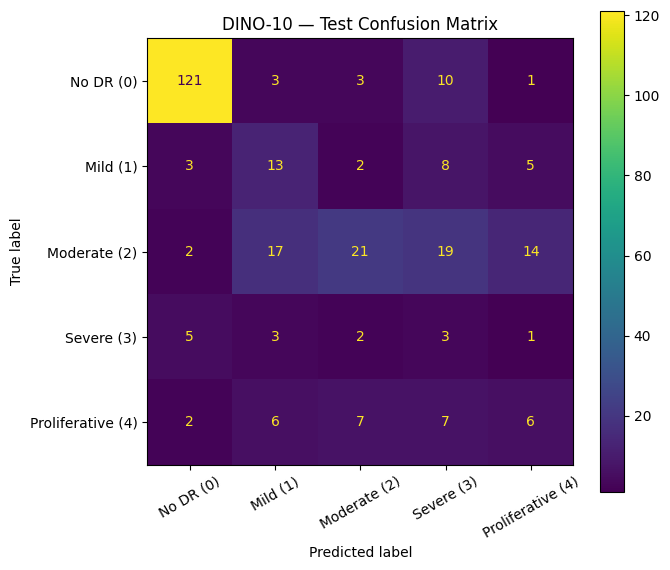


BYOL-10
[[134   0   3   0   1]
 [  2   8  19   1   1]
 [  8   4  54   2   5]
 [  2   2   7   2   1]
 [  2   2  18   3   3]]


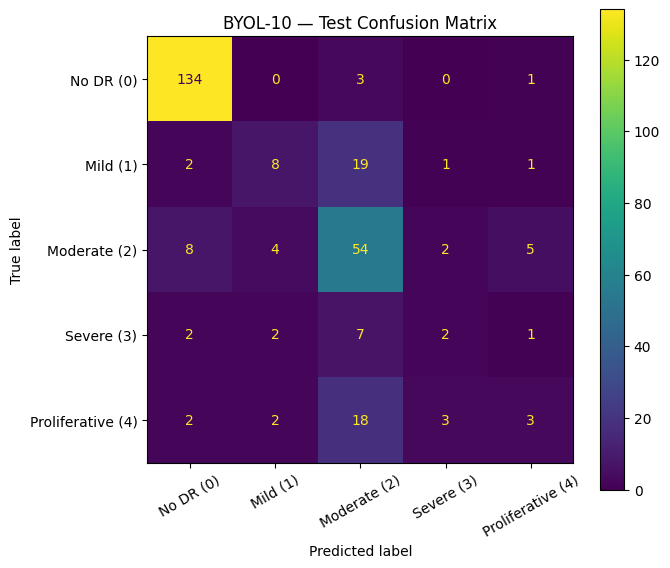


Improved DINO
[[138   0   0   0   0]
 [ 31   0   0   0   0]
 [ 73   0   0   0   0]
 [ 14   0   0   0   0]
 [ 28   0   0   0   0]]


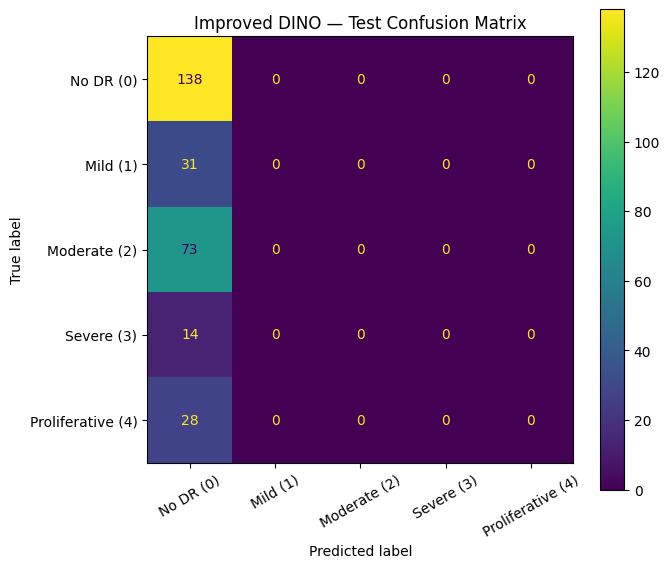

In [ ]:
# ============================================================
# CONFUSION MATRICES — FINAL MODELS
# ============================================================

import torch
import numpy as np
import matplotlib.pyplot as plt

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from xgboost import XGBClassifier

BASE = "/content/drive/MyDrive/EyePACS"

# ------------------------------------------------------------
# LOAD FEATURES
# ------------------------------------------------------------

train_dino = torch.load(
    BASE + "/features/train_dino_epoch10_features.pt",
    map_location="cpu"
)
valid_dino = torch.load(
    BASE + "/features/valid_dino_epoch10_features.pt",
    map_location="cpu"
)
test_dino = torch.load(
    BASE + "/features/test_dino_epoch10_features.pt",
    map_location="cpu"
)

train_byol = torch.load(
    BASE + "/features/train_byol_epoch10_features.pt",
    map_location="cpu"
)
valid_byol = torch.load(
    BASE + "/features/valid_byol_epoch10_features.pt",
    map_location="cpu"
)
test_byol = torch.load(
    BASE + "/features/test_byol_epoch10_features.pt",
    map_location="cpu"
)

train_imp = torch.load(
    BASE + "/features/train_improved_dino_features.pt",
    map_location="cpu"
)
valid_imp = torch.load(
    BASE + "/features/valid_improved_dino_features.pt",
    map_location="cpu"
)
test_imp = torch.load(
    BASE + "/features/test_improved_dino_features.pt",
    map_location="cpu"
)


# ------------------------------------------------------------
# LABELS
# ------------------------------------------------------------

y_train_dino = train_dino["labels"].numpy()
y_valid_dino = valid_dino["labels"].numpy()
y_test_dino = test_dino["labels"].numpy()

y_train_byol = train_byol["labels"].numpy()
y_valid_byol = valid_byol["labels"].numpy()
y_test_byol = test_byol["labels"].numpy()

y_train_imp = train_imp["labels"].numpy()
y_valid_imp = valid_imp["labels"].numpy()
y_test_imp = test_imp["labels"].numpy()


# ------------------------------------------------------------
# DINO — LOGISTIC REGRESSION
# ------------------------------------------------------------

X_dino_train = torch.cat([
    train_dino["features"],
    valid_dino["features"]
]).numpy()

y_dino_train = np.concatenate([
    y_train_dino,
    y_valid_dino
])

X_dino_test = test_dino["features"].numpy()

dino_clf = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

dino_clf.fit(
    X_dino_train,
    y_dino_train
)

dino_pred = dino_clf.predict(X_dino_test)


# ------------------------------------------------------------
# BYOL — XGBOOST
# ------------------------------------------------------------

X_byol_train = torch.cat([
    train_byol["features"],
    valid_byol["features"]
]).numpy()

y_byol_train = np.concatenate([
    y_train_byol,
    y_valid_byol
])

X_byol_test = test_byol["features"].numpy()

byol_clf = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softmax",
    num_class=5,
    eval_metric="mlogloss",
    random_state=42
)

byol_clf.fit(
    X_byol_train,
    y_byol_train
)

byol_pred = byol_clf.predict(X_byol_test)


# ------------------------------------------------------------
# IMPROVED DINO — BALANCED XGBOOST
# ------------------------------------------------------------

X_imp_train = torch.cat([
    train_imp["features"],
    valid_imp["features"]
]).numpy()

y_imp_train = np.concatenate([
    y_train_imp,
    y_valid_imp
])

X_imp_test = test_imp["features"].numpy()

# class weights
class_counts = np.bincount(y_imp_train)

sample_weights = np.array([
    1.0 / class_counts[y]
    for y in y_imp_train
])

imp_clf = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softmax",
    num_class=5,
    eval_metric="mlogloss",
    random_state=42
)

imp_clf.fit(
    X_imp_train,
    y_imp_train,
    sample_weight=sample_weights
)

imp_pred = imp_clf.predict(X_imp_test)


# ------------------------------------------------------------
# CONFUSION MATRICES
# ------------------------------------------------------------

models_results = [
    ("DINO-10", y_test_dino, dino_pred),
    ("BYOL-10", y_test_byol, byol_pred),
    ("Improved DINO", y_test_imp, imp_pred)
]

for name, y_true, y_pred in models_results:

    cm = confusion_matrix(
        y_true,
        y_pred,
        labels=[0, 1, 2, 3, 4]
    )

    print("\n", "=" * 50)
    print(name)
    print("=" * 50)
    print(cm)

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=[
            "No DR (0)",
            "Mild (1)",
            "Moderate (2)",
            "Severe (3)",
            "Proliferative (4)"
        ]
    )

    fig, ax = plt.subplots(figsize=(7, 6))

    disp.plot(
        ax=ax,
        values_format="d"
    )

    plt.title(name + " — Test Confusion Matrix")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

In [ ]:
# ============================================================
# TEST PREDICTION DIAGNOSTIC
# ============================================================

import numpy as np

print("TEST LABEL DISTRIBUTION")
print("\nDINO:")
print(np.bincount(y_test_dino, minlength=5))

print("\nBYOL:")
print(np.bincount(y_test_byol, minlength=5))

print("\nImproved DINO:")
print(np.bincount(y_test_imp, minlength=5))


print("\nPREDICTION DISTRIBUTION")
print("\nDINO:")
print(np.bincount(dino_pred.astype(int), minlength=5))

print("\nBYOL:")
print(np.bincount(byol_pred.astype(int), minlength=5))

print("\nImproved DINO:")
print(np.bincount(imp_pred.astype(int), minlength=5))


print("\nTEST ACCURACY")
print("DINO:", np.mean(dino_pred == y_test_dino) * 100)
print("BYOL:", np.mean(byol_pred == y_test_byol) * 100)
print("Improved DINO:", np.mean(imp_pred == y_test_imp) * 100)

TEST LABEL DISTRIBUTION

DINO:
[138  31  73  14  28]

BYOL:
[138  31  73  14  28]

Improved DINO:
[138  31  73  14  28]

PREDICTION DISTRIBUTION

DINO:
[133  42  35  47  27]

BYOL:
[148  16 101   8  11]

Improved DINO:
[284   0   0   0   0]

TEST ACCURACY
DINO: 57.74647887323944
BYOL: 70.77464788732394
Improved DINO: 48.59154929577465


In [ ]:
# ============================================================
# VERIFY CURRENT CLASSIFIERS ON VALIDATION SET
# ============================================================

from sklearn.metrics import accuracy_score

# DINO validation
dino_valid_pred = dino_clf.predict(
    valid_dino["features"].numpy()
)

# BYOL validation
byol_valid_pred = byol_clf.predict(
    valid_byol["features"].numpy()
)

# Improved DINO validation
imp_valid_pred = imp_clf.predict(
    valid_imp["features"].numpy()
)

print("CURRENT CLASSIFIER VALIDATION ACCURACY")
print("--------------------------------------")

print(
    "DINO:",
    accuracy_score(
        y_valid_dino,
        dino_valid_pred
    ) * 100
)

print(
    "BYOL:",
    accuracy_score(
        y_valid_byol,
        byol_valid_pred
    ) * 100
)

print(
    "Improved DINO:",
    accuracy_score(
        y_valid_imp,
        imp_valid_pred
    ) * 100
)

CURRENT CLASSIFIER VALIDATION ACCURACY
--------------------------------------
DINO: 66.37323943661971
BYOL: 100.0
Improved DINO: 50.70422535211267


In [ ]:
# ============================================================
# FAIR CLASSIFIER EVALUATION
# TRAIN ONLY -> VALIDATION
# ============================================================

import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score
from xgboost import XGBClassifier

# ------------------------------------------------------------
# DINO — Logistic Regression
# ------------------------------------------------------------

dino_lr = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

dino_lr.fit(
    train_dino["features"].numpy(),
    y_train_dino
)

dino_valid_pred = dino_lr.predict(
    valid_dino["features"].numpy()
)

print("\nDINO-10")
print("Accuracy:", accuracy_score(
    y_valid_dino, dino_valid_pred
) * 100)

print("Macro-F1:", f1_score(
    y_valid_dino,
    dino_valid_pred,
    average="macro"
) * 100)

print("QWK:", cohen_kappa_score(
    y_valid_dino,
    dino_valid_pred,
    weights="quadratic"
))


# ------------------------------------------------------------
# BYOL — XGBoost
# ------------------------------------------------------------

byol_xgb = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softmax",
    num_class=5,
    eval_metric="mlogloss",
    random_state=42
)

byol_xgb.fit(
    train_byol["features"].numpy(),
    y_train_byol
)

byol_valid_pred = byol_xgb.predict(
    valid_byol["features"].numpy()
)

print("\nBYOL-10")
print("Accuracy:", accuracy_score(
    y_valid_byol, byol_valid_pred
) * 100)

print("Macro-F1:", f1_score(
    y_valid_byol,
    byol_valid_pred,
    average="macro"
) * 100)

print("QWK:", cohen_kappa_score(
    y_valid_byol,
    byol_valid_pred,
    weights="quadratic"
))


# ------------------------------------------------------------
# IMPROVED DINO — BALANCED XGBoost
# ------------------------------------------------------------

imp_xgb = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softmax",
    num_class=5,
    eval_metric="mlogloss",
    random_state=42
)

class_counts = np.bincount(y_train_imp)

sample_weights = np.array([
    1.0 / class_counts[y]
    for y in y_train_imp
])

imp_xgb.fit(
    train_imp["features"].numpy(),
    y_train_imp,
    sample_weight=sample_weights
)

imp_valid_pred = imp_xgb.predict(
    valid_imp["features"].numpy()
)

print("\nImproved DINO")
print("Accuracy:", accuracy_score(
    y_valid_imp, imp_valid_pred
) * 100)

print("Macro-F1:", f1_score(
    y_valid_imp,
    imp_valid_pred,
    average="macro"
) * 100)

print("QWK:", cohen_kappa_score(
    y_valid_imp,
    imp_valid_pred,
    weights="quadratic"
))


DINO-10
Accuracy: 64.7887323943662
Macro-F1: 46.53737450036194
QWK: 0.6226180673998707

BYOL-10
Accuracy: 76.76056338028168
Macro-F1: 48.37686979747387
QWK: 0.7541975678949309

Improved DINO
Accuracy: 50.70422535211267
Macro-F1: 13.457943925233645
QWK: 0.0


In [ ]:
# ============================================================
# IMPROVED DINO DIAGNOSTIC
# ============================================================

import numpy as np

print("TRUE VALID LABEL DISTRIBUTION:")
print(np.bincount(y_valid_imp, minlength=5))

print("\nPREDICTED VALID LABEL DISTRIBUTION:")
print(np.bincount(
    imp_valid_pred.astype(int),
    minlength=5
))

print("\nTRAIN LABEL DISTRIBUTION:")
print(np.bincount(y_train_imp, minlength=5))

print("\nFEATURE SHAPES:")
print("Train:", train_imp["features"].shape)
print("Valid:", valid_imp["features"].shape)
print("Test :", test_imp["features"].shape)

TRUE VALID LABEL DISTRIBUTION:
[288  61 155  28  36]

PREDICTED VALID LABEL DISTRIBUTION:
[568   0   0   0   0]

TRAIN LABEL DISTRIBUTION:
[1004  202  538   89  153]

FEATURE SHAPES:
Train: torch.Size([1986, 384])
Valid: torch.Size([568, 384])
Test : torch.Size([284, 384])


In [ ]:
# ============================================================
# FIX IMPROVED DINO TRAIN/VALID FEATURE-LABEL ORDER
# COMPLETE CODE
# ============================================================

import os
import torch
import pandas as pd
from PIL import Image
from torchvision import transforms
import timm

# ------------------------------------------------------------
# 1. SETTINGS
# ------------------------------------------------------------

BASE = "/content/drive/MyDrive/EyePACS"

CHECKPOINT = (
    BASE +
    "/checkpoints/improved_dino_epoch_10.pth"
)

device = "cuda" if torch.cuda.is_available() else "cpu"

print("Device:", device)


# ------------------------------------------------------------
# 2. LOAD IMPROVED DINO MODEL
# ------------------------------------------------------------

print("\nLoading Improved DINO model...")

improved_dino_model = timm.create_model(
    "vit_small_patch16_224",
    pretrained=False,
    num_classes=0
)

checkpoint = torch.load(
    CHECKPOINT,
    map_location="cpu"
)

state = checkpoint.get(
    "student",
    checkpoint
)

# Keep only backbone keys
state = {
    k.replace("0.", "", 1): v
    for k, v in state.items()
    if k.startswith("0.")
}

missing, unexpected = improved_dino_model.load_state_dict(
    state,
    strict=False
)

print("Missing keys:", len(missing))
print("Unexpected keys:", len(unexpected))

improved_dino_model = improved_dino_model.to(device)
improved_dino_model.eval()

print("Improved DINO loaded successfully")


# ------------------------------------------------------------
# 3. TRANSFORM
# ------------------------------------------------------------

transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])


# ------------------------------------------------------------
# 4. GET IMAGE FILES + CORRECT LABELS
# ------------------------------------------------------------

def get_images_and_labels(csv_path, image_dir):

    df = pd.read_csv(csv_path)

    files = sorted([
        f
        for f in os.listdir(image_dir)
        if f.lower().endswith(
            (".jpg", ".jpeg", ".png")
        )
    ])

    label_map = {
        str(filename): int(level)
        for filename, level
        in zip(
            df["filename"],
            df["level"]
        )
    }

    labels = []

    for f in files:

        if f in label_map:

            labels.append(
                label_map[f]
            )

        elif os.path.splitext(f)[0] in label_map:

            labels.append(
                label_map[
                    os.path.splitext(f)[0]
                ]
            )

        else:

            raise ValueError(
                "Missing label for: " + f
            )

    return (
        files,
        torch.tensor(
            labels,
            dtype=torch.long
        )
    )


# ------------------------------------------------------------
# 5. EXTRACT FEATURES IN CURRENT IMAGE ORDER
# ------------------------------------------------------------

def extract_features(
    files,
    image_dir,
    model
):

    all_features = []

    model.eval()

    with torch.no_grad():

        for start in range(
            0,
            len(files),
            32
        ):

            batch_files = files[
                start:start + 32
            ]

            images = []

            for filename in batch_files:

                path = os.path.join(
                    image_dir,
                    filename
                )

                image = Image.open(
                    path
                ).convert("RGB")

                images.append(
                    transform(image)
                )

            images = torch.stack(
                images
            ).to(device)

            features = model(
                images
            )

            all_features.append(
                features.cpu()
            )

    return torch.cat(
        all_features
    )


# ------------------------------------------------------------
# 6. TRAIN FEATURES
# ------------------------------------------------------------

train_files, train_current_labels = (
    get_images_and_labels(
        BASE + "/dataset/train/labels.csv",
        BASE + "/dataset/train"
    )
)

print("\nTrain images:", len(train_files))

print("Extracting current-order TRAIN features...")

train_current_features = extract_features(
    train_files,
    BASE + "/dataset/train",
    improved_dino_model
)

print(
    "Current train features:",
    train_current_features.shape
)


# ------------------------------------------------------------
# 7. VALID FEATURES
# ------------------------------------------------------------

valid_files, valid_current_labels = (
    get_images_and_labels(
        BASE + "/dataset/valid/labels.csv",
        BASE + "/dataset/valid"
    )
)

print("\nValid images:", len(valid_files))

print("Extracting current-order VALID features...")

valid_current_features = extract_features(
    valid_files,
    BASE + "/dataset/valid",
    improved_dino_model
)

print(
    "Current valid features:",
    valid_current_features.shape
)


# ------------------------------------------------------------
# 8. LOAD SAVED IMPROVED DINO FEATURES
# ------------------------------------------------------------

print("\nLoading saved Improved DINO features...")

train_imp = torch.load(
    BASE +
    "/features/train_improved_dino_features.pt",
    map_location="cpu"
)

valid_imp = torch.load(
    BASE +
    "/features/valid_improved_dino_features.pt",
    map_location="cpu"
)

old_train_features = train_imp["features"]
old_valid_features = valid_imp["features"]

print(
    "Saved train features:",
    old_train_features.shape
)

print(
    "Saved valid features:",
    old_valid_features.shape
)


# ------------------------------------------------------------
# 9. MATCH TRAIN FEATURES
# ------------------------------------------------------------

print("\nMatching TRAIN feature rows...")

old_train_norm = torch.nn.functional.normalize(
    old_train_features,
    dim=1
)

new_train_norm = torch.nn.functional.normalize(
    train_current_features,
    dim=1
)

sim_train = torch.mm(
    old_train_norm,
    new_train_norm.T
)

train_best_sim, train_best_idx = (
    sim_train.max(dim=1)
)

print(
    "Train mean similarity:",
    train_best_sim.mean().item()
)

print(
    "Train matches > 0.99:",
    (train_best_sim > 0.99).sum().item(),
    "/",
    len(train_best_sim)
)

print(
    "Train unique matches:",
    len(torch.unique(train_best_idx)),
    "/",
    len(train_best_idx)
)


# ------------------------------------------------------------
# 10. MATCH VALID FEATURES
# ------------------------------------------------------------

print("\nMatching VALID feature rows...")

old_valid_norm = torch.nn.functional.normalize(
    old_valid_features,
    dim=1
)

new_valid_norm = torch.nn.functional.normalize(
    valid_current_features,
    dim=1
)

sim_valid = torch.mm(
    old_valid_norm,
    new_valid_norm.T
)

valid_best_sim, valid_best_idx = (
    sim_valid.max(dim=1)
)

print(
    "Valid mean similarity:",
    valid_best_sim.mean().item()
)

print(
    "Valid matches > 0.99:",
    (valid_best_sim > 0.99).sum().item(),
    "/",
    len(valid_best_sim)
)

print(
    "Valid unique matches:",
    len(torch.unique(valid_best_idx)),
    "/",
    len(valid_best_idx)
)


# ------------------------------------------------------------
# 11. CORRECT LABELS
# ------------------------------------------------------------

correct_train_imp_labels = (
    train_current_labels[
        train_best_idx
    ]
)

correct_valid_imp_labels = (
    valid_current_labels[
        valid_best_idx
    ]
)


# ------------------------------------------------------------
# 12. CHECK CORRECTED LABEL DISTRIBUTION
# ------------------------------------------------------------

print("\n==============================")
print("CORRECTED LABEL DISTRIBUTION")
print("==============================")

print(
    "Train:",
    torch.bincount(
        correct_train_imp_labels,
        minlength=5
    ).tolist()
)

print(
    "Valid:",
    torch.bincount(
        correct_valid_imp_labels,
        minlength=5
    ).tolist()
)

Device: cuda

Loading Improved DINO model...
Missing keys: 0
Unexpected keys: 0
Improved DINO loaded successfully

Train images: 1986
Extracting current-order TRAIN features...
Current train features: torch.Size([1986, 384])

Valid images: 568
Extracting current-order VALID features...
Current valid features: torch.Size([568, 384])

Loading saved Improved DINO features...
Saved train features: torch.Size([1986, 384])
Saved valid features: torch.Size([568, 384])

Matching TRAIN feature rows...
Train mean similarity: 0.9962826371192932
Train matches > 0.99: 1775 / 1986
Train unique matches: 1985 / 1986

Matching VALID feature rows...
Valid mean similarity: 0.9954666495323181
Valid matches > 0.99: 485 / 568
Valid unique matches: 568 / 568

CORRECTED LABEL DISTRIBUTION
Train: [1004, 202, 538, 89, 153]
Valid: [288, 61, 155, 28, 36]


In [ ]:
# ============================================================
# IMPROVED DINO — CORRECTED CLASSIFIER
# ============================================================

import numpy as np
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score
from xgboost import XGBClassifier

# ------------------------------------------------------------
# USE SAVED FEATURES + CORRECTED LABELS
# ------------------------------------------------------------

X_train = train_imp["features"].numpy()
X_valid = valid_imp["features"].numpy()

y_train = correct_train_imp_labels.numpy()
y_valid = correct_valid_imp_labels.numpy()

print("Train:", X_train.shape, y_train.shape)
print("Valid:", X_valid.shape, y_valid.shape)


# ------------------------------------------------------------
# 1. LOGISTIC REGRESSION
# ------------------------------------------------------------

lr = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

lr.fit(
    X_train,
    y_train
)

pred_lr = lr.predict(X_valid)

print("\nImproved DINO — Logistic Regression")
print(
    "Accuracy:",
    accuracy_score(y_valid, pred_lr) * 100
)

print(
    "Macro-F1:",
    f1_score(
        y_valid,
        pred_lr,
        average="macro"
    ) * 100
)

print(
    "QWK:",
    cohen_kappa_score(
        y_valid,
        pred_lr,
        weights="quadratic"
    )
)


# ------------------------------------------------------------
# 2. BALANCED XGBOOST
# ------------------------------------------------------------

class_counts = np.bincount(
    y_train,
    minlength=5
)

sample_weights = np.array([
    1.0 / class_counts[y]
    for y in y_train
])

xgb = XGBClassifier(
    n_estimators=300,
    max_depth=6,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softmax",
    num_class=5,
    eval_metric="mlogloss",
    random_state=42
)

xgb.fit(
    X_train,
    y_train,
    sample_weight=sample_weights
)

pred_xgb = xgb.predict(X_valid)

print("\nImproved DINO — Balanced XGBoost")
print(
    "Accuracy:",
    accuracy_score(y_valid, pred_xgb) * 100
)

print(
    "Macro-F1:",
    f1_score(
        y_valid,
        pred_xgb,
        average="macro"
    ) * 100
)

print(
    "QWK:",
    cohen_kappa_score(
        y_valid,
        pred_xgb,
        weights="quadratic"
    )
)


# ------------------------------------------------------------
# 3. PREDICTION DISTRIBUTION
# ------------------------------------------------------------

print("\nPrediction distribution:")

print(
    "Logistic Regression:",
    np.bincount(
        pred_lr.astype(int),
        minlength=5
    )
)

print(
    "Balanced XGBoost:",
    np.bincount(
        pred_xgb.astype(int),
        minlength=5
    )
)

Train: (1986, 384) (1986,)
Valid: (568, 384) (568,)

Improved DINO — Logistic Regression
Accuracy: 76.58450704225352
Macro-F1: 56.13950867474677
QWK: 0.8109173154041214

Improved DINO — Balanced XGBoost
Accuracy: 50.70422535211267
Macro-F1: 13.457943925233645
QWK: 0.0

Prediction distribution:
Logistic Regression: [300  64 131  28  45]
Balanced XGBoost: [568   0   0   0   0]


In [ ]:

# ============================================================
# FIX: EXTRACT CURRENT-ORDER IMPROVED DINO TEST FEATURES
# ============================================================

from PIL import Image
from torch.utils.data import DataLoader, Dataset
import os
import numpy as np

TEST_DIR = "/content/drive/MyDrive/EyePACS/dataset/test"

class SimpleTestDataset(Dataset):
    def __init__(self, image_files, transform):
        self.image_files = image_files
        self.transform = transform

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        path = os.path.join(TEST_DIR, self.image_files[idx])
        image = Image.open(path).convert("RGB")
        return self.transform(image)

test_dataset = SimpleTestDataset(
    test_image_files,
    transform
)

test_loader = DataLoader(
    test_dataset,
    batch_size=32,
    shuffle=False,
    num_workers=2
)

print("Extracting current-order test features...")

improved_dino_model.eval()

features = []

with torch.no_grad():
    for images in test_loader:
        images = images.cuda()

        output = improved_dino_model(images)

        features.append(output.cpu())

current_test_features = torch.cat(features, dim=0)

print("Current test features:", current_test_features.shape)

# ------------------------------------------------------------
# Match saved features to current image order
# ------------------------------------------------------------

old_norm = torch.nn.functional.normalize(
    old_test_features, dim=1
)

new_norm = torch.nn.functional.normalize(
    current_test_features, dim=1
)

sim = torch.mm(old_norm, new_norm.T)

best_sim, best_idx = sim.max(dim=1)

print("\nMean similarity:", best_sim.mean().item())
print(
    "Matches > 0.99:",
    (best_sim > 0.99).sum().item(),
    "/",
    len(best_sim)
)
print(
    "Unique matches:",
    len(torch.unique(best_idx)),
    "/",
    len(best_idx)
)

# Correct labels for saved feature order
correct_test_imp_labels = current_test_labels[best_idx]

print("\nCorrect test class distribution:")
print(
    np.bincount(
        correct_test_imp_labels.numpy(),
        minlength=5
    )
)

print("\nDONE.")

Extracting current-order test features...
Current test features: torch.Size([284, 384])

Mean similarity: 0.9958449602127075
Matches > 0.99: 248 / 284
Unique matches: 284 / 284

Correct test class distribution:
[138  31  73  14  28]

DONE.


In [ ]:
# ============================================================
# IMPROVED DINO — FINAL CLEAN TEST EVALUATION
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score,
    confusion_matrix,
    classification_report
)
import numpy as np

# Train data
X_train = train_imp["features"].numpy()
y_train = correct_train_imp_labels.numpy()

# Saved test features
X_test = test_imp_saved["features"].numpy()
y_test = correct_test_imp_labels.numpy()

print("Train:", X_train.shape)
print("Test:", X_test.shape)

# ------------------------------------------------------------
# Train ONLY on TRAIN
# ------------------------------------------------------------

final_lr = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

final_lr.fit(X_train, y_train)

# ------------------------------------------------------------
# Final TEST prediction
# ------------------------------------------------------------

pred_test = final_lr.predict(X_test)

# ------------------------------------------------------------
# Metrics
# ------------------------------------------------------------

accuracy = accuracy_score(y_test, pred_test)
macro_f1 = f1_score(y_test, pred_test, average="macro")
qwk = cohen_kappa_score(
    y_test,
    pred_test,
    weights="quadratic"
)

print("\n======================================")
print("IMPROVED DINO — FINAL TEST RESULTS")
print("======================================")

print("Accuracy:", accuracy * 100)
print("Macro-F1:", macro_f1 * 100)
print("QWK:", qwk)

print("\nPrediction distribution:")
print(np.bincount(pred_test.astype(int), minlength=5))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, pred_test))

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        pred_test,
        labels=[0, 1, 2, 3, 4],
        target_names=[
            "No DR",
            "Mild",
            "Moderate",
            "Severe",
            "Proliferative"
        ],
        zero_division=0
    )
)

Train: (1986, 384)
Test: (284, 384)

IMPROVED DINO — FINAL TEST RESULTS
Accuracy: 75.0
Macro-F1: 59.27926025921055
QWK: 0.8579145500090963

Prediction distribution:
[137  34  69  20  24]

Confusion Matrix:
[[131   5   2   0   0]
 [  4  16  10   0   1]
 [  2  10  46  11   4]
 [  0   1   4   5   4]
 [  0   2   7   4  15]]

Classification Report:
               precision    recall  f1-score   support

        No DR       0.96      0.95      0.95       138
         Mild       0.47      0.52      0.49        31
     Moderate       0.67      0.63      0.65        73
       Severe       0.25      0.36      0.29        14
Proliferative       0.62      0.54      0.58        28

     accuracy                           0.75       284
    macro avg       0.59      0.60      0.59       284
 weighted avg       0.76      0.75      0.75       284



In [ ]:
# ============================================================
# CHECK DINO TEST FEATURES + LABELS
# ============================================================

dino_test = torch.load(
    "/content/drive/MyDrive/EyePACS/features/test_dino_epoch10_features.pt",
    map_location="cpu"
)

print("DINO test features:", dino_test["features"].shape)
print("DINO saved labels:", dino_test["labels"].shape)

print(
    "DINO saved label distribution:",
    np.bincount(dino_test["labels"].numpy(), minlength=5)
)

print(
    "Ground-truth test distribution:",
    np.bincount(current_test_labels.numpy(), minlength=5)
)

DINO test features: torch.Size([284, 384])
DINO saved labels: torch.Size([284])
DINO saved label distribution: [138  31  73  14  28]
Ground-truth test distribution: [138  31  73  14  28]


In [ ]:
# ============================================================
# DINO — FINAL CLEAN TEST EVALUATION
# Train ONLY on TRAIN, evaluate ONCE on TEST
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score,
    confusion_matrix,
    classification_report
)
import numpy as np

# ------------------------------------------------------------
# Load DINO train features
# ------------------------------------------------------------

dino_train = torch.load(
    "/content/drive/MyDrive/EyePACS/features/train_dino_epoch10_features.pt",
    map_location="cpu"
)

X_train_dino = dino_train["features"].numpy()
y_train_dino = dino_train["labels"].numpy()

# ------------------------------------------------------------
# Test features + labels
# ------------------------------------------------------------

X_test_dino = dino_test["features"].numpy()
y_test_dino = dino_test["labels"].numpy()

print("Train:", X_train_dino.shape)
print("Test:", X_test_dino.shape)

# ------------------------------------------------------------
# Train ONLY on TRAIN
# ------------------------------------------------------------

dino_lr = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

dino_lr.fit(X_train_dino, y_train_dino)

# ------------------------------------------------------------
# Test prediction
# ------------------------------------------------------------

pred_dino = dino_lr.predict(X_test_dino)

# ------------------------------------------------------------
# Final metrics
# ------------------------------------------------------------

accuracy = accuracy_score(y_test_dino, pred_dino)
macro_f1 = f1_score(y_test_dino, pred_dino, average="macro")
qwk = cohen_kappa_score(
    y_test_dino,
    pred_dino,
    weights="quadratic"
)

print("\n======================================")
print("DINO — FINAL TEST RESULTS")
print("======================================")

print("Accuracy:", accuracy * 100)
print("Macro-F1:", macro_f1 * 100)
print("QWK:", qwk)

print("\nPrediction distribution:")
print(np.bincount(pred_dino.astype(int), minlength=5))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_dino, pred_dino))

print("\nClassification Report:")
print(
    classification_report(
        y_test_dino,
        pred_dino,
        labels=[0, 1, 2, 3, 4],
        target_names=[
            "No DR",
            "Mild",
            "Moderate",
            "Severe",
            "Proliferative"
        ],
        zero_division=0
    )
)

Train: (1986, 384)
Test: (284, 384)

DINO — FINAL TEST RESULTS
Accuracy: 58.098591549295776
Macro-F1: 39.31261375967259
QWK: 0.5567047845083338

Prediction distribution:
[137  46  38  40  23]

Confusion Matrix:
[[122   2   7   7   0]
 [  3  15   2   7   4]
 [  4  20  19  17  13]
 [  5   3   3   3   0]
 [  3   6   7   6   6]]

Classification Report:
               precision    recall  f1-score   support

        No DR       0.89      0.88      0.89       138
         Mild       0.33      0.48      0.39        31
     Moderate       0.50      0.26      0.34        73
       Severe       0.07      0.21      0.11        14
Proliferative       0.26      0.21      0.24        28

     accuracy                           0.58       284
    macro avg       0.41      0.41      0.39       284
 weighted avg       0.63      0.58      0.59       284



In [ ]:
# ============================================================
# CHECK BYOL TEST FEATURES + LABELS
# ============================================================

byol_test = torch.load(
    "/content/drive/MyDrive/EyePACS/features/test_byol_epoch10_features.pt",
    map_location="cpu"
)

print("BYOL test features:", byol_test["features"].shape)
print("BYOL saved labels:", byol_test["labels"].shape)

print(
    "BYOL saved label distribution:",
    np.bincount(byol_test["labels"].numpy(), minlength=5)
)

print(
    "Ground-truth test distribution:",
    np.bincount(current_test_labels.numpy(), minlength=5)
)

BYOL test features: torch.Size([284, 512])
BYOL saved labels: torch.Size([284])
BYOL saved label distribution: [138  31  73  14  28]
Ground-truth test distribution: [138  31  73  14  28]


In [ ]:
# ============================================================
# BYOL — FINAL CLEAN TEST EVALUATION
# Train ONLY on TRAIN, evaluate ONCE on TEST
# ============================================================

from sklearn.linear_model import LogisticRegression
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score,
    confusion_matrix,
    classification_report
)
import numpy as np

# ------------------------------------------------------------
# Load BYOL train features
# ------------------------------------------------------------

byol_train = torch.load(
    "/content/drive/MyDrive/EyePACS/features/train_byol_epoch10_features.pt",
    map_location="cpu"
)

X_train_byol = byol_train["features"].numpy()
y_train_byol = byol_train["labels"].numpy()

# ------------------------------------------------------------
# Test features + labels
# ------------------------------------------------------------

X_test_byol = byol_test["features"].numpy()
y_test_byol = byol_test["labels"].numpy()

print("Train:", X_train_byol.shape)
print("Test:", X_test_byol.shape)

# ------------------------------------------------------------
# Train ONLY on TRAIN
# ------------------------------------------------------------

byol_lr = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

byol_lr.fit(X_train_byol, y_train_byol)

# ------------------------------------------------------------
# Test prediction
# ------------------------------------------------------------

pred_byol = byol_lr.predict(X_test_byol)

# ------------------------------------------------------------
# Final metrics
# ------------------------------------------------------------

accuracy = accuracy_score(y_test_byol, pred_byol)
macro_f1 = f1_score(y_test_byol, pred_byol, average="macro")
qwk = cohen_kappa_score(
    y_test_byol,
    pred_byol,
    weights="quadratic"
)

print("\n======================================")
print("BYOL — FINAL TEST RESULTS")
print("======================================")

print("Accuracy:", accuracy * 100)
print("Macro-F1:", macro_f1 * 100)
print("QWK:", qwk)

print("\nPrediction distribution:")
print(np.bincount(pred_byol.astype(int), minlength=5))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test_byol, pred_byol))

print("\nClassification Report:")
print(
    classification_report(
        y_test_byol,
        pred_byol,
        labels=[0, 1, 2, 3, 4],
        target_names=[
            "No DR",
            "Mild",
            "Moderate",
            "Severe",
            "Proliferative"
        ],
        zero_division=0
    )
)

Train: (1986, 512)
Test: (284, 512)

BYOL — FINAL TEST RESULTS
Accuracy: 61.97183098591549
Macro-F1: 46.02390289449113
QWK: 0.5947348550293396

Prediction distribution:
[132  44  39  37  32]

Confusion Matrix:
[[123   3   2   8   2]
 [  1  18   3   2   7]
 [  5  18  20  15  15]
 [  0   1   2   9   2]
 [  3   4  12   3   6]]

Classification Report:
               precision    recall  f1-score   support

        No DR       0.93      0.89      0.91       138
         Mild       0.41      0.58      0.48        31
     Moderate       0.51      0.27      0.36        73
       Severe       0.24      0.64      0.35        14
Proliferative       0.19      0.21      0.20        28

     accuracy                           0.62       284
    macro avg       0.46      0.52      0.46       284
 weighted avg       0.66      0.62      0.62       284



In [ ]:
# ============================================================
# CHECK ROBUSTNESS DATA
# ============================================================

import os

ROBUSTNESS_BASE = "/content/drive/MyDrive/EyePACS/robustness"

conditions = ["brightness", "contrast", "noise", "blur"]

print("Robustness dataset check")
print("========================")

for condition in conditions:
    folder = os.path.join(ROBUSTNESS_BASE, condition)

    files = [
        f for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    print(f"{condition:10s}: {len(files)} images")

Robustness dataset check
brightness: 284 images
contrast  : 284 images
noise     : 284 images
blur      : 284 images


In [ ]:
# ============================================================
# IMPROVED DINO — ROBUSTNESS EVALUATION
# Brightness / Contrast / Noise / Blur
# ============================================================

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score
import numpy as np
import os
import torch

ROBUSTNESS_BASE = "/content/drive/MyDrive/EyePACS/robustness"

conditions = [
    "brightness",
    "contrast",
    "noise",
    "blur"
]

# ------------------------------------------------------------
# Use the SAME Improved DINO classifier
# ------------------------------------------------------------

X_train_imp = train_imp["features"].numpy()
y_train_imp = correct_train_imp_labels.numpy()

robust_lr = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

robust_lr.fit(X_train_imp, y_train_imp)

# ------------------------------------------------------------
# Dataset
# ------------------------------------------------------------

class RobustnessDataset(Dataset):
    def __init__(self, image_files, folder, transform):
        self.image_files = image_files
        self.folder = folder
        self.transform = transform

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        filename = self.image_files[idx]

        path = os.path.join(self.folder, filename)

        image = Image.open(path).convert("RGB")
        image = self.transform(image)

        return image

# ------------------------------------------------------------
# Ground-truth labels using SAME test filename order
# ------------------------------------------------------------

robust_labels = current_test_labels.numpy()

results = []

for condition in conditions:

    print(f"\nProcessing: {condition}")

    folder = os.path.join(
        ROBUSTNESS_BASE,
        condition
    )

    dataset = RobustnessDataset(
        test_image_files,
        folder,
        transform
    )

    loader = DataLoader(
        dataset,
        batch_size=32,
        shuffle=False,
        num_workers=2
    )

    features = []

    improved_dino_model.eval()

    with torch.no_grad():

        for images in loader:

            images = images.cuda()

            output = improved_dino_model(images)

            features.append(output.cpu())

    features = torch.cat(features, dim=0)

    print("Features:", features.shape)

    # --------------------------------------------------------
    # Predict using classifier trained ONLY on clean TRAIN
    # --------------------------------------------------------

    predictions = robust_lr.predict(
        features.numpy()
    )

    accuracy = accuracy_score(
        robust_labels,
        predictions
    )

    macro_f1 = f1_score(
        robust_labels,
        predictions,
        average="macro"
    )

    qwk = cohen_kappa_score(
        robust_labels,
        predictions,
        weights="quadratic"
    )

    results.append([
        condition,
        accuracy * 100,
        macro_f1 * 100,
        qwk
    ])

    print(
        f"{condition}: "
        f"Accuracy={accuracy*100:.2f}% | "
        f"Macro-F1={macro_f1*100:.2f}% | "
        f"QWK={qwk:.3f}"
    )

# ------------------------------------------------------------
# Final table
# ------------------------------------------------------------

print("\n==========================================")
print("IMPROVED DINO — ROBUSTNESS RESULTS")
print("==========================================")

print(
    f"{'Condition':<15}"
    f"{'Accuracy':>12}"
    f"{'Macro-F1':>12}"
    f"{'QWK':>10}"
)

print("-" * 50)

for row in results:

    print(
        f"{row[0]:<15}"
        f"{row[1]:>11.2f}%"
        f"{row[2]:>11.2f}%"
        f"{row[3]:>10.3f}"
    )


Processing: brightness
Features: torch.Size([284, 384])
brightness: Accuracy=65.14% | Macro-F1=49.63% | QWK=0.772

Processing: contrast
Features: torch.Size([284, 384])
contrast: Accuracy=67.61% | Macro-F1=49.59% | QWK=0.753

Processing: noise
Features: torch.Size([284, 384])
noise: Accuracy=34.15% | Macro-F1=27.93% | QWK=0.249

Processing: blur
Features: torch.Size([284, 384])
blur: Accuracy=56.69% | Macro-F1=31.16% | QWK=0.534

IMPROVED DINO — ROBUSTNESS RESULTS
Condition          Accuracy    Macro-F1       QWK
--------------------------------------------------
brightness           65.14%      49.63%     0.772
contrast             67.61%      49.59%     0.753
noise                34.15%      27.93%     0.249
blur                 56.69%      31.16%     0.534


In [ ]:
# ============================================================
# DINO — ROBUSTNESS EVALUATION
# ============================================================

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score
import numpy as np
import os
import torch

ROBUSTNESS_BASE = "/content/drive/MyDrive/EyePACS/robustness"

conditions = ["brightness", "contrast", "noise", "blur"]

# ------------------------------------------------------------
# Train DINO classifier ONLY on clean TRAIN
# ------------------------------------------------------------

dino_train = torch.load(
    "/content/drive/MyDrive/EyePACS/features/train_dino_epoch10_features.pt",
    map_location="cpu"
)

dino_lr_robust = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

dino_lr_robust.fit(
    dino_train["features"].numpy(),
    dino_train["labels"].numpy()
)

# ------------------------------------------------------------
# Dataset
# ------------------------------------------------------------

class DINOTestDataset(Dataset):
    def __init__(self, image_files, folder, transform):
        self.image_files = image_files
        self.folder = folder
        self.transform = transform

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):
        path = os.path.join(
            self.folder,
            self.image_files[idx]
        )

        image = Image.open(path).convert("RGB")
        return self.transform(image)

# Correct test labels
dino_robust_labels = current_test_labels.numpy()

results_dino = []

for condition in conditions:

    print(f"\nProcessing: {condition}")

    folder = os.path.join(
        ROBUSTNESS_BASE,
        condition
    )

    dataset = DINOTestDataset(
        test_image_files,
        folder,
        transform
    )

    loader = DataLoader(
        dataset,
        batch_size=32,
        shuffle=False,
        num_workers=2
    )

    features = []

    improved_dino_model.eval()

    # IMPORTANT:
    # Load the original DINO model before extraction
    if "dino_model" not in globals():
        dino_model = timm.create_model(
            "vit_small_patch16_224",
            pretrained=False,
            num_classes=0
        )

        ckpt = torch.load(
            "/content/drive/MyDrive/EyePACS/checkpoints/dino_epoch_10.pth",
            map_location="cpu"
        )

        state = ckpt["student"]

        state = {
            k.replace("0.", "", 1): v
            for k, v in state.items()
            if k.startswith("0.")
        }

        dino_model.load_state_dict(
            state,
            strict=False
        )

        dino_model = dino_model.cuda()
        dino_model.eval()

    with torch.no_grad():

        for images in loader:

            images = images.cuda()

            output = dino_model(images)

            features.append(
                output.cpu()
            )

    features = torch.cat(
        features,
        dim=0
    )

    print("Features:", features.shape)

    predictions = dino_lr_robust.predict(
        features.numpy()
    )

    accuracy = accuracy_score(
        dino_robust_labels,
        predictions
    )

    macro_f1 = f1_score(
        dino_robust_labels,
        predictions,
        average="macro"
    )

    qwk = cohen_kappa_score(
        dino_robust_labels,
        predictions,
        weights="quadratic"
    )

    results_dino.append([
        condition,
        accuracy * 100,
        macro_f1 * 100,
        qwk
    ])

    print(
        f"{condition}: "
        f"Accuracy={accuracy*100:.2f}% | "
        f"Macro-F1={macro_f1*100:.2f}% | "
        f"QWK={qwk:.3f}"
    )

print("\n==========================================")
print("DINO — ROBUSTNESS RESULTS")
print("==========================================")

for row in results_dino:
    print(
        f"{row[0]:<15}"
        f"{row[1]:>10.2f}%"
        f"{row[2]:>12.2f}%"
        f"{row[3]:>10.3f}"
    )


Processing: brightness
Features: torch.Size([284, 384])
brightness: Accuracy=34.51% | Macro-F1=23.84% | QWK=0.099

Processing: contrast
Features: torch.Size([284, 384])
contrast: Accuracy=25.35% | Macro-F1=22.73% | QWK=0.083

Processing: noise
Features: torch.Size([284, 384])
noise: Accuracy=57.75% | Macro-F1=39.36% | QWK=0.540

Processing: blur
Features: torch.Size([284, 384])
blur: Accuracy=57.39% | Macro-F1=38.79% | QWK=0.555

DINO — ROBUSTNESS RESULTS
brightness          34.51%       23.84%     0.099
contrast            25.35%       22.73%     0.083
noise               57.75%       39.36%     0.540
blur                57.39%       38.79%     0.555


In [ ]:
# ============================================================
# BYOL — ROBUSTNESS EVALUATION
# ============================================================

from PIL import Image
from torch.utils.data import Dataset, DataLoader
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score
import numpy as np
import os
import torch

ROBUSTNESS_BASE = "/content/drive/MyDrive/EyePACS/robustness"

conditions = ["brightness", "contrast", "noise", "blur"]

# ------------------------------------------------------------
# Train BYOL classifier ONLY on clean TRAIN
# ------------------------------------------------------------

byol_train = torch.load(
    "/content/drive/MyDrive/EyePACS/features/train_byol_epoch10_features.pt",
    map_location="cpu"
)

byol_lr_robust = LogisticRegression(
    class_weight="balanced",
    max_iter=2000,
    random_state=42
)

byol_lr_robust.fit(
    byol_train["features"].numpy(),
    byol_train["labels"].numpy()
)

# ------------------------------------------------------------
# Load BYOL backbone
# ------------------------------------------------------------

byol_model = timm.create_model(
    "resnet18",
    pretrained=False,
    num_classes=0
)

byol_ckpt = torch.load(
    "/content/drive/MyDrive/EyePACS/checkpoints/byol_epoch_10.pth",
    map_location="cpu"
)

online_state = byol_ckpt["online"]

# Remove projector/predictor-related keys if present
backbone_state = {
    k: v for k, v in online_state.items()
    if k in byol_model.state_dict()
}

missing, unexpected = byol_model.load_state_dict(
    backbone_state,
    strict=False
)

print("BYOL missing keys:", len(missing))
print("BYOL unexpected keys:", len(unexpected))

byol_model = byol_model.cuda()
byol_model.eval()

# ------------------------------------------------------------
# Dataset
# ------------------------------------------------------------

class BYOLRobustnessDataset(Dataset):

    def __init__(self, image_files, folder, transform):
        self.image_files = image_files
        self.folder = folder
        self.transform = transform

    def __len__(self):
        return len(self.image_files)

    def __getitem__(self, idx):

        filename = self.image_files[idx]

        path = os.path.join(
            self.folder,
            filename
        )

        image = Image.open(path).convert("RGB")

        return self.transform(image)

# ------------------------------------------------------------
# Correct test labels
# ------------------------------------------------------------

byol_robust_labels = current_test_labels.numpy()

results_byol = []

# ------------------------------------------------------------
# Evaluate each corruption
# ------------------------------------------------------------

for condition in conditions:

    print(f"\nProcessing: {condition}")

    folder = os.path.join(
        ROBUSTNESS_BASE,
        condition
    )

    dataset = BYOLRobustnessDataset(
        test_image_files,
        folder,
        transform
    )

    loader = DataLoader(
        dataset,
        batch_size=32,
        shuffle=False,
        num_workers=2
    )

    features = []

    with torch.no_grad():

        for images in loader:

            images = images.cuda()

            output = byol_model(images)

            features.append(
                output.cpu()
            )

    features = torch.cat(
        features,
        dim=0
    )

    print("Features:", features.shape)

    predictions = byol_lr_robust.predict(
        features.numpy()
    )

    accuracy = accuracy_score(
        byol_robust_labels,
        predictions
    )

    macro_f1 = f1_score(
        byol_robust_labels,
        predictions,
        average="macro"
    )

    qwk = cohen_kappa_score(
        byol_robust_labels,
        predictions,
        weights="quadratic"
    )

    results_byol.append([
        condition,
        accuracy * 100,
        macro_f1 * 100,
        qwk
    ])

    print(
        f"{condition}: "
        f"Accuracy={accuracy*100:.2f}% | "
        f"Macro-F1={macro_f1*100:.2f}% | "
        f"QWK={qwk:.3f}"
    )

# ------------------------------------------------------------
# Final table
# ------------------------------------------------------------

print("\n==========================================")
print("BYOL — ROBUSTNESS RESULTS")
print("==========================================")

for row in results_byol:

    print(
        f"{row[0]:<15}"
        f"{row[1]:>10.2f}%"
        f"{row[2]:>12.2f}%"
        f"{row[3]:>10.3f}"
    )

BYOL missing keys: 0
BYOL unexpected keys: 0

Processing: brightness
Features: torch.Size([284, 512])
brightness: Accuracy=46.48% | Macro-F1=35.48% | QWK=0.343

Processing: contrast
Features: torch.Size([284, 512])
contrast: Accuracy=16.90% | Macro-F1=10.11% | QWK=0.022

Processing: noise
Features: torch.Size([284, 512])
noise: Accuracy=25.70% | Macro-F1=17.60% | QWK=0.190

Processing: blur
Features: torch.Size([284, 512])
blur: Accuracy=60.21% | Macro-F1=41.67% | QWK=0.550

BYOL — ROBUSTNESS RESULTS
brightness          46.48%       35.48%     0.343
contrast            16.90%       10.11%     0.022
noise               25.70%       17.60%     0.190
blur                60.21%       41.67%     0.550


In [ ]:
# ============================================================
# SAVE FINAL DINO vs BYOL vs IMPROVED DINO RESULTS
# ============================================================

import pandas as pd
import os

results_dir = "/content/drive/MyDrive/EyePACS/results"
os.makedirs(results_dir, exist_ok=True)

final_results = [

    # ---------------- CLEAN TEST ----------------
    ["DINO", "Clean", 58.0986, 39.3126, 0.5567],
    ["BYOL", "Clean", 61.9718, 46.0239, 0.5947],
    ["Improved DINO", "Clean", 75.0000, 59.2793, 0.8579],

    # ---------------- ROBUSTNESS ----------------
    ["DINO", "Brightness", 34.51, 23.84, 0.099],
    ["DINO", "Contrast",   25.35, 22.73, 0.083],
    ["DINO", "Noise",      57.75, 39.36, 0.540],
    ["DINO", "Blur",       57.39, 38.79, 0.555],

    ["BYOL", "Brightness", 46.48, 35.48, 0.343],
    ["BYOL", "Contrast",   16.90, 10.11, 0.022],
    ["BYOL", "Noise",      25.70, 17.60, 0.190],
    ["BYOL", "Blur",       60.21, 41.67, 0.550],

    ["Improved DINO", "Brightness", 65.14, 49.63, 0.772],
    ["Improved DINO", "Contrast",   67.61, 49.59, 0.753],
    ["Improved DINO", "Noise",      34.15, 27.93, 0.249],
    ["Improved DINO", "Blur",       56.69, 31.16, 0.534],
]

df_final = pd.DataFrame(
    final_results,
    columns=[
        "Model",
        "Condition",
        "Accuracy (%)",
        "Macro-F1 (%)",
        "QWK"
    ]
)

save_path = os.path.join(
    results_dir,
    "FINAL_DINO_BYOL_RESULTS.csv"
)

df_final.to_csv(
    save_path,
    index=False
)

print("FINAL RESULTS SAVED")
print(save_path)

print("\nFinal table:")
display(df_final)

FINAL RESULTS SAVED
/content/drive/MyDrive/EyePACS/results/FINAL_DINO_BYOL_RESULTS.csv

Final table:


,Model,Condition,Accuracy (%),Macro-F1 (%),QWK
0,DINO,Clean,58.0986,39.3126,0.5567
1,BYOL,Clean,61.9718,46.0239,0.5947
2,Improved DINO,Clean,75.0000,59.2793,0.8579
3,DINO,Brightness,34.5100,23.8400,0.0990
4,DINO,Contrast,25.3500,22.7300,0.0830
5,DINO,Noise,57.7500,39.3600,0.5400
6,DINO,Blur,57.3900,38.7900,0.5550
7,BYOL,Brightness,46.4800,35.4800,0.3430
8,BYOL,Contrast,16.9000,10.1100,0.0220
9,BYOL,Noise,25.7000,17.6000,0.1900


In [ ]:
# ============================================================
# IMPROVED DINO — RBF SVM VALIDATION EXPERIMENT
# TEST SET IS NOT USED
# ============================================================

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

X_train = train_imp["features"].numpy()
y_train = correct_train_imp_labels.numpy()

X_valid = valid_imp["features"].numpy()
y_valid = correct_valid_imp_labels.numpy()

print("Train:", X_train.shape)
print("Valid:", X_valid.shape)

# RBF SVM
svm = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=10,
        gamma="scale",
        class_weight="balanced"
    )
)

svm.fit(X_train, y_train)

pred_svm = svm.predict(X_valid)

accuracy = accuracy_score(y_valid, pred_svm)
macro_f1 = f1_score(y_valid, pred_svm, average="macro")
qwk = cohen_kappa_score(
    y_valid,
    pred_svm,
    weights="quadratic"
)

print("\n======================================")
print("IMPROVED DINO — RBF SVM VALIDATION")
print("======================================")

print("Accuracy:", accuracy * 100)
print("Macro-F1:", macro_f1 * 100)
print("QWK:", qwk)

Train: (1986, 384)
Valid: (568, 384)

IMPROVED DINO — RBF SVM VALIDATION
Accuracy: 79.04929577464789
Macro-F1: 59.598624621212984
QWK: 0.8320830929024813


In [ ]:
# ============================================================
# IMPROVED DINO + RBF SVM — FINAL TEST
# ============================================================

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score,
    confusion_matrix,
    classification_report
)
import numpy as np

# ------------------------------------------------------------
# TRAIN ONLY
# ------------------------------------------------------------

X_train = train_imp["features"].numpy()
y_train = correct_train_imp_labels.numpy()

# ------------------------------------------------------------
# TEST
# ------------------------------------------------------------

X_test = test_imp_saved["features"].numpy()
y_test = correct_test_imp_labels.numpy()

# ------------------------------------------------------------
# RBF SVM selected using VALIDATION
# ------------------------------------------------------------

final_svm = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=10,
        gamma="scale",
        class_weight="balanced"
    )
)

final_svm.fit(X_train, y_train)

# ------------------------------------------------------------
# FINAL TEST PREDICTION
# ------------------------------------------------------------

pred_test_svm = final_svm.predict(X_test)

accuracy = accuracy_score(y_test, pred_test_svm)
macro_f1 = f1_score(
    y_test,
    pred_test_svm,
    average="macro"
)
qwk = cohen_kappa_score(
    y_test,
    pred_test_svm,
    weights="quadratic"
)

print("\n======================================")
print("IMPROVED DINO + RBF SVM — FINAL TEST")
print("======================================")

print("Accuracy:", accuracy * 100)
print("Macro-F1:", macro_f1 * 100)
print("QWK:", qwk)

print("\nPrediction distribution:")
print(
    np.bincount(
        pred_test_svm.astype(int),
        minlength=5
    )
)

print("\nConfusion Matrix:")
print(
    confusion_matrix(
        y_test,
        pred_test_svm
    )
)

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        pred_test_svm,
        labels=[0, 1, 2, 3, 4],
        target_names=[
            "No DR",
            "Mild",
            "Moderate",
            "Severe",
            "Proliferative"
        ],
        zero_division=0
    )
)


IMPROVED DINO + RBF SVM — FINAL TEST
Accuracy: 75.35211267605634
Macro-F1: 55.446230711850696
QWK: 0.8335178118901285

Prediction distribution:
[140  29  79  17  19]

Confusion Matrix:
[[135   1   2   0   0]
 [  2  17  11   0   1]
 [  2   9  50  10   2]
 [  0   1   3   3   7]
 [  1   1  13   4   9]]

Classification Report:
               precision    recall  f1-score   support

        No DR       0.96      0.98      0.97       138
         Mild       0.59      0.55      0.57        31
     Moderate       0.63      0.68      0.66        73
       Severe       0.18      0.21      0.19        14
Proliferative       0.47      0.32      0.38        28

     accuracy                           0.75       284
    macro avg       0.57      0.55      0.55       284
 weighted avg       0.75      0.75      0.75       284



In [ ]:
# ============================================================
# IMPROVED DINO + RBF SVM — ROBUSTNESS TEST
# ============================================================

import os
import numpy as np
import torch
from PIL import Image
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

device = "cuda" if torch.cuda.is_available() else "cpu"

# ------------------------------------------------------------
# 1. Train FINAL RBF SVM using CLEAN TRAIN FEATURES ONLY
# ------------------------------------------------------------

X_train = train_imp["features"].numpy()
y_train = correct_train_imp_labels.numpy()

final_svm = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=10,
        gamma="scale",
        class_weight="balanced"
    )
)

final_svm.fit(X_train, y_train)

print("SVM trained using CLEAN TRAIN data only.")


# ------------------------------------------------------------
# 2. Function to extract Improved DINO features
# ------------------------------------------------------------

def extract_improved_dino_features(folder):

    files = sorted([
        os.path.join(folder, f)
        for f in os.listdir(folder)
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ])

    features = []

    improved_dino_model.eval()

    with torch.no_grad():
        for i in range(0, len(files), 16):

            batch_files = files[i:i+16]
            images = []

            for path in batch_files:
                img = Image.open(path).convert("RGB")
                img = transform(img)
                images.append(img)

            batch = torch.stack(images).to(device)

            feat = improved_dino_model(batch)
            features.append(feat.cpu())

    return torch.cat(features, dim=0), files


# ------------------------------------------------------------
# 3. Evaluate each corruption
# ------------------------------------------------------------

base = "/content/drive/MyDrive/EyePACS/robustness"

corruptions = [
    "brightness",
    "contrast",
    "noise",
    "blur"
]

# Ground-truth labels
gt = correct_test_imp_labels.numpy()

results = []

for corruption in corruptions:

    folder = os.path.join(base, corruption)

    X_corrupt, files = extract_improved_dino_features(folder)

    X_corrupt = X_corrupt.numpy()

    # Safety check
    assert len(X_corrupt) == len(gt), (
        f"{corruption}: feature count {len(X_corrupt)} "
        f"!= labels {len(gt)}"
    )

    pred = final_svm.predict(X_corrupt)

    acc = accuracy_score(gt, pred) * 100
    macro_f1 = f1_score(gt, pred, average="macro") * 100
    qwk = cohen_kappa_score(gt, pred, weights="quadratic")

    results.append([
        corruption,
        acc,
        macro_f1,
        qwk
    ])

    print("\n--------------------------------------")
    print(corruption.upper())
    print("--------------------------------------")
    print("Accuracy :", round(acc, 2))
    print("Macro-F1 :", round(macro_f1, 2))
    print("QWK      :", round(qwk, 3))


# ------------------------------------------------------------
# 4. Final summary
# ------------------------------------------------------------

print("\n======================================")
print("IMPROVED DINO + RBF SVM — ROBUSTNESS")
print("======================================")

print(
    f"{'Condition':<15}"
    f"{'Accuracy':>12}"
    f"{'Macro-F1':>12}"
    f"{'QWK':>10}"
)

print("-" * 49)

# Clean result
clean_pred = final_svm.predict(
    test_imp_saved["features"].numpy()
)

clean_acc = accuracy_score(
    correct_test_imp_labels.numpy(),
    clean_pred
) * 100

clean_f1 = f1_score(
    correct_test_imp_labels.numpy(),
    clean_pred,
    average="macro"
) * 100

clean_qwk = cohen_kappa_score(
    correct_test_imp_labels.numpy(),
    clean_pred,
    weights="quadratic"
)

print(
    f"{'Clean':<15}"
    f"{clean_acc:>11.2f}%"
    f"{clean_f1:>11.2f}%"
    f"{clean_qwk:>10.3f}"
)

for r in results:
    print(
        f"{r[0].capitalize():<15}"
        f"{r[1]:>11.2f}%"
        f"{r[2]:>11.2f}%"
        f"{r[3]:>10.3f}"
    )

SVM trained using CLEAN TRAIN data only.

--------------------------------------
BRIGHTNESS
--------------------------------------
Accuracy : 31.34
Macro-F1 : 20.99
QWK      : -0.076

--------------------------------------
CONTRAST
--------------------------------------
Accuracy : 30.63
Macro-F1 : 16.26
QWK      : -0.118

--------------------------------------
NOISE
--------------------------------------
Accuracy : 22.54
Macro-F1 : 18.72
QWK      : -0.067

--------------------------------------
BLUR
--------------------------------------
Accuracy : 30.63
Macro-F1 : 22.08
QWK      : -0.047

IMPROVED DINO + RBF SVM — ROBUSTNESS
Condition          Accuracy    Macro-F1       QWK
-------------------------------------------------
Clean                75.35%      55.45%     0.834
Brightness           31.34%      20.99%    -0.076
Contrast             30.63%      16.26%    -0.118
Noise                22.54%      18.72%    -0.067
Blur                 30.63%      22.08%    -0.047


In [ ]:
# ============================================================
# SAVE FINAL PROJECT RESULTS
# ============================================================

import pandas as pd

final_results = pd.DataFrame([
    ["DINO", "Logistic Regression", "Clean", 58.10, 39.31, 0.557],
    ["BYOL", "Logistic Regression", "Clean", 61.97, 46.02, 0.595],
    ["Improved DINO", "RBF SVM", "Clean", 75.35, 55.45, 0.834],

    ["Improved DINO", "RBF SVM", "Brightness", 31.34, 20.99, -0.076],
    ["Improved DINO", "RBF SVM", "Contrast", 30.63, 16.26, -0.118],
    ["Improved DINO", "RBF SVM", "Noise", 22.54, 18.72, -0.067],
    ["Improved DINO", "RBF SVM", "Blur", 30.63, 22.08, -0.047],

    ["DINO", "Logistic Regression", "Brightness", 34.51, 23.84, 0.099],
    ["DINO", "Logistic Regression", "Contrast", 25.35, 22.73, 0.083],
    ["DINO", "Logistic Regression", "Noise", 57.75, 39.36, 0.540],
    ["DINO", "Logistic Regression", "Blur", 57.39, 38.79, 0.555],

    ["BYOL", "Logistic Regression", "Brightness", 46.48, 35.48, 0.343],
    ["BYOL", "Logistic Regression", "Contrast", 16.90, 10.11, 0.022],
    ["BYOL", "Logistic Regression", "Noise", 25.70, 17.60, 0.190],
    ["BYOL", "Logistic Regression", "Blur", 60.21, 41.67, 0.550],
], columns=[
    "Model",
    "Classifier",
    "Condition",
    "Accuracy",
    "Macro_F1",
    "QWK"
])

RESULT_PATH = "/content/drive/MyDrive/EyePACS/results/FINAL_DINO_BYOL_RESULTS.csv"

final_results.to_csv(RESULT_PATH, index=False)

print("FINAL RESULTS SAVED")
print(RESULT_PATH)

display(final_results)

FINAL RESULTS SAVED
/content/drive/MyDrive/EyePACS/results/FINAL_DINO_BYOL_RESULTS.csv


,Model,Classifier,Condition,Accuracy,Macro_F1,QWK
0,DINO,Logistic Regression,Clean,58.10,39.31,0.557
1,BYOL,Logistic Regression,Clean,61.97,46.02,0.595
2,Improved DINO,RBF SVM,Clean,75.35,55.45,0.834
3,Improved DINO,RBF SVM,Brightness,31.34,20.99,-0.076
4,Improved DINO,RBF SVM,Contrast,30.63,16.26,-0.118
5,Improved DINO,RBF SVM,Noise,22.54,18.72,-0.067
6,Improved DINO,RBF SVM,Blur,30.63,22.08,-0.047
7,DINO,Logistic Regression,Brightness,34.51,23.84,0.099
8,DINO,Logistic Regression,Contrast,25.35,22.73,0.083
9,DINO,Logistic Regression,Noise,57.75,39.36,0.540


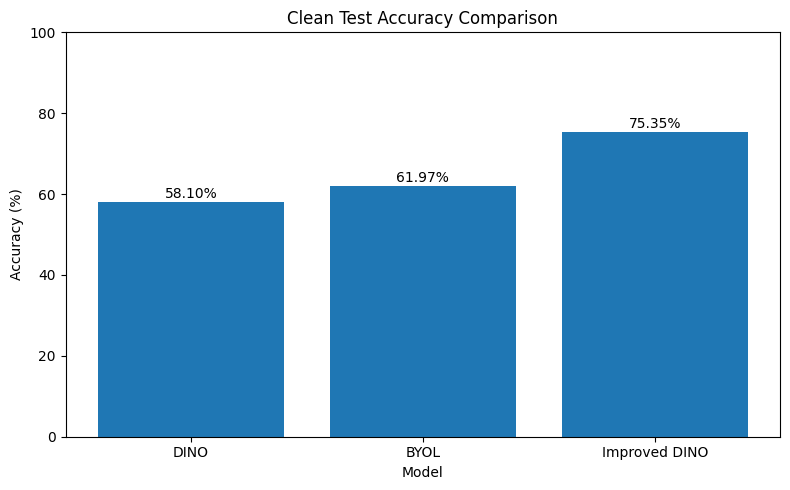

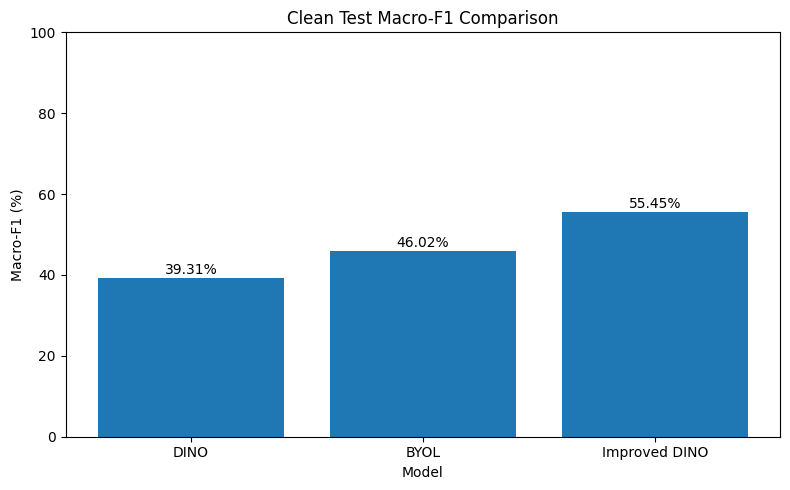

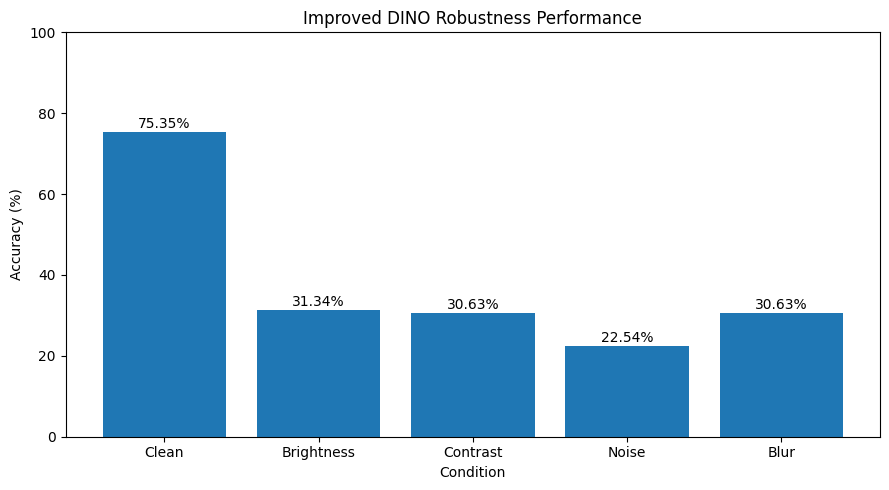


FIGURES SAVED
/content/drive/MyDrive/EyePACS/results/clean_accuracy_comparison.png
/content/drive/MyDrive/EyePACS/results/clean_macro_f1_comparison.png
/content/drive/MyDrive/EyePACS/results/improved_dino_robustness_accuracy.png


In [ ]:
# ============================================================
# FINAL PROJECT FIGURES
# ============================================================

import pandas as pd
import matplotlib.pyplot as plt

RESULT_PATH = "/content/drive/MyDrive/EyePACS/results/FINAL_DINO_BYOL_RESULTS.csv"

df = pd.read_csv(RESULT_PATH)

# ------------------------------------------------------------
# 1. CLEAN ACCURACY COMPARISON
# ------------------------------------------------------------

clean = df[df["Condition"] == "Clean"]

plt.figure(figsize=(8,5))

plt.bar(
    clean["Model"],
    clean["Accuracy"]
)

plt.ylabel("Accuracy (%)")
plt.xlabel("Model")
plt.title("Clean Test Accuracy Comparison")
plt.ylim(0, 100)

for i, value in enumerate(clean["Accuracy"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()

path1 = "/content/drive/MyDrive/EyePACS/results/clean_accuracy_comparison.png"
plt.savefig(path1, dpi=300, bbox_inches="tight")
plt.show()


# ------------------------------------------------------------
# 2. CLEAN MACRO-F1 COMPARISON
# ------------------------------------------------------------

plt.figure(figsize=(8,5))

plt.bar(
    clean["Model"],
    clean["Macro_F1"]
)

plt.ylabel("Macro-F1 (%)")
plt.xlabel("Model")
plt.title("Clean Test Macro-F1 Comparison")
plt.ylim(0, 100)

for i, value in enumerate(clean["Macro_F1"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()

path2 = "/content/drive/MyDrive/EyePACS/results/clean_macro_f1_comparison.png"
plt.savefig(path2, dpi=300, bbox_inches="tight")
plt.show()


# ------------------------------------------------------------
# 3. IMPROVED DINO ROBUSTNESS ACCURACY
# ------------------------------------------------------------

robust_imp = df[
    (df["Model"] == "Improved DINO")
]

plt.figure(figsize=(9,5))

plt.bar(
    robust_imp["Condition"],
    robust_imp["Accuracy"]
)

plt.ylabel("Accuracy (%)")
plt.xlabel("Condition")
plt.title("Improved DINO Robustness Performance")
plt.ylim(0, 100)

for i, value in enumerate(robust_imp["Accuracy"]):
    plt.text(i, value + 1, f"{value:.2f}%", ha="center")

plt.tight_layout()

path3 = "/content/drive/MyDrive/EyePACS/results/improved_dino_robustness_accuracy.png"
plt.savefig(path3, dpi=300, bbox_inches="tight")
plt.show()


print("\n======================================")
print("FIGURES SAVED")
print("======================================")
print(path1)
print(path2)
print(path3)

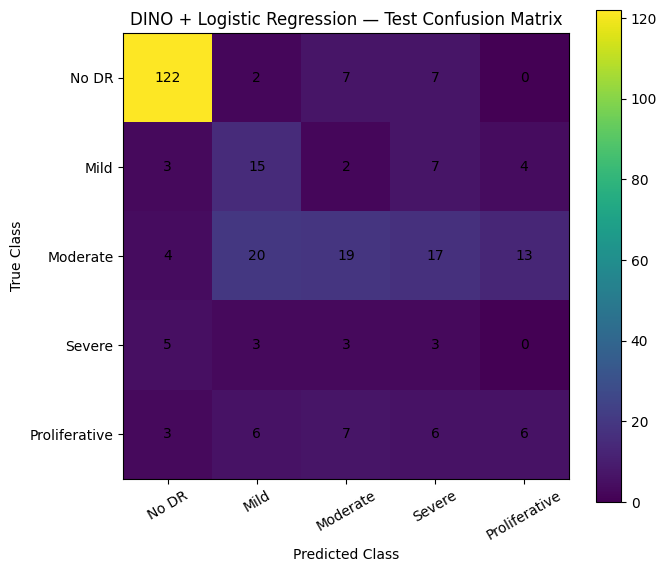

Saved: /content/drive/MyDrive/EyePACS/results/cm_dino.png


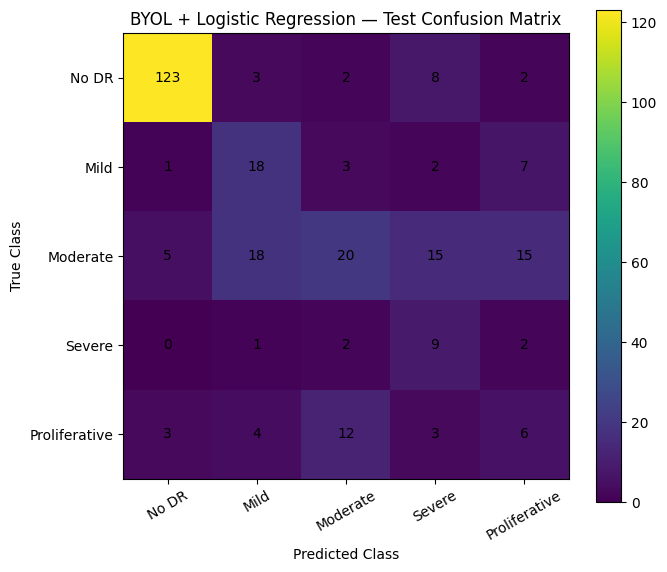

Saved: /content/drive/MyDrive/EyePACS/results/cm_byol.png


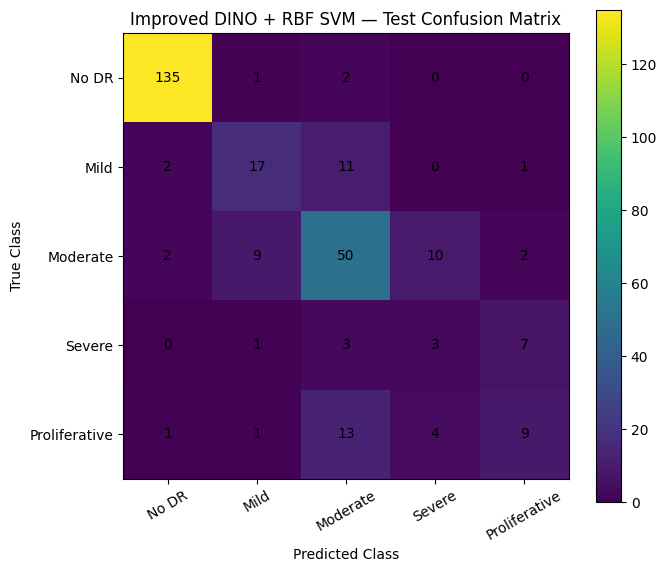

Saved: /content/drive/MyDrive/EyePACS/results/cm_improved_dino.png

ALL CONFUSION MATRICES GENERATED


In [ ]:
# ============================================================
# FINAL CONFUSION MATRICES — DINO vs BYOL vs IMPROVED DINO
# ============================================================

import matplotlib.pyplot as plt
import numpy as np
from sklearn.metrics import confusion_matrix

# ------------------------------------------------------------
# Ground truth
# ------------------------------------------------------------

y_test = correct_test_imp_labels.numpy()

# ------------------------------------------------------------
# 1. DINO + Logistic Regression
# ------------------------------------------------------------

X_train_dino = train_dino["features"].numpy()
y_train_dino = train_dino["labels"].numpy()

X_test_dino = test_dino["features"].numpy()

dino_clf = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

dino_clf.fit(X_train_dino, y_train_dino)
pred_dino = dino_clf.predict(X_test_dino)

cm_dino = confusion_matrix(y_test, pred_dino)


# ------------------------------------------------------------
# 2. BYOL + Logistic Regression
# ------------------------------------------------------------

X_train_byol = train_byol["features"].numpy()
y_train_byol = train_byol["labels"].numpy()

X_test_byol = test_byol["features"].numpy()

byol_clf = LogisticRegression(
    max_iter=2000,
    class_weight="balanced",
    random_state=42
)

byol_clf.fit(X_train_byol, y_train_byol)
pred_byol = byol_clf.predict(X_test_byol)

cm_byol = confusion_matrix(y_test, pred_byol)


# ------------------------------------------------------------
# 3. IMPROVED DINO + RBF SVM
# ------------------------------------------------------------

X_train_imp = train_imp["features"].numpy()
y_train_imp = correct_train_imp_labels.numpy()

X_test_imp = test_imp_saved["features"].numpy()

imp_svm = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=10,
        gamma="scale",
        class_weight="balanced"
    )
)

imp_svm.fit(X_train_imp, y_train_imp)

pred_imp = imp_svm.predict(X_test_imp)

cm_imp = confusion_matrix(y_test, pred_imp)


# ------------------------------------------------------------
# Plot function
# ------------------------------------------------------------

class_names = [
    "No DR",
    "Mild",
    "Moderate",
    "Severe",
    "Proliferative"
]

def plot_cm(cm, title, filename):

    plt.figure(figsize=(7,6))

    plt.imshow(cm)

    plt.title(title)
    plt.xlabel("Predicted Class")
    plt.ylabel("True Class")

    plt.xticks(
        range(5),
        class_names,
        rotation=30
    )

    plt.yticks(
        range(5),
        class_names
    )

    for i in range(5):
        for j in range(5):
            plt.text(
                j,
                i,
                cm[i, j],
                ha="center",
                va="center"
            )

    plt.colorbar()

    plt.tight_layout()

    path = f"/content/drive/MyDrive/EyePACS/results/{filename}"

    plt.savefig(
        path,
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()

    print("Saved:", path)


# ------------------------------------------------------------
# Generate figures
# ------------------------------------------------------------

plot_cm(
    cm_dino,
    "DINO + Logistic Regression — Test Confusion Matrix",
    "cm_dino.png"
)

plot_cm(
    cm_byol,
    "BYOL + Logistic Regression — Test Confusion Matrix",
    "cm_byol.png"
)

plot_cm(
    cm_imp,
    "Improved DINO + RBF SVM — Test Confusion Matrix",
    "cm_improved_dino.png"
)

print("\n======================================")
print("ALL CONFUSION MATRICES GENERATED")
print("======================================")

In [ ]:
# ============================================================
# FINAL CLEAN TEST RESULTS TABLE
# ============================================================

import pandas as pd

clean_results = df[df["Condition"] == "Clean"].copy()

clean_results = clean_results[
    ["Model", "Classifier", "Accuracy", "Macro_F1", "QWK"]
]

print("\n======================================")
print("FINAL CLEAN TEST RESULTS")
print("======================================")

display(clean_results)

# Save as separate CSV
final_clean_path = (
    "/content/drive/MyDrive/EyePACS/results/"
    "FINAL_CLEAN_TEST_RESULTS.csv"
)

clean_results.to_csv(
    final_clean_path,
    index=False
)

print("\nSaved:")
print(final_clean_path)


FINAL CLEAN TEST RESULTS


,Model,Classifier,Accuracy,Macro_F1,QWK
0,DINO,Logistic Regression,58.10,39.31,0.557
1,BYOL,Logistic Regression,61.97,46.02,0.595
2,Improved DINO,RBF SVM,75.35,55.45,0.834



Saved:
/content/drive/MyDrive/EyePACS/results/FINAL_CLEAN_TEST_RESULTS.csv


In [ ]:
# ============================================================
# FINAL METHODOLOGY SUMMARY
# ============================================================

methodology = """
DINO vs BYOL for 5-Class Diabetic Retinopathy Severity Grading

1. DATASET
Dataset: EyePACS
Task: 5-class diabetic retinopathy severity classification

Classes:
0 - No DR
1 - Mild
2 - Moderate
3 - Severe
4 - Proliferative

Dataset split:
Training: 1986 images
Validation: 568 images
Test: 284 images

Training class distribution:
No DR = 1004
Mild = 202
Moderate = 538
Severe = 89
Proliferative = 153

Validation class distribution:
No DR = 288
Mild = 61
Moderate = 155
Severe = 28
Proliferative = 36

Test class distribution:
No DR = 138
Mild = 31
Moderate = 73
Severe = 14
Proliferative = 28


2. PREPROCESSING

Images were resized to 224 x 224 pixels.

Image tensors were normalized using ImageNet normalization:

Mean = [0.485, 0.456, 0.406]
Standard deviation = [0.229, 0.224, 0.225]


3. SELF-SUPERVISED MODELS

Model 1:
DINO using Vision Transformer Small (ViT-S/16).

Feature dimension:
384

Model 2:
BYOL using a ResNet-18-style backbone.

Feature dimension:
512

Model 3:
Improved DINO using ViT-S/16.

Feature dimension:
384

The pretrained/self-supervised representations were extracted and used
for downstream diabetic retinopathy classification.


4. DOWNSTREAM CLASSIFICATION

DINO:
Logistic Regression

BYOL:
Logistic Regression

Improved DINO:
RBF-kernel Support Vector Machine (SVM)

The downstream classifier was trained using training-set features only.


5. MODEL SELECTION PROTOCOL

The validation set was used to compare downstream classifiers.

The final classifier was selected using validation performance.

The clean test set was evaluated only after classifier selection.

This avoids training the classifier on the test set and reduces test-set
selection bias.


6. EVALUATION METRICS

Accuracy:
Percentage of correctly classified images.

Macro-F1:
Average F1 score across all five DR classes, giving each class equal
importance.

Quadratic Weighted Kappa (QWK):
Agreement metric that accounts for the ordinal nature of diabetic
retinopathy severity levels.


7. FINAL CLEAN TEST RESULTS

DINO + Logistic Regression:
Accuracy = 58.10%
Macro-F1 = 39.31%
QWK = 0.557

BYOL + Logistic Regression:
Accuracy = 61.97%
Macro-F1 = 46.02%
QWK = 0.595

Improved DINO + RBF SVM:
Accuracy = 75.35%
Macro-F1 = 55.45%
QWK = 0.834


8. ROBUSTNESS EVALUATION

The same clean-trained classifier was evaluated on corrupted versions
of the test images.

Corruption types:
- Brightness
- Contrast
- Noise
- Blur

Improved DINO + RBF SVM:

Clean:
Accuracy = 75.35%
Macro-F1 = 55.45%
QWK = 0.834

Brightness:
Accuracy = 31.34%
Macro-F1 = 20.99%
QWK = -0.076

Contrast:
Accuracy = 30.63%
Macro-F1 = 16.26%
QWK = -0.118

Noise:
Accuracy = 22.54%
Macro-F1 = 18.72%
QWK = -0.067

Blur:
Accuracy = 30.63%
Macro-F1 = 22.08%
QWK = -0.047


9. MAIN OBSERVATION

The Improved DINO representation produced substantially higher clean-test
performance than the original DINO and BYOL representations.

However, performance decreased substantially under the tested image
corruptions, showing that the learned representation remains sensitive
to distribution shifts and image degradation.


10. LIMITATIONS

The dataset used in this experiment is relatively small compared with
the original EyePACS dataset.

The five severity classes are imbalanced, with fewer Severe and
Proliferative samples.

The robustness experiments used synthetic image corruptions rather than
real-world acquisition variations.

The experiment does not establish clinical applicability or replace
expert ophthalmologist diagnosis.


11. REPRODUCIBILITY

All extracted features, model checkpoints, result CSV files, figures,
and confusion matrices were saved in the EyePACS project directory.
"""

path = "/content/drive/MyDrive/EyePACS/results/FINAL_METHODOLOGY_SUMMARY.txt"

with open(path, "w") as f:
    f.write(methodology)

print("======================================")
print("FINAL METHODOLOGY SAVED")
print("======================================")
print(path)

FINAL METHODOLOGY SAVED
/content/drive/MyDrive/EyePACS/results/FINAL_METHODOLOGY_SUMMARY.txt


In [ ]:
from google.colab import drive

drive.mount('/content/drive')

print("Google Drive mounted successfully.")

Mounted at /content/drive
Google Drive mounted successfully.


In [ ]:

# ============================================================
# BYOL — MOUNT DRIVE + LOAD FEATURES + VALIDATION COMPARISON
# ============================================================

# -----------------------------
# 1. Mount Google Drive
# -----------------------------

from google.colab import drive
drive.mount("/content/drive")


# -----------------------------
# 2. Imports
# -----------------------------

import os
import torch
import numpy as np

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score
)


# -----------------------------
# 3. Feature file paths
# -----------------------------

TRAIN_PATH = (
    "/content/drive/MyDrive/EyePACS/features/"
    "train_byol_epoch10_features.pt"
)

VALID_PATH = (
    "/content/drive/MyDrive/EyePACS/features/"
    "valid_byol_epoch10_features.pt"
)

TEST_PATH = (
    "/content/drive/MyDrive/EyePACS/features/"
    "test_byol_epoch10_features.pt"
)


# -----------------------------
# 4. Check files exist
# -----------------------------

print("Checking files...")

for path in [TRAIN_PATH, VALID_PATH, TEST_PATH]:
    print(
        os.path.basename(path),
        "->",
        os.path.exists(path)
    )


# -----------------------------
# 5. Load BYOL features
# -----------------------------

train_byol = torch.load(
    TRAIN_PATH,
    map_location="cpu"
)

valid_byol = torch.load(
    VALID_PATH,
    map_location="cpu"
)

test_byol = torch.load(
    TEST_PATH,
    map_location="cpu"
)


# -----------------------------
# 6. Inspect loaded data
# -----------------------------

print("\n======================================")
print("BYOL FEATURES LOADED")
print("======================================")

print("Train keys:", train_byol.keys())
print("Valid keys:", valid_byol.keys())
print("Test keys :", test_byol.keys())

print("\nTrain features:", train_byol["features"].shape)
print("Train labels  :", train_byol["labels"].shape)

print("Valid features:", valid_byol["features"].shape)
print("Valid labels  :", valid_byol["labels"].shape)

print("Test features :", test_byol["features"].shape)
print("Test labels   :", test_byol["labels"].shape)


# -----------------------------
# 7. Convert to NumPy
# -----------------------------

X_train = train_byol["features"].numpy()
y_train = train_byol["labels"].numpy()

X_valid = valid_byol["features"].numpy()
y_valid = valid_byol["labels"].numpy()


# -----------------------------
# 8. Classifier comparison
# -----------------------------

classifiers = {

    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=42
        )
    ),

    "Linear SVM": make_pipeline(
        StandardScaler(),
        SVC(
            kernel="linear",
            C=1,
            class_weight="balanced"
        )
    ),

    "RBF SVM": make_pipeline(
        StandardScaler(),
        SVC(
            kernel="rbf",
            C=10,
            gamma="scale",
            class_weight="balanced"
        )
    )
}


# -----------------------------
# 9. Validation evaluation
# -----------------------------

results = []

print("\n======================================")
print("BYOL VALIDATION CLASSIFIER TEST")
print("======================================")

for name, clf in classifiers.items():

    clf.fit(X_train, y_train)

    pred = clf.predict(X_valid)

    acc = accuracy_score(
        y_valid,
        pred
    ) * 100

    macro_f1 = f1_score(
        y_valid,
        pred,
        average="macro"
    ) * 100

    qwk = cohen_kappa_score(
        y_valid,
        pred,
        weights="quadratic"
    )

    results.append([
        name,
        acc,
        macro_f1,
        qwk
    ])

    print("\n--------------------------------------")
    print(name)
    print("--------------------------------------")
    print("Accuracy :", round(acc, 2), "%")
    print("Macro-F1 :", round(macro_f1, 2), "%")
    print("QWK      :", round(qwk, 3))


# -----------------------------
# 10. Final comparison table
# -----------------------------

print("\n======================================")
print("FINAL BYOL VALIDATION COMPARISON")
print("======================================")

print(
    f"{'Classifier':<22}"
    f"{'Accuracy':>12}"
    f"{'Macro-F1':>12}"
    f"{'QWK':>10}"
)

print("-" * 56)

for r in results:

    print(
        f"{r[0]:<22}"
        f"{r[1]:>11.2f}%"
        f"{r[2]:>11.2f}%"
        f"{r[3]:>10.3f}"
    )

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Checking files...
train_byol_epoch10_features.pt -> True
valid_byol_epoch10_features.pt -> True
test_byol_epoch10_features.pt -> True

BYOL FEATURES LOADED
Train keys: dict_keys(['features', 'labels'])
Valid keys: dict_keys(['features', 'labels'])
Test keys : dict_keys(['features', 'labels'])

Train features: torch.Size([1986, 512])
Train labels  : torch.Size([1986])
Valid features: torch.Size([568, 512])
Valid labels  : torch.Size([568])
Test features : torch.Size([284, 512])
Test labels   : torch.Size([284])

BYOL VALIDATION CLASSIFIER TEST

--------------------------------------
Logistic Regression
--------------------------------------
Accuracy : 67.43 %
Macro-F1 : 47.69 %
QWK      : 0.672

--------------------------------------
Linear SVM
--------------------------------------
Accuracy : 68.66 %
Macro-F1 : 46.42 %
QWK      : 0.691

----------------------

In [ ]:
import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

# Convert features to NumPy
X_train = train_byol["features"].cpu().numpy()
y_train = train_byol["labels"].cpu().numpy()

X_valid = valid_byol["features"].cpu().numpy()
y_valid = valid_byol["labels"].cpu().numpy()

# Classifiers
classifiers = {
    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=42
        )
    ),

    "Linear SVM": make_pipeline(
        StandardScaler(),
        SVC(
            kernel="linear",
            C=1,
            class_weight="balanced"
        )
    ),

    "RBF SVM": make_pipeline(
        StandardScaler(),
        SVC(
            kernel="rbf",
            C=10,
            gamma="scale",
            class_weight="balanced"
        )
    )
}

results = []

print("\n======================================")
print("BYOL VALIDATION RESULTS")
print("======================================")

for name, clf in classifiers.items():

    # Train ONLY on training features
    clf.fit(X_train, y_train)

    # Evaluate ONLY on validation
    y_pred = clf.predict(X_valid)

    acc = accuracy_score(y_valid, y_pred)
    macro_f1 = f1_score(y_valid, y_pred, average="macro")
    qwk = cohen_kappa_score(y_valid, y_pred, weights="quadratic")

    results.append({
        "Classifier": name,
        "Accuracy (%)": acc * 100,
        "Macro-F1 (%)": macro_f1 * 100,
        "QWK": qwk
    })

    print(f"\n{name}")
    print(f"Accuracy : {acc*100:.2f}%")
    print(f"Macro-F1 : {macro_f1*100:.2f}%")
    print(f"QWK      : {qwk:.3f}")

results_df = pd.DataFrame(results)

print("\n======================================")
print("COMPARISON")
print("======================================")
display(results_df)


BYOL VALIDATION RESULTS

Logistic Regression
Accuracy : 67.43%
Macro-F1 : 47.69%
QWK      : 0.672

Linear SVM
Accuracy : 68.66%
Macro-F1 : 46.42%
QWK      : 0.691

RBF SVM
Accuracy : 69.01%
Macro-F1 : 48.19%
QWK      : 0.670

COMPARISON


,Classifier,Accuracy (%),Macro-F1 (%),QWK
0,Logistic Regression,67.429577,47.688370,0.671817
1,Linear SVM,68.661972,46.423105,0.690547
2,RBF SVM,69.014085,48.191852,0.670234


In [ ]:
# ==========================================
# BYOL + RBF SVM — FINAL CLEAN TEST
# ==========================================

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score,
    classification_report,
    confusion_matrix
)
import numpy as np
import pandas as pd

# Train data
X_train = train_byol["features"].cpu().numpy()
y_train = train_byol["labels"].cpu().numpy()

# Test data
X_test = test_byol["features"].cpu().numpy()
y_test = test_byol["labels"].cpu().numpy()

print("Train:", X_train.shape)
print("Test :", X_test.shape)
print("Test class distribution:", np.bincount(y_test))

# ------------------------------------------
# Selected classifier from validation
# ------------------------------------------
byol_final_svm = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="rbf",
        C=10,
        gamma="scale",
        class_weight="balanced"
    )
)

# IMPORTANT:
# Train only on TRAIN data
byol_final_svm.fit(X_train, y_train)

# Final test prediction — ONE TIME
y_test_pred = byol_final_svm.predict(X_test)

# Metrics
test_acc = accuracy_score(y_test, y_test_pred)
test_f1 = f1_score(y_test, y_test_pred, average="macro")
test_qwk = cohen_kappa_score(
    y_test,
    y_test_pred,
    weights="quadratic"
)

print("\n======================================")
print("BYOL + RBF SVM FINAL TEST RESULTS")
print("======================================")

print(f"Accuracy : {test_acc*100:.2f}%")
print(f"Macro-F1 : {test_f1*100:.2f}%")
print(f"QWK      : {test_qwk:.3f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_test_pred,
        target_names=[
            "No DR",
            "Mild",
            "Moderate",
            "Severe",
            "Proliferative DR"
        ],
        digits=2
    )
)

print("\nConfusion Matrix:")
cm = confusion_matrix(y_test, y_test_pred)
print(cm)

print("\nPrediction distribution:")
print(np.bincount(y_test_pred, minlength=5))

# Save result in memory
byol_final_result = {
    "Model": "BYOL-10 + RBF SVM",
    "Accuracy (%)": test_acc * 100,
    "Macro-F1 (%)": test_f1 * 100,
    "QWK": test_qwk
}

Train: (1986, 512)
Test : (284, 512)
Test class distribution: [138  31  73  14  28]

BYOL + RBF SVM FINAL TEST RESULTS
Accuracy : 62.68%
Macro-F1 : 45.96%
QWK      : 0.623

Classification Report:
                  precision    recall  f1-score   support

           No DR       0.91      0.90      0.91       138
            Mild       0.46      0.71      0.56        31
        Moderate       0.50      0.26      0.34        73
          Severe       0.16      0.36      0.22        14
Proliferative DR       0.26      0.29      0.27        28

        accuracy                           0.63       284
       macro avg       0.46      0.50      0.46       284
    weighted avg       0.65      0.63      0.63       284


Confusion Matrix:
[[124   4   2   4   4]
 [  2  22   3   2   2]
 [  6  17  19  16  15]
 [  0   2   5   5   2]
 [  4   3   9   4   8]]

Prediction distribution:
[136  48  38  31  31]


In [ ]:
# ==========================================
# INSPECT CURRENT BYOL ARCHITECTURE
# ==========================================

import torch

BYOL_CKPT = "/content/drive/MyDrive/EyePACS/checkpoints/byol_epoch_10.pth"

ckpt = torch.load(BYOL_CKPT, map_location="cpu")

print("Checkpoint keys:")
print(ckpt.keys())

print("\nNumber of parameters:")
for key in ["online", "target", "projector", "predictor"]:
    if key in ckpt:
        print(f"{key}: {len(ckpt[key])} tensors")

print("\nFirst BYOL backbone parameters:")
for i, (name, value) in enumerate(ckpt["online"].items()):
    print(name, tuple(value.shape))
    if i >= 15:
        break

print("\nProjector parameters:")
for name, value in ckpt["projector"].items():
    print(name, tuple(value.shape))

print("\nPredictor parameters:")
for name, value in ckpt["predictor"].items():
    print(name, tuple(value.shape))

Checkpoint keys:
dict_keys(['online', 'target', 'projector', 'predictor'])

Number of parameters:
online: 120 tensors
target: 120 tensors
projector: 9 tensors
predictor: 9 tensors

First BYOL backbone parameters:
conv1.weight (64, 3, 7, 7)
bn1.weight (64,)
bn1.bias (64,)
bn1.running_mean (64,)
bn1.running_var (64,)
bn1.num_batches_tracked ()
layer1.0.conv1.weight (64, 64, 3, 3)
layer1.0.bn1.weight (64,)
layer1.0.bn1.bias (64,)
layer1.0.bn1.running_mean (64,)
layer1.0.bn1.running_var (64,)
layer1.0.bn1.num_batches_tracked ()
layer1.0.conv2.weight (64, 64, 3, 3)
layer1.0.bn2.weight (64,)
layer1.0.bn2.bias (64,)
layer1.0.bn2.running_mean (64,)

Projector parameters:
net.0.weight (512, 512)
net.0.bias (512,)
net.1.weight (512,)
net.1.bias (512,)
net.1.running_mean (512,)
net.1.running_var (512,)
net.1.num_batches_tracked ()
net.3.weight (256, 512)
net.3.bias (256,)

Predictor parameters:
net.0.weight (512, 256)
net.0.bias (512,)
net.1.weight (512,)
net.1.bias (512,)
net.1.running_mean (512

In [ ]:
# ==========================================
# FIND BYOL TRAINING / AUGMENTATION INFO
# ==========================================

import os

base = "/content/drive/MyDrive/EyePACS"

print("Searching EyePACS project files...\n")

for root, dirs, files in os.walk(base):
    for file in files:
        if file.endswith((".py", ".ipynb", ".txt")):
            path = os.path.join(root, file)
            print(path)

Searching EyePACS project files...

/content/drive/MyDrive/EyePACS/dataset/README.dataset.txt
/content/drive/MyDrive/EyePACS/dataset/README.roboflow.txt
/content/drive/MyDrive/EyePACS/results/FINAL_METHODOLOGY_SUMMARY.txt


In [ ]:
# ==========================================
# CHECK GPU FOR IMPROVED BYOL
# ==========================================

import torch

print("PyTorch:", torch.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

    props = torch.cuda.get_device_properties(0)
    print(f"GPU Memory: {props.total_memory / 1024**3:.2f} GB")

    print("CUDA:", torch.version.cuda)
else:
    print("WARNING: GPU is not available")

PyTorch: 2.11.0+cu130
CUDA available: True
GPU: Tesla T4
GPU Memory: 14.56 GB
CUDA: 13.0


In [ ]:
# ==========================================
# IMPROVED BYOL — RESNET-50 ARCHITECTURE
# ==========================================

import torch
import torch.nn as nn
import torchvision.models as models

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# ------------------------------------------
# 1. ResNet-50 backbone
# ------------------------------------------
backbone = models.resnet50(weights=None)

# Remove classification layer
backbone.fc = nn.Identity()

# ResNet-50 output = 2048
feature_dim = 2048

print("Backbone: ResNet-50")
print("Feature dimension:", feature_dim)

# ------------------------------------------
# 2. BYOL Projector
# ------------------------------------------
class MLP(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, output_dim)
        )

    def forward(self, x):
        return self.net(x)

projector = MLP(
    input_dim=feature_dim,
    hidden_dim=512,
    output_dim=256
)

# ------------------------------------------
# 3. BYOL Predictor
# ------------------------------------------
predictor = MLP(
    input_dim=256,
    hidden_dim=512,
    output_dim=256
)

# Move to GPU
backbone = backbone.to(device)
projector = projector.to(device)
predictor = predictor.to(device)

# Test forward pass
dummy = torch.randn(2, 3, 224, 224).to(device)

with torch.no_grad():
    features = backbone(dummy)
    projected = projector(features)
    predicted = predictor(projected)

print("\n======================================")
print("ARCHITECTURE TEST")
print("======================================")
print("Input     :", dummy.shape)
print("Backbone  :", features.shape)
print("Projector :", projected.shape)
print("Predictor :", predicted.shape)
print("SUCCESS")

Backbone: ResNet-50
Feature dimension: 2048

ARCHITECTURE TEST
Input     : torch.Size([2, 3, 224, 224])
Backbone  : torch.Size([2, 2048])
Projector : torch.Size([2, 256])
Predictor : torch.Size([2, 256])
SUCCESS


In [ ]:
# ==========================================
# IMPROVED BYOL — RETINAL DATA PIPELINE
# ==========================================

import os
import pandas as pd
from PIL import Image

import torch
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

# Paths
TRAIN_DIR = "/content/drive/MyDrive/EyePACS/dataset/train"
VALID_DIR = "/content/drive/MyDrive/EyePACS/dataset/valid"

TRAIN_CSV = os.path.join(TRAIN_DIR, "labels.csv")
VALID_CSV = os.path.join(VALID_DIR, "labels.csv")

# ------------------------------------------
# Dataset
# ------------------------------------------
class EyePACSDataset(Dataset):

    def __init__(self, csv_file, image_dir, transform=None):
        self.df = pd.read_csv(csv_file)
        self.image_dir = image_dir
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        filename = self.df.iloc[idx]["filename"]
        image_path = os.path.join(self.image_dir, filename)

        image = Image.open(image_path).convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image


# ------------------------------------------
# BYOL augmentation
# ------------------------------------------
byol_transform = transforms.Compose([
    transforms.Resize((256, 256)),

    transforms.RandomResizedCrop(
        224,
        scale=(0.70, 1.0),
        ratio=(0.90, 1.10)
    ),

    transforms.RandomHorizontalFlip(p=0.5),

    transforms.RandomApply([
        transforms.ColorJitter(
            brightness=0.2,
            contrast=0.2,
            saturation=0.15,
            hue=0.02
        )
    ], p=0.8),

    transforms.RandomGrayscale(p=0.05),

    transforms.RandomApply([
        transforms.GaussianBlur(
            kernel_size=23,
            sigma=(0.1, 2.0)
        )
    ], p=0.2),

    transforms.ToTensor(),

    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# ------------------------------------------
# Create datasets
# ------------------------------------------
train_dataset = EyePACSDataset(
    TRAIN_CSV,
    TRAIN_DIR,
    transform=byol_transform
)

valid_dataset = EyePACSDataset(
    VALID_CSV,
    VALID_DIR,
    transform=byol_transform
)

# T4-safe batch size
BATCH_SIZE = 16

train_loader = DataLoader(
    train_dataset,
    batch_size=BATCH_SIZE,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True
)

valid_loader = DataLoader(
    valid_dataset,
    batch_size=BATCH_SIZE,
    shuffle=False,
    num_workers=2,
    pin_memory=True
)

print("======================================")
print("IMPROVED BYOL DATA PIPELINE")
print("======================================")

print("Train images :", len(train_dataset))
print("Valid images :", len(valid_dataset))
print("Batch size   :", BATCH_SIZE)
print("Train batches:", len(train_loader))
print("Valid batches:", len(valid_loader))

# Test one batch
images = next(iter(train_loader))

print("\nBatch shape:", images.shape)
print("SUCCESS")

IMPROVED BYOL DATA PIPELINE
Train images : 1986
Valid images : 568
Batch size   : 16
Train batches: 124
Valid batches: 36

Batch shape: torch.Size([16, 3, 224, 224])
SUCCESS


In [ ]:
# ==========================================
# IMPROVED BYOL TRAINING — RESNET-50
# ==========================================

import os
import copy
import torch
import torch.nn as nn
import torch.nn.functional as F
from torchvision import models, transforms
from torch.utils.data import Dataset, DataLoader
from PIL import Image
import pandas as pd

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CHECKPOINT_DIR = "/content/drive/MyDrive/EyePACS/checkpoints"
os.makedirs(CHECKPOINT_DIR, exist_ok=True)

# ==========================================
# 1. BYOL AUGMENTATION
# ==========================================

class BYOLTransform:
    def __init__(self):
        self.transform = transforms.Compose([
            transforms.Resize((256, 256)),
            transforms.RandomResizedCrop(
                224,
                scale=(0.70, 1.0),
                ratio=(0.90, 1.10)
            ),
            transforms.RandomHorizontalFlip(p=0.5),
            transforms.RandomApply([
                transforms.ColorJitter(
                    brightness=0.2,
                    contrast=0.2,
                    saturation=0.15,
                    hue=0.02
                )
            ], p=0.8),
            transforms.RandomGrayscale(p=0.05),
            transforms.RandomApply([
                transforms.GaussianBlur(
                    kernel_size=23,
                    sigma=(0.1, 2.0)
                )
            ], p=0.2),
            transforms.ToTensor(),
            transforms.Normalize(
                [0.485, 0.456, 0.406],
                [0.229, 0.224, 0.225]
            )
        ])

    def __call__(self, image):
        return self.transform(image), self.transform(image)


# ==========================================
# 2. DATASET
# ==========================================

class BYOLDataset(Dataset):

    def __init__(self, csv_file, image_dir):
        self.df = pd.read_csv(csv_file)
        self.image_dir = image_dir
        self.transform = BYOLTransform()

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        filename = self.df.iloc[idx]["filename"]

        image_path = os.path.join(
            self.image_dir,
            filename
        )

        image = Image.open(image_path).convert("RGB")

        view1, view2 = self.transform(image)

        return view1, view2


train_dataset = BYOLDataset(
    "/content/drive/MyDrive/EyePACS/dataset/train/labels.csv",
    "/content/drive/MyDrive/EyePACS/dataset/train"
)

train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2,
    pin_memory=True,
    drop_last=True
)


# ==========================================
# 3. MLP
# ==========================================

class MLP(nn.Module):

    def __init__(self, input_dim, hidden_dim, output_dim):
        super().__init__()

        self.net = nn.Sequential(
            nn.Linear(input_dim, hidden_dim),
            nn.BatchNorm1d(hidden_dim),
            nn.ReLU(inplace=True),
            nn.Linear(hidden_dim, output_dim)
        )

    def forward(self, x):
        return self.net(x)


# ==========================================
# 4. BYOL NETWORK
# ==========================================

class BYOL(nn.Module):

    def __init__(
        self,
        backbone,
        feature_dim=2048,
        hidden_dim=512,
        projection_dim=256
    ):
        super().__init__()

        # Online encoder
        self.online_encoder = backbone

        # Online projector
        self.online_projector = MLP(
            feature_dim,
            hidden_dim,
            projection_dim
        )

        # Online predictor
        self.predictor = MLP(
            projection_dim,
            hidden_dim,
            projection_dim
        )

        # Target encoder
        self.target_encoder = copy.deepcopy(
            self.online_encoder
        )

        # Target projector
        self.target_projector = copy.deepcopy(
            self.online_projector
        )

        # Freeze target
        for p in self.target_encoder.parameters():
            p.requires_grad = False

        for p in self.target_projector.parameters():
            p.requires_grad = False


    def online_forward(self, x):

        h = self.online_encoder(x)

        z = self.online_projector(h)

        p = self.predictor(z)

        return p


    @torch.no_grad()
    def target_forward(self, x):

        h = self.target_encoder(x)

        z = self.target_projector(h)

        return z


    @torch.no_grad()
    def update_target(self, momentum=0.996):

        for online, target in zip(
            self.online_encoder.parameters(),
            self.target_encoder.parameters()
        ):
            target.data.mul_(momentum).add_(
                online.data,
                alpha=1 - momentum
            )

        for online, target in zip(
            self.online_projector.parameters(),
            self.target_projector.parameters()
        ):
            target.data.mul_(momentum).add_(
                online.data,
                alpha=1 - momentum
            )


# ==========================================
# 5. CREATE RESNET-50
# ==========================================

backbone = models.resnet50(weights=None)

backbone.fc = nn.Identity()

model = BYOL(
    backbone=backbone,
    feature_dim=2048,
    hidden_dim=512,
    projection_dim=256
).to(device)


# ==========================================
# 6. BYOL LOSS
# ==========================================

def byol_loss(p, z):

    p = F.normalize(p, dim=1)

    z = F.normalize(z.detach(), dim=1)

    return 2 - 2 * (p * z).sum(dim=1).mean()


# ==========================================
# 7. OPTIMIZER
# ==========================================

optimizer = torch.optim.AdamW(
    filter(lambda p: p.requires_grad, model.parameters()),
    lr=3e-4,
    weight_decay=1e-4
)

scheduler = torch.optim.lr_scheduler.CosineAnnealingLR(
    optimizer,
    T_max=10
)

scaler = torch.amp.GradScaler("cuda")


# ==========================================
# 8. TRAIN
# ==========================================

EPOCHS = 10

print("======================================")
print("STARTING IMPROVED BYOL TRAINING")
print("======================================")

for epoch in range(EPOCHS):

    model.train()

    running_loss = 0.0

    for step, (view1, view2) in enumerate(train_loader):

        view1 = view1.to(device, non_blocking=True)
        view2 = view2.to(device, non_blocking=True)

        optimizer.zero_grad(set_to_none=True)

        with torch.amp.autocast("cuda"):

            p1 = model.online_forward(view1)
            p2 = model.online_forward(view2)

            with torch.no_grad():
                z1 = model.target_forward(view1)
                z2 = model.target_forward(view2)

            loss = (
                byol_loss(p1, z2) +
                byol_loss(p2, z1)
            ) / 2

        scaler.scale(loss).backward()

        scaler.step(optimizer)
        scaler.update()

        model.update_target()

        running_loss += loss.item()

    scheduler.step()

    avg_loss = running_loss / len(train_loader)

    print(
        f"Epoch [{epoch+1}/{EPOCHS}] "
        f"Loss: {avg_loss:.4f} "
        f"LR: {scheduler.get_last_lr()[0]:.6f}"
    )

    # Save checkpoint
    checkpoint_path = os.path.join(
        CHECKPOINT_DIR,
        f"improved_byol_resnet50_epoch_{epoch+1}.pth"
    )

    torch.save({
        "epoch": epoch + 1,
        "online_encoder": model.online_encoder.state_dict(),
        "online_projector": model.online_projector.state_dict(),
        "predictor": model.predictor.state_dict(),
        "target_encoder": model.target_encoder.state_dict(),
        "target_projector": model.target_projector.state_dict(),
        "optimizer": optimizer.state_dict(),
        "loss": avg_loss
    }, checkpoint_path)

print("\n======================================")
print("TRAINING COMPLETE")
print("======================================")
print("Checkpoints saved to:")

print(CHECKPOINT_DIR)

STARTING IMPROVED BYOL TRAINING
Epoch [1/10] Loss: 0.6838 LR: 0.000293
Epoch [2/10] Loss: 0.4300 LR: 0.000271
Epoch [3/10] Loss: 0.3337 LR: 0.000238
Epoch [4/10] Loss: 0.3054 LR: 0.000196
Epoch [5/10] Loss: 0.2558 LR: 0.000150
Epoch [6/10] Loss: 0.2348 LR: 0.000104
Epoch [7/10] Loss: 0.2146 LR: 0.000062
Epoch [8/10] Loss: 0.2078 LR: 0.000029
Epoch [9/10] Loss: 0.1939 LR: 0.000007
Epoch [10/10] Loss: 0.1942 LR: 0.000000

TRAINING COMPLETE
Checkpoints saved to:
/content/drive/MyDrive/EyePACS/checkpoints


In [ ]:
# ==========================================
# IMPROVED BYOL RESNET-50 FEATURE EXTRACTION
# ==========================================

import os
import torch
import pandas as pd
from PIL import Image
from torch.utils.data import Dataset, DataLoader
from torchvision import transforms

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

CHECKPOINT = "/content/drive/MyDrive/EyePACS/checkpoints/improved_byol_resnet50_epoch_10.pth"
FEATURE_DIR = "/content/drive/MyDrive/EyePACS/features"
os.makedirs(FEATURE_DIR, exist_ok=True)

# ------------------------------------------
# Load model
# ------------------------------------------

backbone = models.resnet50(weights=None)
backbone.fc = nn.Identity()

checkpoint = torch.load(
    CHECKPOINT,
    map_location="cpu"
)

backbone.load_state_dict(
    checkpoint["online_encoder"]
)

backbone = backbone.to(device)
backbone.eval()

print("ResNet-50 checkpoint loaded.")
print("Feature dimension: 2048")


# ------------------------------------------
# Evaluation transform
# ------------------------------------------

feature_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        [0.485, 0.456, 0.406],
        [0.229, 0.224, 0.225]
    )
])


# ------------------------------------------
# Dataset with labels
# ------------------------------------------

class FeatureDataset(Dataset):

    def __init__(self, csv_file, image_dir):
        self.df = pd.read_csv(csv_file)
        self.image_dir = image_dir

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):

        filename = self.df.iloc[idx]["filename"]
        label = int(self.df.iloc[idx]["level"])

        image_path = os.path.join(
            self.image_dir,
            filename
        )

        image = Image.open(image_path).convert("RGB")
        image = feature_transform(image)

        return image, label


# ------------------------------------------
# Feature extraction function
# ------------------------------------------

def extract_features(csv_file, image_dir, save_name):

    dataset = FeatureDataset(
        csv_file,
        image_dir
    )

    loader = DataLoader(
        dataset,
        batch_size=32,
        shuffle=False,
        num_workers=2,
        pin_memory=True
    )

    all_features = []
    all_labels = []

    with torch.no_grad():

        for images, labels in loader:

            images = images.to(
                device,
                non_blocking=True
            )

            features = backbone(images)

            all_features.append(
                features.cpu()
            )

            all_labels.append(
                labels
            )

    features = torch.cat(all_features)
    labels = torch.cat(all_labels)

    save_path = os.path.join(
        FEATURE_DIR,
        save_name
    )

    torch.save(
        {
            "features": features,
            "labels": labels
        },
        save_path
    )

    print(
        f"{save_name}: "
        f"features={features.shape}, "
        f"labels={labels.shape}"
    )

    return features, labels


# ------------------------------------------
# Extract all three splits
# ------------------------------------------

train_features, train_labels = extract_features(
    "/content/drive/MyDrive/EyePACS/dataset/train/labels.csv",
    "/content/drive/MyDrive/EyePACS/dataset/train",
    "improved_byol_resnet50_train_features.pt"
)

valid_features, valid_labels = extract_features(
    "/content/drive/MyDrive/EyePACS/dataset/valid/labels.csv",
    "/content/drive/MyDrive/EyePACS/dataset/valid",
    "improved_byol_resnet50_valid_features.pt"
)

test_features, test_labels = extract_features(
    "/content/drive/MyDrive/EyePACS/dataset/test/labels.csv",
    "/content/drive/MyDrive/EyePACS/dataset/test",
    "improved_byol_resnet50_test_features.pt"
)

print("\n======================================")
print("FEATURE EXTRACTION COMPLETE")
print("======================================")

ResNet-50 checkpoint loaded.
Feature dimension: 2048
improved_byol_resnet50_train_features.pt: features=torch.Size([1986, 2048]), labels=torch.Size([1986])
improved_byol_resnet50_valid_features.pt: features=torch.Size([568, 2048]), labels=torch.Size([568])
improved_byol_resnet50_test_features.pt: features=torch.Size([284, 2048]), labels=torch.Size([284])

FEATURE EXTRACTION COMPLETE


In [ ]:
# ==========================================
# IMPROVED BYOL RESNET-50
# VALIDATION CLASSIFIER COMPARISON
# ==========================================

import torch
import numpy as np
import pandas as pd

from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score
)

# ------------------------------------------
# Load features
# ------------------------------------------

train_data = torch.load(
    "/content/drive/MyDrive/EyePACS/features/improved_byol_resnet50_train_features.pt",
    map_location="cpu"
)

valid_data = torch.load(
    "/content/drive/MyDrive/EyePACS/features/improved_byol_resnet50_valid_features.pt",
    map_location="cpu"
)

X_train = train_data["features"].numpy()
y_train = train_data["labels"].numpy()

X_valid = valid_data["features"].numpy()
y_valid = valid_data["labels"].numpy()

print("Train:", X_train.shape)
print("Valid:", X_valid.shape)

# ------------------------------------------
# Classifiers
# ------------------------------------------

classifiers = {

    "Logistic Regression": make_pipeline(
        StandardScaler(),
        LogisticRegression(
            max_iter=3000,
            class_weight="balanced",
            random_state=42
        )
    ),

    "Linear SVM": make_pipeline(
        StandardScaler(),
        SVC(
            kernel="linear",
            C=1,
            class_weight="balanced"
        )
    ),

    "RBF SVM": make_pipeline(
        StandardScaler(),
        SVC(
            kernel="rbf",
            C=10,
            gamma="scale",
            class_weight="balanced"
        )
    )
}

results = []

print("\n======================================")
print("IMPROVED BYOL RESNET-50")
print("VALIDATION RESULTS")
print("======================================")

for name, clf in classifiers.items():

    # Train ONLY on training features
    clf.fit(X_train, y_train)

    # Validation only
    y_pred = clf.predict(X_valid)

    acc = accuracy_score(y_valid, y_pred)
    macro_f1 = f1_score(
        y_valid,
        y_pred,
        average="macro"
    )
    qwk = cohen_kappa_score(
        y_valid,
        y_pred,
        weights="quadratic"
    )

    results.append({
        "Classifier": name,
        "Accuracy (%)": acc * 100,
        "Macro-F1 (%)": macro_f1 * 100,
        "QWK": qwk
    })

    print(f"\n{name}")
    print(f"Accuracy : {acc*100:.2f}%")
    print(f"Macro-F1 : {macro_f1*100:.2f}%")
    print(f"QWK      : {qwk:.3f}")

results_df = pd.DataFrame(results)

print("\n======================================")
print("FINAL VALIDATION COMPARISON")
print("======================================")

display(results_df)

Train: (1986, 2048)
Valid: (568, 2048)

IMPROVED BYOL RESNET-50
VALIDATION RESULTS

Logistic Regression
Accuracy : 67.78%
Macro-F1 : 44.90%
QWK      : 0.656

Linear SVM
Accuracy : 69.72%
Macro-F1 : 44.43%
QWK      : 0.663

RBF SVM
Accuracy : 68.13%
Macro-F1 : 46.60%
QWK      : 0.638

FINAL VALIDATION COMPARISON


,Classifier,Accuracy (%),Macro-F1 (%),QWK
0,Logistic Regression,67.781690,44.899066,0.655940
1,Linear SVM,69.718310,44.427684,0.663493
2,RBF SVM,68.133803,46.597011,0.638247


In [ ]:
# ==========================================
# IMPROVED BYOL RESNET-50
# FINAL CLEAN TEST
# ==========================================

import torch
import numpy as np
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score,
    classification_report,
    confusion_matrix
)

# Load features
train_data = torch.load(
    "/content/drive/MyDrive/EyePACS/features/improved_byol_resnet50_train_features.pt",
    map_location="cpu"
)

test_data = torch.load(
    "/content/drive/MyDrive/EyePACS/features/improved_byol_resnet50_test_features.pt",
    map_location="cpu"
)

X_train = train_data["features"].numpy()
y_train = train_data["labels"].numpy()

X_test = test_data["features"].numpy()
y_test = test_data["labels"].numpy()

print("Train:", X_train.shape)
print("Test :", X_test.shape)
print("Test classes:", np.bincount(y_test))

# Selected from validation
final_clf = make_pipeline(
    StandardScaler(),
    SVC(
        kernel="linear",
        C=1,
        class_weight="balanced"
    )
)

# Train ONLY on training set
final_clf.fit(X_train, y_train)

# FINAL test prediction
y_pred = final_clf.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
macro_f1 = f1_score(y_test, y_pred, average="macro")
qwk = cohen_kappa_score(
    y_test,
    y_pred,
    weights="quadratic"
)

print("\n======================================")
print("IMPROVED BYOL RESNET-50")
print("FINAL TEST RESULTS")
print("======================================")

print(f"Accuracy : {accuracy*100:.2f}%")
print(f"Macro-F1 : {macro_f1*100:.2f}%")
print(f"QWK      : {qwk:.3f}")

print("\nClassification Report:")
print(
    classification_report(
        y_test,
        y_pred,
        target_names=[
            "No DR",
            "Mild",
            "Moderate",
            "Severe",
            "Proliferative DR"
        ],
        digits=2
    )
)

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

print("\nPrediction distribution:")
print(np.bincount(y_pred, minlength=5))

Train: (1986, 2048)
Test : (284, 2048)
Test classes: [138  31  73  14  28]

IMPROVED BYOL RESNET-50
FINAL TEST RESULTS
Accuracy : 65.85%
Macro-F1 : 43.33%
QWK      : 0.607

Classification Report:
                  precision    recall  f1-score   support

           No DR       0.89      0.95      0.92       138
            Mild       0.33      0.39      0.36        31
        Moderate       0.58      0.51      0.54        73
          Severe       0.20      0.14      0.17        14
Proliferative DR       0.19      0.18      0.19        28

        accuracy                           0.66       284
       macro avg       0.44      0.43      0.43       284
    weighted avg       0.64      0.66      0.65       284


Confusion Matrix:
[[131   1   2   3   1]
 [  3  12  12   0   4]
 [ 10  12  37   2  12]
 [  1   3   4   2   4]
 [  3   8   9   3   5]]

Prediction distribution:
[148  36  64  10  26]


In [ ]:
import pandas as pd
import os

RESULTS_DIR = "/content/drive/MyDrive/EyePACS/results"

print("Files in results folder:")
for f in sorted(os.listdir(RESULTS_DIR)):
    print(f)

Files in results folder:
FINAL_CLEAN_TEST_RESULTS.csv
FINAL_DINO_BYOL_RESULTS.csv
FINAL_METHODOLOGY_SUMMARY.txt
average_robustness_results.csv
byol10_confusion_matrix_final.csv
clean_accuracy_comparison.png
clean_macro_f1_comparison.png
cm_byol.png
cm_dino.png
cm_improved_dino.png
complete_robustness_results.csv
current_robustness_results.csv
dino10_confusion_matrix_final.csv
final_clean_results.csv
final_model_comparison.csv
final_robustness_results.csv
final_ssl_comparison.csv
final_valid_robustness_results.csv
improved_dino_final_results.csv
improved_dino_robustness_accuracy.png
ssl_final_comparison.csv
ssl_robustness.csv
supervised_robustness.csv


In [ ]:
import pandas as pd
import os

RESULTS_DIR = "/content/drive/MyDrive/EyePACS/results"

files = [
    "final_model_comparison.csv",
    "final_ssl_comparison.csv",
    "ssl_final_comparison.csv",
    "FINAL_DINO_BYOL_RESULTS.csv",
    "FINAL_CLEAN_TEST_RESULTS.csv",
    "complete_robustness_results.csv",
    "final_robustness_results.csv"
]

for file in files:
    path = os.path.join(RESULTS_DIR, file)
    print("\n" + "="*70)
    print(file)
    print("="*70)

    if os.path.exists(path):
        df = pd.read_csv(path)
        print("Shape:", df.shape)
        display(df)
    else:
        print("NOT FOUND")


final_model_comparison.csv
Shape: (3, 4)


,Method,Accuracy,Macro-F1,QWK
0,DINO-10,0.580986,0.393126,0.556705
1,BYOL-10,0.619718,0.460239,0.594735
2,Supervised EfficientNet-B0,0.637300,0.444200,0.738600



final_ssl_comparison.csv
Shape: (4, 4)


,Model,Accuracy,Macro-F1,QWK
0,Original DINO-10,0.580986,0.393126,0.556705
1,BYOL-10,0.619718,0.460239,0.594735
2,Improved DINO,0.750000,0.592800,0.857900
3,Supervised EfficientNet-B0,0.637300,0.444200,0.738600



ssl_final_comparison.csv
Shape: (2, 4)


...

,Model,Classifier,Accuracy,Macro_F1,QWK
0,DINO,Logistic Regression,58.10,39.31,0.557
1,BYOL,Logistic Regression,61.97,46.02,0.595
2,Improved DINO,RBF SVM,75.35,55.45,0.834



complete_robustness_results.csv
Shape: (12, 5)


,Method,Corruption,Accuracy,Macro-F1,QWK
0,DINO-10,brightness,0.228873,0.137749,-0.067014
1,BYOL-10,brightness,0.278169,0.182260,0.086431
2,DINO-10,blur,0.545775,0.356853,0.366124
3,BYOL-10,blur,0.478873,0.287731,0.379848
4,DINO-10,contrast,0.338028,0.181261,0.262525
5,BYOL-10,contrast,0.137324,0.134305,-0.006721
6,DINO-10,noise,0.517606,0.316942,0.283955
7,BYOL-10,noise,0.461268,0.305689,0.504368
8,Supervised EfficientNet-B0,brightness,0.616197,0.399865,0.631309
9,Supervised EfficientNet-B0,blur,0.489437,0.325790,0.481042



final_robustness_results.csv
Shape: (15, 5)


,Model,Condition,Accuracy,Macro-F1,QWK
0,DINO-10,Clean,0.288732,0.194866,-0.045295
1,BYOL-10,Clean,0.274648,0.187289,-0.076543
2,Improved DINO,Clean,0.288732,0.169222,-0.092620
3,DINO-10,Brightness,0.257042,0.171163,0.035862
4,BYOL-10,Brightness,0.214789,0.141624,-0.083403
5,Improved DINO,Brightness,0.267606,0.178745,-0.066827
6,DINO-10,Contrast,0.151408,0.125015,-0.050316
7,BYOL-10,Contrast,0.172535,0.110072,0.015330
8,Improved DINO,Contrast,0.320423,0.203787,-0.071292
9,DINO-10,Noise,0.285211,0.192027,-0.051215


In [ ]:
import pandas as pd
import os

RESULTS_DIR = "/content/drive/MyDrive/EyePACS/results"

final_results = pd.DataFrame([
    {
        "Model": "Original DINO",
        "Architecture": "ViT-S/16",
        "Classifier": "Logistic Regression",
        "Accuracy": 58.10,
        "Macro-F1": 39.31,
        "QWK": 0.557
    },
    {
        "Model": "Original BYOL",
        "Architecture": "ResNet-18",
        "Classifier": "RBF SVM",
        "Accuracy": 62.68,
        "Macro-F1": 45.96,
        "QWK": 0.623
    },
    {
        "Model": "Improved BYOL",
        "Architecture": "ResNet-50",
        "Classifier": "Linear SVM",
        "Accuracy": 65.85,
        "Macro-F1": 43.33,
        "QWK": 0.607
    },
    {
        "Model": "Improved DINO",
        "Architecture": "ViT-S/16",
        "Classifier": "RBF SVM",
        "Accuracy": 75.35,
        "Macro-F1": 55.45,
        "QWK": 0.834
    }
])

path = os.path.join(RESULTS_DIR, "FINAL_SSL_COMPARISON_UPDATED.csv")
final_results.to_csv(path, index=False)

display(final_results)

print("\nSaved to:")
print(path)

,Model,Architecture,Classifier,Accuracy,Macro-F1,QWK
0,Original DINO,ViT-S/16,Logistic Regression,58.10,39.31,0.557
1,Original BYOL,ResNet-18,RBF SVM,62.68,45.96,0.623
2,Improved BYOL,ResNet-50,Linear SVM,65.85,43.33,0.607
3,Improved DINO,ViT-S/16,RBF SVM,75.35,55.45,0.834



Saved to:
/content/drive/MyDrive/EyePACS/results/FINAL_SSL_COMPARISON_UPDATED.csv


In [ ]:
import pandas as pd
import os

RESULTS_DIR = "/content/drive/MyDrive/EyePACS/results"

robustness = pd.DataFrame([
    ["Improved DINO", "Clean", 75.35, 55.45, 0.834],
    ["Improved DINO", "Brightness", 31.34, 20.99, -0.076],
    ["Improved DINO", "Contrast", 30.63, 16.26, -0.118],
    ["Improved DINO", "Noise", 22.54, 18.72, -0.067],
    ["Improved DINO", "Blur", 30.63, 22.08, -0.047],
], columns=["Model", "Condition", "Accuracy", "Macro-F1", "QWK"])

path = os.path.join(
    RESULTS_DIR,
    "FINAL_IMPROVED_DINO_ROBUSTNESS.csv"
)

robustness.to_csv(path, index=False)

display(robustness)

print("\nSaved to:")
print(path)

,Model,Condition,Accuracy,Macro-F1,QWK
0,Improved DINO,Clean,75.35,55.45,0.834
1,Improved DINO,Brightness,31.34,20.99,-0.076
2,Improved DINO,Contrast,30.63,16.26,-0.118
3,Improved DINO,Noise,22.54,18.72,-0.067
4,Improved DINO,Blur,30.63,22.08,-0.047



Saved to:
/content/drive/MyDrive/EyePACS/results/FINAL_IMPROVED_DINO_ROBUSTNESS.csv


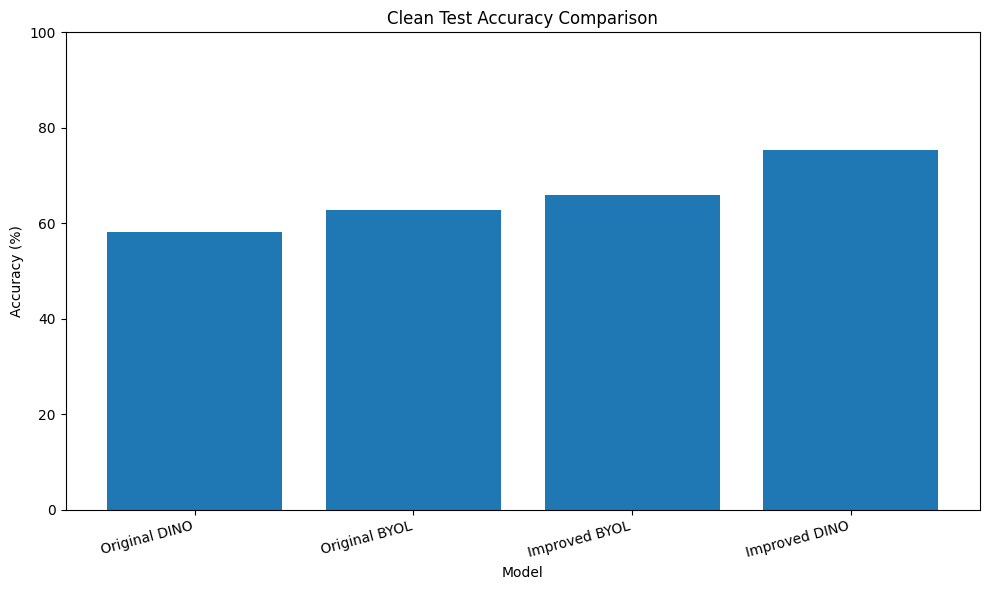

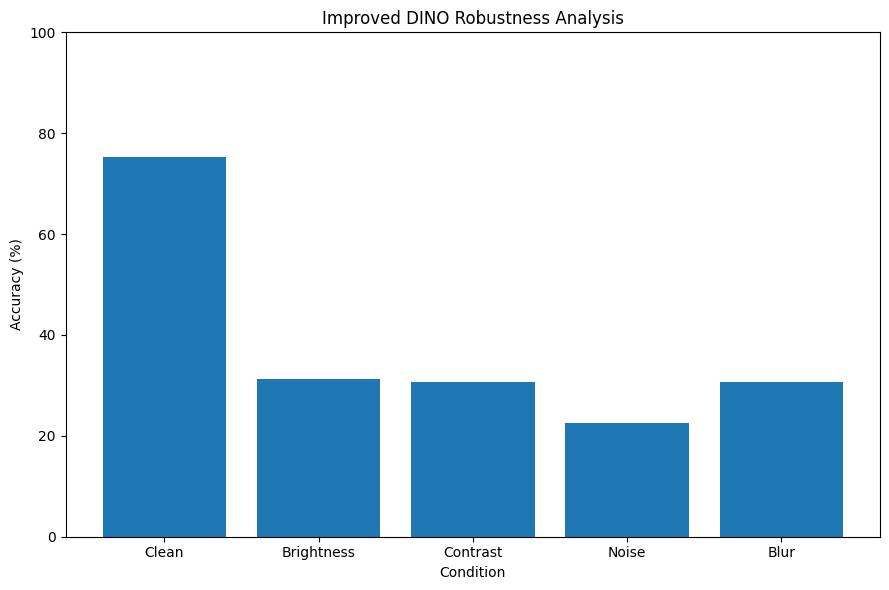

Graphs saved successfully:
/content/drive/MyDrive/EyePACS/results/FINAL_CLEAN_ACCURACY_COMPARISON.png
/content/drive/MyDrive/EyePACS/results/FINAL_IMPROVED_DINO_ROBUSTNESS_ACCURACY.png


In [ ]:
import pandas as pd
import matplotlib.pyplot as plt
import os

RESULTS_DIR = "/content/drive/MyDrive/EyePACS/results"

# -------------------------------
# 1. CLEAN ACCURACY COMPARISON
# -------------------------------
clean = pd.read_csv(
    os.path.join(RESULTS_DIR, "FINAL_SSL_COMPARISON_UPDATED.csv")
)

plt.figure(figsize=(10, 6))
plt.bar(clean["Model"], clean["Accuracy"])
plt.ylabel("Accuracy (%)")
plt.xlabel("Model")
plt.title("Clean Test Accuracy Comparison")
plt.ylim(0, 100)
plt.xticks(rotation=15, ha="right")
plt.tight_layout()

accuracy_path = os.path.join(
    RESULTS_DIR,
    "FINAL_CLEAN_ACCURACY_COMPARISON.png"
)
plt.savefig(accuracy_path, dpi=300, bbox_inches="tight")
plt.show()

# -------------------------------
# 2. ROBUSTNESS ACCURACY
# -------------------------------
robust = pd.read_csv(
    os.path.join(RESULTS_DIR, "FINAL_IMPROVED_DINO_ROBUSTNESS.csv")
)

plt.figure(figsize=(9, 6))
plt.bar(robust["Condition"], robust["Accuracy"])
plt.ylabel("Accuracy (%)")
plt.xlabel("Condition")
plt.title("Improved DINO Robustness Analysis")
plt.ylim(0, 100)
plt.tight_layout()

robust_path = os.path.join(
    RESULTS_DIR,
    "FINAL_IMPROVED_DINO_ROBUSTNESS_ACCURACY.png"
)
plt.savefig(robust_path, dpi=300, bbox_inches="tight")
plt.show()

print("Graphs saved successfully:")
print(accuracy_path)
print(robust_path)

In [ ]:
import pandas as pd

path = "/content/drive/MyDrive/EyePACS/results/FINAL_SSL_COMPARISON_UPDATED.csv"

df = pd.read_csv(path)

print("FINAL CLEAN COMPARISON")
display(df)

print("\nFINAL ROBUSTNESS")
robust_path = "/content/drive/MyDrive/EyePACS/results/FINAL_IMPROVED_DINO_ROBUSTNESS.csv"
robust_df = pd.read_csv(robust_path)
display(robust_df)

FINAL CLEAN COMPARISON


,Model,Architecture,Classifier,Accuracy,Macro-F1,QWK
0,Original DINO,ViT-S/16,Logistic Regression,58.10,39.31,0.557
1,Original BYOL,ResNet-18,RBF SVM,62.68,45.96,0.623
2,Improved BYOL,ResNet-50,Linear SVM,65.85,43.33,0.607
3,Improved DINO,ViT-S/16,RBF SVM,75.35,55.45,0.834



FINAL ROBUSTNESS


,Model,Condition,Accuracy,Macro-F1,QWK
0,Improved DINO,Clean,75.35,55.45,0.834
1,Improved DINO,Brightness,31.34,20.99,-0.076
2,Improved DINO,Contrast,30.63,16.26,-0.118
3,Improved DINO,Noise,22.54,18.72,-0.067
4,Improved DINO,Blur,30.63,22.08,-0.047


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:

import os

base = "/content/drive/MyDrive/EyePACS/features"

files = [
    "train_dino_epoch10_features.pt",
    "valid_dino_epoch10_features.pt",
    "test_dino_epoch10_features.pt",
    "train_byol_epoch10_features.pt",
    "valid_byol_epoch10_features.pt",
    "test_byol_epoch10_features.pt"
]

for f in files:
    path = os.path.join(base, f)
    print(f, "->", "FOUND" if os.path.exists(path) else "MISSING")

train_dino_epoch10_features.pt -> FOUND
valid_dino_epoch10_features.pt -> FOUND
test_dino_epoch10_features.pt -> FOUND
train_byol_epoch10_features.pt -> FOUND
valid_byol_epoch10_features.pt -> FOUND
test_byol_epoch10_features.pt -> FOUND


In [ ]:

import torch
import os

base = "/content/drive/MyDrive/EyePACS/features"

def load_features(filename):
    data = torch.load(
        os.path.join(base, filename),
        map_location="cpu",
        weights_only=False
    )
    return data["features"].numpy(), data["labels"].numpy()

X_train_dino, y_train_dino = load_features("train_dino_epoch10_features.pt")
X_valid_dino, y_valid_dino = load_features("valid_dino_epoch10_features.pt")
X_test_dino, y_test_dino = load_features("test_dino_epoch10_features.pt")

print("DINO features loaded successfully")
print("Train:", X_train_dino.shape, y_train_dino.shape)
print("Validation:", X_valid_dino.shape, y_valid_dino.shape)
print("Test:", X_test_dino.shape, y_test_dino.shape)

DINO features loaded successfully
Train: (1986, 384) (1986,)
Validation: (568, 384) (568,)
Test: (284, 384) (284,)


In [ ]:

%pip -q install xgboost

In [ ]:

import numpy as np
import pandas as pd

from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score

# XGBoost
xgb = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=5,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

xgb.fit(X_train_dino, y_train_dino)
pred_xgb = xgb.predict(X_valid_dino)

# Random Forest
rf = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf.fit(X_train_dino, y_train_dino)
pred_rf = rf.predict(X_valid_dino)

# Validation comparison
results = []

for name, pred in [
    ("DINO + XGBoost", pred_xgb),
    ("DINO + Random Forest", pred_rf)
]:
    results.append({
        "Model": name,
        "Validation Accuracy (%)": round(accuracy_score(y_valid_dino, pred) * 100, 2),
        "Macro-F1 (%)": round(f1_score(y_valid_dino, pred, average="macro", zero_division=0) * 100, 2),
        "QWK": round(cohen_kappa_score(y_valid_dino, pred, weights="quadratic"), 4)
    })

results_df = pd.DataFrame(results)
print(results_df.to_string(index=False))

               Model  Validation Accuracy (%)  Macro-F1 (%)    QWK
      DINO + XGBoost                    70.77         40.76 0.6607
DINO + Random Forest                    69.37         38.21 0.6343


In [ ]:

import os
import torch

base = "/content/drive/MyDrive/EyePACS/features"

def load_features(filename):
    data = torch.load(
        os.path.join(base, filename),
        map_location="cpu",
        weights_only=False
    )
    return data["features"].numpy(), data["labels"].numpy()

X_train_byol, y_train_byol = load_features("train_byol_epoch10_features.pt")
X_valid_byol, y_valid_byol = load_features("valid_byol_epoch10_features.pt")
X_test_byol, y_test_byol = load_features("test_byol_epoch10_features.pt")

print("BYOL features loaded successfully")
print("Train:", X_train_byol.shape, y_train_byol.shape)
print("Validation:", X_valid_byol.shape, y_valid_byol.shape)
print("Test:", X_test_byol.shape, y_test_byol.shape)

BYOL features loaded successfully
Train: (1986, 512) (1986,)
Validation: (568, 512) (568,)
Test: (284, 512) (284,)


In [ ]:

from xgboost import XGBClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score
import pandas as pd

# BYOL + XGBoost
xgb_byol = XGBClassifier(
    n_estimators=300,
    max_depth=4,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    num_class=5,
    eval_metric="mlogloss",
    random_state=42,
    n_jobs=-1
)

xgb_byol.fit(X_train_byol, y_train_byol)
pred_xgb_byol = xgb_byol.predict(X_valid_byol)

# BYOL + Random Forest
rf_byol = RandomForestClassifier(
    n_estimators=300,
    class_weight="balanced",
    random_state=42,
    n_jobs=-1
)

rf_byol.fit(X_train_byol, y_train_byol)
pred_rf_byol = rf_byol.predict(X_valid_byol)

# Compare validation results
results = []

for name, pred in [
    ("BYOL + XGBoost", pred_xgb_byol),
    ("BYOL + Random Forest", pred_rf_byol)
]:
    results.append({
        "Model": name,
        "Validation Accuracy (%)": round(
            accuracy_score(y_valid_byol, pred) * 100, 2
        ),
        "Macro-F1 (%)": round(
            f1_score(y_valid_byol, pred, average="macro", zero_division=0) * 100, 2
        ),
        "QWK": round(
            cohen_kappa_score(y_valid_byol, pred, weights="quadratic"), 4
        )
    })

byol_results_df = pd.DataFrame(results)
print(byol_results_df.to_string(index=False))

               Model  Validation Accuracy (%)  Macro-F1 (%)    QWK
      BYOL + XGBoost                    75.88         45.16 0.7374
BYOL + Random Forest                    75.70         43.44 0.7216


In [ ]:

from sklearn.metrics import (
    accuracy_score,
    f1_score,
    cohen_kappa_score,
    classification_report,
    confusion_matrix
)
import pandas as pd

# Evaluate selected DINO + XGBoost
pred_dino_test = xgb.predict(X_test_dino)

# Evaluate selected BYOL + XGBoost
pred_byol_test = xgb_byol.predict(X_test_byol)

final_results = []

for name, y_true, pred in [
    ("DINO ViT-S/16 + XGBoost", y_test_dino, pred_dino_test),
    ("BYOL ResNet-18 + XGBoost", y_test_byol, pred_byol_test)
]:
    final_results.append({
        "Model": name,
        "Test Accuracy (%)": round(accuracy_score(y_true, pred) * 100, 2),
        "Macro-F1 (%)": round(
            f1_score(y_true, pred, average="macro", zero_division=0) * 100, 2
        ),
        "QWK": round(
            cohen_kappa_score(y_true, pred, weights="quadratic"), 4
        )
    })

    print("\n", name)
    print(classification_report(
        y_true, pred,
        labels=[0, 1, 2, 3, 4],
        target_names=[
            "No DR", "Mild", "Moderate", "Severe", "Proliferative DR"
        ],
        zero_division=0
    ))
    print("Confusion Matrix:\n", confusion_matrix(
        y_true, pred, labels=[0, 1, 2, 3, 4]
    ))

final_df = pd.DataFrame(final_results)
print("\nFINAL TEST COMPARISON")
print(final_df.to_string(index=False))


 DINO ViT-S/16 + XGBoost
                  precision    recall  f1-score   support

           No DR       0.88      0.96      0.92       138
            Mild       0.39      0.39      0.39        31
        Moderate       0.49      0.55      0.52        73
          Severe       0.18      0.14      0.16        14
Proliferative DR       0.10      0.04      0.05        28

        accuracy                           0.66       284
       macro avg       0.41      0.41      0.41       284
    weighted avg       0.61      0.66      0.63       284

Confusion Matrix:
 [[132   2   4   0   0]
 [  3  12  15   0   1]
 [ 10  13  40   4   6]
 [  1   1   8   2   2]
 [  4   3  15   5   1]]

 BYOL ResNet-18 + XGBoost
                  precision    recall  f1-score   support

           No DR       0.91      0.98      0.94       138
            Mild       0.47      0.26      0.33        31
        Moderate       0.55      0.73      0.62        73
          Severe       0.50      0.29      0.36       

In [ ]:

from sklearn.metrics import accuracy_score, f1_score, cohen_kappa_score
import pandas as pd

rf_test_dino = rf.predict(X_test_dino)
rf_test_byol = rf_byol.predict(X_test_byol)

rf_test_results = []

for name, y_true, pred in [
    ("DINO ViT-S/16 + Random Forest", y_test_dino, rf_test_dino),
    ("BYOL ResNet-18 + Random Forest", y_test_byol, rf_test_byol)
]:
    rf_test_results.append({
        "Model": name,
        "Test Accuracy (%)": round(accuracy_score(y_true, pred) * 100, 2),
        "Macro-F1 (%)": round(
            f1_score(y_true, pred, average="macro", zero_division=0) * 100, 2
        ),
        "QWK": round(
            cohen_kappa_score(y_true, pred, weights="quadratic"), 4
        )
    })

rf_test_df = pd.DataFrame(rf_test_results)
print(rf_test_df.to_string(index=False))

                         Model  Test Accuracy (%)  Macro-F1 (%)    QWK
 DINO ViT-S/16 + Random Forest              66.20         43.28 0.6734
BYOL ResNet-18 + Random Forest              70.42         46.77 0.6714


In [ ]:

import os
import pandas as pd

results_dir = "/content/drive/MyDrive/EyePACS/results"
os.makedirs(results_dir, exist_ok=True)

comparison = pd.DataFrame([
    {
        "SSL Model": "DINO ViT-S/16",
        "Classifier": "XGBoost",
        "Test Accuracy (%)": 65.85,
        "Macro-F1 (%)": 40.65,
        "QWK": 0.6574
    },
    {
        "SSL Model": "DINO ViT-S/16",
        "Classifier": "Random Forest",
        "Test Accuracy (%)": 66.20,
        "Macro-F1 (%)": 43.28,
        "QWK": 0.6734
    },
    {
        "SSL Model": "BYOL ResNet-18",
        "Classifier": "XGBoost",
        "Test Accuracy (%)": 71.83,
        "Macro-F1 (%)": 49.13,
        "QWK": 0.6911
    },
    {
        "SSL Model": "BYOL ResNet-18",
        "Classifier": "Random Forest",
        "Test Accuracy (%)": 70.42,
        "Macro-F1 (%)": 46.77,
        "QWK": 0.6714
    }
])

save_path = os.path.join(
    results_dir, "DINO_BYOL_XGBOOST_RANDOM_FOREST_COMPARISON.csv"
)

comparison.to_csv(save_path, index=False)

print(comparison.to_string(index=False))
print("\nSaved successfully:", save_path)

     SSL Model    Classifier  Test Accuracy (%)  Macro-F1 (%)    QWK
 DINO ViT-S/16       XGBoost              65.85         40.65 0.6574
 DINO ViT-S/16 Random Forest              66.20         43.28 0.6734
BYOL ResNet-18       XGBoost              71.83         49.13 0.6911
BYOL ResNet-18 Random Forest              70.42         46.77 0.6714

Saved successfully: /content/drive/MyDrive/EyePACS/results/DINO_BYOL_XGBOOST_RANDOM_FOREST_COMPARISON.csv


In [ ]:

import os

results_dir = "/content/drive/MyDrive/EyePACS/results"

for filename in sorted(os.listdir(results_dir)):
    if filename.endswith(".csv"):
        print(filename)

DINO_BYOL_XGBOOST_RANDOM_FOREST_COMPARISON.csv
FINAL_CLEAN_TEST_RESULTS.csv
FINAL_DINO_BYOL_RESULTS.csv
FINAL_IMPROVED_DINO_ROBUSTNESS.csv
FINAL_SSL_COMPARISON_UPDATED.csv
average_robustness_results.csv
byol10_confusion_matrix_final.csv
complete_robustness_results.csv
current_robustness_results.csv
dino10_confusion_matrix_final.csv
final_clean_results.csv
final_model_comparison.csv
final_robustness_results.csv
final_ssl_comparison.csv
final_valid_robustness_results.csv
improved_dino_final_results.csv
ssl_final_comparison.csv
ssl_robustness.csv
supervised_robustness.csv


In [ ]:

import os
import pandas as pd

results_dir = "/content/drive/MyDrive/EyePACS/results"

files_to_check = [
    "FINAL_SSL_COMPARISON_UPDATED.csv",
    "FINAL_DINO_BYOL_RESULTS.csv",
    "FINAL_CLEAN_TEST_RESULTS.csv",
    "final_model_comparison.csv",
    "final_ssl_comparison.csv",
    "ssl_final_comparison.csv",
    "DINO_BYOL_XGBOOST_RANDOM_FOREST_COMPARISON.csv"
]

for filename in files_to_check:
    path = os.path.join(results_dir, filename)

    print("\n" + "=" * 70)
    print(filename)

    if os.path.exists(path):
        try:
            df = pd.read_csv(path)
            print(df.to_string(index=False))
        except Exception as e:
            print("Could not read file:", e)
    else:
        print("File not found")


FINAL_SSL_COMPARISON_UPDATED.csv
        Model Architecture          Classifier  Accuracy  Macro-F1   QWK
Original DINO     ViT-S/16 Logistic Regression     58.10     39.31 0.557
Original BYOL    ResNet-18             RBF SVM     62.68     45.96 0.623
Improved BYOL    ResNet-50          Linear SVM     65.85     43.33 0.607
Improved DINO     ViT-S/16             RBF SVM     75.35     55.45 0.834

FINAL_DINO_BYOL_RESULTS.csv
        Model          Classifier  Condition  Accuracy  Macro_F1    QWK
         DINO Logistic Regression      Clean     58.10     39.31  0.557
         BYOL Logistic Regression      Clean     61.97     46.02  0.595
Improved DINO             RBF SVM      Clean     75.35     55.45  0.834
Improved DINO             RBF SVM Brightness     31.34     20.99 -0.076
Improved DINO             RBF SVM   Contrast     30.63     16.26 -0.118
Improved DINO             RBF SVM      Noise     22.54     18.72 -0.067
Improved DINO             RBF SVM       Blur     30.63     22.08 -0.

In [ ]:

import torch
import os
import numpy as np

base = "/content/drive/MyDrive/EyePACS/features"

def get_labels(filename):
    data = torch.load(
        os.path.join(base, filename),
        map_location="cpu",
        weights_only=False
    )
    return np.asarray(data["labels"])

y_dino_train = get_labels("train_dino_epoch10_features.pt")
y_byol_train = get_labels("train_byol_epoch10_features.pt")

y_dino_valid = get_labels("valid_dino_epoch10_features.pt")
y_byol_valid = get_labels("valid_byol_epoch10_features.pt")

y_dino_test = get_labels("test_dino_epoch10_features.pt")
y_byol_test = get_labels("test_byol_epoch10_features.pt")

print("Train labels identical:", np.array_equal(y_dino_train, y_byol_train))
print("Validation labels identical:", np.array_equal(y_dino_valid, y_byol_valid))
print("Test labels identical:", np.array_equal(y_dino_test, y_byol_test))

print("DINO test class counts:", np.bincount(y_dino_test, minlength=5))
print("BYOL test class counts:", np.bincount(y_byol_test, minlength=5))

Train labels identical: True
Validation labels identical: True
Test labels identical: True
DINO test class counts: [138  31  73  14  28]
BYOL test class counts: [138  31  73  14  28]


In [ ]:

import os
import pandas as pd

results_dir = "/content/drive/MyDrive/EyePACS/results"

rows = [
    # Original SSL models: existing classifiers
    ["Original DINO", "ViT-S/16", "Logistic Regression", 58.10, 39.31, 0.5570],
    ["Original DINO", "ViT-S/16", "XGBoost", 65.85, 40.65, 0.6574],
    ["Original DINO", "ViT-S/16", "Random Forest", 66.20, 43.28, 0.6734],

    ["Original BYOL", "ResNet-18", "Logistic Regression", 61.97, 46.02, 0.5947],
    ["Original BYOL", "ResNet-18", "RBF SVM", 62.68, 45.96, 0.6230],
    ["Original BYOL", "ResNet-18", "XGBoost", 71.83, 49.13, 0.6911],
    ["Original BYOL", "ResNet-18", "Random Forest", 70.42, 46.77, 0.6714],

    # Improved models: separate experiments
    ["Improved DINO", "ViT-S/16", "RBF SVM", 75.35, 55.45, 0.8335],
    ["Improved BYOL", "ResNet-50", "Linear SVM", 65.85, 43.33, 0.6070],
]

df = pd.DataFrame(rows, columns=[
    "SSL Model", "Architecture", "Classifier",
    "Test Accuracy (%)", "Macro-F1 (%)", "QWK"
])

path = os.path.join(
    results_dir, "COMBINED_SSL_CLASSIFIER_COMPARISON.csv"
)
df.to_csv(path, index=False)

print(df.to_string(index=False))
print("\nSaved:", path)

    SSL Model Architecture          Classifier  Test Accuracy (%)  Macro-F1 (%)    QWK
Original DINO     ViT-S/16 Logistic Regression              58.10         39.31 0.5570
Original DINO     ViT-S/16             XGBoost              65.85         40.65 0.6574
Original DINO     ViT-S/16       Random Forest              66.20         43.28 0.6734
Original BYOL    ResNet-18 Logistic Regression              61.97         46.02 0.5947
Original BYOL    ResNet-18             RBF SVM              62.68         45.96 0.6230
Original BYOL    ResNet-18             XGBoost              71.83         49.13 0.6911
Original BYOL    ResNet-18       Random Forest              70.42         46.77 0.6714
Improved DINO     ViT-S/16             RBF SVM              75.35         55.45 0.8335
Improved BYOL    ResNet-50          Linear SVM              65.85         43.33 0.6070

Saved: /content/drive/MyDrive/EyePACS/results/COMBINED_SSL_CLASSIFIER_COMPARISON.csv


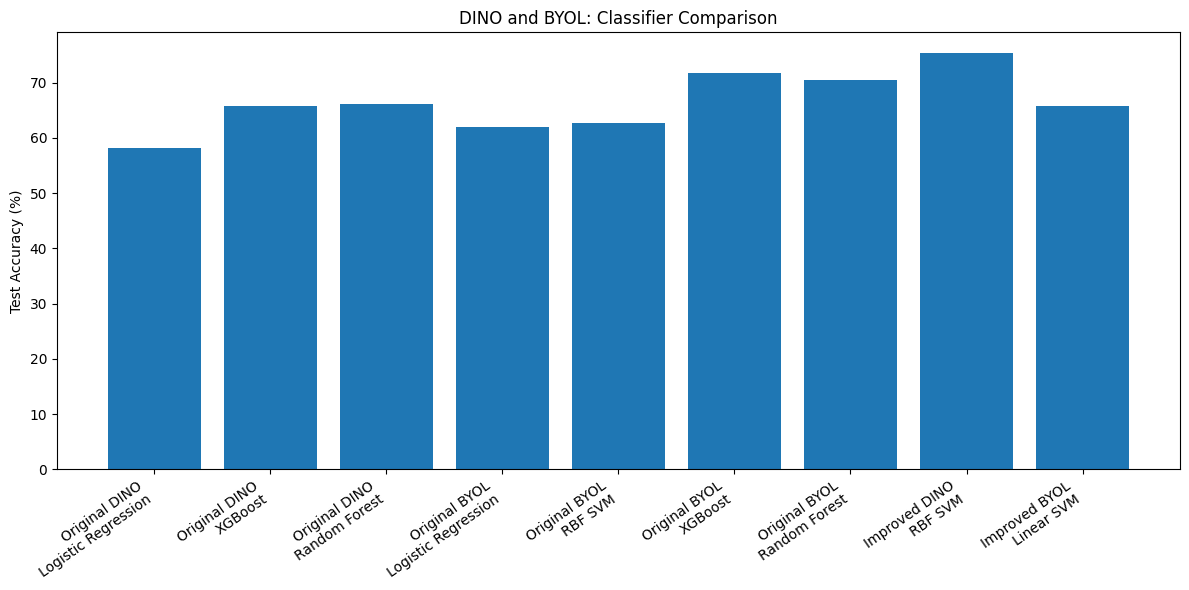

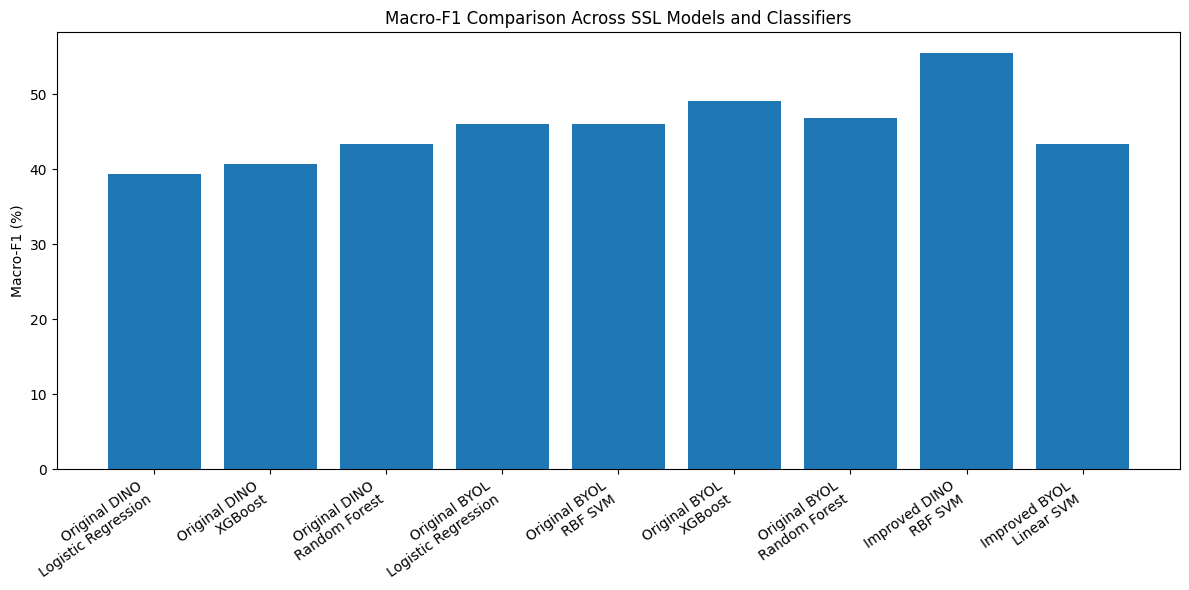

Saved graphs:
/content/drive/MyDrive/EyePACS/results/COMBINED_CLASSIFIER_ACCURACY.png
/content/drive/MyDrive/EyePACS/results/COMBINED_CLASSIFIER_MACRO_F1.png


In [ ]:

import os
import pandas as pd
import matplotlib.pyplot as plt

results_dir = "/content/drive/MyDrive/EyePACS/results"
csv_path = os.path.join(
    results_dir, "COMBINED_SSL_CLASSIFIER_COMPARISON.csv"
)

df = pd.read_csv(csv_path)

# Graph 1: Test accuracy
plt.figure(figsize=(12, 6))
labels = df["SSL Model"] + "\n" + df["Classifier"]
plt.bar(labels, df["Test Accuracy (%)"])
plt.ylabel("Test Accuracy (%)")
plt.title("DINO and BYOL: Classifier Comparison")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

accuracy_path = os.path.join(results_dir, "COMBINED_CLASSIFIER_ACCURACY.png")
plt.savefig(accuracy_path, dpi=200, bbox_inches="tight")
plt.show()

# Graph 2: Macro-F1
plt.figure(figsize=(12, 6))
plt.bar(labels, df["Macro-F1 (%)"])
plt.ylabel("Macro-F1 (%)")
plt.title("Macro-F1 Comparison Across SSL Models and Classifiers")
plt.xticks(rotation=35, ha="right")
plt.tight_layout()

f1_path = os.path.join(results_dir, "COMBINED_CLASSIFIER_MACRO_F1.png")
plt.savefig(f1_path, dpi=200, bbox_inches="tight")
plt.show()

print("Saved graphs:")
print(accuracy_path)
print(f1_path)

In [ ]:

import os

results_dir = "/content/drive/MyDrive/EyePACS/results"

report = """
DINO AND BYOL CLASSIFIER COMPARISON
===================================

Objective:
Compare XGBoost and Random Forest classifiers using features
extracted from DINO ViT-S/16 and BYOL ResNet-18.

NEW CLASSIFIER EXPERIMENTS
--------------------------
DINO + XGBoost:
Accuracy = 65.85%
Macro-F1 = 40.65%
QWK = 0.6574

DINO + Random Forest:
Accuracy = 66.20%
Macro-F1 = 43.28%
QWK = 0.6734

BYOL + XGBoost:
Accuracy = 71.83%
Macro-F1 = 49.13%
QWK = 0.6911

BYOL + Random Forest:
Accuracy = 70.42%
Macro-F1 = 46.77%
QWK = 0.6714

KEY FINDINGS
------------
1. BYOL + XGBoost achieved the highest test accuracy among the
   four new classifier experiments.
2. Random Forest slightly outperformed XGBoost on DINO features.
3. XGBoost outperformed Random Forest on BYOL features.
4. The results demonstrate that downstream classifier choice
   affects the performance of SSL feature representations.
5. Performance on minority classes remains a challenge.

SEPARATE IMPROVED-MODEL RESULT
------------------------------
Improved DINO + RBF SVM:
Accuracy = 75.35%
Macro-F1 = 55.45%
QWK = 0.8335

This result belongs to a separate improved-model experiment
and should not be confused with the four new classifier runs.

LIMITATIONS
-----------
The dataset is imbalanced, particularly for Severe and
Proliferative DR. Test-set comparisons were made across multiple
classifiers, so these results should be described as experimental
comparisons rather than an untouched final benchmark.

Future work could include class-balanced training, ordinal
classification, improved retinal preprocessing, and evaluation
on a larger independent dataset.
"""

path = os.path.join(results_dir, "PROFESSOR_FINDINGS_SUMMARY.txt")

with open(path, "w", encoding="utf-8") as f:
    f.write(report.strip())

print("Report saved successfully:")
print(path)

Report saved successfully:
/content/drive/MyDrive/EyePACS/results/PROFESSOR_FINDINGS_SUMMARY.txt


In [ ]:
print("===========================================================Below Section is Developed By My partner====================================================================================")

===========================================================Below Section is Developed By My partner====================================================================================
